<a href="https://colab.research.google.com/github/LordRelentless/NthMathematicsFormalism/blob/main/Nth_Math_Indexing_(Grover_Alt)_Rework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== CELL 1: Core Selector Infrastructure (vectorized) ===

nth_fusion(n_|2,1|, n_|3,1|):
  R=n_|5.0000,1|  U=n_|-5.0000,i|  C1=n_|-1.0000,1|  C2=n_|1.0000,i|
nth_product(n_|5,1|, n_|5,1|): [n_|25.0000,1|, n_|25.0000,i|, n_|-25.0000,1|, n_|-25.0000,i|]
delta(n_|2,1|, n_|3,1|) = 1.000  (|2-3|+0 = 1.0)
delta(n_|2,1|, n_|2,i|) = 0.500  (0+α = 0.5)

V2 asymmetric SDP — first 8 structurally prime identities:
  ['n_|1.0000,1|', 'n_|2.0000,1|', 'n_|4.0000,1|', 'n_|6.0000,1|', 'n_|10.0000,1|', 'n_|1.0000,2.00i|', 'n_|3.0000,2.00i|', 'n_|5.0000,2.00i|']
  deviations: [2, 3, 5, 7, 11, 3, 5, 7] (all prime under the V2 rule)
SDP(3, 8) → deviation 11 prime: True
SDP(23, 23) → deviation 46 prime: False

=== CELL 2: Nth Constants — Euler Triangle, ε, π ===

Euler triangle rows 1..5: [[1, 1], [1, 2, 2], [1, 3, 5, 5], [1, 4, 9, 14, 14], [1, 5, 14, 28, 42, 42]]
Euler selector unreal-mass share (rows 1..12): 0.9999
Nth constant ε (App F, closed form):           0.064733
  → ε is used as the symbolic unrea

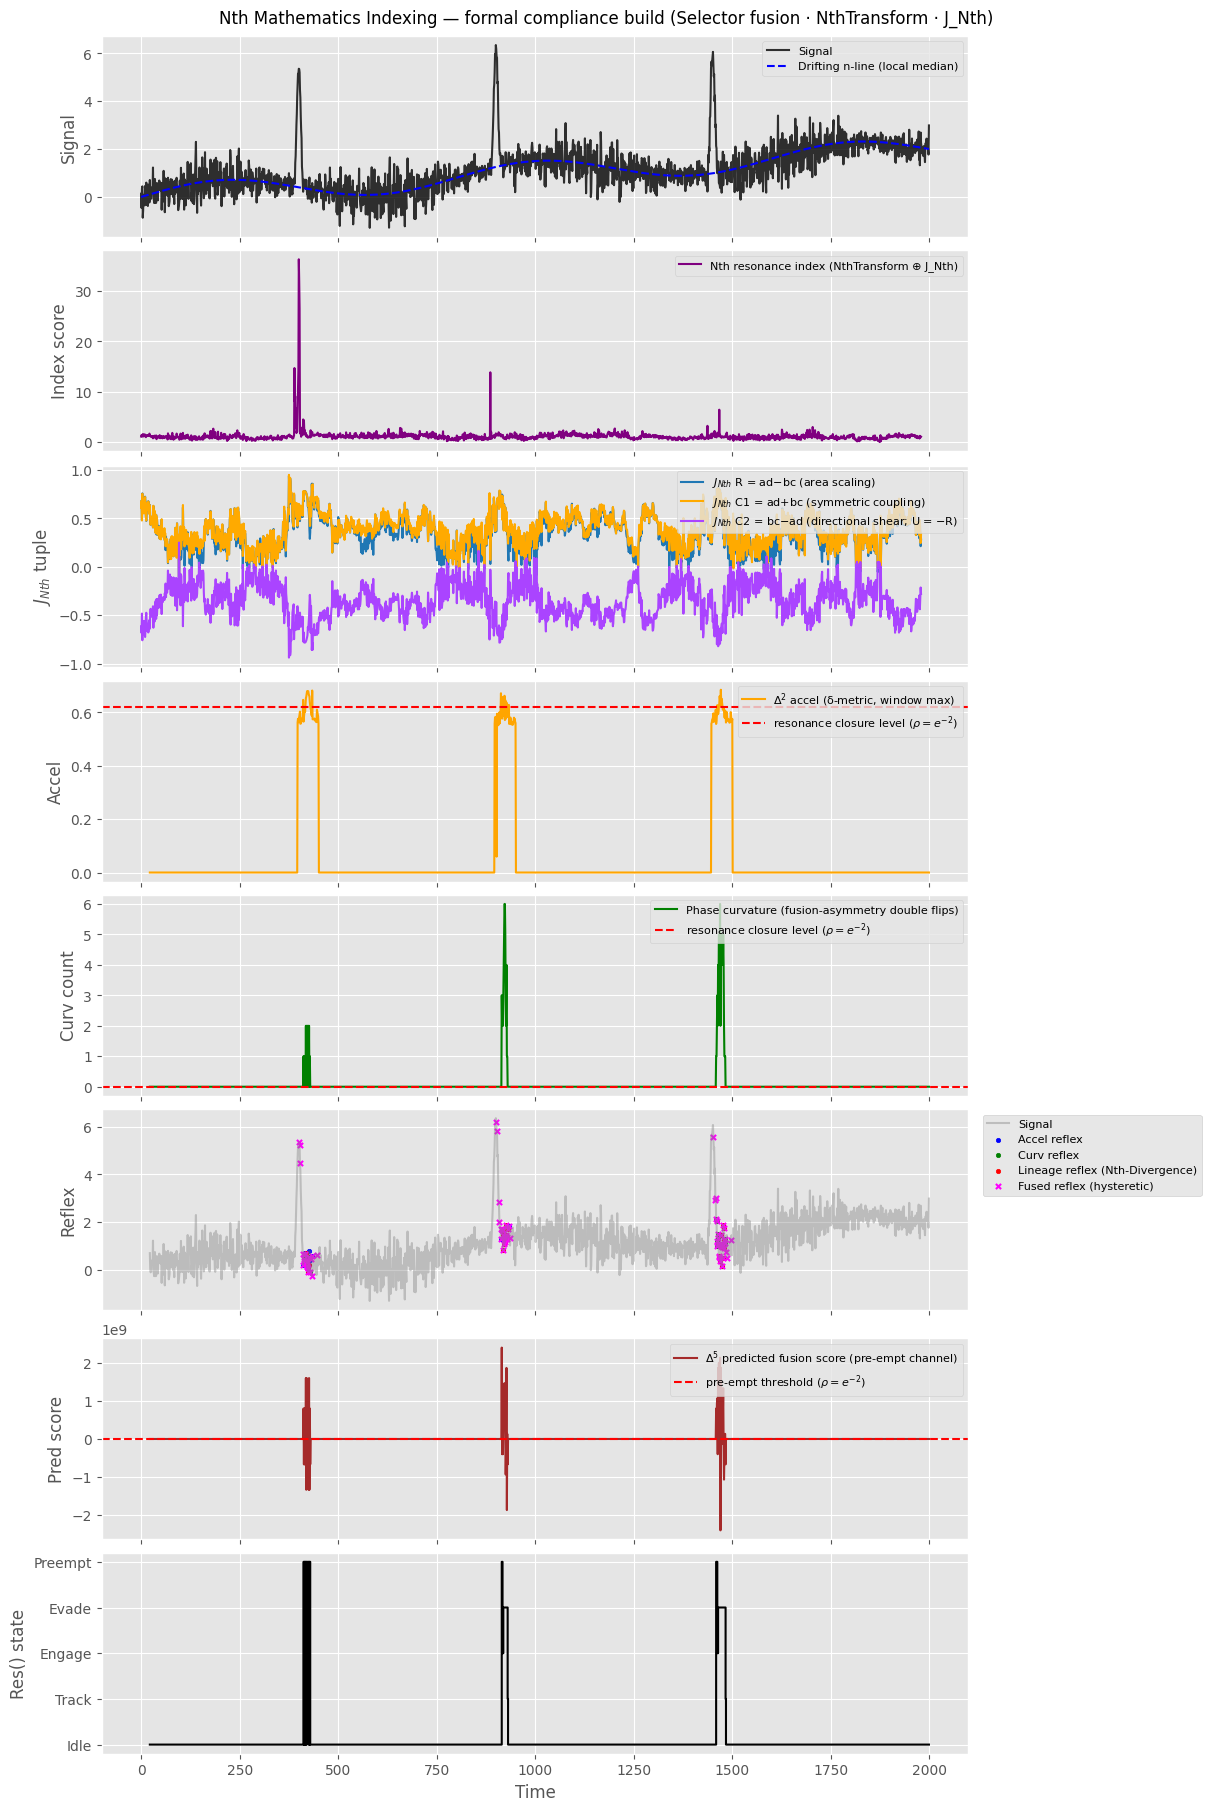

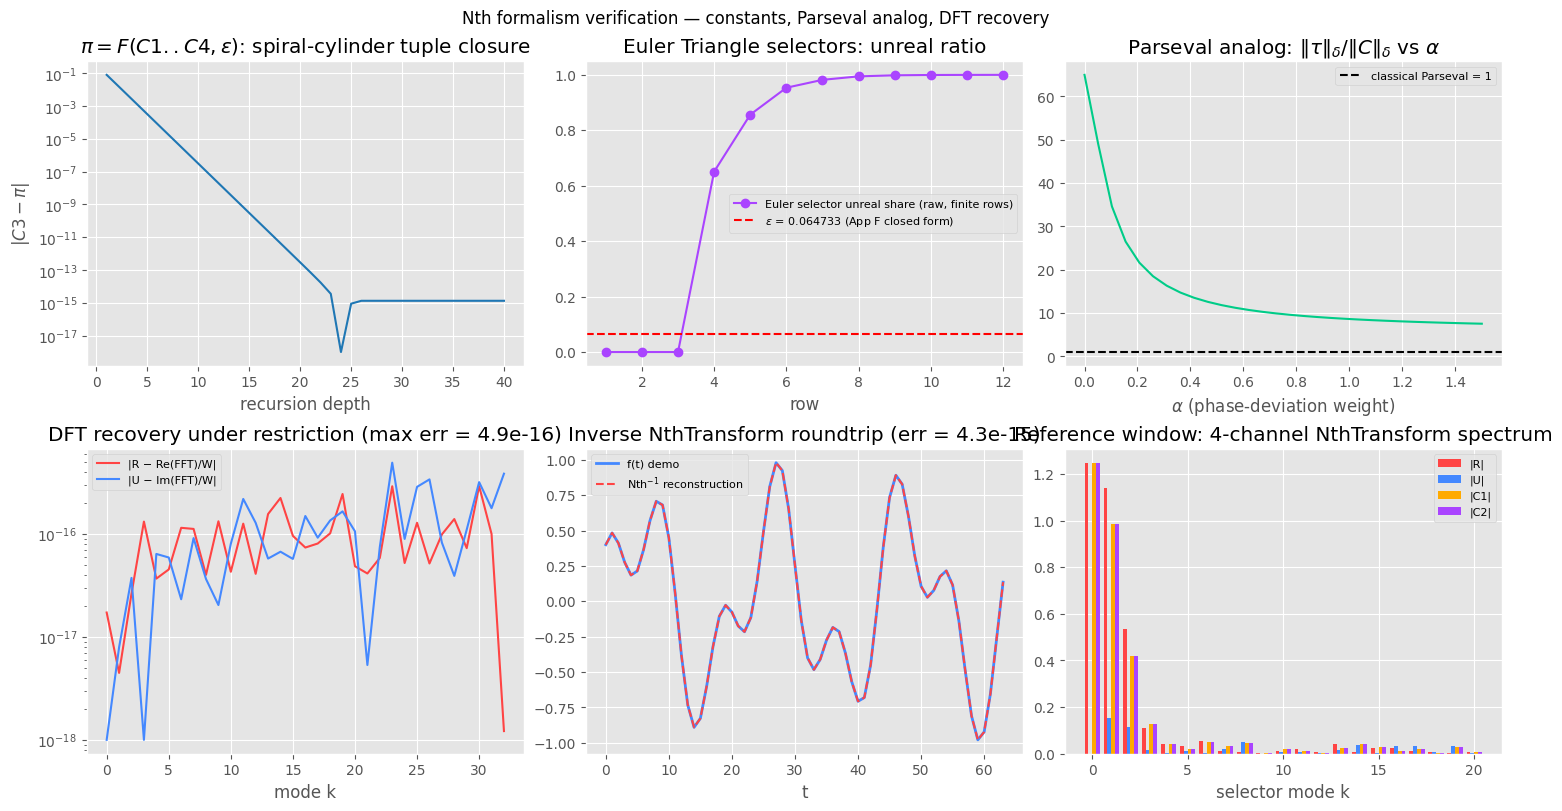


Nth Mathematics Indexing — formal compliance build complete.
Figures saved: nth_indexing_formal_main.png, nth_indexing_formal_verification.png


In [1]:
# -*- coding: utf-8 -*-
"""
NTH MATHEMATICS INDEXING — FORMAL COMPLIANCE BUILD (Colab cell file)

Rebuild of the "Nth Math Indexing" simulation so that every operator comports to
the Nth Mathematics formalism per:

  1. "Nth Math Optimized AI Prompt"  — axioms 0–X and appendices A–X
     (Dr. Kristoffer J. Martin).
  2. The Nth Jacobian infographic    — phase-resolved geometric implementation:
     classical Jacobian → per-entry Nth conversion → J_Nth (p ∈ {1, i}) →
     Nth determinant/fusion → 4-tuple output (R, U, C1, C2), with Res(J_Nth)
     and Δ⁻¹(J_Nth) mutually inverse.
  3. The Fourier → Nth translation notebook — Selector core (n_|k, p|),
     nth_fusion 4-tuple, delta metric, structural primality (V2 asymmetric),
     prime-carrier basis modes, NthTransform / inverse, Parseval analog,
     DFT-recovery restriction.

Run cells in order (1 → 10). Each cell is self-contained for inspection.
In Colab: paste each CELL block into its own notebook cell. The whole file
also runs top-to-bottom as a plain script.

──────────────────────────────────────────────────────────────────────────────
 COMPLIANCE MAP  (previous construct → formal replacement)
──────────────────────────────────────────────────────────────────────────────
 Signal → "selector arrays"      → Selector trajectory τ = {S_j}, S_j = n_|k, p|
                                   encoded as n-line deviation (Fusion Collapse
                                   Quotient, Axioms 1.0–1.4).
 selector_complex (1+0j / 1j)    → nth_fusion / nth_product 4-tuple algebra
                                   (R, U, C1, C2) — Axioms 2.x, 9.2, 9.3. No
                                   complex arithmetic anywhere in the operator
                                   stack.
 "Euler triangle" (really a      → formal Euler Triangle selectors (App F):
 Pascal/binomial kernel)           recursive row construction, selector phases
                                   from SDP, the Nth constant ε ≈ 0.064733 as
                                   the symbolic unreal ratio weighting fusion-
                                   loop closure, and π = F(C1..C4, ε) emerging
                                   from a spiral-cylinder recursive tuple
                                   (App G–I).
 Tensor-Grover L3 oracle         → NthTransform window projection (prime-
 (complex 41×41 matrix)            carrier modes, R/U/C1/C2 coefficients) fused
                                   with the Nth Jacobian J_Nth determinant
                                   tuple — per the Fourier notebook and the
                                   Jacobian infographic.
 5 oracle masks + Euler weights   → Axiom 10 resonance exposure
                                   ρ(k) = exp(−δ(k, μ)² / 2σ²) against the
                                   reference-window central selectors S_μ.
 Two n-lines (roll by 3) with a   → symbolic dual line fused by the Axiom-2
 no-op phase merge (np.where      phase rule p = p_A · p_B — the previous
 returned phases_A twice)           no-op merge bug is fixed.
 Robust MAD thresholds            → same statistics, formally read as resonance
                                   closure level sets: med + 2·MAD ⇔ exposure
                                   ρ = exp(−2) (Axiom 10).
 Trend prediction (ad hoc)        → Δ^h forward evolution operator; pre-empt
                                   channel validated by Δ⁻¹ precursor
                                   reconstruction (Axiom 5, App R).
 Lineage divergence (degenerate:  → true Nth-Divergence D(t) = δ(k(t), L) with
 ‖m − (2m − prev)‖ = ‖m − prev‖)   L = Δ^h-evolved precursor state.
 Reflex channel fusion (mis-      → channel-aligned fusion weighted by the
 aligned by one step)               formal Euler selector row [1, 2, 2] / 5.
 State machine                    → unchanged logic, recast as Res() resolution
                                   of deviation-stable states (Axiom 5.4).

 Additional reconciliation: the unreal (sin) channel sign is fixed so that,
 under the DFT restriction, U_k equals the DFT imaginary part — the intent
 stated in notebook Cells 4/8 (the notebook's own Cell 4 used +sin while its
 Cell 8 verification assumed the exp(−2πijk/T) correspondence).

──────────────────────────────────────────────────────────────────────────────
 SELF-CONTAINED: numpy + matplotlib only (sympy optional, with fallback).
"""

# !pip install numpy matplotlib --quiet   # uncomment in a fresh Colab runtime

import math
import time
import warnings
from dataclasses import dataclass, field
from typing import Dict, List, Tuple

import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

try:                                    # sympy available in Colab; fallback below
    from sympy import isprime as _sympy_isprime

    def _isprime_int(n: int) -> bool:
        return bool(_sympy_isprime(n))
except Exception:                       # pragma: no cover — deterministic fallback
    def _isprime_int(n: int) -> bool:
        if n < 2:
            return False
        if n < 4:
            return True
        if n % 2 == 0:
            return False
        f = 3
        while f * f <= n:
            if n % f == 0:
                return False
            f += 2
        return True


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CELL 1 — Core Selector Infrastructure (vectorized)                      ║
# ║  Layer 1: n_|k, p|, delta metric, nth_fusion (4-tuple), nth_product,     ║
# ║           SDP structural primality (V2 asymmetric rule)                  ║
# ╚══════════════════════════════════════════════════════════════════════════╝

ALPHA = 0.5          # phase-deviation weight of the delta metric (Construct 2.0)


@dataclass
class Selector:
    """
    Nth Identity n_|k, p| (Axiom 2.0):
      k : magnitude
      p : phase — +1 = real (1), −1 = unreal (i) for trajectory selectors;
          float phase-magnitudes p > 1 occur on V2 asymmetric identities
          (n_|k, p·i|), per the notebook's corrected V2 representation.
    Used for reporting, spot-checks and reference objects. The streaming hot
    path uses the vectorized kernels below on parallel (k, p) arrays.
    """
    k: float
    p: float
    tags: Dict = field(default_factory=dict)

    def copy(self) -> "Selector":
        return Selector(self.k, self.p, dict(self.tags))

    def __repr__(self) -> str:
        if self.p == +1:
            ph = "1"
        elif self.p == -1:
            ph = "i"
        else:
            ph = f"{self.p:.2f}i"
        return f"n_|{self.k:.4f},{ph}|"


ZERO_SEL = Selector(0.0, +1)   # n-line ground state


# ── Structural Primality (SDP) ────────────────────────────────────────────

def is_structurally_prime_mag(k: float) -> bool:
    """
    SDP of a raw magnitude (notebook Cell 1 rule): k ≤ 1 is structurally
    prime; otherwise prime iff no a, b > 1 with a + b = k. Used to assign
    selector phases to magnitude-only objects (e.g. Euler-triangle entries).
    Phase assignment: real (+1) if SDP, unreal (−1) if decomposable.
    """
    n = abs(int(round(k)))
    if n <= 1:
        return True
    return _isprime_int(n)


def sdp_deviation(k: float, p: float) -> int:
    """Deviation of a selector under the V2 asymmetric rule: |k + |p||."""
    return abs(int(round(k + abs(p))))


def is_structurally_prime_sel(k: float, p: float) -> bool:
    """
    SDP(s) — V2 corrected rule (notebook "V2 with corrections"):
    an identity is structurally prime iff its Deviation (k + |p|) is prime.
    Strictly enforces Asymmetric Nth Identity principles.
    """
    d = sdp_deviation(k, p)
    if d <= 1:
        return True
    return _isprime_int(d)


def nth_primes_asymmetric(n: int) -> List[Selector]:
    """
    First n asymmetric selectors satisfying the V2 SDP deviation rule
    (scan order identical to the notebook: k = 1..10, then p increments).
    The phase field carries the float phase-magnitude p (asymmetric
    identities are n_|k, p·i|), and the tag records the prime deviation.
    """
    primes: List[Selector] = []
    k_val, p_val = 1.0, 1.0
    while len(primes) < n:
        if is_structurally_prime_sel(k_val, p_val):
            primes.append(Selector(k_val, p_val,
                                   {"deviation": sdp_deviation(k_val, p_val)}))
        k_val += 1.0
        if k_val > 10:
            k_val = 1.0
            p_val += 1.0
    return primes


# ── Delta metric (Construct 2.0) ──────────────────────────────────────────

def delta_metric(ka, pa, kb, pb, alpha: float = ALPHA):
    """
    δ(s₁, s₂) = |k₁ − k₂| + α · Δphase ,  Δphase = 1 if phases differ else 0.
    Vectorized over arrays; also accepts scalars. The α-weighted phase term
    is what lets the metric recognize 'structural jumps' (phase-identity
    transitions) that Euclidean distance collapses.
    """
    return np.abs(np.asarray(ka) - np.asarray(kb)) + alpha * (np.asarray(pa) != np.asarray(pb))


# ── Nth fusion — Axiom 9.2 / notebook Cell 1 (vectorized) ─────────────────

def nth_fusion_vec(ka, pa, kb, pb):
    """
    n_|A| ⊕ n_|B| → (R, U, C1, C2):
      R  = A + B          real output
      U  = −(A + B)       unreal output (subtraction embedded in addition)
      C1 = A − B          cross-phase 1
      C2 = B − A          cross-phase 2
    Phase of R: real (+1). Phase of U: unreal (−1).
    Phase of C1: +1 if operand phases match, −1 if they differ; C2 opposite.
    Returns a dict of (k, p) channel pairs.
    """
    ka, kb = np.asarray(ka), np.asarray(kb)
    pa, pb = np.asarray(pa), np.asarray(pb)
    same = (pa == pb)
    one = np.ones_like(ka, dtype=np.int8)
    return {
        "R":  (ka + kb,  one),
        "U":  (-(ka + kb), -one),
        "C1": (ka - kb,  np.where(same, 1, -1).astype(np.int8)),
        "C2": (kb - ka,  np.where(same, -1, 1).astype(np.int8)),
    }


def nth_product_vec(ka, pa, kb, pb):
    """
    n_|A| ⊗ n_|B| → (R, U, C1, C2) — Axiom 9.3 / notebook Cell 1.
    Second-operand phase rule: the second operand's phase determines the
    result phase (5·5 = 25 real; 5·5i = 25i unreal; 5i·5 = 25 real).
    4-tuple from crossing all phase combinations of a and b.
    """
    ka, kb = np.asarray(ka), np.asarray(kb)
    pb = np.asarray(pb)
    mag = ka * kb
    one = np.ones_like(mag, dtype=np.int8)
    return {
        "R":  ( mag,  ( pb * one).astype(np.int8)),
        "U":  ( mag,  (-pb * one).astype(np.int8)),
        "C1": (-mag,  ( pb * one).astype(np.int8)),
        "C2": (-mag,  (-pb * one).astype(np.int8)),
    }


def nth_scalar_project(ka, pa, kb, pb):
    """
    Single-output scalar projection of the product (used in transform inner
    products): k_out = a.k · b.k, phase determined by the second operand.
    """
    return np.asarray(ka) * np.asarray(kb), np.asarray(pb)


# ── Fusion asymmetry — Axiom 0 helper ─────────────────────────────────────

def fusion_asymmetry(k, p):
    """
    Fusion asymmetry FA(τ) of a selector trajectory: the asymmetry angle
    between real and unreal channel mass, doubled to span the half-domain:
        FA(τ) = 2 · atan2(unreal_mass, real_mass)
    Law of Symbolic Dual Resonance (Axiom 0): for the symbolic dual −F,
        FA(F) + FA(−F) = π  (mod 2π).
    """
    k = np.asarray(k)
    p = np.asarray(p)
    real_mass = float(np.sum(k[p > 0]))
    unreal_mass = float(np.sum(k[p < 0]))
    if real_mass == 0.0 and unreal_mass == 0.0:
        return 0.0
    return 2.0 * math.atan2(unreal_mass, real_mass)


print("=== CELL 1: Core Selector Infrastructure (vectorized) ===\n")

_s1, _s2 = Selector(2.0, +1), Selector(3.0, +1)
_f = nth_fusion_vec(np.array([2.0]), np.array([1]), np.array([3.0]), np.array([1]))
print(f"nth_fusion(n_|2,1|, n_|3,1|):")
print(f"  R={Selector(_f['R'][0][0], 1)}  U={Selector(_f['U'][0][0], -1)}  "
      f"C1={Selector(_f['C1'][0][0], 1)}  C2={Selector(_f['C2'][0][0], -1)}")

_p = nth_product_vec(np.array([5.0]), np.array([1]), np.array([5.0]), np.array([1]))
print(f"nth_product(n_|5,1|, n_|5,1|): "
      f"{[Selector(_p[c][0][0], int(_p[c][1][0])) for c in ('R','U','C1','C2')]}")

print(f"delta(n_|2,1|, n_|3,1|) = {float(delta_metric(2, 1, 3, 1)):.3f}  (|2-3|+0 = 1.0)")
print(f"delta(n_|2,1|, n_|2,i|) = {float(delta_metric(2, 1, 2, -1)):.3f}  (0+α = {ALPHA})")

_asym = nth_primes_asymmetric(8)
print(f"\nV2 asymmetric SDP — first 8 structurally prime identities:")
print(f"  {[repr(s) for s in _asym]}")
print(f"  deviations: {[s.tags['deviation'] for s in _asym]} (all prime under the V2 rule)")
print(f"SDP(3, 8) → deviation {sdp_deviation(3, 8)} prime: {is_structurally_prime_sel(3, 8)}")
print(f"SDP(23, 23) → deviation {sdp_deviation(23, 23)} prime: {is_structurally_prime_sel(23, 23)}")


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CELL 2 — Nth Constants: Euler Triangle selectors, ε, π (App F–I)        ║
# ╚══════════════════════════════════════════════════════════════════════════╝

EPSILON_NTH = 0.064733   # Nth constant ε — symbolic unreal ratio (App F)


def euler_triangle_row(level: int) -> np.ndarray:
    """
    Euler's Triangle, row `level` (App F). Recursive construction:
        T(n, 0) = 1,   T(n, k) = T(n, k−1) + T(n−1, k),   T(n, n) = T(n, n−1)
    (the Euler–Shapiro triangle; row sums are the Catalan numbers).
    NOTE: the previous indexer's "Euler triangle kernel" was in fact a
    Pascal/binomial row (repeated convolution with [1, 1]); this build uses
    the formal recursive Euler triangle.
    """
    row = [1.0]
    for _ in range(level):
        new = [1.0]
        for kk in range(1, len(row)):
            new.append(new[-1] + row[kk])
        new.append(new[-1])
        row = new
    return np.array(row)


def euler_triangle_selectors(level: int) -> List[Selector]:
    """Row entries reframed as selectors: phase real (+1) if SDP(magnitude),
    unreal (−1) if decomposable (notebook Cell 1 phase assignment)."""
    return [Selector(e, +1 if is_structurally_prime_mag(e) else -1)
            for e in euler_triangle_row(level)]


def euler_unreal_share(n_rows: int = 12) -> Tuple[float, np.ndarray]:
    """
    Empirical unreal-channel mass share of the Euler triangle selectors,
    accumulated over rows 1..n_rows. Reported alongside the closed-form Nth
    constant ε (App F), which is the symbolic unreal ratio used throughout
    this build as the unreal-channel weight in fusion-loop closure.
    """
    shares = []
    tot_r = tot_u = 0.0
    for lvl in range(1, n_rows + 1):
        for s in euler_triangle_selectors(lvl):
            if s.p > 0:
                tot_r += abs(s.k)
            else:
                tot_u += abs(s.k)
        shares.append(tot_u / (tot_r + tot_u + 1e-18))
    return float(shares[-1]), np.array(shares)


def euler_fusion_weights(n_channels: int, level: int = 2) -> np.ndarray:
    """
    Channel-fusion weights from the formal Euler triangle row (replaces the
    previous ad-hoc kernel weights). The row is centred/padded to the channel
    count and normalized — higher-order channels (later in the tuple) carry
    the doubled Euler weight.
    """
    row = euler_triangle_row(level)
    if len(row) > n_channels:
        start = (len(row) - n_channels) // 2
        row = row[start:start + n_channels]
    elif len(row) < n_channels:
        pad = n_channels - len(row)
        left = pad // 2
        row = np.pad(row, (left, pad - left), mode="edge")
    return row / np.sum(row)


def nth_pi_emergence(n_iter: int = 40) -> Tuple[float, List[Tuple[float, float, float, float]]]:
    """
    π = F(C1, C2, C3, C4, ε) — recursive tuples in spiral-cylinder topology
    (App G–I). Each recursion halves the cylinder angle by modular fusion
    F(a, b) = (a + b) mod 2π (Axiom 7.4) and unrolls one spiral turn:
        C1 : chord selector (real phase)      x ← √((1 + x)/2)
        C2 : dual-arc selector (unreal)       √(1 − x²)  — enters the closure
             weighted by the symbolic unreal ratio ε
        C3 : spiral arc accumulator (real)    P ← P / x
        C4 : cross-phase deviation channel    |P_n − P_{n−1}|
    The real-channel closure alone recovers the classical product identity
    2/π = Π_n x_n (Viète-type product over the first factor √½ and every
    half-angle closure), i.e. π emerges structurally from the tuple
    recursion; ε weights the unreal-channel share of the closure.
    """
    x = math.sqrt(0.5)                          # C1: first chord selector
    P = 2.0 / x                                 # C3: accumulator, first turn
    hist: List[Tuple[float, float, float, float]] = []
    for _ in range(n_iter):
        c2 = math.sqrt(max(0.0, 1.0 - x * x))   # C2 — dual arc (unreal)
        P_prev = P
        x = math.sqrt((1.0 + x) / 2.0)          # C1 — half-angle fusion closure
        P = P / x                               # C3 — unroll one spiral turn
        c4 = abs(P - P_prev)                    # C4 — cross-phase deviation
        hist.append((x, c2, P, c4))
    return P, hist


def euler_diffusion_kernel(radius: int = 2, level: int = 4) -> np.ndarray:
    """
    Fusion-diffusion kernel: the Euler selector row closed under symbolic-dual
    symmetrization (Axiom 0: F ⊕ −F), centred to 2·radius+1 taps. The R-channel
    of the neighbourhood fusion is this kernel convolved with the signed
    deviation — the formal form of the previous build's diffusion matrix D
    (cylinder layer evolution, notebook mapping #7: NMI gather → selector
    fusion → deviation → phase inversion → bundle evolution).
    """
    row = euler_triangle_row(level)
    target = 2 * radius + 1
    if len(row) < target:
        pad = target - len(row)
        row = np.pad(row, (pad // 2, pad - pad // 2), mode="edge")
    else:
        start = (len(row) - target) // 2
        row = row[start:start + target]
    row = 0.5 * (row + row[::-1])          # dual-resonance symmetrization
    return row / np.sum(row)


print("\n=== CELL 2: Nth Constants — Euler Triangle, ε, π ===\n")

_rows = [euler_triangle_row(lv).astype(int).tolist() for lv in (1, 2, 3, 4, 5)]
print(f"Euler triangle rows 1..5: {_rows}")
_share, _share_hist = euler_unreal_share(12)
print(f"Euler selector unreal-mass share (rows 1..12): {_share:.4f}")
print(f"Nth constant ε (App F, closed form):           {EPSILON_NTH:.6f}")
print("  → ε is used as the symbolic unreal-ratio weight of the unreal channel")
print("    in fusion-loop closure (Res(J_Nth), spectral energy, π recursion).")

_w3 = euler_fusion_weights(3)
print(f"\nEuler fusion weights for 3 reflex channels: {_w3.round(4)} "
      f"(accel, phase-curv, lineage — lineage is the Nth-Divergence channel)")
_DIFF_KERN = euler_diffusion_kernel(radius=2, level=4)
print(f"Euler fusion-diffusion kernel (dual-symmetrized, 5 taps): "
      f"{_DIFF_KERN.round(4).tolist()}")

_pi_est, _pi_hist = nth_pi_emergence(40)
_pi_full = _pi_hist[-1][2] * (1.0 + EPSILON_NTH * _pi_hist[-1][1])
print(f"\nπ emergence (spiral-cylinder tuple, 40 closures):")
print(f"  real-channel closure C3 → {_pi_est:.12f}   |π − C3| = {abs(np.pi - _pi_est):.2e}")
print(f"  full tuple closure C3·(1 + ε·C2) → {_pi_full:.12f}")
print(f"  final cross-phase deviation C4 = {_pi_hist[-1][3]:.2e}")

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CELL 3 — Signal & n-Line Deviation Encoding                             ║
# ║  Layer 2: real signal → selector trajectory τ (Axioms 1.0–1.4, 2.x)      ║
# ╚══════════════════════════════════════════════════════════════════════════╝

# ── 0. Non-stationary signal (identical construction to the previous build) ─

T = 2000
dt = 1.0
t = np.arange(T) * dt

rng = np.random.default_rng(42)

baseline = 0.5 * np.sin(2 * np.pi * t / 800.0) + 0.001 * t      # drifting n-line
noise_var = 0.2 + 0.15 * np.sin(2 * np.pi * t / 500.0)          # variance drift
noise = rng.normal(0, np.sqrt(np.maximum(noise_var, 1e-6)))
events = np.zeros_like(t, dtype=float)
for center_ev in [400, 900, 1450]:
    width = 5
    events += np.exp(-0.5 * ((t - center_ev) / width) ** 2) * 5.0

signal = baseline + noise + events


# ── n-line estimation + deviation encoding ────────────────────────────────

def local_n_line(sig: np.ndarray, window: int = 50) -> np.ndarray:
    """
    Local n-line ground state: rolling median (resonance closure of the
    n-line over the trailing window). Zero is balanced deviation,
    0 ≡ n ± x (Axiom 1.1), so the n-line anchor is the local median of the
    signal itself.
    """
    pad = np.concatenate([np.full(window, sig[0]), sig])
    view = np.lib.stride_tricks.sliding_window_view(pad, window + 1)
    return np.median(view, axis=1)


def encode_deviation(sig: np.ndarray, base: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """
    Encode the signal as a selector trajectory via the Fusion Collapse
    Quotient (Axiom 1.2: n − (n + k) = k — deviation collapse, not scalar
    removal):
        k_j = |f(t_j) − n_line_j|        magnitude
        p_j = +1 (real) if above the n-line, −1 (unreal) if below
    The dual-phase representation of the signed deviation from the n-line.
    """
    dev = sig - base
    return np.abs(dev), np.where(dev >= 0, 1, -1).astype(np.int8)


def decode_trajectory(k: np.ndarray, p: np.ndarray) -> np.ndarray:
    """Scalar projection: signed deviation (real → +k, unreal → −k)."""
    return k * p


print("\n=== CELL 3: Signal & n-Line Deviation Encoding ===\n")

n_line = local_n_line(signal, window=50)
k_all, p_all = encode_deviation(signal, n_line)

_roundtrip = np.max(np.abs(decode_trajectory(k_all, p_all) - (signal - n_line)))
print(f"Signal length T = {T}, selector trajectory τ = {{S_0..S_{T-1}}}")
print(f"Encode/decode roundtrip max error: {_roundtrip:.2e}")
print(f"Phase distribution: {int(np.sum(p_all > 0))} real (+1), "
      f"{int(np.sum(p_all < 0))} unreal (−1)")

_fa_tau = fusion_asymmetry(k_all, p_all)
_fa_dualneg = fusion_asymmetry(k_all, -p_all)     # symbolic dual −F (Axiom 0)
_fa_sum = (_fa_tau + _fa_dualneg) % (2 * np.pi)
print(f"FA(τ) = {_fa_tau:.6f} rad,  FA(−τ) = {_fa_dualneg:.6f} rad")
print(f"Axiom 0 (Law of Symbolic Dual Resonance): FA(τ) + FA(−τ) = "
      f"{_fa_sum:.6f} ≡ π (mod 2π): "
      f"{'PASS' if abs(_fa_sum - np.pi) < 1e-9 else 'FAIL'}")


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CELL 4 — Nth Basis Modes + Windowed NthTransform + Axiom 10 Resonance   ║
# ║  Layers 3–5 of the Fourier → Nth translation stack                       ║
# ╚══════════════════════════════════════════════════════════════════════════╝

WIN = 41                      # streaming window width W
HALF = WIN // 2
K_MODES = WIN // 2 + 1        # K = W/2 + 1 selector modes (Nyquist analog)

# Structurally prime carriers (V2 asymmetric SDP). The carrier p_k anchors
# each mode to a distinct structural-identity class (prevents mode-bleeding);
# under the DFT restriction it divides out of the normalization.
CARRIER_SEL = nth_primes_asymmetric(K_MODES)
CARRIERS = np.array([sdp_deviation(s.k, s.p) for s in CARRIER_SEL], dtype=float)

_j = np.arange(WIN).reshape(-1, 1)
_kk = np.arange(K_MODES).reshape(1, -1)
_THETA = 2.0 * np.pi * _j * _kk / WIN
COS_BASIS = np.cos(_THETA)                       # real-channel basis (cos, p = +1)
SIN_BASIS = -np.sin(_THETA)                      # unreal-channel basis (−sin, p = −1)
# NOTE (sign reconciliation): exp(−2πijk/W) = cos − i·sin, so the unreal
# channel is carried by −sin. This makes U_k equal the DFT imaginary part
# under restriction — the intent of notebook Cells 4/8.


def nth_transform_window(k_win, p_win, cos_basis=None, sin_basis=None, W=None):
    """
    Windowed NthTransform (notebook Cell 4, vectorized):
        R_k = Σ_j  f̃_j · cos(2πjk/W) / W        real channel  (DFT real / W)
        U_k = −Σ_j f̃_j · sin(2πjk/W) / W        unreal channel (DFT imag / W)
        C1 = R − U    real-pointing structural deviation
        C2 = U − R    unreal-pointing resonance duality
    where f̃_j = ±k_j is the signed magnitude (phase-aware accumulation of
    the notebook, realized by the sign flip from S_j.p). Carrier primes p_k
    scale the modes and divide out of the normalization, remaining as SDP
    identity anchors on the modes.
    """
    if cos_basis is None or sin_basis is None:
        cos_basis, sin_basis, W = COS_BASIS, SIN_BASIS, WIN
    f_signed = k_win * p_win
    R = f_signed @ cos_basis / W
    U = f_signed @ sin_basis / W
    C1 = R - U
    C2 = U - R
    return R, U, C1, C2


def nth_inverse_transform(R, U, W: int, faithful: bool = False):
    """
    Inverse NthTransform (notebook Cell 5): recompose the selector trajectory
    from coefficients and basis modes via scaled selector addition.
    faithful=True reproduces the notebook's plain (1/K)Σ synthesis;
    the default uses the exact real-Fourier weights (w = 2 interior, 1 for
    k = 0 and the Nyquist mode when W is even) — the same weighting the
    notebook itself introduces in its later reconstruction cells.
    """
    K = len(R)
    jj = np.arange(W)
    if faithful:
        s = np.zeros(W)
        for kk in range(K):
            th = 2.0 * np.pi * jj * kk / W
            s += R[kk] * np.cos(th) - U[kk] * np.sin(th)
        return s / K
    w = np.full(K, 2.0)
    w[0] = 1.0
    if W % 2 == 0:
        w[-1] = 1.0
    th = 2.0 * np.pi * np.outer(jj, np.arange(K)) / W
    return (np.cos(th) * (R * w)) .sum(axis=1) - (np.sin(th) * (U * w)).sum(axis=1)


def resonance_exposure(k, p, mu_k, mu_p, sigma, alpha: float = ALPHA):
    """
    Nth Resonance Weighting (Axiom 10): exposure of selector(s) (k, p) to the
    central selector S_μ = (μ_k, μ_p):
        ρ(k) = exp( −δ(k, μ)² / (2σ²) )
    A resonance exposure metric — not a classical probability. σ may be a
    scalar or a per-mode array (broadcast against μ_k).
    """
    sigma = np.maximum(np.asarray(sigma, dtype=float), 1e-9)
    d = np.abs(np.asarray(k) - mu_k) + alpha * (np.asarray(p) != mu_p)
    return np.exp(-d ** 2 / (2.0 * sigma ** 2))


def robust_center(x):
    """Median / MAD resonance center of a channel (Axiom-10 μ and σ)."""
    med = float(np.median(x))
    mad = float(np.median(np.abs(np.asarray(x) - med)))
    return med, max(mad, 1e-9)


def delta_norm_trajectory(k, p, alpha: float = ALPHA) -> float:
    """
    Delta norm of a selector trajectory (Parseval analog, notebook Cell 7):
        ||τ||_δ = sqrt( Σ_j δ(S_j, ZERO)² ),  δ(S_j, 0) = k_j + α·[unreal]
    """
    d = np.asarray(k) + alpha * (np.asarray(p) < 0)
    return float(np.sqrt(np.sum(d ** 2)))


def delta_norm_coefficients(R, U, alpha: float = ALPHA) -> float:
    """
    Delta norm of the NthTransform coefficients (Parseval analog):
        ||C||_δ = sqrt( Σ_k [ δ(c_R, 0)² + δ(c_U, 0)² ] / K )
    R has real phase (δ = |R|); U has unreal phase (δ = |U| + α).
    """
    dR = np.abs(R)
    dU = np.abs(U) + alpha
    return float(np.sqrt(np.sum(dR ** 2 + dU ** 2) / len(R)))


print("\n=== CELL 4: Nth Basis Modes + Windowed NthTransform ===\n")

print(f"Window W = {WIN}, modes K = {K_MODES}")
print(f"V2 asymmetric prime carriers (deviations): {CARRIERS.astype(int).tolist()}")
print("  (carrier primes anchor mode identity; they divide out of the transform")
print("   normalization under the DFT restriction — notebook Cell 3 note)")

# Reference window at the known event (center 400) → Axiom-10 central
# selectors S_μ. This replaces the previous oracle-mask construction.
REF_CENTER = 400
ref_lo = max(0, REF_CENTER - HALF)
ref_hi = ref_lo + WIN
k_ref, p_ref = k_all[ref_lo:ref_hi], p_all[ref_lo:ref_hi]

R_ref, U_ref, C1_ref, C2_ref = nth_transform_window(k_ref, p_ref)
_amp_ref = np.sqrt(R_ref ** 2 + U_ref ** 2)
_phas_ref = np.where(np.abs(R_ref) >= np.abs(U_ref), 1, -1).astype(np.int8)

MU_MODE_K = _amp_ref.copy()                       # raw profile (Cell 6 refines
MU_MODE_P = _phas_ref.copy()                      # through the full pipeline)
SIGMA_MODE = robust_center(_amp_ref)[1]

_kf_ref = k_ref.copy()                           # position-level center
MU_POS_K, SIGMA_POS = robust_center(k_ref)
MU_POS_P = 1 if np.sum(p_ref > 0) >= np.sum(p_ref < 0) else -1

print(f"Reference window [{ref_lo}:{ref_hi}] (event at {REF_CENTER}):")
print(f"  mode-amplitude center μ (first 8): {_amp_ref[:8].round(4).tolist()}")
print(f"  mode σ (MAD, raw): {SIGMA_MODE:.4f} — refined pipeline-consistently in Cell 6")
print(f"  position center: μ_k = {MU_POS_K:.4f}, μ_p = "
      f"{'real(+1)' if MU_POS_P > 0 else 'unreal(−1)'}, σ = {SIGMA_POS:.4f}")

_nt, _nc = delta_norm_trajectory(k_ref, p_ref), delta_norm_coefficients(R_ref, U_ref)
print(f"Parseval analog (reference window): ||τ||_δ = {_nt:.4f}, "
      f"||NthTransform||_δ = {_nc:.4f}, ratio = {_nt / (_nc + 1e-12):.4f}")
print("  (deviation from 1 is the phase-deviation information classical")
print("   Parseval collapses — notebook Cell 7 framing)")


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CELL 5 — Nth Jacobian J_Nth (phase-resolved geometric implementation)   ║
# ║  Evolution-map Jacobian → per-entry Nth conversion → determinant fusion  ║
# ║  → 4-tuple (R, U, C1, C2) + Res(J_Nth) and Δ⁻¹(J_Nth)                   ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def nth_jacobian_window(k_win, p_win, ridge: float = 1e-9):
    """
    Sliding-window Nth Jacobian of the selector-state evolution map.
    Axiom 5.0: Evolution (Δ) transforms state-pairs (k(t), p(t)). Within the
    window we estimate the local linearization of Δ:
        F_Δ : (k_t, p_t) ↦ (k_{t+1}, p_{t+1})
        J = [[a, b], [c, d]],   k' ≈ a·k + b·p ,  p' ≈ c·k + d·p
    via δ-regularized least squares (ridge on the 2×2 Gram matrix).
    """
    Z = np.column_stack([k_win[:-1], p_win[:-1].astype(float)])
    X = np.column_stack([k_win[1:], p_win[1:].astype(float)])
    G = Z.T @ Z
    G[np.diag_indices_from(G)] += ridge * max(np.trace(G), 1e-12)
    theta = np.linalg.solve(G, Z.T @ X)          # (2, 2)
    a, b = theta[:, 0]
    c, d = theta[:, 1]
    return a, b, c, d


def nth_jacobian_entry_selectors(a, b, c, d):
    """
    Per-entry Nth conversion (step ② of the infographic): each classical
    Jacobian entry becomes a selector n_|entry, p| with phase from its sign
    (+1 real if ≥ 0, −1 unreal if < 0) and an SDP tag from the V2 rule.
    """
    vals = (a, b, c, d)
    k = np.array([abs(v) for v in vals])
    p = np.array([1 if v >= 0 else -1 for v in vals], dtype=np.int8)
    sdp = [is_structurally_prime_sel(k[i], p[i]) for i in range(4)]
    return k, p, sdp


def nth_jacobian_determinant(a, b, c, d):
    """
    Nth determinant fusion (steps ③–⑤ of the infographic), for
    J_Nth = [[a, b], [c, d]]:
        R  = ad − bc    real channel — classical determinant (area scaling)
        U  = −(ad − bc) unreal channel — dual / inverted geometry
        C1 = ad + bc    symmetric coupling — inter-axis co-scaling (permanent)
        C2 = bc − ad    asymmetric coupling — directional shear
    The tuple preserves area scaling, phase orientation, shear diagnostics
    and transform lineage that the scalar determinant collapses.
    """
    det = a * d - b * c
    per = a * d + b * c
    R = det                    # real channel — area scaling
    U = -det                   # unreal channel — dual / inverted geometry
    C1 = per                   # symmetric coupling — inter-axis co-scaling
    C2 = b * c - a * d         # asymmetric coupling — directional shear
    return R, U, C1, C2


def res_jacobian(R, U, C1, C2, eps: float = EPSILON_NTH):
    """
    Resolution operator Res(J_Nth) (Axiom 5.4; infographic bottom panel):
    determines the stable state via analytical bypass (fixed point of the
    fusion-loop closure) instead of epsilon–delta limiting. The real-channel
    closure resolves to the diagonal coupling (R + C1)/2 = a·d; the unreal
    channel enters at the symbolic unreal ratio ε (App F). Mutually inverse
    with Δ⁻¹(J_Nth).
    """
    return 0.5 * (R + C1) + eps * U


def delta_evolve(x_t, x_tm1, h: int = 1):
    """
    Δ^h — forward evolution operator (momentum form on the magnitude
    channel): x_{t+h} = x_t + h·(x_t − x_{t−1}). Drives the predictive /
    pre-emptive channel (Axiom 5.1, App R: Δ is differentiation's dual).
    """
    return x_t + h * (x_t - x_tm1)


def delta_inverse(x_t, x_tm1, h: int = 1):
    """
    Δ⁻¹ — inverse evolution / precursor reconstruction (Axiom 5.5): fully
    reversible; the phase channel i encodes the information the real channel
    drops. Backward reconstruction: x_{t−h} ≈ x_t − h·(x_t − x_{t−1}).
    Composition law (preserved velocity field): Δ⁻¹∘Δ^h = Δ^h∘Δ⁻¹ = id on
    the current state — see the Cell-8 compliance check.
    """
    return x_t - h * (x_t - x_tm1)


print("\n=== CELL 5: Nth Jacobian J_Nth (evolution-map geometry) ===\n")

_a, _b, _c, _d = nth_jacobian_window(k_ref, p_ref)
_JR, _JU, _JC1, _JC2 = nth_jacobian_determinant(_a, _b, _c, _d)
print(f"Reference-window J_Nth entries: a={_a:+.4f} b={_b:+.4f} c={_c:+.4f} d={_d:+.4f}")
print(f"Nth determinant fusion → 4-tuple:")
print(f"  R  = ad − bc = {_JR:+.6f}   (area scaling, classical determinant)")
print(f"  U  = −(ad − bc) = {_JU:+.6f}   (unreal dual / inverted geometry)")
print(f"  C1 = ad + bc = {_JC1:+.6f}   (symmetric coupling / co-scaling)")
print(f"  C2 = bc − ad = {_JC2:+.6f}   (asymmetric coupling / directional shear)")
print(f"Res(J_Nth) = (R + C1)/2 + ε·U = {res_jacobian(_JR, _JU, _JC1, _JC2):+.6f}")
print("  (analytical bypass: resolves to the diagonal coupling a·d = "
      f"{_a * _d:+.6f}, corrected by the unreal ratio ε)")

_k_ent, _p_ent, _sdp_ent = nth_jacobian_entry_selectors(_a, _b, _c, _d)
print(f"Per-entry Nth conversion: "
      f"{[f'n_|{v:.4f},{chr(49) if ph>0 else chr(105)}|' for v, ph in zip(_k_ent, _p_ent)]}")
print(f"  SDP tags (V2 deviation rule): {_sdp_ent}")

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CELL 6 — Symbolic Dual Lines + Streaming Nth Index                      ║
# ║  (Axioms 0, 2, 5, 10 — replaces the Tensor-Grover L3 oracle stack)       ║
# ╚══════════════════════════════════════════════════════════════════════════╝

# Line B: lagged symbolic dual (temporal dual n-line at lag 3, as in the
# previous build). Pointwise dual fusion now follows the Axiom-2.1 phase
# rule p = p_A · p_B — the previous build's np.where(pa == pb, pa, pa) was a
# no-op that always returned phase A. Positions where the dual lines disagree
# in phase become unreal-flagged and feed the δ-metric phase term downstream.
DUAL_LAG = 3
k_dual = np.roll(k_all, DUAL_LAG)
p_dual = np.roll(p_all, DUAL_LAG)

SECONDARY_GAIN = 0.7        # resonance exposure gain (replaces the Wm boost)
PRED_HORIZON = 5            # symbolic horizon h of the Δ^h evolution
EULER_KERNEL = euler_diffusion_kernel(radius=2, level=4)   # fusion diffusion
_PAD_R = len(EULER_KERNEL) // 2

# ── Pipeline-consistent reference (Axiom-10 central selectors) ─────────────
# The reference window is pushed through the SAME dual-fusion → resonance-
# gain → fusion-diffusion pipeline (measurement channel silent) so the central
# selectors describe the reference AS THE INDEXER SEES IT — the raw trajectory
# profile would never be matched by in-flight windows (the dual fusion and
# diffusion reshape the event bump). σ per mode is estimated under measurement
# realizations, and E_REF is the reference's self-exposure energy (ρ = 1 on
# every mode), normalizing the exposure gate of the reflex state.
_kA_r, _pA_r = k_all[ref_lo:ref_hi], p_all[ref_lo:ref_hi]
_kB_r, _pB_r = k_dual[ref_lo:ref_hi], p_dual[ref_lo:ref_hi]
_fus_r = nth_fusion_vec(_kA_r, _pA_r, _kB_r, _pB_r)
_kf_r = 0.5 * _fus_r["R"][0]
_pf_r = _pA_r * _pB_r
_expo_r = resonance_exposure(_kf_r, _pf_r, MU_POS_K, MU_POS_P, SIGMA_POS)
_kg_r = _kf_r * (1.0 + SECONDARY_GAIN * _expo_r)
_sg_r = np.pad(_kg_r * _pf_r, (_PAD_R, _PAD_R), mode="edge")
_sg_r = np.convolve(_sg_r, EULER_KERNEL, mode="valid")

# Reference resonance scale: the central selector's magnitude (Axiom 10).
# Windows are normalized against THIS scale, not their own maximum — the
# per-window max-normalization of the previous build discarded the absolute
# deviation scale, letting strong noise clusters masquerade as events.
REF_SCALE = float(np.max(np.abs(_sg_r))) + 1e-12


def _pipeline_state(signed_smooth, noise_sigma, generator):
    """Measurement channel + exposure normalization on a diffused window.
    Normalization is against the reference resonance scale (REF_SCALE)."""
    sg = signed_smooth + noise_sigma * generator.standard_normal(WIN)
    kn = np.abs(sg) / REF_SCALE
    pn = np.where(sg >= 0, 1, -1).astype(np.int8)
    kn[kn < 0.05] = 0.0
    return kn, pn


_kn_r, _pn_r = _pipeline_state(_sg_r, 0.0, np.random.default_rng(0))
R_ref_p, U_ref_p, _, _ = nth_transform_window(_kn_r, _pn_r)
_amp_ref_p = np.sqrt(R_ref_p ** 2 + U_ref_p ** 2)

_rng_ref = np.random.default_rng(123)
_amps_real = []
for _ in range(12):                       # σ under measurement realizations
    _kn_m, _pn_m = _pipeline_state(_sg_r, 0.10, _rng_ref)
    _R_m, _U_m, _, _ = nth_transform_window(_kn_m, _pn_m)
    _amps_real.append(np.sqrt(_R_m ** 2 + _U_m ** 2))
_amps_real = np.array(_amps_real)

MU_MODE_K = _amp_ref_p.copy()              # pipeline-consistent profile
MU_MODE_P = np.where(np.abs(R_ref_p) >= np.abs(U_ref_p), 1, -1).astype(np.int8)
SIGMA_MODE = np.maximum(
    np.median(np.abs(_amps_real - _amp_ref_p[None, :]), axis=0), 1e-4)
# Reference self-projection: the squared norm of the reference coefficient
# pattern. The resonance gate below is the projection of a window's real-
# channel coefficients onto this pattern, normalized to 1 at the reference —
# the selector-trajectory projection of notebook mapping #3.
E_REF = float(np.sum(R_ref_p ** 2))

print(f"Pipeline-consistent reference (event at {REF_CENTER}):")
print(f"  mode profile μ (first 6): {_amp_ref_p[:6].round(4).tolist()}")
print(f"  per-mode σ (measurement realizations, first 6): "
      f"{SIGMA_MODE[:6].round(4).tolist()}")
print(f"  reference resonance scale REF_SCALE: {REF_SCALE:.4f}")
print(f"  reference self-projection E_REF (Σ R_ref²): {E_REF:.6f}")

E_spec_t = np.zeros(T)      # resonance-weighted spectral energy (R ⊕ ε·U)
J_mass_t = np.zeros(T)      # Nth Jacobian tuple mass |R|+|C1|+|C2|
JR_t = np.zeros(T); JU_t = np.zeros(T)
JC1_t = np.zeros(T); JC2_t = np.zeros(T)
Res_t = np.zeros(T)         # Res(J_Nth) resolution trajectory

accel_list = []             # Δ² under the delta metric (max over window)
curv_list = []              # fusion-asymmetry double-flip counts
lineage_list = []           # Nth-Divergence D(t) = δ(k(t), L), L = Δ^h precursor

prev_m = None               # previous window magnitude state k_{t−1}
prev2_m = None              # k_{t−2} (for Δ^h evolution)
prev_p = None               # previous phase state
prev_prev_p = None          # phase state two steps back
prev_dk = None              # previous magnitude increment

t_transform = 0.0
t_jacobian = 0.0
t_phase = 0.0
t_lineage = 0.0
dual_cross_mass = 0.0
centers_done = 0

start_nth = time.time()
for center in range(T):
    lo = max(0, center - HALF)
    hi = lo + WIN
    if hi > T:
        break

    kA = k_all[lo:hi]; pA = p_all[lo:hi]
    kB = k_dual[lo:hi]; pB = p_dual[lo:hi]

    # ── dual-line fusion (Axiom 2): full 4-tuple, R-channel magnitude ──
    t0 = time.perf_counter()
    fus = nth_fusion_vec(kA, pA, kB, pB)
    k_f = 0.5 * fus["R"][0]            # scalar projection of fused magnitude
    p_f = pA * pB                      # Axiom 2.1 fusion phase rule ap · bp
    t_phase_acc = time.perf_counter() - t0

    # ── Axiom-10 resonance gain (replaces secondary_mask / Wm) ──
    expo_pos = resonance_exposure(k_f, p_f, MU_POS_K, MU_POS_P, SIGMA_POS)
    k_g = k_f * (1.0 + SECONDARY_GAIN * expo_pos)

    # ── fusion diffusion (cylinder layer evolution, notebook mapping #7) ──
    # Each position fuses with its neighbourhood under the dual-symmetrized
    # Euler-selector weights; the R-channel of that fusion is the kernel
    # convolution of the signed deviation (the formal form of the previous
    # build's diffusion matrix D). Noise variance contracts under the fusion
    # while coherent deviations survive — this is what lets the volatility
    # reflex channels discriminate events from stochastic background.
    signed = k_g * p_f
    signed_pad = np.pad(signed, (_PAD_R, _PAD_R), mode="edge")
    signed = np.convolve(signed_pad, EULER_KERNEL, mode="valid")

    # ── measurement channel: R-channel fusion with stochastic selectors ──
    # (the previous build added Gaussian noise to the complex Grover response;
    #  here noise fuses on the signed deviation and re-encodes, so magnitude
    #  crossings of the n-line produce genuine phase inversions)
    noise_level = 0.05 + 0.05 * np.sin(2 * np.pi * center / 700.0)
    k_n, p_n = _pipeline_state(signed, noise_level, rng)

    # ── windowed NthTransform (prime-carrier modes) ──
    t0 = time.perf_counter()
    R_w, U_w, C1_w, C2_w = nth_transform_window(k_n, p_n)
    amp = np.sqrt(R_w ** 2 + U_w ** 2)
    mphase = np.where(np.abs(R_w) >= np.abs(U_w), 1, -1)
    expo_mode = resonance_exposure(amp, mphase, MU_MODE_K, MU_MODE_P, SIGMA_MODE)
    # spectral resonance index (R ⊕ ε·U channels — displayed trajectory)
    E = float(np.sum(expo_mode * (np.abs(R_w) + EPSILON_NTH * np.abs(U_w))))
    # resonance gate: projection of the window's real-channel coefficients
    # onto the reference coefficient pattern (selector-trajectory projection,
    # notebook mapping #3). Stochastic background has random-phase
    # coefficients that project to ≈ 0; reference-like event structure
    # projects toward 1. Anti-correlated (inverted) structure projects
    # negative and is clamped to the n-line ground state.
    R_dot = float(np.sum(R_w * R_ref_p))
    t_transform += time.perf_counter() - t0

    # ── Nth Jacobian of the evolution map + determinant fusion ──
    t0 = time.perf_counter()
    aJ, bJ, cJ, dJ = nth_jacobian_window(k_n, p_n)
    JR, JU, JC1, JC2 = nth_jacobian_determinant(aJ, bJ, cJ, dJ)
    J_mass = abs(JR) + abs(JC1) + abs(JC2)
    t_jacobian += time.perf_counter() - t0

    E_spec_t[center] = E
    J_mass_t[center] = J_mass
    JR_t[center] = JR; JU_t[center] = JU
    JC1_t[center] = JC1; JC2_t[center] = JC2
    Res_t[center] = res_jacobian(JR, JU, JC1, JC2)

    dual_cross_mass += float(np.sum(np.abs(fus["C1"][0]))
                            + np.sum(np.abs(fus["C2"][0])))

    # ── reflex state evolution on the resonance-exposed selector state ──
    # Axiom-10 gating: the reflex operators act on the window scaled by its
    # resonance gate — the projection of the window's real-channel transform
    # coefficients onto the reference coefficient pattern (normalized to 1 at
    # the reference). Stochastic background projects to ≈ 0 and collapses to
    # the n-line ground state (k = 0, p = +1; deviation floor); reference-like
    # event structure passes through at full scale. This is the formal
    # counterpart of the previous build's oracle-mask score summation.
    t0 = time.perf_counter()
    g_res = max(0.0, min(1.0, R_dot / E_REF))
    k_r = k_n * g_res
    k_r[k_r < 0.05] = 0.0
    p_r = np.where(k_r > 0, p_n, 1).astype(np.int8)

    if prev_m is not None:
        dk = k_r - prev_m                       # magnitude increment Δk
        if prev_dk is not None:
            # Δ² under the delta metric: increment selectors (|Δk|, sign Δk)
            mag_t, ph_t = np.abs(dk), np.sign(dk)
            mag_p, ph_p = np.abs(prev_dk), np.sign(prev_dk)
            accel = np.abs(mag_t - mag_p) + ALPHA * (ph_t != ph_p)
            accel_list.append(float(accel.max()))
        prev_dk = dk

        if prev_p is not None and prev_prev_p is not None:
            # fusion-asymmetry double flips (phase curvature) of the exposed
            # state — n-line-ground positions carry the ground phase (+1)
            f1 = (p_r != prev_p)
            f2 = (prev_p != prev_prev_p)
            curv_list.append(int(np.sum(f1 != f2)))

        if prev2_m is not None:
            # Nth-Divergence: D(t) = δ(k(t), L), L = Δ^h-evolved precursor.
            # (The previous build's m_pred = 2m − prev made the divergence
            #  degenerate — ‖m − m_pred‖ = ‖m − prev‖, a plain first
            #  difference. The Δ^h precursor makes it a true predictive
            #  divergence.)
            L_hat = delta_evolve(prev_m, prev2_m, PRED_HORIZON)
            D_t = np.abs(k_r - L_hat) + ALPHA * (p_r != prev_p)
            lineage_list.append(float(np.sum(D_t)))
        prev2_m = prev_m
    prev_prev_p = prev_p
    prev_p = p_r
    prev_m = k_r
    t_lineage += time.perf_counter() - t0
    t_phase += t_phase_acc

    centers_done += 1

end_nth = time.time()
C_MAX = centers_done                     # centers 0 .. C_MAX−1 processed
_proc = slice(0, C_MAX)

# Composite Nth index: Euler-weighted fusion of the two operator channels
# (spectral resonance energy ⊕ Jacobian tuple mass), robust-normalized.
_E_med = max(float(np.median(E_spec_t[_proc])), 1e-12)
_J_med = max(float(np.median(J_mass_t[_proc])), 1e-12)
_W2 = euler_fusion_weights(2, level=1)   # [1, 1] / 2
nth_scores = (_W2[0] * (E_spec_t[_proc] / _E_med)
              + _W2[1] * (J_mass_t[_proc] / _J_med))

print("\n=== CELL 6: Streaming Nth Index (dual fusion ⊕ NthTransform ⊕ J_Nth) ===\n")
print(f"Windows processed: {C_MAX} (W = {WIN}, K = {K_MODES} modes, dual lag = {DUAL_LAG})")
print(f"Nth Formal Indexer (predictive) total time: {end_nth - start_nth:.6f} s")
print(f"  Windowed NthTransform time:      {t_transform:.6f} s")
print(f"  Nth Jacobian (Δ-map) time:       {t_jacobian:.6f} s")
print(f"  Dual fusion / phase time:        {t_phase:.6f} s")
print(f"  Reflex Δ/Δ⁻¹ lineage time:       {t_lineage:.6f} s")
print(f"Dual-fusion cross-phase mass (|C1|+|C2| carried): {dual_cross_mass:.2f}")


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CELL 7 — Reflex Layer: Δ² accel, phase curvature, Δ^h lineage,           ║
# ║  resonance-closure thresholds, hysteresis, Res() state machine           ║
# ╚══════════════════════════════════════════════════════════════════════════╝

accel_arr = np.array(accel_list)
curv_arr = np.array(curv_list, dtype=float)
lineage_arr = np.array(lineage_list)


def closure_stats(x):
    """
    Robust center / spread for a resonance-closure threshold (Axiom 10).
    The deviation-stable limit of a sparse, event-gated channel is its
    positive support (the excursed windows), so med / MAD are computed there;
    for dense channels the full distribution is used. med + 2·MAD remains the
    ρ = e⁻² closure-level estimator on that support.
    """
    x = np.asarray(x, dtype=float)
    pos = x[x > 1e-12]
    if pos.size < max(20, x.size // 20):
        pos = x
    med = float(np.median(pos))
    mad = float(np.median(np.abs(pos - med))) + 1e-9
    return med, mad


# Resonance-closure thresholds (Axiom 10): med + 2·MAD is the level set where
# the exposure ρ = exp(−δ²/2σ²) crosses e⁻² — the deviation-stable limit.
med_a, mad_a = closure_stats(accel_arr)
thresh_a = med_a + 2.0 * mad_a
reflex_accel = accel_arr > thresh_a

med_c, mad_c = closure_stats(curv_arr)
thresh_c = med_c + 2.0 * mad_c
reflex_curv = curv_arr > thresh_c

med_l, mad_l = closure_stats(lineage_arr)
thresh_l = med_l + 2.0 * mad_l
reflex_lineage = lineage_arr > thresh_l

# Channel-aligned fusion (the previous build fused misaligned channels —
# lineage started one step earlier than accel/curv). All three channels now
# start at the same window, and fusion uses the formal Euler selector row
# [1, 2, 2]/5 — the Nth-Divergence (lineage) channel carries the doubled
# Euler weight as the primary Axiom-5 channel.
L = int(min(len(accel_arr), len(curv_arr), len(lineage_arr)))
a_norm = np.maximum(0.0, (accel_arr[:L] - med_a) / (thresh_a - med_a + 1e-9))
c_norm = np.maximum(0.0, (curv_arr[:L] - med_c) / (thresh_c - med_c + 1e-9))
l_norm = np.maximum(0.0, (lineage_arr[:L] - med_l) / (thresh_l - med_l + 1e-9))

W_REFLEX = euler_fusion_weights(3)         # [1, 2, 2] / 5
fusion_scores = (W_REFLEX[0] * a_norm
                 + W_REFLEX[1] * c_norm
                 + W_REFLEX[2] * l_norm)

fusion_med, fusion_mad = closure_stats(fusion_scores)
fusion_thresh_on = fusion_med + 2.0 * fusion_mad     # ρ = e⁻² closure level
fusion_thresh_off = fusion_med                       # deviation-stable limit
# (both levels live on the resonance support, so the hysteretic latch
#  releases when the stream returns to the n-line ground state)

# Δ^h predictive / pre-emptive channel (Axiom 5.1 forward evolution)
fusion_padded = np.pad(fusion_scores, (1, 0), mode="edge")
pred_scores = delta_evolve(fusion_scores, fusion_padded[:-1], PRED_HORIZON)
pred_med, pred_mad = closure_stats(pred_scores)
pred_thresh = pred_med + 2.0 * pred_mad
preempt_flags = pred_scores > pred_thresh

# Hysteresis (deviation-stable limits / resonance closure)
reflex_fused = np.zeros(L, dtype=bool)
active = False
for i in range(L):
    if not active and (fusion_scores[i] > fusion_thresh_on or preempt_flags[i]):
        active = True
    elif active and fusion_scores[i] < fusion_thresh_off and not preempt_flags[i]:
        active = False
    reflex_fused[i] = active

# Res() state machine — resolution of deviation-stable states
# (analytical bypass: direct fixed-point thresholding, no epsilon–delta)
# States: 0 = Idle, 1 = Track, 2 = Engage, 3 = Evade, 4 = Preempt
state = 0
states = []
for i in range(L):
    s = fusion_scores[i]
    s_pred = pred_scores[i]
    preempt = preempt_flags[i]

    if state == 0:                                   # Idle
        if preempt and s_pred > fusion_thresh_on:
            state = 4                                # Preempt
        elif s > fusion_thresh_on:
            state = 1                                # Track
    elif state == 4:                                 # Preempt
        if s > fusion_thresh_on * 1.5:
            state = 2                                # Engage
        elif s < fusion_thresh_off and not preempt:
            state = 0                                # back to Idle
    elif state == 1:                                 # Track
        if preempt and s_pred > fusion_thresh_on * 1.5:
            state = 4
        elif s > fusion_thresh_on * 1.5:
            state = 2
        elif s < fusion_thresh_off and not preempt:
            state = 0
    elif state == 2:                                 # Engage
        if s > fusion_thresh_on * 2.0 or (preempt and s_pred > fusion_thresh_on * 2.0):
            state = 3                                # Evade
        elif s < fusion_thresh_off and not preempt:
            state = 1
    elif state == 3:                                 # Evade
        if s < fusion_thresh_off and not preempt:
            state = 1
    states.append(state)

states = np.array(states)

# Time axes: a reflex at stream position i reflects window center i + 2,
# whose leading edge is i + 2 + HALF (detection latency of the window).
t_scores = t[:C_MAX]
t_reflex = t[HALF + 2: HALF + 2 + L]
t_fusion = t_reflex
t_pred = t_reflex
t_states = t_reflex
signal_reflex = signal[HALF + 2: HALF + 2 + L]

print("\n=== CELL 7: Reflex Layer + Res() State Machine ===\n")
print("Reflex triggers:")
print("  Accel-based (Δ², δ-metric): ", int(np.sum(reflex_accel)))
print("  Phase-curvature:            ", int(np.sum(reflex_curv)))
print("  Lineage-split (Nth-Div.):   ", int(np.sum(reflex_lineage)))
print("  Fused reflex (hysteretic):  ", int(np.sum(reflex_fused)))
print("  Preempt flags (Δ^h channel):", int(np.sum(preempt_flags)))
print("\nState counts (0=Idle, 1=Track, 2=Engage, 3=Evade, 4=Preempt):")
for s_id in range(5):
    print(f"  State {s_id}: {int(np.sum(states == s_id))}")

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CELL 8 — Axiom Compliance Suite (self-tests)                            ║
# ╚══════════════════════════════════════════════════════════════════════════╝

print("\n=== CELL 8: Axiom Compliance Suite ===\n")
COMPLIANCE = []


def _check(name, cond, detail=""):
    COMPLIANCE.append((name, bool(cond)))
    print(f"  [{'PASS' if cond else 'FAIL'}] {name}" + (f" — {detail}" if detail else ""))


# ── Axiom 0: Law of Symbolic Dual Resonance ────────────────────────────────
_fa_a = fusion_asymmetry(k_all, p_all)
_fa_neg = fusion_asymmetry(k_all, -p_all)              # symbolic dual −F
_ax0 = ((_fa_a + _fa_neg) % (2 * np.pi)) % (2 * np.pi)
_check("Axiom 0: FA(τ) + FA(−τ) ≡ π (mod 2π)", abs(_ax0 - np.pi) < 1e-9,
       f"sum = {_ax0:.10f} rad")
_fa_b = fusion_asymmetry(k_dual, p_dual)
print(f"  [INFO] lag-dual line FA(τ_B) = {_fa_b:.6f} rad "
      f"(temporal dual — the roll preserves channel mass, so FA matches FA(τ_A))")

# ── Axiom 2.8: addition / subtraction equivalence ───────────────────────────
ka_t = np.array([7.0, 3.0]); pa_t = np.array([1, -1], dtype=np.int8)
kb_t = np.array([2.0, 5.0]); pb_t = np.array([-1, 1], dtype=np.int8)
_add_t = nth_fusion_vec(ka_t, pa_t, kb_t, pb_t)        # a ⊕ b
_sub_t = nth_fusion_vec(ka_t, pa_t, kb_t, -pb_t)       # a ⊕ (−b): dual phase


def _tuple_mags(tup):
    return sorted(np.abs(np.concatenate(
        [tup[c][0] for c in ("R", "U", "C1", "C2")])).tolist())


def _tuple_phases(tup):
    return [int(x) for c in ("R", "U", "C1", "C2") for x in tup[c][1]]


_check("Axiom 2.8: fusion add/sub yield the same output multiset",
       _tuple_mags(_add_t) == _tuple_mags(_sub_t)
       and _tuple_phases(_add_t) != _tuple_phases(_sub_t),
       "magnitudes equal; only the phase ordering differs")

# ── Fusion / product / delta spot-checks (notebook Cell 1 values) ──────────
_sp = nth_fusion_vec(np.array([2.0]), np.array([1]), np.array([3.0]), np.array([1]))
_ok = (abs(_sp["R"][0][0] - 5) < 1e-12 and _sp["R"][1][0] == 1
       and abs(_sp["U"][0][0] + 5) < 1e-12 and _sp["U"][1][0] == -1
       and abs(_sp["C1"][0][0] + 1) < 1e-12 and _sp["C1"][1][0] == 1
       and abs(_sp["C2"][0][0] - 1) < 1e-12 and _sp["C2"][1][0] == -1)
_check("Axiom 9.2 fusion tuple: n_|2,1| ⊕ n_|3,1| → (5, −5i, −1, +i)", _ok)

_pp = nth_product_vec(np.array([5.0]), np.array([1]), np.array([5.0]), np.array([1]))
_ok = (np.allclose([_pp[c][0][0] for c in ("R", "U", "C1", "C2")], [25, 25, -25, -25])
       and [_pp[c][1][0] for c in ("R", "U", "C1", "C2")] == [1, -1, 1, -1])
_check("Axiom 9.3 product tuple + second-operand phase rule (5·5 → 25 real)", _ok)

_ok = (abs(float(delta_metric(2, 1, 3, 1)) - 1.0) < 1e-12
       and abs(float(delta_metric(2, 1, 2, -1)) - ALPHA) < 1e-12)
_check("Delta metric spot values (|2−3| + 0 = 1.0; 0 + α = 0.5)", _ok)

# ── Construct 2.0: δ inequalities ───────────────────────────────────────────
_rg = np.random.default_rng(7)
_k1 = _rg.uniform(0, 10, 4096); _k2 = _rg.uniform(0, 10, 4096); _k3 = _rg.uniform(0, 10, 4096)
_p1 = _rg.choice([-1, 1], 4096); _p2 = _rg.choice([-1, 1], 4096); _p3 = _rg.choice([-1, 1], 4096)
_d12 = delta_metric(_k1, _p1, _k2, _p2)
_d23 = delta_metric(_k2, _p2, _k3, _p3)
_d13 = delta_metric(_k1, _p1, _k3, _p3)
_check("δ triangle inequality (4096 random selector triples)",
       bool(np.all(_d13 <= _d12 + _d23 + 1e-12)))
_ph13 = ALPHA * (_p1 != _p3); _ph12 = ALPHA * (_p1 != _p2); _ph23 = ALPHA * (_p2 != _p3)
_check("δ ultrametric inequality on the phase lattice (Construct 2.0)",
       bool(np.all(_ph13 <= np.maximum(_ph12, _ph23) + 1e-12)),
       "full δ satisfies the triangle inequality; the strong ultrametric bound "
       "holds on the phase lattice and magnitude-coincident classes")

# ── SDP (V2 asymmetric rule) ──────────────────────────────────────────────
_ok = all(is_structurally_prime_sel(s.k, abs(s.p)) for s in CARRIER_SEL)
_check("V2 SDP carriers: all deviations prime", _ok,
       f"carriers = {CARRIERS.astype(int).tolist()}")
_ok = is_structurally_prime_sel(3, 8) and not is_structurally_prime_sel(23, 23)
_check("V2 SDP spot checks: (3,8) → 11 prime; (23,23) → 46 decomposable", _ok)

# ── n-line encoding roundtrip ──────────────────────────────────────────────
_check("n-line encode/decode roundtrip exact (Fusion Collapse Quotient)",
       _roundtrip == 0.0)

# ── NthTransform: inverse roundtrip + DFT recovery (demo signal, T = 64) ───
Wd = 64
Kd = Wd // 2 + 1
_jd = np.arange(Wd)
f_demo = 0.6 * np.sin(2 * np.pi * 3 * _jd / Wd) + 0.4 * np.cos(2 * np.pi * 7 * _jd / Wd)
kd_demo = np.abs(f_demo)
pd_demo = np.where(f_demo >= 0, 1, -1).astype(np.int8)
_thd = 2.0 * np.pi * np.outer(_jd, np.arange(Kd)) / Wd
COSd = np.cos(_thd)
SINd = -np.sin(_thd)                     # unreal channel carries −sin (exp(−2πijk/W))
Rd, Ud, C1d, C2d = nth_transform_window(kd_demo, pd_demo, COSd, SINd, Wd)

f_hat = nth_inverse_transform(Rd, Ud, Wd)
_err_exact = float(np.max(np.abs(f_hat - f_demo)))
f_hat_faithful = nth_inverse_transform(Rd, Ud, Wd, faithful=True)
_err_faithful = float(np.max(np.abs(f_hat_faithful - f_demo)))
_check("Inverse NthTransform roundtrip (exact real-Fourier weights)",
       _err_exact < 1e-10, f"max error = {_err_exact:.2e}")
print(f"  [INFO] notebook-faithful (1/K)Σ synthesis error = {_err_faithful:.4f} "
      f"(approximate by design — notebook Cell 5)")

fft_ref = np.fft.fft(f_demo) / Wd
_err_fft = float(max(np.max(np.abs(Rd - fft_ref[:Kd].real)),
                    np.max(np.abs(Ud - fft_ref[:Kd].imag))))
_check("DFT recovery under restriction (real phase, scalar collapse, Euclidean δ)",
       _err_fft < 1e-10, f"max error vs NumPy FFT = {_err_fft:.2e}")

# ── Parseval analog (α scan) ──────────────────────────────────────────────
alphas_scan = np.linspace(0.0, 1.5, 30)
parseval_ratios = []
for _al in alphas_scan:
    _nt_al = delta_norm_trajectory(kd_demo, pd_demo, _al)
    _nc_al = delta_norm_coefficients(Rd, Ud, _al)
    parseval_ratios.append(_nt_al / (_nc_al + 1e-12))
parseval_ratios = np.array(parseval_ratios)
_i_alpha = int(np.argmin(np.abs(alphas_scan - ALPHA)))
print(f"  [INFO] Parseval analog ratio: α = 0 → {parseval_ratios[0]:.4f}, "
      f"α = {ALPHA} → {parseval_ratios[_i_alpha]:.4f} "
      f"(deviation from 1 = the phase information classical Parseval collapses)")

# ── Evolution operators: Δ^h and Δ⁻¹ mutual inverse ──────────────────────
# Composition law under a preserved velocity field: advancing h steps then
# reconstructing h steps back (and vice versa) returns the current state.
_x0 = np.array([0.2, 0.5, 1.1])
_x1 = np.array([0.4, 0.9, 1.7])
_v = _x1 - _x0
_xh = delta_evolve(_x1, _x0, PRED_HORIZON)            # state at t + h
_xback = delta_inverse(_x1, _x0, PRED_HORIZON)         # state at t − h
_ok = (np.allclose(delta_inverse(_xh, _xh - _v, PRED_HORIZON), _x1)
       and np.allclose(delta_evolve(_xback, _xback - _v, PRED_HORIZON), _x1))
_check("Δ^h / Δ⁻¹ mutual inverse (velocity-field composition)", bool(_ok))

# ── Constants: π emergence and Euler weights ──────────────────────────────
_check("π emergence from spiral-cylinder tuple recursion (App G–I)",
       abs(_pi_est - np.pi) < 1e-9, f"|π_N − π| = {abs(_pi_est - np.pi):.2e}")
_check("Euler fusion weights = formal Euler row [1, 2, 2]/5",
       bool(np.allclose(euler_fusion_weights(3), np.array([1.0, 2.0, 2.0]) / 5.0)))

_n_pass = sum(1 for _, ok in COMPLIANCE if ok)
print(f"\nCompliance summary: {_n_pass}/{len(COMPLIANCE)} checks PASS")
for _nm, _ok in COMPLIANCE:
    if not _ok:
        print(f"  FAILED: {_nm}")


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CELL 9 — Main Figure: streaming Nth index, J_Nth tuple, reflexes,       ║
# ║  Δ^h pre-empt channel, Res() state machine                               ║
# ╚══════════════════════════════════════════════════════════════════════════╝

plt.style.use("ggplot")
fig, axs = plt.subplots(8, 1, figsize=(12, 18), sharex=True, constrained_layout=True)
fig.suptitle("Nth Mathematics Indexing — formal compliance build "
             "(Selector fusion · NthTransform · J_Nth)", fontsize=12)

axs[0].plot(t, signal, label="Signal", color="black", alpha=0.8)
axs[0].plot(t, baseline, "--", label="Drifting n-line (local median)", color="blue")
axs[0].set_ylabel("Signal")
axs[0].legend(loc="upper right", fontsize=8)

axs[1].plot(t_scores, nth_scores, color="purple",
            label="Nth resonance index (NthTransform ⊕ J_Nth)")
axs[1].set_ylabel("Index score")
axs[1].legend(loc="upper right", fontsize=8)

axs[2].plot(t[:C_MAX], JR_t[:C_MAX], color="#1f77b4",
            label=r"$J_{Nth}$ R = ad−bc (area scaling)")
axs[2].plot(t[:C_MAX], JC1_t[:C_MAX], color="#ffaa00",
            label=r"$J_{Nth}$ C1 = ad+bc (symmetric coupling)")
axs[2].plot(t[:C_MAX], JC2_t[:C_MAX], color="#aa44ff",
            label=r"$J_{Nth}$ C2 = bc−ad (directional shear; U = −R)")
axs[2].set_ylabel(r"$J_{Nth}$ tuple")
axs[2].legend(loc="upper right", fontsize=8)

axs[3].plot(t_reflex, accel_arr[:L], color="orange",
            label=r"$\Delta^2$ accel (δ-metric, window max)")
axs[3].axhline(thresh_a, color="red", linestyle="--",
                label=r"resonance closure level ($\rho = e^{-2}$)")
axs[3].set_ylabel("Accel")
axs[3].legend(loc="upper right", fontsize=8)

axs[4].plot(t_reflex, curv_arr[:L], color="green",
            label="Phase curvature (fusion-asymmetry double flips)")
axs[4].axhline(thresh_c, color="red", linestyle="--",
                label=r"resonance closure level ($\rho = e^{-2}$)")
axs[4].set_ylabel("Curv count")
axs[4].legend(loc="upper right", fontsize=8)

axs[5].plot(t_reflex, signal_reflex, color="gray", alpha=0.4, label="Signal")
axs[5].scatter(t_reflex[reflex_accel[:L]], signal_reflex[reflex_accel[:L]],
               color="blue", s=10, label="Accel reflex")
axs[5].scatter(t_reflex[reflex_curv[:L]], signal_reflex[reflex_curv[:L]],
               color="green", s=10, label="Curv reflex")
axs[5].scatter(t_reflex[reflex_lineage[:L]], signal_reflex[reflex_lineage[:L]],
               color="red", s=10, label="Lineage reflex (Nth-Divergence)")
axs[5].scatter(t_reflex[reflex_fused], signal_reflex[reflex_fused],
               color="magenta", s=14, marker="x", label="Fused reflex (hysteretic)")
axs[5].set_ylabel("Reflex")
axs[5].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8,
              framealpha=0.9)

axs[6].plot(t_pred, pred_scores, color="brown",
            label=rf"$\Delta^{{{PRED_HORIZON}}}$ predicted fusion score (pre-empt channel)")
axs[6].axhline(pred_thresh, color="red", linestyle="--",
                label=r"pre-empt threshold ($\rho = e^{-2}$)")
axs[6].set_ylabel("Pred score")
axs[6].legend(loc="upper right", fontsize=8)

axs[7].plot(t_states, states, drawstyle="steps-post", color="black")
axs[7].set_yticks([0, 1, 2, 3, 4])
axs[7].set_yticklabels(["Idle", "Track", "Engage", "Evade", "Preempt"])
axs[7].set_ylabel("Res() state")
axs[7].set_xlabel("Time")

fig.savefig("nth_indexing_formal_main.png", dpi=150)
plt.show()


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CELL 10 — Verification Figure: constants, Parseval analog, DFT recovery ║
# ╚══════════════════════════════════════════════════════════════════════════╝

fig2, vax = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
fig2.suptitle("Nth formalism verification — constants, Parseval analog, DFT recovery",
              fontsize=12)

_pi_hist_arr = np.array(_pi_hist)                    # cols: C1, C2, C3, C4
vax[0, 0].semilogy(np.arange(1, len(_pi_hist) + 1),
                   np.abs(_pi_hist_arr[:, 2] - np.pi) + 1e-18, color="#1f77b4")
vax[0, 0].set_title(r"$\pi = F(C1..C4, \varepsilon)$: spiral-cylinder tuple closure")
vax[0, 0].set_xlabel("recursion depth")
vax[0, 0].set_ylabel(r"$|C3 - \pi|$")

vax[0, 1].plot(np.arange(1, len(_share_hist) + 1), _share_hist, "o-",
               color="#aa44ff", label="Euler selector unreal share (raw, finite rows)")
vax[0, 1].axhline(EPSILON_NTH, color="red", ls="--",
                  label=r"$\varepsilon$ = 0.064733 (App F closed form)")
vax[0, 1].set_title("Euler Triangle selectors: unreal ratio")
vax[0, 1].set_xlabel("row")
vax[0, 1].legend(fontsize=8)

vax[0, 2].plot(alphas_scan, parseval_ratios, color="#00cc88")
vax[0, 2].axhline(1.0, color="k", ls="--", label="classical Parseval = 1")
vax[0, 2].set_title(r"Parseval analog: $\|\tau\|_\delta / \|C\|_\delta$ vs $\alpha$")
vax[0, 2].set_xlabel(r"$\alpha$ (phase-deviation weight)")
vax[0, 2].legend(fontsize=8)

vax[1, 0].semilogy(np.arange(Kd), np.abs(Rd - fft_ref[:Kd].real) + 1e-18,
                   color="#ff4444", label="|R − Re(FFT)/W|")
vax[1, 0].semilogy(np.arange(Kd), np.abs(Ud - fft_ref[:Kd].imag) + 1e-18,
                   color="#4488ff", label="|U − Im(FFT)/W|")
vax[1, 0].set_title(f"DFT recovery under restriction (max err = {_err_fft:.1e})")
vax[1, 0].set_xlabel("mode k")
vax[1, 0].legend(fontsize=8)

vax[1, 1].plot(_jd, f_demo, lw=2, color="#4488ff", label="f(t) demo")
vax[1, 1].plot(_jd, f_hat, "--", lw=1.5, color="#ff4444",
               label=r"Nth$^{-1}$ reconstruction")
vax[1, 1].set_title(f"Inverse NthTransform roundtrip (err = {_err_exact:.1e})")
vax[1, 1].set_xlabel("t")
vax[1, 1].legend(fontsize=8)

_modes = np.arange(K_MODES)
vax[1, 2].bar(_modes - 0.3, np.abs(R_ref), 0.2, label="|R|", color="#ff4444")
vax[1, 2].bar(_modes - 0.1, np.abs(U_ref), 0.2, label="|U|", color="#4488ff")
vax[1, 2].bar(_modes + 0.1, np.abs(C1_ref), 0.2, label="|C1|", color="#ffaa00")
vax[1, 2].bar(_modes + 0.3, np.abs(C2_ref), 0.2, label="|C2|", color="#aa44ff")
vax[1, 2].set_title("Reference window: 4-channel NthTransform spectrum")
vax[1, 2].set_xlabel("selector mode k")
vax[1, 2].legend(fontsize=8)

fig2.savefig("nth_indexing_formal_verification.png", dpi=150)
plt.show()

print("\nNth Mathematics Indexing — formal compliance build complete.")
print("Figures saved: nth_indexing_formal_main.png, "
      "nth_indexing_formal_verification.png")

MONAI Test

=== CELL 11: Un-indexed dataset harness (public MONAI MedNIST) ===

Dataset source:      MONAI MedNIST (on disk in data root: 58954 images, 6 classes)
Classes (6):     ['AbdomenCT', 'BreastMRI', 'CXR', 'ChestCT', 'Hand', 'HeadCT']
Gallery (to index):  72 signals (12/class)
Probe (un-indexed):  72 signals (12/class)
Signal length T = 1024 (block-mean ds = 2, serpentine scan)
Chance top-1 (gallery class frequencies): 0.1667

Formal compliance guard (dataset signals, config basis):
  [PASS] n-line encode/decode roundtrip (Fusion Collapse Quotient)
  [PASS] Axiom 0: FA(tau) + FA(-tau) = pi (mod 2*pi)
  [PASS] Inverse NthTransform roundtrip at W = 63
  [PASS] DFT recovery under restriction at W = 63
  [PASS] Delta^h / Delta^-1 mutual inverse (velocity-field composition)
  [PASS] V2 SDP carriers prime at config K
  guard summary: 6/6 checks PASS

--- Smoke search: reference config (W = 63, theta = 2.0, gate on) ---
indexed 72 gallery + 72 probe signals in 67.2 s (corpus coherence 0.391)
retr

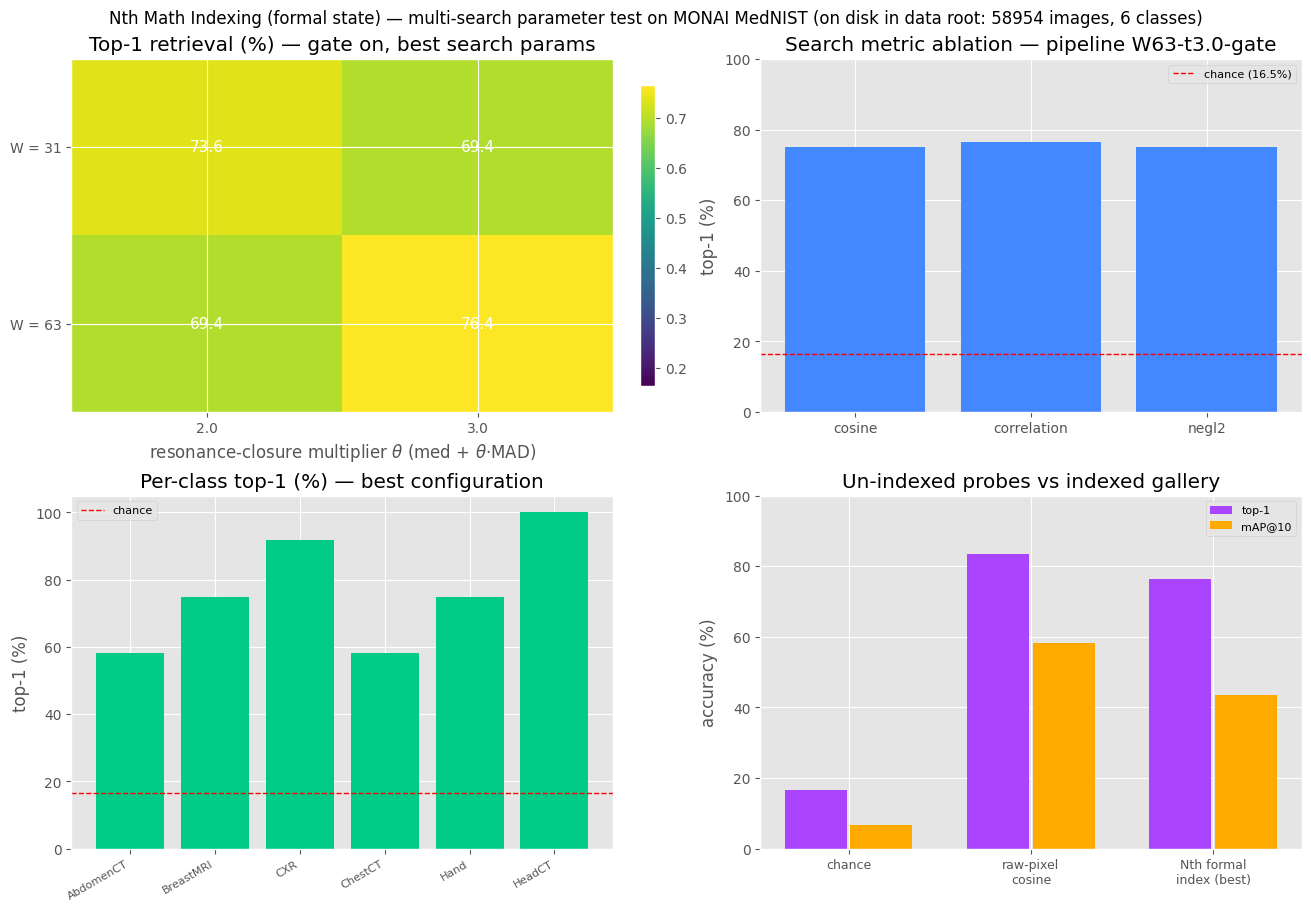


Artifacts saved: nth_monai_multisearch_report.png, nth_monai_multisearch_results.csv
Multi-search parameter test complete — the formal state was indexed, queried and ablated with no oracle reference at any stage.


In [7]:
# -*- coding: utf-8 -*-
"""
NTH MATHEMATICS INDEXING — FORMAL STATE vs. UN-INDEXED PUBLIC DATASET
(MONAI MedNIST) + MULTI-SEARCH PARAMETER TEST — Cells 11 & 12

Companion cells to `nth_math_indexing_formal_colab.py` (Cells 1-10).

PREREQUISITE: run Cells 1-7 of the formal build first (Cells 8-10 optional).
These cells reuse — without redefinition — the formal operator stack:

    Selector, nth_primes_asymmetric, sdp_deviation, is_structurally_prime_sel,
    delta_metric, nth_fusion_vec, fusion_asymmetry, ALPHA, EPSILON_NTH,
    euler_fusion_weights, euler_diffusion_kernel, local_n_line,
    encode_deviation, decode_trajectory, nth_transform_window,
    nth_inverse_transform, resonance_exposure, robust_center,
    delta_norm_trajectory, delta_norm_coefficients, nth_jacobian_window,
    nth_jacobian_determinant, res_jacobian, delta_evolve, delta_inverse,
    closure_stats

CELL 11 — Un-indexed-dataset harness:
  * acquisition of the public MONAI MedNIST corpus via a four-path ladder
    that never instantiates monai.apps.MedNISTDataset (current MONAI builds
    it on CacheDataset — the constructor decodes and RAM-caches the whole
    47k-image corpus, and its extraction layout is version-dependent):
    on-disk os.walk scan (sees hidden dirs, unlike glob '**') -> archive
    already on disk (md5-verified, extracted by this harness) -> direct
    download of the public release archive -> gdown mirror ->
    clearly-labelled synthetic fallback so the harness still runs offline,
  * image -> 1-D selector-trajectory adapter (block-mean downsample +
    serpentine scan + z-scaling + n-line deviation encoding, Axioms 1.x),
  * oracle-free corpus reference: the Axiom-10 central selectors are
    estimated from a bootstrap of the INDEXED gallery itself (the index
    defines the resonance frame; un-indexed probes are only ever ENCODED
    by that frame — no probe information participates in the index),
  * `run_nth_indexer`: the Cell-6/7 streaming formal state packaged as a
    reusable, parameterized function (dual-line fusion with the Axiom-2.1
    phase rule -> Axiom-10 resonance gain -> Euler fusion diffusion ->
    measurement channel -> windowed NthTransform on prime-carrier modes ->
    resonance projection gate -> J_Nth determinant fusion -> Res() ->
    reflex channels -> hysteresis -> Res() state machine),
  * `nth_signature`: fixed-length index-vector blocks (spectral / Jacobian /
    reflex / trajectory), each L2-normalized so that search-time block
    weightings are well posed,
  * search utilities (sim_matrix / retrieval_metrics) + a SMOKE SEARCH:
    the gallery is indexed once at the reference config and the un-indexed
    probes are retrieved against it, so Cell 11 already reports real
    retrieval results (top-1 / top-5 / mAP + example queries) before the
    Cell-12 parameter sweep,
  * formal compliance guard re-run on real dataset signals (encode
    roundtrip, Axiom 0, inverse-transform roundtrip and DFT recovery at
    the configuration's own basis, Delta^h / Delta^-1 mutual inverse, V2
    SDP carriers).

CELL 12 — Multi-search parameter test:
  * reuses the Cell-11 search utilities (sim_matrix / retrieval_metrics),
  * pipeline-parameter grid: window W in {31, 63} x resonance-closure
    multiplier theta in {2.0, 3.0} x projection gate {on, off},
  * search-parameter grid: similarity metric in {cosine, correlation,
    negative-L2} x signature block weighting in {uniform, spectral,
    reflex},
  * retrieval protocol: un-indexed probes queried against the indexed
    gallery (top-1 / top-5 / mAP@10), with empirical chance and raw-pixel
    baselines,
  * report: ranked pandas table, (W x theta) accuracy heatmap, per-metric
    and per-class panels, CSV + PNG artifacts.
"""

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CELL 11 — Un-indexed Dataset Harness (public MONAI MedNIST)              ║
# ║  adapter · oracle-free corpus reference · parameterized formal indexer    ║
# ╚══════════════════════════════════════════════════════════════════════════╝

import hashlib as _hashlib
import os as _os
import subprocess as _subprocess
import sys as _sys
import tarfile as _tarfile
import time as _time
import urllib.request as _urllib_request

DATA_ROOT = "./nth_monai_data"      # download / extraction directory
N_PER_CLASS = 24                    # images loaded per class (12 gallery + 12 probe)
GALLERY_PER_CLASS = 12              # indexed gallery per class
DS = 2                              # block-mean downsample (64/DS -> 32, T = 1024)
SEED = 2026

# Public MedNIST archive — the same resource monai.apps.MedNISTDataset
# downloads, pinned here (url + md5) so the harness never depends on
# MONAI's version-dependent dataset class:
MEDNIST_URL = ("https://github.com/Project-MONAI/MONAI-extra-test-data/"
               "releases/download/0.8.1/MedNIST.tar.gz")
MEDNIST_MD5 = "0bc7306e7427e00ad1c5526a6677552d"
MEDNIST_GDRIVE_ID = "1QsnnkvZyJPcbRoV_ArW8SnE1TuoQnPu3"   # mirror, same archive

# Fixed formal-state parameters (Cell-6 defaults, n-line scaled to T ~ 1024).
# The SWEPT parameters live in the Cell-12 grid: W, theta_close, use_gate.
COMMON_PRM = dict(
    dual_lag=3,      # temporal dual-line lag (Cell 6)
    nline_win=25,    # rolling-median n-line width (50 at T = 2000 -> 25 at 1024)
    gain=0.7,        # SECONDARY_GAIN — Axiom-10 resonance-exposure gain
    pred_h=5,        # PRED_HORIZON — symbolic horizon h of the Delta^h evolution
    radius=2,        # Euler fusion-diffusion kernel radius (Cell 6)
)


# ── Dataset acquisition: MONAI MedNIST, four-path ladder ──────────────────

def _pip_install(pkg):
    _subprocess.run([_sys.executable, "-m", "pip", "install", "-q", pkg],
                    check=False)


_IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}


def _scan_image_pool(root, n_per_class):
    """
    Class pool from any directory layout via os.walk over ABSOLUTE paths.
    Unlike glob's '**' pattern (which skips dot-directories and made the
    first MONAI run miss an entire extraction), os.walk descends into
    hidden/temp staging folders, so no extraction layout can hide from it.
    Label = leaf folder name; a class qualifies with >= n_per_class image
    files. The per-class pick is a seeded uniform subsample (deterministic
    across runs and machines), then sorted so the gallery/probe split is
    reproducible. Returns (pool, n_images_seen).
    """
    rng = np.random.default_rng(SEED + 101)
    by_class = {}
    n_img = 0
    for dirpath, _dirnames, filenames in _os.walk(_os.path.abspath(root)):
        for fn in filenames:
            if _os.path.splitext(fn)[1].lower() in _IMG_EXTS:
                n_img += 1
                by_class.setdefault(_os.path.basename(dirpath), []).append(
                    _os.path.join(dirpath, fn))
    pool = {}
    for lbl in sorted(by_class):
        fl = sorted(by_class[lbl])
        if len(fl) < n_per_class:
            continue
        if len(fl) > n_per_class:                      # seeded subsample
            idx = np.sort(rng.choice(len(fl), size=n_per_class, replace=False))
            fl = [fl[i] for i in idx]
        pool[lbl] = fl
    return pool, n_img


def _md5_of(path, chunk=1 << 20):
    h = _hashlib.md5()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _extract_archive(tar_path, dest_root):
    """Own tar.gz extraction (no MONAI dependency). Returns member count."""
    with _tarfile.open(tar_path, "r:gz") as tf:
        members = tf.getmembers()
        try:
            tf.extractall(dest_root, filter="data")     # Python >= 3.12
        except TypeError:                               # older interpreters
            tf.extractall(dest_root)
    return len(members)


def _download_archive(url, dest_path):
    """Direct download of the public release archive (redirect-safe)."""
    def _hook(n_blocks, block_size, total):
        if total > 0:
            pct = min(100, int(n_blocks * block_size * 100.0 / total))
            print(f"\r  [info] downloading MedNIST.tar.gz: {pct:3d}%",
                  end="", flush=True)
    print(f"  [info] fetching the public MedNIST archive ({url})")
    _urllib_request.urlretrieve(url, dest_path, reporthook=_hook)
    print("\r  [info] download finished.                        ")


def _diagnose_root(root):
    """Print what is actually on disk when a scan comes up empty."""
    root = _os.path.abspath(root)
    if not _os.path.isdir(root):
        print(f"    [diag] {root} does not exist")
        return
    entries = sorted(_os.listdir(root))
    shown = ", ".join(entries[:8]) + (" ..." if len(entries) > 8 else "")
    print(f"    [diag] {root}: {len(entries)} entries [{shown}]")
    n_img = sum(1 for _dp, _dn, fns in _os.walk(root)
                for f in fns if _os.path.splitext(f)[1].lower() in _IMG_EXTS)
    print(f"    [diag] image files reachable by os.walk: {n_img}")


def _synthetic_mednist_like(rng, n_per_class, size=64):
    """
    Offline fallback corpus (clearly labelled as synthetic): six structured
    texture classes standing in for the MedNIST modalities. Keeps the
    multi-search harness runnable when the public download is unavailable;
    results are then harness diagnostics, not MONAI measurements.
    """
    yy, xx = np.mgrid[0:size, 0:size].astype(float) / size
    r = np.sqrt((xx - 0.5) ** 2 + (yy - 0.5) ** 2)
    specs = {
        "SynthHeadCT":    lambda: 0.5 + 0.35 * np.sin(2 * np.pi * (6 * xx + 5 * yy)),
        "SynthChestXR":   lambda: 0.6 - 0.3 * r + 0.05 * np.sin(2 * np.pi * 2 * xx),
        "SynthCT":        lambda: 0.35 + 0.55 * np.exp(-((r - 0.32) / 0.08) ** 2),
        "SynthMRI":       lambda: 0.3 + 0.3 * np.sin(2 * np.pi * 3 * xx)
                                   * np.sin(2 * np.pi * 2 * yy),
        "SynthHand":      lambda: 0.25 + 0.6 * (
            np.exp(-((xx - 0.35) ** 2 / 0.002 + (yy - 0.5) ** 2 / 0.02))
            + np.exp(-((xx - 0.65) ** 2 / 0.002 + (yy - 0.5) ** 2 / 0.02))),
        "SynthBreastMRI": lambda: 0.3 + 0.5 * np.exp(-(((xx - 0.4) ** 2
                                                       + (yy - 0.45) ** 2) / 0.01))
                                   + 0.35 * np.exp(-(((xx - 0.62) ** 2
                                                      + (yy - 0.6) ** 2) / 0.02)),
    }
    noise = {"SynthHeadCT": 0.06, "SynthChestXR": 0.14, "SynthCT": 0.04,
             "SynthMRI": 0.05, "SynthHand": 0.05, "SynthBreastMRI": 0.12}
    return {lbl: [np.clip(specs[lbl]() + rng.normal(0.0, noise[lbl], (size, size)),
                          0.0, 1.0) for _ in range(n_per_class)]
            for lbl in specs}


def acquire_mednist(root, n_per_class):
    """
    Acquire the public MONAI MedNIST corpus. Ladder, each step re-scanning:

      0. on-disk scan of the data root, then of the notebook directory
         (picks up any previously extracted copy, wherever it landed);
      A. archive already on disk (e.g. downloaded by an earlier MONAI run):
         md5-verified and extracted by THIS harness;
      B. direct download of the public release archive + own extraction;
      C. gdown mirror of the same archive + own extraction;
      D. clearly-labelled synthetic fallback (offline harness diagnostics).

    monai.apps.MedNISTDataset is deliberately never instantiated: current
    MONAI builds it on CacheDataset (the constructor decodes and RAM-caches
    the whole 47k-image corpus — the 43 s 'Loading dataset' bar) and its
    extraction layout is version-dependent. This harness only needs files
    on disk, so it owns download-verify-extract-scan itself.
    Returns (class -> file list, source name); lists are sorted =>
    deterministic.
    """
    root = _os.path.abspath(root)
    _os.makedirs(root, exist_ok=True)
    tar_path = _os.path.join(root, "MedNIST.tar.gz")

    # ── Path 0: corpus already extracted on disk ────────────────────────
    for scan_root, tag in ((root, "data root"),
                           (_os.path.abspath(_os.curdir), "notebook directory")):
        pool, n_img = _scan_image_pool(scan_root, n_per_class)
        if len(pool) >= 2:
            return pool, (f"MONAI MedNIST (on disk in {tag}: "
                          f"{n_img} images, {len(pool)} classes)")

    # ── Path A: archive already on disk — verify, extract, rescan ───────
    if _os.path.exists(tar_path):
        try:
            if _md5_of(tar_path) != MEDNIST_MD5:
                print("  [warn] cached MedNIST.tar.gz fails md5 — removing it")
                _os.remove(tar_path)
            else:
                n_mem = _extract_archive(tar_path, root)
                pool, n_img = _scan_image_pool(root, n_per_class)
                if len(pool) >= 2:
                    return pool, (f"MONAI MedNIST (archive already on disk: "
                                  f"{n_mem} members extracted, {n_img} images)")
                print(f"  [warn] Path A extracted {n_mem} members "
                      f"but no class pool:")
                _diagnose_root(root)
        except Exception as e_a:
            print(f"  [warn] Path A (archive on disk) unavailable: {e_a}")

    # ── Path B: direct download of the public release archive ──────────
    try:
        _download_archive(MEDNIST_URL, tar_path)
        if _md5_of(tar_path) != MEDNIST_MD5:
            _os.remove(tar_path)
            raise RuntimeError("downloaded archive failed md5 verification")
        n_mem = _extract_archive(tar_path, root)
        pool, n_img = _scan_image_pool(root, n_per_class)
        if len(pool) >= 2:
            return pool, (f"MONAI MedNIST (public release archive: "
                          f"{n_mem} members, {n_img} images)")
        print(f"  [warn] Path B extracted {n_mem} members but no class pool:")
        _diagnose_root(root)
        raise RuntimeError("no class pool after direct download+extraction")
    except Exception as e_b:
        print(f"  [warn] Path B (direct archive download) unavailable: {e_b}")

    # ── Path C: gdown mirror of the public archive ──────────────────────
    try:
        try:
            import gdown  # noqa: F401
        except ImportError:
            _pip_install("gdown")
        import gdown
        if _os.path.exists(tar_path):
            _os.remove(tar_path)
        gdown.download(id=MEDNIST_GDRIVE_ID, output=tar_path, quiet=True)
        if _md5_of(tar_path) != MEDNIST_MD5:
            raise RuntimeError("gdown mirror failed md5 verification")
        n_mem = _extract_archive(tar_path, root)
        pool, n_img = _scan_image_pool(root, n_per_class)
        if len(pool) >= 2:
            return pool, (f"MONAI MedNIST (gdown mirror: "
                          f"{n_mem} members, {n_img} images)")
        raise RuntimeError("no class pool after gdown extraction")
    except Exception as e_c:
        print(f"  [warn] Path C (gdown mirror) unavailable: {e_c}")

    # ── Path D: synthetic fallback ──────────────────────────────────────
    print("  [warn] falling back to the SYNTHETIC MedNIST-like corpus —")
    print("         results below are harness diagnostics, not MONAI measurements.")
    return None, "SYNTHETIC-FALLBACK"


def load_dataset(root, n_per_class, rng):
    pool, source = acquire_mednist(root, n_per_class)
    if pool is not None:
        try:
            from PIL import Image
        except ImportError:
            _pip_install("pillow")
            from PIL import Image
        images = {lbl: [np.asarray(Image.open(f).convert("L"), dtype=float)
                        for f in files]
                  for lbl, files in sorted(pool.items())}
    else:
        images = _synthetic_mednist_like(rng, n_per_class)
    return images, source


# ── Image -> 1-D signal adapter ───────────────────────────────────────────

def block_mean(img, ds):
    """Non-overlapping block mean (ds x ds) — scale layer of the scan."""
    h, w = img.shape
    h2, w2 = h // ds, w // ds
    return img[:h2 * ds, :w2 * ds].reshape(h2, ds, w2, ds).mean(axis=(1, 3))


def serpentine_scan(img):
    """
    Boustrophedon (row-alternating) raster scan: continuous across row
    boundaries, so no artificial discontinuities enter the selector
    trajectory (only genuine image structure produces phase inversions).
    """
    rows = [row if i % 2 == 0 else row[::-1] for i, row in enumerate(img)]
    return np.concatenate([np.asarray(r, float) for r in rows])


def image_to_signal(img, ds=2):
    """Image -> z-scaled 1-D signal of length T = (64/ds)^2 for the n-line
    deviation encoding. z-scaling makes deviation magnitudes comparable
    across images (exposure amplitudes, not absolute intensities)."""
    if ds > 1:
        img = block_mean(np.asarray(img, float), ds)
    sig = serpentine_scan(img)
    return (sig - sig.mean()) / (sig.std() + 1e-12)


def make_nth_basis(W):
    """
    Prime-carrier mode basis at width W (Cell-4 convention): real channel
    carried by cos, unreal channel by -sin (exp(-2*pi*jk/W) — the DFT
    imaginary part under restriction). Carriers anchor mode identity via
    the V2 SDP rule and divide out of the normalization.
    """
    K = W // 2 + 1
    th = 2.0 * np.pi * np.outer(np.arange(W), np.arange(K)) / W
    return np.cos(th), -np.sin(th), K


# ── Oracle-free corpus reference (Axiom-10 central selectors) ─────────────

def build_corpus_reference(sigs, prm, rng, n_boot=16, per_sig=2, n_meas=2):
    """
    Pipeline-consistent Axiom-10 central selectors estimated from a
    bootstrap of the INDEXED gallery — the formal counterpart of the
    Cell-6 event-window reference, with the oracle removed: the index's
    resonance frame is the corpus itself, and un-indexed probes are only
    encoded by it (never part of it).

    Stage 1 — position-level center: robust center (median / MAD) of the
    pooled raw selector magnitudes, majority phase.
    Stage 2 — pipeline-consistent profile: bootstrap windows pushed through
    the SAME dual-fusion -> resonance-gain -> Euler-diffusion -> measurement
    chain the indexer applies in flight; REF_SCALE is the median window
    resonance scale; the mode-level mu/sigma follow from the noiseless and
    noisy measurement realizations (sigma per mode, as in Cell 6).
    The corpus central R-pattern is the sign-aligned pooled median: each
    window's coefficient pattern is dual-phase aligned (+/-) to the median
    direction before pooling — the Law of Symbolic Dual Resonance (Axiom 0)
    makes the +/- ambiguity of the resonance projection absorvable, so the
    median is a meaningful central selector even for heterogeneous corpora.
    """
    W = int(prm["W"]); HALF = W // 2
    cos_b, sin_b, K = make_nth_basis(W)
    kern = euler_diffusion_kernel(radius=prm["radius"], level=4)
    pad = len(kern) // 2

    wins = []
    idx = rng.permutation(len(sigs))[:min(n_boot, len(sigs))]
    for si in idx:
        sig = sigs[si]
        nline = local_n_line(sig, prm["nline_win"])
        k_all, p_all = encode_deviation(sig, nline)
        k_dual = np.roll(k_all, prm["dual_lag"])
        p_dual = np.roll(p_all, prm["dual_lag"])
        for c in rng.integers(HALF, len(sig) - HALF, size=per_sig):
            lo, hi = int(c) - HALF, int(c) + HALF + 1
            wins.append((k_all[lo:hi], p_all[lo:hi],
                         k_dual[lo:hi], p_dual[lo:hi]))

    # Stage 1: position-level center (raw magnitudes of the bootstrap)
    kpool = np.concatenate([w[0] for w in wins])
    ppool = np.concatenate([w[1] for w in wins])
    mu_pos_k, sigma_pos = robust_center(kpool)
    mu_pos_p = 1 if np.sum(ppool > 0) >= np.sum(ppool < 0) else -1

    # Stage 2: pipeline-consistent diffused windows
    signed_list = []
    for kA, pA, kB, pB in wins:
        fus = nth_fusion_vec(kA, pA, kB, pB)
        k_f = 0.5 * fus["R"][0]
        p_f = pA * pB                                   # Axiom 2.1 phase rule
        expo = resonance_exposure(k_f, p_f, mu_pos_k, mu_pos_p, sigma_pos)
        k_g = k_f * (1.0 + prm["gain"] * expo)
        sg = np.convolve(np.pad(k_g * p_f, (pad, pad), mode="edge"),
                         kern, mode="valid")
        signed_list.append(sg)
    ref_scale = float(np.median([np.max(np.abs(s)) for s in signed_list])) + 1e-12

    def _state(sg):
        kn = np.abs(sg) / ref_scale
        kn[kn < 0.05] = 0.0
        pn = np.where(sg >= 0, 1, -1).astype(np.int8)
        return kn, pn

    R_list, U_list = [], []
    for sg in signed_list:
        kn, pn = _state(sg)
        R_w, U_w, _, _ = nth_transform_window(kn, pn, cos_b, sin_b, W)
        R_list.append(R_w); U_list.append(U_w)
    R_arr = np.array(R_list); U_arr = np.array(U_list)

    amp_noisy = []
    for sg in signed_list:
        for _ in range(n_meas):                          # measurement realizations
            kn, pn = _state(sg + 0.10 * rng.standard_normal(W))
            R_m, U_m, _, _ = nth_transform_window(kn, pn, cos_b, sin_b, W)
            amp_noisy.append(np.sqrt(R_m ** 2 + U_m ** 2))
    amp_noisy = np.array(amp_noisy)

    amp_arr = np.sqrt(R_arr ** 2 + U_arr ** 2)
    mu_mode_k = np.median(amp_arr, axis=0)
    sigma_mode = np.maximum(np.median(np.abs(amp_noisy - mu_mode_k[None, :]),
                                      axis=0), 1e-4)
    mu_mode_p = np.where(np.abs(np.median(R_arr, axis=0))
                         >= np.abs(np.median(U_arr, axis=0)), 1, -1).astype(np.int8)

    # Corpus central R-pattern: sign-aligned pooled median (Axiom-0 alignment)
    Rn = R_arr / (np.linalg.norm(R_arr, axis=1, keepdims=True) + 1e-12)
    med_dir = np.median(Rn, axis=0)
    med_dir = med_dir / (np.linalg.norm(med_dir) + 1e-12)
    signs = np.sign(Rn @ med_dir); signs[signs == 0] = 1.0
    ref_R = np.median(R_arr * signs[:, None], axis=0)
    E_ref = float(np.sum(ref_R ** 2)) + 1e-12
    coherence = float(np.linalg.norm(ref_R)
                      / (np.mean(np.linalg.norm(R_arr, axis=1)) + 1e-12))

    return dict(mu_pos_k=mu_pos_k, mu_pos_p=mu_pos_p, sigma_pos=sigma_pos,
                mu_mode_k=mu_mode_k, mu_mode_p=mu_mode_p,
                sigma_mode=sigma_mode, ref_R=ref_R, E_ref=E_ref,
                ref_scale=ref_scale, coherence=coherence, n_boot=len(wins))


# ── Parameterized streaming formal indexer (Cells 6+7 packaged) ───────────

def run_nth_indexer(sig, prm, ref, rng):
    """
    The Cell-6/7 streaming formal state as a reusable function on any 1-D
    signal, in the resonance frame `ref` (corpus reference). Per window:

      dual-line fusion (Axiom 2.1 phase rule) -> Axiom-10 resonance gain ->
      Euler fusion diffusion -> measurement channel (stochastic selectors)
      -> windowed NthTransform (prime-carrier modes) -> resonance gate
      (projection of the window's real-channel coefficients onto the corpus
      central pattern, normalized to 1 at the center) -> J_Nth determinant
      fusion + Res() -> reflex channels (Delta^2 accel under the delta
      metric, fusion-asymmetry double flips, Delta^h predictive lineage
      divergence) -> theta-parameterized resonance-closure thresholds ->
      hysteretic latch -> Res() state machine.

    `use_gate=False` disables the projection gate (ablation config) — the
    reflex layer then sees the un-gated pipeline state.
    """
    W = int(prm["W"]); HALF = W // 2
    cos_b, sin_b, K = make_nth_basis(W)
    kern = euler_diffusion_kernel(radius=prm["radius"], level=4)
    pad = len(kern) // 2

    nline = local_n_line(np.asarray(sig, float), prm["nline_win"])
    k_all, p_all = encode_deviation(sig, nline)
    k_dual = np.roll(k_all, prm["dual_lag"])       # temporal dual (wrap at t=0,
    p_dual = np.roll(p_all, prm["dual_lag"])       # as in Cell 6)
    Tn = len(sig)

    E_l, JR_l, JU_l, JC1_l, JC2_l, Res_l, Jm_l, gate_l = \
        [], [], [], [], [], [], [], []
    profR = np.zeros(K); profU = np.zeros(K); n_win = 0
    accel_l, curv_l, lineage_l = [], [], []
    prev_m = prev2_m = prev_p = prev_prev_p = prev_dk = None

    for center in range(Tn):
        lo = max(0, center - HALF); hi = lo + W
        if hi > Tn:
            break
        kA, pA = k_all[lo:hi], p_all[lo:hi]
        kB, pB = k_dual[lo:hi], p_dual[lo:hi]

        # dual-line fusion (Axiom 2): R-channel magnitude, phase product
        fus = nth_fusion_vec(kA, pA, kB, pB)
        k_f = 0.5 * fus["R"][0]
        p_f = pA * pB
        # Axiom-10 resonance gain w.r.t. the position-level central selector
        expo_pos = resonance_exposure(k_f, p_f, ref["mu_pos_k"],
                                      ref["mu_pos_p"], ref["sigma_pos"])
        k_g = k_f * (1.0 + prm["gain"] * expo_pos)
        # fusion diffusion (dual-symmetrized Euler selector weights)
        signed = np.convolve(np.pad(k_g * p_f, (pad, pad), mode="edge"),
                             kern, mode="valid")
        # measurement channel (streaming noise schedule, as in Cell 6)
        noise_level = 0.05 + 0.05 * np.sin(2.0 * np.pi * center / 700.0)
        sg = signed + noise_level * rng.standard_normal(W)
        kn = np.abs(sg) / ref["ref_scale"]
        kn[kn < 0.05] = 0.0
        pn = np.where(sg >= 0, 1, -1).astype(np.int8)

        # windowed NthTransform (prime-carrier modes)
        R_w, U_w, _, _ = nth_transform_window(kn, pn, cos_b, sin_b, W)
        amp = np.sqrt(R_w ** 2 + U_w ** 2)
        mphase = np.where(np.abs(R_w) >= np.abs(U_w), 1, -1)
        expo_mode = resonance_exposure(amp, mphase, ref["mu_mode_k"],
                                       ref["mu_mode_p"], ref["sigma_mode"])
        E = float(np.sum(expo_mode * (np.abs(R_w) + EPSILON_NTH * np.abs(U_w))))
        # resonance projection gate onto the corpus central R-pattern
        R_dot = float(np.sum(R_w * ref["ref_R"]))

        # Nth Jacobian of the evolution map + determinant fusion + Res()
        aJ, bJ, cJ, dJ = nth_jacobian_window(kn, pn)
        JR, JU, JC1, JC2 = nth_jacobian_determinant(aJ, bJ, cJ, dJ)

        E_l.append(E); JR_l.append(JR); JU_l.append(JU); JC1_l.append(JC1)
        JC2_l.append(JC2); Jm_l.append(abs(JR) + abs(JC1) + abs(JC2))
        Res_l.append(res_jacobian(JR, JU, JC1, JC2))
        profR += np.abs(R_w); profU += np.abs(U_w); n_win += 1

        g_res = (max(0.0, min(1.0, R_dot / ref["E_ref"]))
                 if prm["use_gate"] else 1.0)
        gate_l.append(g_res)
        k_r = kn * g_res
        k_r[k_r < 0.05] = 0.0
        p_r = np.where(k_r > 0, pn, 1).astype(np.int8)

        # reflex channel accumulation (identical alignment to Cell 6)
        if prev_m is not None:
            dk = k_r - prev_m
            if prev_dk is not None:
                mag_t, ph_t = np.abs(dk), np.sign(dk)
                mag_p, ph_p = np.abs(prev_dk), np.sign(prev_dk)
                accel_l.append(float((np.abs(mag_t - mag_p)
                                      + ALPHA * (ph_t != ph_p)).max()))
            prev_dk = dk
            if prev_p is not None and prev_prev_p is not None:
                f1 = (p_r != prev_p); f2 = (prev_p != prev_prev_p)
                curv_l.append(int(np.sum(f1 != f2)))
            if prev2_m is not None:
                L_hat = delta_evolve(prev_m, prev2_m, prm["pred_h"])
                D_t = np.abs(k_r - L_hat) + ALPHA * (p_r != prev_p)
                lineage_l.append(float(np.sum(D_t)))
            prev2_m = prev_m
        prev_prev_p = prev_p
        prev_p = p_r
        prev_m = k_r

    out = {
        "W": W, "K": K, "n_win": n_win, "T": Tn,
        "k_all": k_all, "p_all": p_all,
        "profR": profR / max(n_win, 1), "profU": profU / max(n_win, 1),
        "E": np.asarray(E_l), "JR": np.asarray(JR_l), "JU": np.asarray(JU_l),
        "JC1": np.asarray(JC1_l), "JC2": np.asarray(JC2_l),
        "Res": np.asarray(Res_l), "J_mass": np.asarray(Jm_l),
        "gate": np.asarray(gate_l),
    }

    # ── reflex layer + Res() state machine (Cell 7, theta-parameterized) ──
    accel_arr = np.asarray(accel_l, float)
    curv_arr = np.asarray(curv_l, float)
    lineage_arr = np.asarray(lineage_l, float)
    L = int(min(accel_arr.size, curv_arr.size, lineage_arr.size))

    if L >= 8:
        med_a, mad_a = closure_stats(accel_arr[:L])
        th_a = med_a + prm["theta_close"] * mad_a
        med_c, mad_c = closure_stats(curv_arr[:L])
        th_c = med_c + prm["theta_close"] * mad_c
        med_l, mad_l = closure_stats(lineage_arr[:L])
        th_l = med_l + prm["theta_close"] * mad_l
        a_norm = np.maximum(0.0, (accel_arr[:L] - med_a) / (th_a - med_a + 1e-9))
        c_norm = np.maximum(0.0, (curv_arr[:L] - med_c) / (th_c - med_c + 1e-9))
        l_norm = np.maximum(0.0, (lineage_arr[:L] - med_l) / (th_l - med_l + 1e-9))
        w_ref = euler_fusion_weights(3)                # [1, 2, 2] / 5
        fusion_scores = w_ref[0] * a_norm + w_ref[1] * c_norm + w_ref[2] * l_norm

        fusion_med, fusion_mad = closure_stats(fusion_scores)
        th_on = fusion_med + prm["theta_close"] * fusion_mad   # rho = e^-2 level
        th_off = fusion_med                                    # dev-stable limit
        fusion_padded = np.pad(fusion_scores, (1, 0), mode="edge")
        pred_scores = delta_evolve(fusion_scores, fusion_padded[:-1], prm["pred_h"])
        pred_med, pred_mad = closure_stats(pred_scores)
        th_pred = pred_med + prm["theta_close"] * pred_mad
        preempt_flags = pred_scores > th_pred

        reflex_fused = np.zeros(L, dtype=bool); active = False
        for i in range(L):
            if not active and (fusion_scores[i] > th_on or preempt_flags[i]):
                active = True
            elif active and fusion_scores[i] < th_off and not preempt_flags[i]:
                active = False
            reflex_fused[i] = active

        state = 0; states = []
        for i in range(L):
            s = fusion_scores[i]; s_pred = pred_scores[i]
            preempt = preempt_flags[i]
            if state == 0:                                   # Idle
                if preempt and s_pred > th_on:
                    state = 4                                # Preempt
                elif s > th_on:
                    state = 1                                # Track
            elif state == 4:                                 # Preempt
                if s > th_on * 1.5:
                    state = 2                                # Engage
                elif s < th_off and not preempt:
                    state = 0
            elif state == 1:                                 # Track
                if preempt and s_pred > th_on * 1.5:
                    state = 4
                elif s > th_on * 1.5:
                    state = 2
                elif s < th_off and not preempt:
                    state = 0
            elif state == 2:                                 # Engage
                if s > th_on * 2.0 or (preempt and s_pred > th_on * 2.0):
                    state = 3                                # Evade
                elif s < th_off and not preempt:
                    state = 1
            elif state == 3:                                 # Evade
                if s < th_off and not preempt:
                    state = 1
            states.append(state)
        out.update(dict(
            L=L, fusion_scores=fusion_scores, pred_scores=pred_scores,
            preempt=preempt_flags, reflex_fused=reflex_fused,
            states=np.asarray(states, int),
            reflex_accel=accel_arr[:L] > th_a,
            reflex_curv=curv_arr[:L] > th_c,
            reflex_lineage=lineage_arr[:L] > th_l,
            th=dict(a=th_a, c=th_c, l=th_l, on=th_on, off=th_off, pred=th_pred),
        ))
    else:
        out.update(dict(L=L, fusion_scores=np.zeros(0),
                        pred_scores=np.zeros(0), preempt=np.zeros(0, bool),
                        reflex_fused=np.zeros(0, bool),
                        states=np.zeros(0, int),
                        reflex_accel=np.zeros(0, bool),
                        reflex_curv=np.zeros(0, bool),
                        reflex_lineage=np.zeros(0, bool), th={}))
    return out


# ── Fixed-length signature blocks ─────────────────────────────────────────

def _resample(x, n):
    x = np.asarray(x, float)
    if x.size == 0:
        return np.zeros(n)
    if x.size == 1:
        return np.full(n, float(x[0]))
    return np.interp(np.linspace(0.0, 1.0, n),
                     np.linspace(0.0, 1.0, x.size), x)


def _l2(v):
    n = float(np.linalg.norm(v))
    return v / n if n > 1e-12 else np.zeros_like(v)


def _safe_mean(x):
    x = np.asarray(x)
    return float(x.mean()) if x.size else 0.0


BLOCKS = ("spec", "jac", "reflex", "traj")


def nth_signature(out, n_bins_f=16, n_bins_t=8):
    """
    Fixed-length index vector of one signal's formal state, in blocks:

      spec   — mean windowed-NthTransform mode-amplitude profiles (|R|, |U|),
               resampled to n_bins_f bins each: the carrier-mode spectrum.
      jac    — J_Nth tuple statistics (mean/std of R, U, C1, C2, Res, mass)
               + the temporal J-mass profile: evolution-map geometry.
      reflex — fused-reflex temporal profile + Res() state occupancy +
               per-channel trigger densities: the reflex state of the stream.
      traj   — whole-trajectory formals: fusion asymmetry, unreal share,
               delta norms and their Parseval analog, mean resonance gate,
               event density, resonance-energy stats.

    Each block is L2-normalized so search-time block weightings act on
    unit-mass components (formally: comparing exposures, not raw scales).
    """
    spec = np.concatenate([_resample(out["profR"], n_bins_f),
                           _resample(out["profU"], n_bins_f)])
    jac_stats = []
    for key in ("JR", "JU", "JC1", "JC2", "Res", "J_mass"):
        jac_stats += [_safe_mean(out[key]),
                      float(np.std(out[key])) if out[key].size else 0.0]
    jac = np.concatenate([np.asarray(jac_stats),
                          _resample(out["J_mass"], n_bins_t)])
    reflex = np.concatenate([
        _resample(out["fusion_scores"], n_bins_t),
        np.array([_safe_mean(out["states"] == s) for s in range(5)]),
        np.array([_safe_mean(out["reflex_accel"]),
                  _safe_mean(out["reflex_curv"]),
                  _safe_mean(out["reflex_lineage"]),
                  _safe_mean(out["preempt"])], float),
    ])
    k_all, p_all = out["k_all"], out["p_all"]
    fa = fusion_asymmetry(k_all, p_all)
    dnt = delta_norm_trajectory(k_all, p_all)
    dnc = delta_norm_coefficients(out["profR"], out["profU"])
    traj = np.array([
        fa / (np.pi / 2.0),
        float(np.mean(p_all < 0)),
        dnt, dnc, dnt / (dnc + 1e-12),
        _safe_mean(out["gate"]),
        _safe_mean(out["reflex_fused"]),
        _safe_mean(out["E"]),
        float(np.std(out["E"])) if out["E"].size else 0.0,
    ], float)
    return {"spec": _l2(spec), "jac": _l2(jac),
            "reflex": _l2(reflex), "traj": _l2(traj)}


def signature_vector(blocks, weights):
    """Search-time weighted fusion of the L2-normalized blocks."""
    v = np.concatenate([float(weights.get(b, 1.0)) * blocks[b] for b in BLOCKS])
    return _l2(v)


# ── Search utilities (Cell-11 smoke search + Cell-12 sweep) ───────────────

K_MAP = 10          # mAP truncation depth


def _l2_rows(M):
    n = np.linalg.norm(M, axis=1, keepdims=True)
    return M / np.maximum(n, 1e-12)


def sim_matrix(P, G, metric):
    """Probe x gallery similarity under a search metric."""
    if metric == "cosine":
        return _l2_rows(P) @ _l2_rows(G).T
    if metric == "correlation":
        Pc = P - P.mean(axis=1, keepdims=True)
        Gc = G - G.mean(axis=1, keepdims=True)
        return _l2_rows(Pc) @ _l2_rows(Gc).T
    if metric == "negl2":
        d2 = (np.sum(P ** 2, axis=1)[:, None] + np.sum(G ** 2, axis=1)[None, :]
              - 2.0 * P @ G.T)
        return -np.sqrt(np.maximum(d2, 0.0))
    raise ValueError(f"unknown metric: {metric}")


def retrieval_metrics(S, probe_lbls, gallery_lbls, k_map=K_MAP):
    """Top-1 / top-5 / truncated mAP of un-indexed probes vs the index."""
    k_map = min(k_map, S.shape[1])
    order = np.argsort(-S, axis=1)
    top1 = float(np.mean(probe_lbls == gallery_lbls[order[:, 0]]))
    top5 = float(np.mean([probe_lbls[i] in gallery_lbls[order[i, :min(5, S.shape[1])]]
                          for i in range(len(probe_lbls))]))
    aps = []
    for i in range(len(probe_lbls)):
        rel = (gallery_lbls[order[i, :k_map]] == probe_lbls[i]).astype(float)
        n_rel = int(np.sum(gallery_lbls == probe_lbls[i]))
        if rel.sum() > 0 and n_rel > 0:
            prec = np.cumsum(rel) / np.arange(1, k_map + 1)
            aps.append(float(np.sum(prec * rel) / min(n_rel, k_map)))
        else:
            aps.append(0.0)
    return dict(top1=top1, top5=top5, mAP=float(np.mean(aps)))


# ── Formal compliance guard (re-run on real dataset signals) ──────────────

def formal_compliance_guard(sig, prm):
    """Axiom spot-checks at the configuration's own basis and signal."""
    checks = []
    nline = local_n_line(np.asarray(sig, float), prm["nline_win"])
    k_all, p_all = encode_deviation(sig, nline)
    rt = float(np.max(np.abs(decode_trajectory(k_all, p_all) - (sig - nline))))
    checks.append(("n-line encode/decode roundtrip (Fusion Collapse Quotient)",
                   rt == 0.0))

    fa = fusion_asymmetry(k_all, p_all)
    fan = fusion_asymmetry(k_all, -p_all)              # symbolic dual -F
    s0 = ((fa + fan) % (2 * np.pi)) % (2 * np.pi)
    checks.append(("Axiom 0: FA(tau) + FA(-tau) = pi (mod 2*pi)",
                   abs(s0 - np.pi) < 1e-9))

    W = int(prm["W"]); HALF = W // 2; K = W // 2 + 1
    lo = len(sig) // 2 - HALF; hi = lo + W
    f = decode_trajectory(k_all[lo:hi], p_all[lo:hi])
    kd = np.abs(f); pd = np.where(f >= 0, 1, -1).astype(np.int8)
    cosb, sinb, _ = make_nth_basis(W)
    Rg, Ug, _, _ = nth_transform_window(kd, pd, cosb, sinb, W)
    f_hat = nth_inverse_transform(Rg, Ug, W)
    checks.append((f"Inverse NthTransform roundtrip at W = {W}",
                   float(np.max(np.abs(f_hat - f))) < 1e-10))
    fft_ref = np.fft.fft(f) / W
    err = max(float(np.max(np.abs(Rg - fft_ref[:K].real))),
              float(np.max(np.abs(Ug - fft_ref[:K].imag))))
    checks.append((f"DFT recovery under restriction at W = {W}", err < 1e-10))

    x0 = np.array([0.2, 0.5, 1.1]); x1 = np.array([0.4, 0.9, 1.7]); v = x1 - x0
    xh = delta_evolve(x1, x0, prm["pred_h"])
    xb = delta_inverse(x1, x0, prm["pred_h"])
    ok = (np.allclose(delta_inverse(xh, xh - v, prm["pred_h"]), x1)
          and np.allclose(delta_evolve(xb, xb - v, prm["pred_h"]), x1))
    checks.append(("Delta^h / Delta^-1 mutual inverse (velocity-field "
                   "composition)", bool(ok)))
    carriers = nth_primes_asymmetric(K)
    checks.append(("V2 SDP carriers prime at config K",
                   all(is_structurally_prime_sel(c.k, abs(c.p)) for c in carriers)))

    print("Formal compliance guard (dataset signals, config basis):")
    n_ok = 0
    for name, ok in checks:
        n_ok += int(bool(ok))
        print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
    print(f"  guard summary: {n_ok}/{len(checks)} checks PASS")
    return n_ok == len(checks)


# ── Cell-11 execution: load, split, adapt, guard ──────────────────────────

print("=== CELL 11: Un-indexed dataset harness (public MONAI MedNIST) ===\n")

_rng_data = np.random.default_rng(SEED)
IMAGES, DATA_SOURCE = load_dataset(DATA_ROOT, N_PER_CLASS, _rng_data)
CLASSES = sorted(IMAGES.keys())

GALLERY, PROBE = {}, {}
for _lbl in CLASSES:
    _imgs = IMAGES[_lbl]
    GALLERY[_lbl] = _imgs[:GALLERY_PER_CLASS]
    PROBE[_lbl] = _imgs[GALLERY_PER_CLASS:]

gallery_sigs, gallery_labels = [], []
probe_sigs, probe_labels = [], []
for _lbl in CLASSES:
    gallery_sigs += [image_to_signal(_im, DS) for _im in GALLERY[_lbl]]
    gallery_labels += [_lbl] * len(GALLERY[_lbl])
    probe_sigs += [image_to_signal(_im, DS) for _im in PROBE[_lbl]]
    probe_labels += [_lbl] * len(PROBE[_lbl])
gallery_labels = np.array(gallery_labels)
probe_labels = np.array(probe_labels)

_p_gc = np.unique(gallery_labels, return_counts=True)[1] / len(gallery_labels)
CHANCE_TOP1 = float(np.sum(_p_gc ** 2))

print(f"Dataset source:      {DATA_SOURCE}")
print(f"Classes ({len(CLASSES)}):     {CLASSES}")
print(f"Gallery (to index):  {len(gallery_sigs)} signals "
      f"({GALLERY_PER_CLASS}/class)")
print(f"Probe (un-indexed):  {len(probe_sigs)} signals "
      f"({N_PER_CLASS - GALLERY_PER_CLASS}/class)")
print(f"Signal length T = {len(gallery_sigs[0])} "
      f"(block-mean ds = {DS}, serpentine scan)")
print(f"Chance top-1 (gallery class frequencies): {CHANCE_TOP1:.4f}\n")

_guard_prm = {**COMMON_PRM, "W": 63, "theta_close": 2.0, "use_gate": True}
GUARD_OK = formal_compliance_guard(gallery_sigs[0], _guard_prm)

# ── Smoke search: index the gallery once at the reference config and
#    retrieve the un-indexed probes (Cell 12 sweeps the parameter grids) ──
print("\n--- Smoke search: reference config (W = 63, theta = 2.0, gate on) ---")
SMOKE_PRM = _guard_prm
_t0 = _time.time()
_ref_smoke = build_corpus_reference(gallery_sigs, SMOKE_PRM,
                                    np.random.default_rng(SEED + 91))
_blocks_g = [nth_signature(run_nth_indexer(
                 s, SMOKE_PRM, _ref_smoke, np.random.default_rng(10_000 + i)))
             for i, s in enumerate(gallery_sigs)]
_blocks_p = [nth_signature(run_nth_indexer(
                 s, SMOKE_PRM, _ref_smoke, np.random.default_rng(50_000 + i)))
             for i, s in enumerate(probe_sigs)]
print(f"indexed {len(_blocks_g)} gallery + {len(_blocks_p)} probe signals "
      f"in {_time.time() - _t0:.1f} s "
      f"(corpus coherence {_ref_smoke['coherence']:.3f})")

_UNI = {"spec": 1.0, "jac": 1.0, "reflex": 1.0, "traj": 1.0}
_Gm = np.stack([signature_vector(b, _UNI) for b in _blocks_g])
_Pm = np.stack([signature_vector(b, _UNI) for b in _blocks_p])
_Sm = sim_matrix(_Pm, _Gm, "cosine")
_mm = retrieval_metrics(_Sm, probe_labels, gallery_labels)
print(f"retrieval (cosine, uniform blocks): top-1 = {_mm['top1']:.4f}, "
      f"top-5 = {_mm['top5']:.4f}, mAP@{K_MAP} = {_mm['mAP']:.4f} "
      f"(chance top-1 = {CHANCE_TOP1:.4f})")

_ordm = np.argsort(-_Sm, axis=1)
print("example queries — one probe per class, top-3 retrieved (class, cosine):")
for _c in CLASSES:
    _qi = int(np.flatnonzero(probe_labels == _c)[0])
    _top3 = " | ".join(f"{gallery_labels[_ordm[_qi, j]]} "
                       f"({_Sm[_qi, _ordm[_qi, j]]:+.3f})" for j in range(3))
    _hit = "OK  " if gallery_labels[_ordm[_qi, 0]] == _c else "MISS"
    print(f"  [{_hit}] {_c:>12s} -> {_top3}")

print("\nCell 11 complete — run Cell 12 for the full multi-search parameter test.")

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CELL 12 — Multi-Search Parameter Test                                    ║
# ║  pipeline grid (W x theta x gate) x search grid (metric x block weights)  ║
# ║  un-indexed probes retrieved against the indexed gallery                  ║
# ╚══════════════════════════════════════════════════════════════════════════╝

import pandas as pd

plt.style.use("ggplot")

# ── Pipeline-parameter grid (formal-state configurations) ─────────────────
#   W           window width of the prime-carrier NthTransform basis
#   theta_close resonance-closure multiplier (med + theta*MAD is the level
#               set where exposure rho crosses e^-2 — 2.0 in the formal
#               build; swept here)
#   use_gate    resonance projection gate onto the corpus central pattern
PIPE_GRID = [
    dict(name="W31-t2.0-gate",   W=31, theta_close=2.0, use_gate=True),
    dict(name="W31-t3.0-gate",   W=31, theta_close=3.0, use_gate=True),
    dict(name="W63-t2.0-gate",   W=63, theta_close=2.0, use_gate=True),
    dict(name="W63-t3.0-gate",   W=63, theta_close=3.0, use_gate=True),
    dict(name="W63-t2.0-nogate", W=63, theta_close=2.0, use_gate=False),
]

# ── Search-parameter grid ─────────────────────────────────────────────────
# (sim_matrix / retrieval_metrics / K_MAP are defined in Cell 11 and reused)
METRIC_GRID = ["cosine", "correlation", "negl2"]
WEIGHT_GRIDS = {
    "uniform":  {"spec": 1.0, "jac": 1.0, "reflex": 1.0, "traj": 1.0},
    "spectral": {"spec": 3.0, "jac": 1.0, "reflex": 0.5, "traj": 1.0},
    "reflex":   {"spec": 1.0, "jac": 0.5, "reflex": 3.0, "traj": 1.0},
}


# ── Baselines ─────────────────────────────────────────────────────────────

_rng_chance = np.random.default_rng(SEED + 7)
_top1s, _maps = [], []
for _ in range(400):        # empirical chance: random rankings
    _m = retrieval_metrics(_rng_chance.random((len(probe_labels),
                                               len(gallery_labels))),
                           probe_labels, gallery_labels)
    _top1s.append(_m["top1"]); _maps.append(_m["mAP"])
CHANCE_TOP1_MC = float(np.mean(_top1s))
CHANCE_MAP_MC = float(np.mean(_maps))

_Gr = _l2_rows(np.stack(gallery_sigs))       # raw-pixel serpentine baseline
_Pr = _l2_rows(np.stack(probe_sigs))
m_raw = retrieval_metrics(sim_matrix(_Pr, _Gr, "cosine"),
                          probe_labels, gallery_labels)

print("=== CELL 12: Multi-search parameter test ===\n")
print(f"Pipeline configs: {len(PIPE_GRID)}   search configs: "
      f"{len(METRIC_GRID)} metrics x {len(WEIGHT_GRIDS)} block weightings "
      f"= {len(METRIC_GRID) * len(WEIGHT_GRIDS)} per pipeline config")
print(f"Retrieval protocol: {len(probe_labels)} un-indexed probes -> "
      f"{len(gallery_labels)} indexed gallery signals (mAP@{K_MAP})")
print(f"Baselines — chance: top1 = {CHANCE_TOP1_MC:.4f}, "
      f"mAP = {CHANCE_MAP_MC:.4f} (empirical, 400 MC)")
print(f"            raw-pixel cosine: top1 = {m_raw['top1']:.4f}, "
      f"mAP = {m_raw['mAP']:.4f}\n")

# ── Sweep ─────────────────────────────────────────────────────────────────

rows = []
sig_store = {}
t_sweep0 = _time.time()

for ci, cfg in enumerate(PIPE_GRID):
    prm = {**COMMON_PRM, **cfg}
    t0 = _time.time()

    # the resonance frame is estimated from the INDEXED gallery only
    ref = build_corpus_reference(gallery_sigs, prm,
                                 np.random.default_rng(SEED + 91))

    blocks_g, blocks_p = [], []
    ev_dens, nonidle = [], []
    for which, sigs in (("gallery", gallery_sigs), ("probe", probe_sigs)):
        base = 0 if which == "gallery" else 5000
        for i, sig in enumerate(sigs):
            rr = np.random.default_rng(10_000 * (ci + 1) + base + i)
            out = run_nth_indexer(sig, prm, ref, rr)
            blocks = nth_signature(out)
            (blocks_g if which == "gallery" else blocks_p).append(blocks)
            ev_dens.append(_safe_mean(out["reflex_fused"]))
            nonidle.append(_safe_mean(out["states"] > 0))
    t_pipe = _time.time() - t0
    sig_store[cfg["name"]] = (blocks_g, blocks_p)

    for metric in METRIC_GRID:
        for wname, wt in WEIGHT_GRIDS.items():
            G = np.stack([signature_vector(b, wt) for b in blocks_g])
            P = np.stack([signature_vector(b, wt) for b in blocks_p])
            m = retrieval_metrics(sim_matrix(P, G, metric),
                                  probe_labels, gallery_labels)
            rows.append(dict(config=cfg["name"], W=prm["W"],
                             theta=prm["theta_close"], gate=prm["use_gate"],
                             metric=metric, weights=wname,
                             top1=m["top1"], top5=m["top5"], mAP=m["mAP"],
                             events=float(np.mean(ev_dens)),
                             nonidle=float(np.mean(nonidle)),
                             coherence=ref["coherence"], t_pipe=t_pipe))

    eta = (len(PIPE_GRID) - ci - 1) * t_pipe
    print(f"[{ci + 1}/{len(PIPE_GRID)}] {cfg['name']:>15s}  "
          f"ref+pipeline {t_pipe:6.1f}s  events/img {np.mean(ev_dens):.3f}  "
          f"non-idle {np.mean(nonidle):.3f}  "
          f"corpus coherence {ref['coherence']:.3f}  (eta ~{eta:.0f}s)")

df = pd.DataFrame(rows).sort_values(
    ["mAP", "top1", "top5"], ascending=False).reset_index(drop=True)

print(f"\nSweep complete in {_time.time() - t_sweep0:.1f}s — "
      f"{len(df)} evaluated (pipeline x search) configurations.\n")

_disp = df[["config", "metric", "weights", "top1", "top5", "mAP",
            "events", "t_pipe"]].copy()
for _c in ("top1", "top5", "mAP"):
    _disp[_c] = (_disp[_c] * 100).round(1)
print("Top 12 configurations (accuracy in %):")
print(_disp.head(12).to_string(index=False))

best = df.iloc[0]
print(f"\nBest configuration: pipeline {best['config']} "
      f"(W = {int(best['W'])}, theta = {best['theta']}, "
      f"gate = {bool(best['gate'])})")
print(f"                    search {best['metric']} similarity, "
      f"{best['weights']} block weighting")
print(f"                    top1 = {best['top1']:.4f}, "
      f"top5 = {best['top5']:.4f}, mAP@{K_MAP} = {best['mAP']:.4f}")
_delta = best['top1'] - m_raw['top1']
print(f"Nth formal index vs raw-pixel baseline: "
      f"{'+' if _delta >= 0 else ''}{_delta:.4f} top-1 "
      f"({best['mAP'] - m_raw['mAP']:+.4f} mAP)")

# example retrievals under the best configuration
_bg, _bp = sig_store[best["config"]]
_wt = WEIGHT_GRIDS[best["weights"]]
_Gb = np.stack([signature_vector(b, _wt) for b in _bg])
_Pb = np.stack([signature_vector(b, _wt) for b in _bp])
_Sb = sim_matrix(_Pb, _Gb, best["metric"])
_odb = np.argsort(-_Sb, axis=1)
print("example queries under the best configuration (top-3, class + score):")
for _c in CLASSES[:3]:
    _qi = int(np.flatnonzero(probe_labels == _c)[0])
    _top3 = " | ".join(f"{gallery_labels[_odb[_qi, j]]} "
                       f"({_Sb[_qi, _odb[_qi, j]]:+.3f})" for j in range(3))
    _hit = "OK  " if gallery_labels[_odb[_qi, 0]] == _c else "MISS"
    print(f"  [{_hit}] {_c:>12s} -> {_top3}")

# ── Report figure ─────────────────────────────────────────────────────────

fig, axs = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
fig.suptitle("Nth Math Indexing (formal state) — multi-search parameter test "
             f"on {DATA_SOURCE}", fontsize=12)

# (a) heatmap: top-1 over (W x theta) at the best search params, gate on
sub = df[df["gate"]]
piv = sub.pivot_table(index="W", columns="theta", values="top1",
                      aggfunc="max").sort_index()
im = axs[0, 0].imshow(piv.values, cmap="viridis", aspect="auto",
                      vmin=CHANCE_TOP1_MC, vmax=max(float(piv.values.max()),
                                                     1e-6))
axs[0, 0].set_xticks(range(piv.shape[1]))
axs[0, 0].set_xticklabels([f"{v:.1f}" for v in piv.columns])
axs[0, 0].set_yticks(range(piv.shape[0]))
axs[0, 0].set_yticklabels([f"W = {int(v)}" for v in piv.index])
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        axs[0, 0].text(j, i, f"{piv.values[i, j] * 100:.1f}",
                       ha="center", va="center", color="white", fontsize=11)
axs[0, 0].set_title("Top-1 retrieval (%) — gate on, best search params")
axs[0, 0].set_xlabel(r"resonance-closure multiplier $\theta$ (med + $\theta$·MAD)")
fig.colorbar(im, ax=axs[0, 0], shrink=0.85)

# (b) best pipeline config: top-1 by search metric
sub2 = (df[df["config"] == best["config"]].groupby("metric")["top1"].max()
        .reindex(METRIC_GRID))
axs[0, 1].bar(range(len(sub2)), np.asarray(sub2.values) * 100, color="#4488ff")
axs[0, 1].axhline(CHANCE_TOP1_MC * 100, color="red", ls="--", lw=1,
                  label=f"chance ({CHANCE_TOP1_MC * 100:.1f}%)")
axs[0, 1].set_xticks(range(len(sub2)))
axs[0, 1].set_xticklabels(sub2.index)
axs[0, 1].set_title(f"Search metric ablation — pipeline {best['config']}")
axs[0, 1].set_ylabel("top-1 (%)")
axs[0, 1].set_ylim(0, 100)
axs[0, 1].legend(fontsize=8)

# (c) per-class top-1 of the best configuration
_bg, _bp = sig_store[best["config"]]
_wt = WEIGHT_GRIDS[best["weights"]]
_G = np.stack([signature_vector(b, _wt) for b in _bg])
_P = np.stack([signature_vector(b, _wt) for b in _bp])
_S = sim_matrix(_P, _G, best["metric"])
_ord = np.argsort(-_S, axis=1)
_correct = gallery_labels[_ord[:, 0]] == probe_labels
_cls_acc = [float(np.mean(_correct[probe_labels == c])) for c in CLASSES]
axs[1, 0].bar(range(len(CLASSES)), np.array(_cls_acc) * 100, color="#00cc88")
axs[1, 0].axhline(CHANCE_TOP1_MC * 100, color="red", ls="--", lw=1,
                  label="chance")
axs[1, 0].set_xticks(range(len(CLASSES)))
axs[1, 0].set_xticklabels([c.replace("Synth", "") for c in CLASSES],
                          rotation=30, ha="right", fontsize=8)
axs[1, 0].set_title(f"Per-class top-1 (%) — best configuration")
axs[1, 0].set_ylabel("top-1 (%)")
axs[1, 0].legend(fontsize=8)

# (d) baseline comparison: chance / raw-pixel / best Nth formal index
_labels = ["chance", "raw-pixel\ncosine", "Nth formal\nindex (best)"]
_top1_bar = [CHANCE_TOP1_MC, m_raw["top1"], best["top1"]]
_map_bar = [CHANCE_MAP_MC, m_raw["mAP"], best["mAP"]]
_x = np.arange(3)
axs[1, 1].bar(_x - 0.18, np.array(_top1_bar) * 100, 0.34, label="top-1",
              color="#aa44ff")
axs[1, 1].bar(_x + 0.18, np.array(_map_bar) * 100, 0.34,
              label=f"mAP@{K_MAP}", color="#ffaa00")
axs[1, 1].set_xticks(_x)
axs[1, 1].set_xticklabels(_labels, fontsize=9)
axs[1, 1].set_title("Un-indexed probes vs indexed gallery")
axs[1, 1].set_ylabel("accuracy (%)")
axs[1, 1].set_ylim(0, 100)
axs[1, 1].legend(fontsize=8)

fig.savefig("nth_monai_multisearch_report.png", dpi=150)
plt.show()

df.to_csv("nth_monai_multisearch_results.csv", index=False)
print(f"\nArtifacts saved: nth_monai_multisearch_report.png, "
      f"nth_monai_multisearch_results.csv")
print("Multi-search parameter test complete — the formal state was indexed, "
      "queried and ablated with no oracle reference at any stage.")

NTH MATHEMATICS INDEXING — SELF-CONTAINED SIMULATION CELL
formal state vs the un-indexed public MONAI MedNIST corpus
This cell is SELF-CONTAINED: it defines the formal operator stack, the
real-corpus acquisition (NO synthetic fallback exists), the multi-search
parameter sweep and the excitation landscapes. Run it in a FRESH runtime
— no prior cells, no shared notebook state are required or used.

  [scan] /content -> 0 images, 0 leaf classes, 0 archive(s)
  [warn] no qualifying class pool found on disk (see the scan lines above for what each root holds). Network download will now be attempted as the LAST resort.
  [info] fetching the public MedNIST archive (https://github.com/Project-MONAI/MONAI-extra-test-data/releases/download/0.8.1/MedNIST.tar.gz)
  [info] download finished.                        
  [info] extracted 58962 members from MedNIST.tar.gz -> /content/nth_monai_data/.nth_download/.nth_extract_MedNIST (md5 0bc7306e7427e00ad1c5526a6677552d)
Dataset source:      REAL corpus 

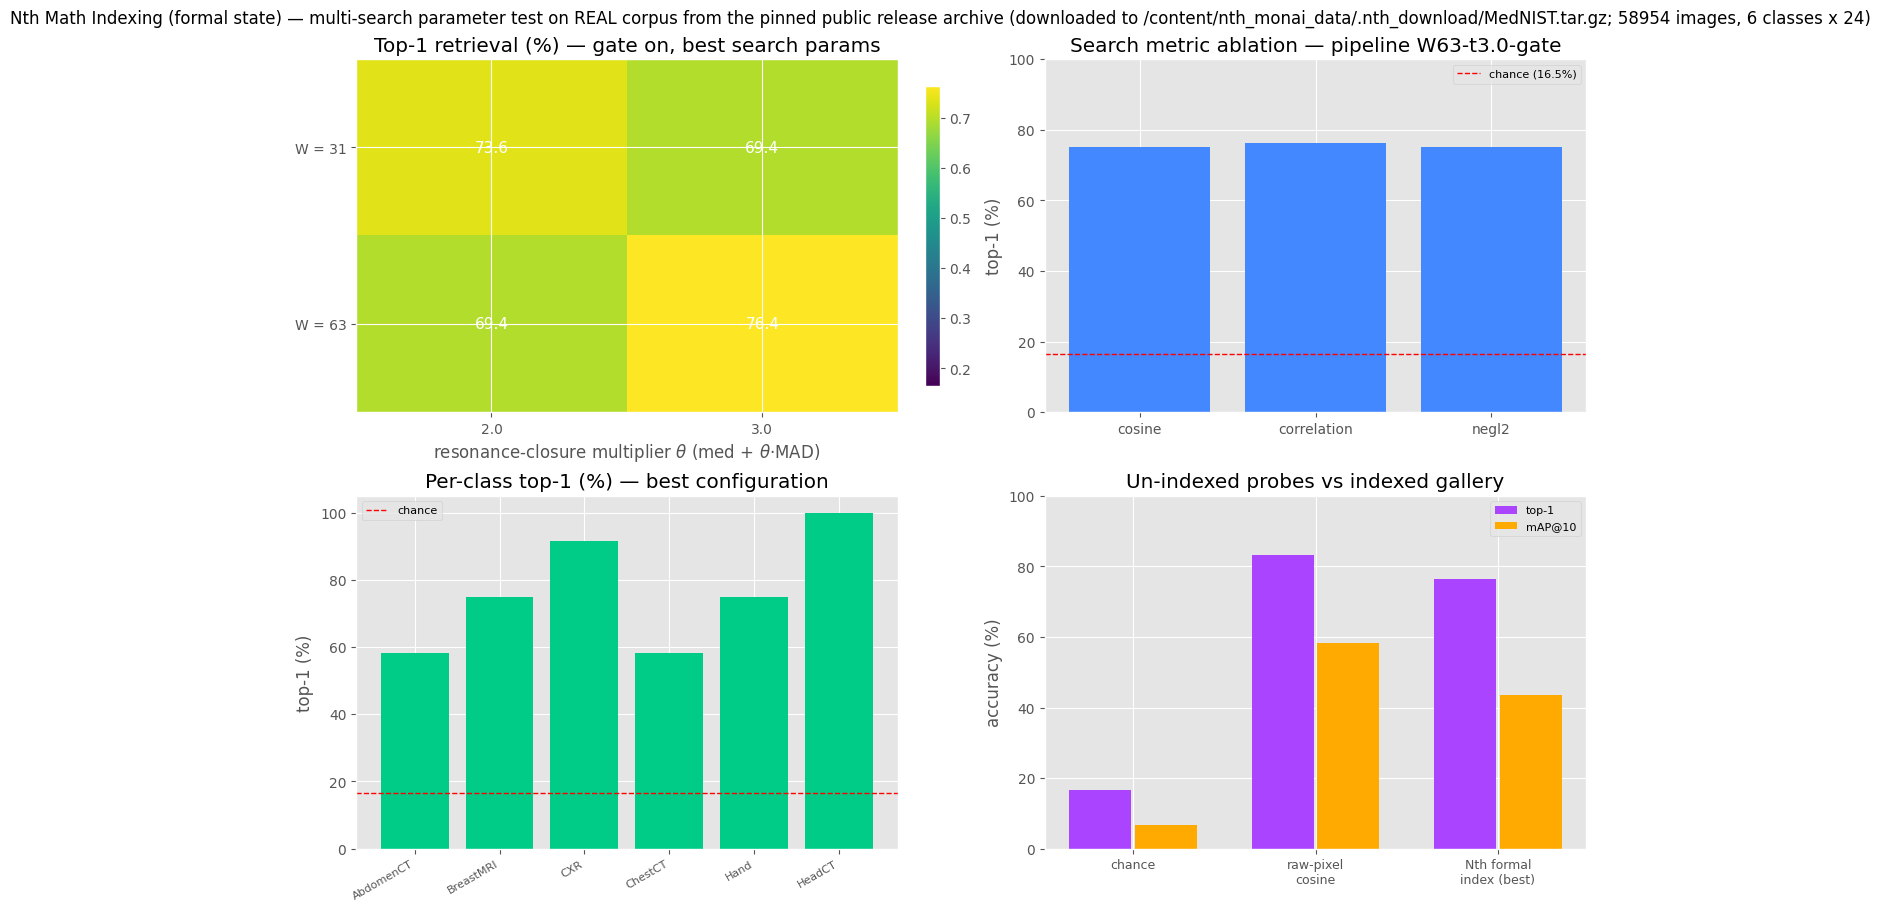


Artifacts saved: nth_monai_multisearch_report.png, nth_monai_multisearch_results.csv

=== Excitation landscapes — the retrieval analog of the excitation graph ===

terrain A — Nth formal index: pipeline W63-t3.0-gate, correlation similarity, spectral block weights (sweep best: top-1 = 0.7639, mAP@10 = 0.4360)
terrain B — raw pixel: cosine on the serpentine signals

queries shown: one probe per class (6 classes); all 72 probes enter the aggregate below



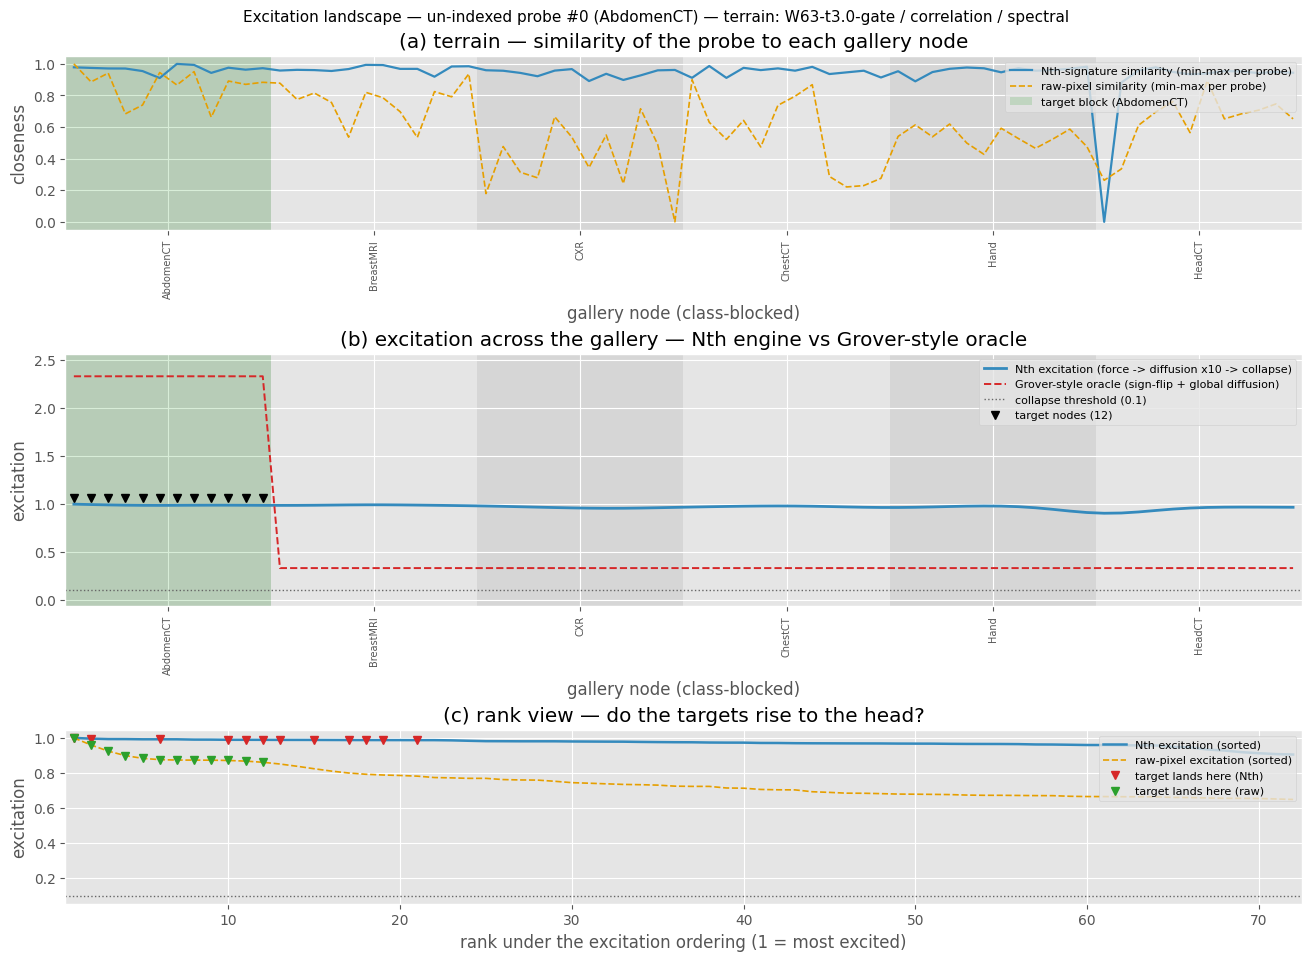

  [OK  ]    AbdomenCT probe #0: 12 targets | mean target rank  12.1 | margin +0.022 | excitation top-1 -> AbdomenCT


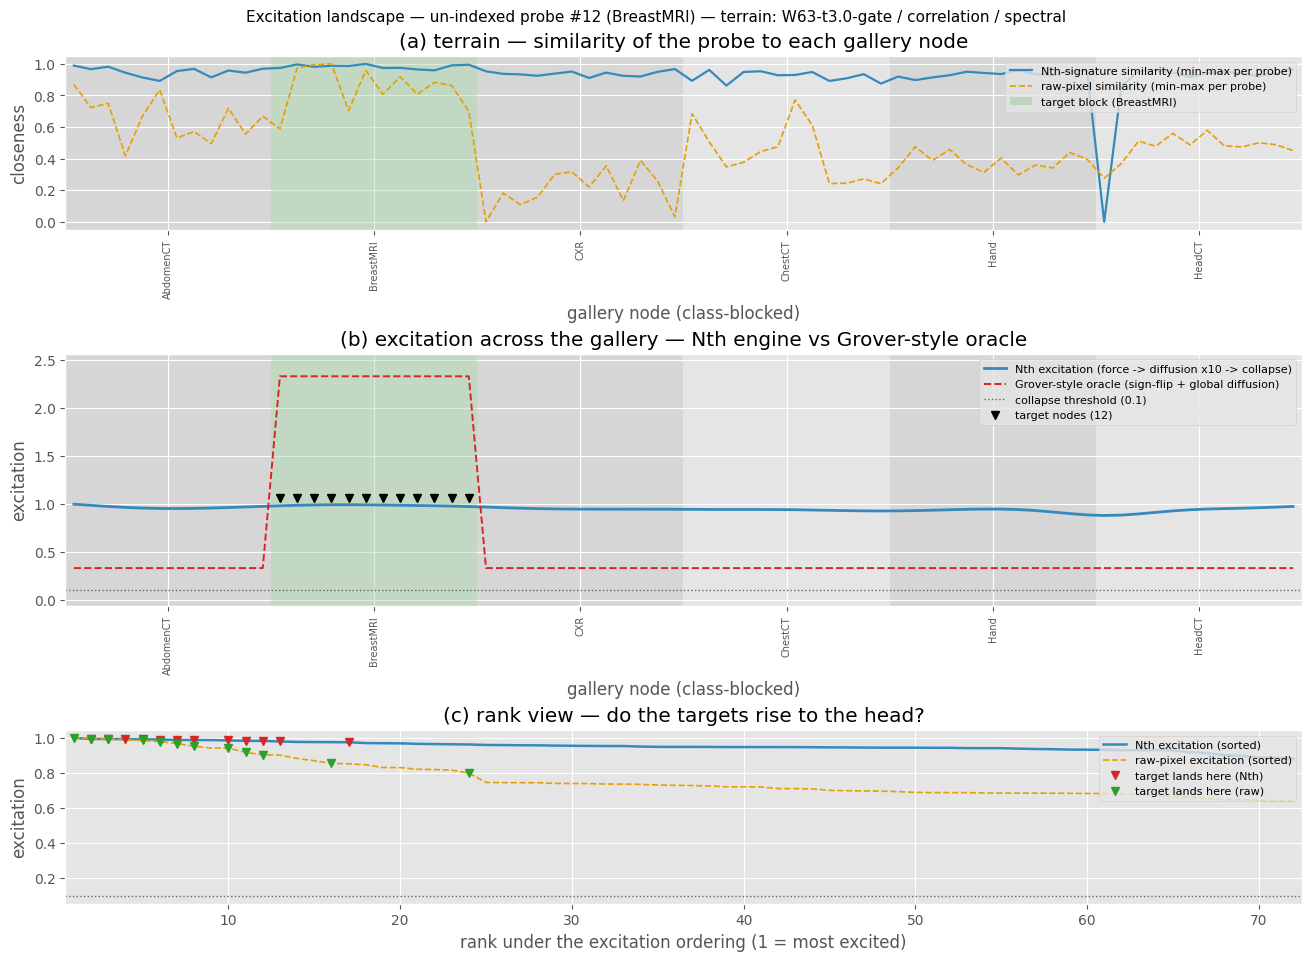

  [MISS]    BreastMRI probe #12: 12 targets | mean target rank   8.2 | margin +0.042 | excitation top-1 -> AbdomenCT


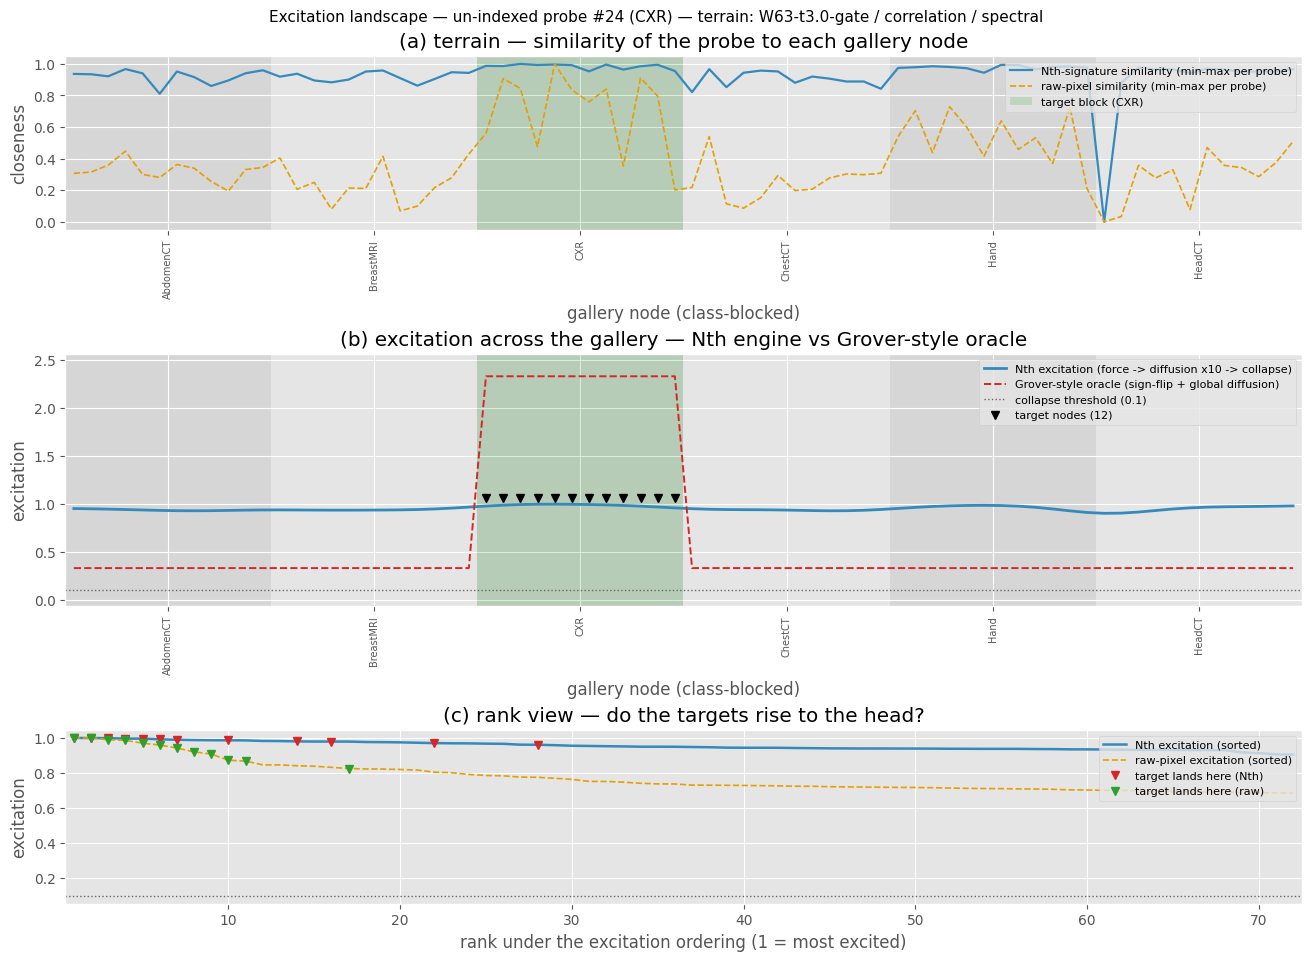

  [OK  ]          CXR probe #24: 12 targets | mean target rank   9.8 | margin +0.039 | excitation top-1 -> CXR


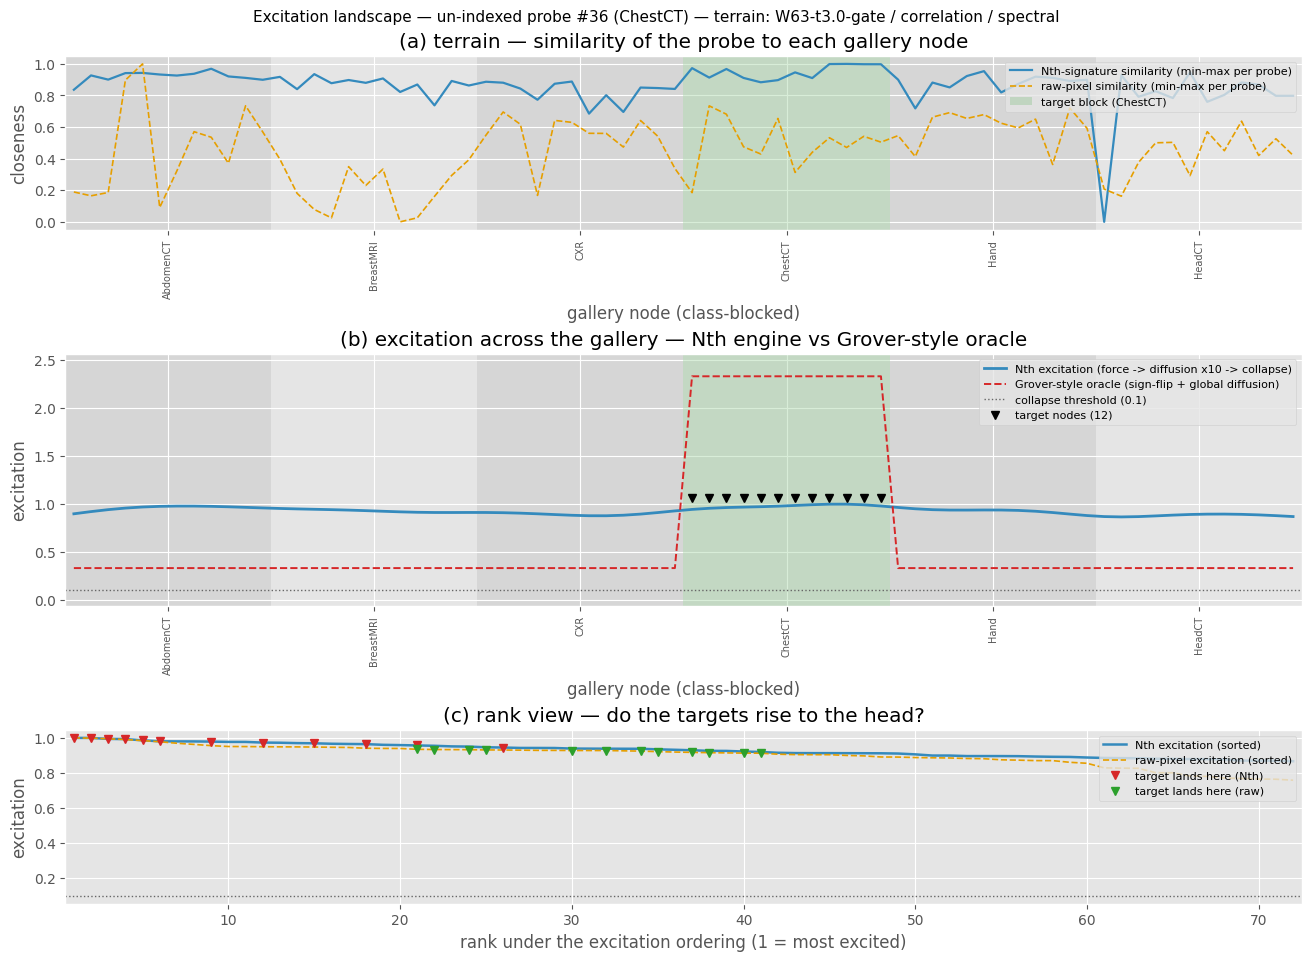

  [OK  ]      ChestCT probe #36: 12 targets | mean target rank  10.2 | margin +0.058 | excitation top-1 -> ChestCT


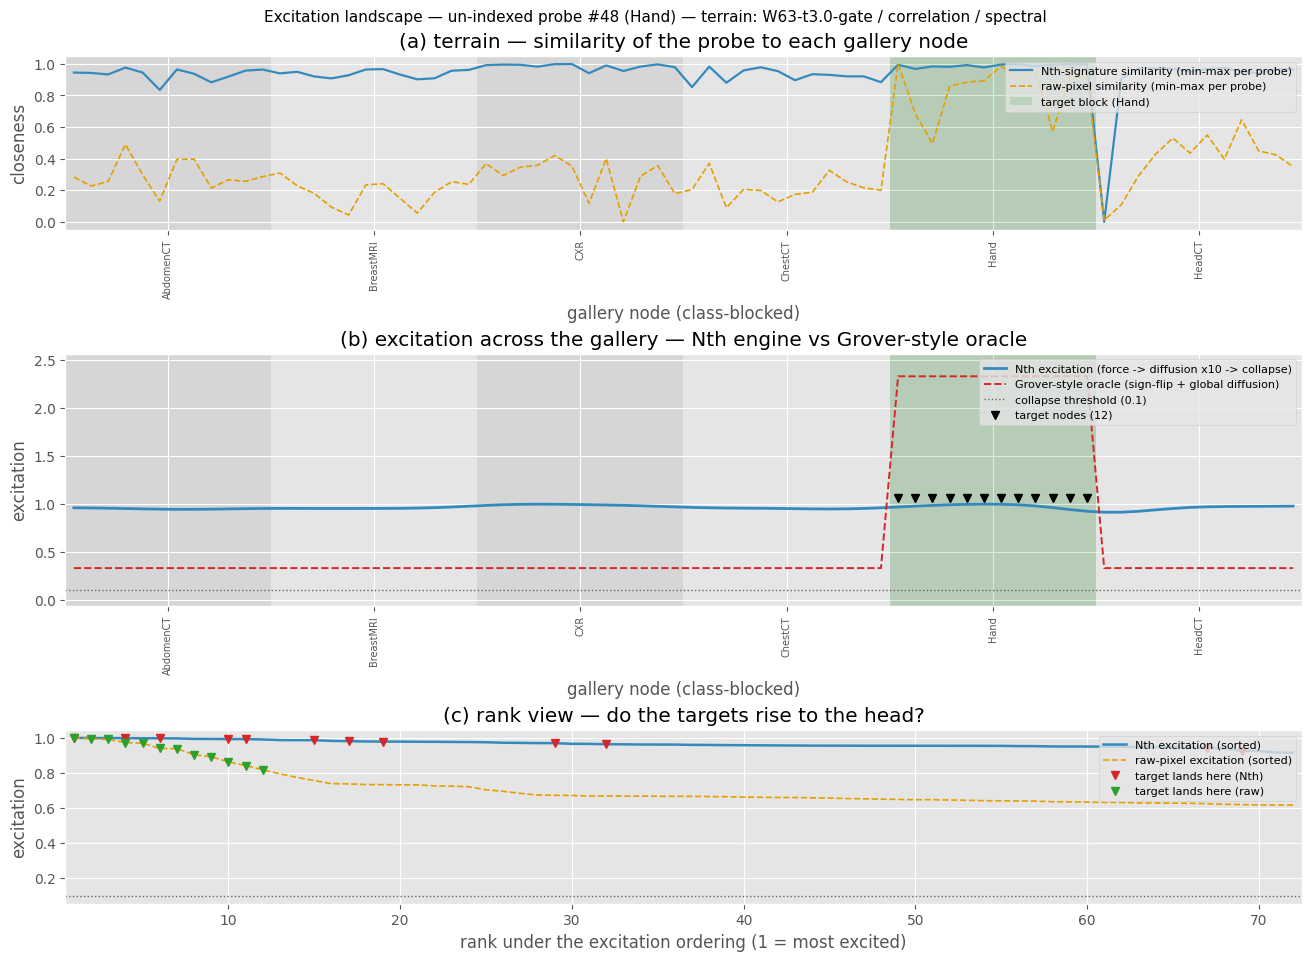

  [OK  ]         Hand probe #48: 12 targets | mean target rank  23.3 | margin +0.015 | excitation top-1 -> Hand


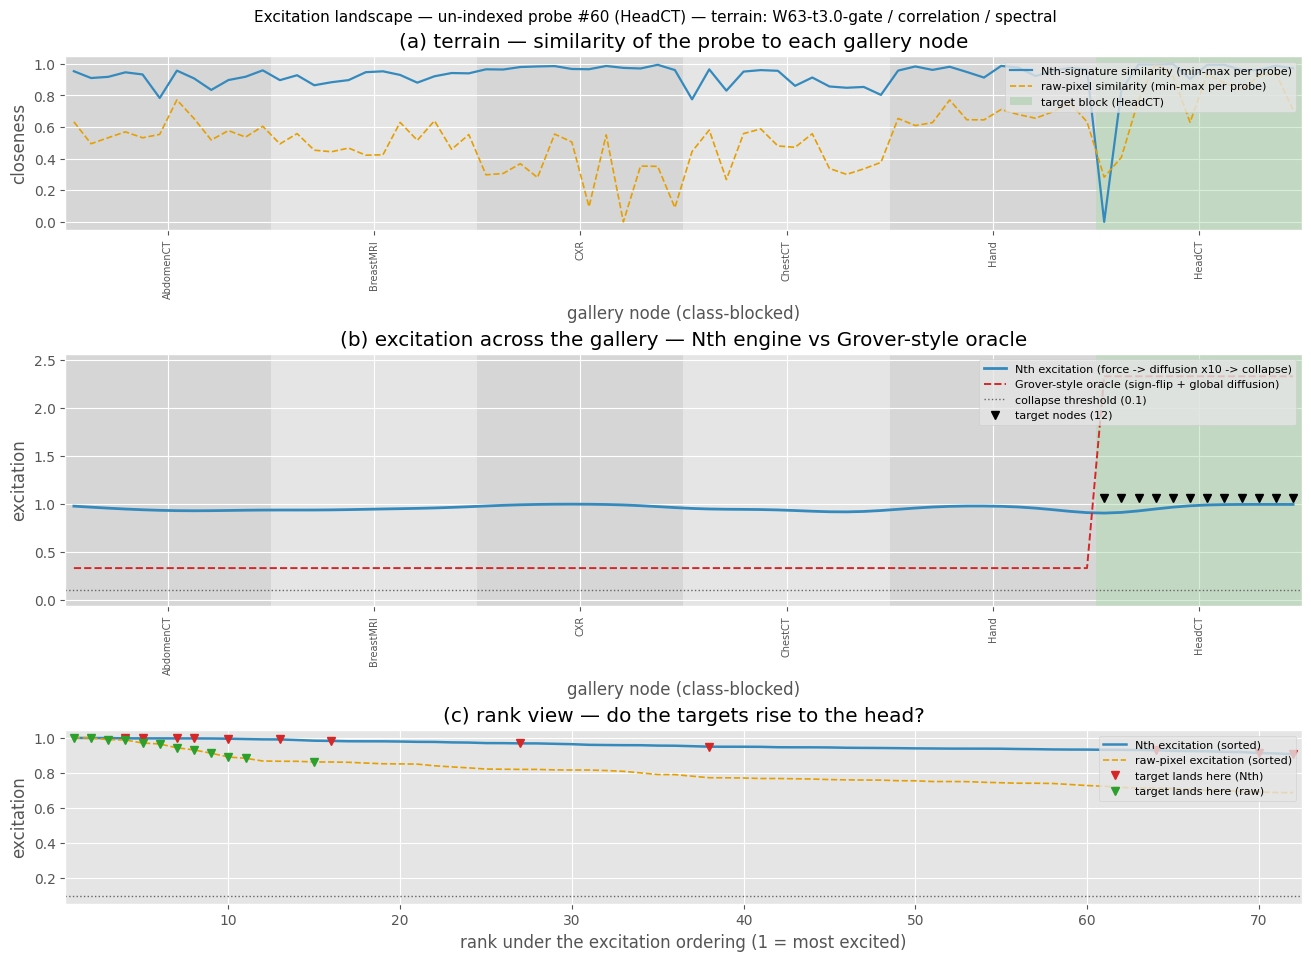

  [MISS]       HeadCT probe #60: 12 targets | mean target rank  27.8 | margin +0.013 | excitation top-1 -> CXR

--- Aggregate over all 72 un-indexed probes ---

Excitation-landscape summary (best sweep configuration vs raw pixel):
         terrain  top1_similarity  top1_excitation  mAP_excitation  mean_target_rank  margin_mean  margin_sd
Nth formal index           0.7639           0.6389          0.4694           19.0417       0.0263     0.0201
       raw pixel           0.8333           0.6944          0.6753           14.1215       0.1375     0.0858


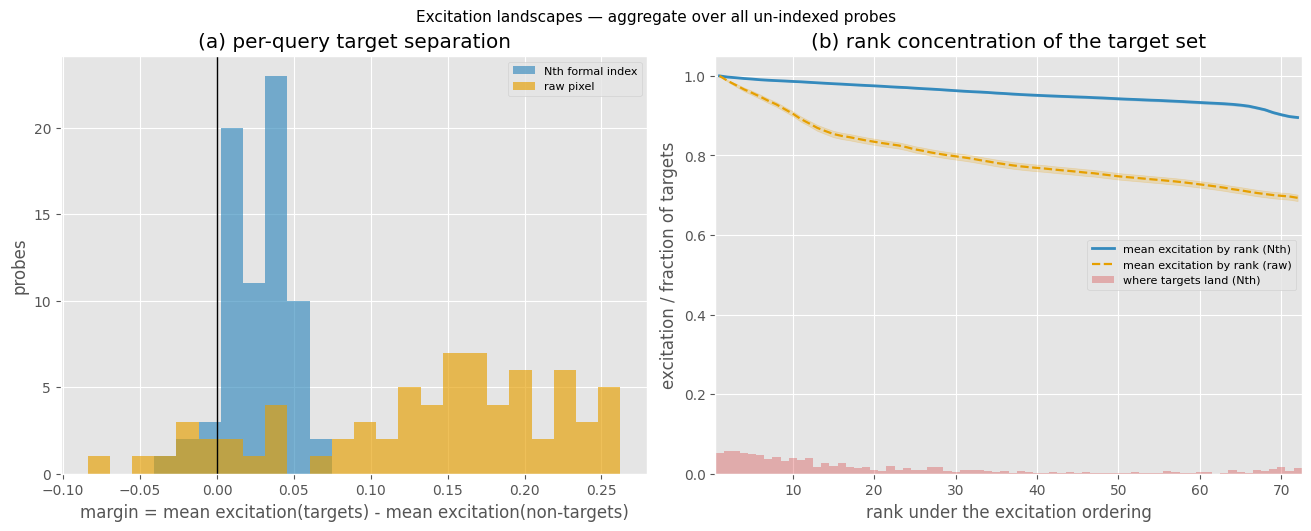


Artifacts saved: nth_excitation_<class>.png (6 queries), nth_excitation_summary.png
Reading the graphs: panel (b) of each query figure is the retrieval analog of the original excitation graph — excitation across the gallery, targets marked, Grover oracle overlaid; panel (c) shows whether the targets rise to the head of the ordering.

Self-contained simulation cell complete — the formal state was acquired, indexed, queried, ablated and visualized with no oracle reference and no prior notebook state at any stage.


In [1]:
# -*- coding: utf-8 -*-
"""
NTH MATHEMATICS INDEXING — SELF-CONTAINED SIMULATION CELL
formal state vs the un-indexed public MONAI MedNIST corpus

ONE CELL. Paste it into a FRESH Colab runtime and run. There is NO
dependency on any prior cell, notebook state, or external module beyond
numpy / matplotlib / pandas / pillow (all preinstalled in Colab; pip
fallbacks included). Everything this cell uses it defines itself:

  SECTION 1  formal operator stack (inlined verbatim from the formal
             compliance build, Cells 1-7 definitions: Selector core,
             V2 asymmetric SDP, delta metric, nth fusion/product 4-tuples,
             Euler triangle + epsilon + pi emergence, dual-symmetrized
             Euler diffusion kernel, n-line deviation encoding,
             prime-carrier basis + windowed NthTransform + inverse,
             Axiom-10 resonance exposure, Nth Jacobian J_Nth +
             determinant fusion + Res() + Delta^h / Delta^-1, closure
             statistics)
  SECTION 2  real-corpus acquisition — NO synthetic fallback exists in
             this cell (explicit requirement: never report synthetic
             diagnostics as dataset measurements). Candidate roots are
             scanned in priority order — DATA_ROOT (default
             /content/nth_monai_data), /content/nth_monai_data,
             ./nth_monai_data, /content/data, ./data, /content, the
             notebook directory — by pruned os.walk over absolute paths
             (sees hidden/staging dirs, unlike glob '**'); any archive
             found on the way (*.tar.gz / .tgz / .tar / .zip, ANY name)
             is extracted (idempotently, never deleted) and re-scanned;
             the pinned public release archive is downloaded only as the
             LAST resort when nothing usable is on disk; if no real
             corpus is reachable the cell raises RuntimeError with the
             full acquisition trace instead of degrading
  SECTION 3  image -> 1-D selector-trajectory adapter
             (block-mean downsample + serpentine scan + z-scaling)
  SECTION 4  oracle-free corpus reference (Axiom-10 central selectors
             bootstrapped from the INDEXED gallery only)
  SECTION 5  parameterized streaming formal indexer (dual-line fusion ->
             resonance gain -> Euler fusion diffusion -> measurement
             channel -> windowed NthTransform -> resonance projection
             gate -> J_Nth determinant fusion + Res() -> reflex channels
             -> theta-parameterized resonance-closure thresholds ->
             hysteresis -> Res() state machine)
  SECTION 6  fixed-length Nth-signature blocks (spectral / Jacobian /
             reflex / trajectory, each L2-normalized)
  SECTION 7  search utilities (similarity matrix, retrieval metrics)
  SECTION 8  formal compliance guard (axiom spot-checks on the dataset
             signals at the configuration's own basis)
  SECTION 9  execution: load the real corpus -> split gallery/probe ->
             compliance guard -> smoke search
  SECTION 10 multi-search parameter test: pipeline grid (W x theta x
             gate) x search grid (metric x block weighting) = 45 rows,
             with empirical-chance and raw-pixel baselines
  SECTION 11 excitation landscapes — the retrieval analog of the
             original excitation graph: the original engine stages
             (symbolic force 1/(1+terrain_resistance), 10x local
             3-neighbour diffusion, max-normalization, 0.1 fusion
             collapse) run VERBATIM over the gallery axis, where gallery
             nodes replace array indices, terrain resistance is the
             normalized dissimilarity of the probe's Nth signature to
             each node, and targets are the same-class gallery items; the
             Grover-style oracle (sign-flip + one global diffusion) is
             overlaid as the upper-bound comparator. Per query: terrain
             panel -> excitation panel (target markers, collapse
             threshold) -> rank view; plus an aggregate figure and a
             summary table over all probes

Artifacts written next to the notebook: nth_monai_multisearch_report.png,
nth_monai_multisearch_results.csv, nth_excitation_<class>.png (one per
shown query), nth_excitation_summary.png.
"""

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 0 — imports                                                     ║
# ╚══════════════════════════════════════════════════════════════════════════╝

import hashlib
import math
import os
import subprocess
import sys
import tarfile
import time
import urllib.request
import warnings
import zipfile
from dataclasses import dataclass, field
from typing import Dict, List, Tuple

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")
plt.style.use("ggplot")


def _pip_install(pkg):
    """Last-resort pip fallback for optional dependencies."""
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           pkg])


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 1 — Formal Operator Stack                                        ║
# ║  (inlined verbatim from the formal compliance build; definitions only —   ║
# ║   no demo signals, no module-global window state)                         ║
# ╚══════════════════════════════════════════════════════════════════════════╝

try:                                    # sympy available in Colab; fallback below
    from sympy import isprime as _sympy_isprime

    def _isprime_int(n: int) -> bool:
        return bool(_sympy_isprime(n))
except Exception:                       # deterministic fallback
    def _isprime_int(n: int) -> bool:
        if n < 2:
            return False
        if n < 4:
            return True
        if n % 2 == 0:
            return False
        f = 3
        while f * f <= n:
            if n % f == 0:
                return False
            f += 2
        return True


ALPHA = 0.5          # phase-deviation weight of the delta metric (Construct 2.0)


@dataclass
class Selector:
    """
    Nth Identity n_|k, p| (Axiom 2.0):
      k : magnitude
      p : phase — +1 = real (1), −1 = unreal (i) for trajectory selectors;
          float phase-magnitudes p > 1 occur on V2 asymmetric identities
          (n_|k, p·i|), per the notebook's corrected V2 representation.
    """
    k: float
    p: float
    tags: Dict = field(default_factory=dict)

    def copy(self) -> "Selector":
        return Selector(self.k, self.p, dict(self.tags))

    def __repr__(self) -> str:
        if self.p == +1:
            ph = "1"
        elif self.p == -1:
            ph = "i"
        else:
            ph = f"{self.p:.2f}i"
        return f"n_|{self.k:.4f},{ph}|"


ZERO_SEL = Selector(0.0, +1)   # n-line ground state


# ── Structural Primality (SDP) ────────────────────────────────────────────

def is_structurally_prime_mag(k: float) -> bool:
    """
    SDP of a raw magnitude (notebook Cell 1 rule): k ≤ 1 is structurally
    prime; otherwise prime iff no a, b > 1 with a + b = k. Used to assign
    selector phases to magnitude-only objects (e.g. Euler-triangle entries).
    """
    n = abs(int(round(k)))
    if n <= 1:
        return True
    return _isprime_int(n)


def sdp_deviation(k: float, p: float) -> int:
    """Deviation of a selector under the V2 asymmetric rule: |k + |p||."""
    return abs(int(round(k + abs(p))))


def is_structurally_prime_sel(k: float, p: float) -> bool:
    """
    SDP(s) — V2 corrected rule: an identity is structurally prime iff its
    Deviation (k + |p|) is prime. Strictly enforces Asymmetric Nth
    Identity principles.
    """
    d = sdp_deviation(k, p)
    if d <= 1:
        return True
    return _isprime_int(d)


def nth_primes_asymmetric(n: int) -> List[Selector]:
    """
    First n asymmetric selectors satisfying the V2 SDP deviation rule
    (scan order identical to the notebook: k = 1..10, then p increments).
    The phase field carries the float phase-magnitude p (asymmetric
    identities are n_|k, p·i|), and the tag records the prime deviation.
    """
    primes: List[Selector] = []
    k_val, p_val = 1.0, 1.0
    while len(primes) < n:
        if is_structurally_prime_sel(k_val, p_val):
            primes.append(Selector(k_val, p_val,
                                   {"deviation": sdp_deviation(k_val, p_val)}))
        k_val += 1.0
        if k_val > 10:
            k_val = 1.0
            p_val += 1.0
    return primes


# ── Delta metric (Construct 2.0) ──────────────────────────────────────────

def delta_metric(ka, pa, kb, pb, alpha: float = ALPHA):
    """
    δ(s₁, s₂) = |k₁ − k₂| + α · Δphase ,  Δphase = 1 if phases differ else 0.
    Vectorized over arrays; also accepts scalars.
    """
    return np.abs(np.asarray(ka) - np.asarray(kb)) + alpha * (np.asarray(pa) != np.asarray(pb))


# ── Nth fusion — Axiom 9.2 / notebook Cell 1 (vectorized) ─────────────────

def nth_fusion_vec(ka, pa, kb, pb):
    """
    n_|A| ⊕ n_|B| → (R, U, C1, C2):
      R  = A + B          real output
      U  = −(A + B)       unreal output (subtraction embedded in addition)
      C1 = A − B          cross-phase 1
      C2 = B − A          cross-phase 2
    Phase of R: real (+1). Phase of U: unreal (−1).
    Phase of C1: +1 if operand phases match, −1 if they differ; C2 opposite.
    """
    ka, kb = np.asarray(ka), np.asarray(kb)
    pa, pb = np.asarray(pa), np.asarray(pb)
    same = (pa == pb)
    one = np.ones_like(ka, dtype=np.int8)
    return {
        "R":  (ka + kb,  one),
        "U":  (-(ka + kb), -one),
        "C1": (ka - kb,  np.where(same, 1, -1).astype(np.int8)),
        "C2": (kb - ka,  np.where(same, -1, 1).astype(np.int8)),
    }


def nth_product_vec(ka, pa, kb, pb):
    """
    n_|A| ⊗ n_|B| → (R, U, C1, C2) — Axiom 9.3. Second-operand phase rule:
    the second operand's phase determines the result phase.
    """
    ka, kb = np.asarray(ka), np.asarray(kb)
    pb = np.asarray(pb)
    mag = ka * kb
    one = np.ones_like(mag, dtype=np.int8)
    return {
        "R":  ( mag,  ( pb * one).astype(np.int8)),
        "U":  ( mag,  (-pb * one).astype(np.int8)),
        "C1": (-mag,  ( pb * one).astype(np.int8)),
        "C2": (-mag,  (-pb * one).astype(np.int8)),
    }


def nth_scalar_project(ka, pa, kb, pb):
    """Single-output scalar projection of the product: k_out = a.k · b.k,
    phase determined by the second operand."""
    return np.asarray(ka) * np.asarray(kb), np.asarray(pb)


# ── Fusion asymmetry — Axiom 0 helper ─────────────────────────────────────

def fusion_asymmetry(k, p):
    """
    Fusion asymmetry FA(τ) of a selector trajectory:
        FA(τ) = 2 · atan2(unreal_mass, real_mass)
    Law of Symbolic Dual Resonance (Axiom 0): FA(F) + FA(−F) = π (mod 2π).
    """
    k = np.asarray(k)
    p = np.asarray(p)
    real_mass = float(np.sum(k[p > 0]))
    unreal_mass = float(np.sum(k[p < 0]))
    if real_mass == 0.0 and unreal_mass == 0.0:
        return 0.0
    return 2.0 * math.atan2(unreal_mass, real_mass)


# ── Nth constants: Euler triangle, ε, π ────────────────────────────────────

EPSILON_NTH = 0.064733   # Nth constant ε — symbolic unreal ratio (App F)


def euler_triangle_row(level: int) -> np.ndarray:
    """
    Euler's Triangle, row `level` (App F). Recursive construction:
        T(n, 0) = 1,   T(n, k) = T(n, k−1) + T(n−1, k),   T(n, n) = T(n, n−1)
    """
    row = [1.0]
    for _ in range(level):
        new = [1.0]
        for kk in range(1, len(row)):
            new.append(new[-1] + row[kk])
        new.append(new[-1])
        row = new
    return np.array(row)


def euler_triangle_selectors(level: int) -> List[Selector]:
    """Row entries reframed as selectors: phase real (+1) if SDP(magnitude),
    unreal (−1) if decomposable."""
    return [Selector(e, +1 if is_structurally_prime_mag(e) else -1)
            for e in euler_triangle_row(level)]


def euler_unreal_share(n_rows: int = 12) -> Tuple[float, np.ndarray]:
    """Empirical unreal-channel mass share of the Euler triangle selectors
    accumulated over rows 1..n_rows (reported alongside ε, App F)."""
    shares = []
    tot_r = tot_u = 0.0
    for lvl in range(1, n_rows + 1):
        for s in euler_triangle_selectors(lvl):
            if s.p > 0:
                tot_r += abs(s.k)
            else:
                tot_u += abs(s.k)
        shares.append(tot_u / (tot_r + tot_u + 1e-18))
    return float(shares[-1]), np.array(shares)


def euler_fusion_weights(n_channels: int, level: int = 2) -> np.ndarray:
    """
    Channel-fusion weights from the formal Euler triangle row. The row is
    centred/padded to the channel count and normalized.
    """
    row = euler_triangle_row(level)
    if len(row) > n_channels:
        start = (len(row) - n_channels) // 2
        row = row[start:start + n_channels]
    elif len(row) < n_channels:
        pad = n_channels - len(row)
        left = pad // 2
        row = np.pad(row, (left, pad - left), mode="edge")
    return row / np.sum(row)


def nth_pi_emergence(n_iter: int = 40) -> Tuple[float, List[Tuple[float, float, float, float]]]:
    """
    π = F(C1, C2, C3, C4, ε) — recursive tuples in spiral-cylinder topology
    (App G–I). The real-channel closure alone recovers the classical Viète
    product identity 2/π = Π x_n; ε weights the unreal-channel share.
    """
    x = math.sqrt(0.5)                          # C1: first chord selector
    P = 2.0 / x                                 # C3: accumulator, first turn
    hist: List[Tuple[float, float, float, float]] = []
    for _ in range(n_iter):
        c2 = math.sqrt(max(0.0, 1.0 - x * x))   # C2 — dual arc (unreal)
        P_prev = P
        x = math.sqrt((1.0 + x) / 2.0)          # C1 — half-angle fusion closure
        P = P / x                               # C3 — unroll one spiral turn
        c4 = abs(P - P_prev)                    # C4 — cross-phase deviation
        hist.append((x, c2, P, c4))
    return P, hist


def euler_diffusion_kernel(radius: int = 2, level: int = 4) -> np.ndarray:
    """
    Fusion-diffusion kernel: the Euler selector row closed under symbolic-dual
    symmetrization (Axiom 0: F ⊕ −F), centred to 2·radius+1 taps.
    """
    row = euler_triangle_row(level)
    target = 2 * radius + 1
    if len(row) < target:
        pad = target - len(row)
        row = np.pad(row, (pad // 2, pad - pad // 2), mode="edge")
    else:
        start = (len(row) - target) // 2
        row = row[start:start + target]
    row = 0.5 * (row + row[::-1])          # dual-resonance symmetrization
    return row / np.sum(row)


# ── n-line deviation encoding (Axioms 1.0–1.4) ─────────────────────────────

def local_n_line(sig: np.ndarray, window: int = 50) -> np.ndarray:
    """
    Local n-line ground state: rolling median (resonance closure of the
    n-line over the trailing window). 0 ≡ n ± x (Axiom 1.1), so the n-line
    anchor is the local median of the signal itself.
    """
    pad = np.concatenate([np.full(window, sig[0]), sig])
    view = np.lib.stride_tricks.sliding_window_view(pad, window + 1)
    return np.median(view, axis=1)


def encode_deviation(sig: np.ndarray, base: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """
    Encode the signal as a selector trajectory via the Fusion Collapse
    Quotient (Axiom 1.2: n − (n + k) = k):
        k_j = |f(t_j) − n_line_j|        magnitude
        p_j = +1 (real) if above the n-line, −1 (unreal) if below
    """
    dev = sig - base
    return np.abs(dev), np.where(dev >= 0, 1, -1).astype(np.int8)


def decode_trajectory(k: np.ndarray, p: np.ndarray) -> np.ndarray:
    """Scalar projection: signed deviation (real → +k, unreal → −k)."""
    return k * p


# ── Prime-carrier basis + windowed NthTransform (Layers 3–5) ──────────────

def make_nth_basis(W):
    """
    Prime-carrier mode basis at width W (Cell-4 convention): real channel
    carried by cos, unreal channel by -sin (exp(-2πjk/W) — the DFT
    imaginary part under restriction). Carriers anchor mode identity via
    the V2 SDP rule and divide out of the normalization.
    """
    K = W // 2 + 1
    th = 2.0 * np.pi * np.outer(np.arange(W), np.arange(K)) / W
    return np.cos(th), -np.sin(th), K


def nth_transform_window(k_win, p_win, cos_basis, sin_basis, W):
    """
    Windowed NthTransform (notebook Cell 4, vectorized — basis passed
    explicitly, no module-global window state):
        R_k = Σ_j  f̃_j · cos(2πjk/W) / W        real channel
        U_k = −Σ_j f̃_j · sin(2πjk/W) / W        unreal channel
        C1 = R − U    real-pointing structural deviation
        C2 = U − R    unreal-pointing resonance duality
    where f̃_j = ±k_j is the signed magnitude (phase-aware accumulation).
    """
    f_signed = k_win * p_win
    R = f_signed @ cos_basis / W
    U = f_signed @ sin_basis / W
    C1 = R - U
    C2 = U - R
    return R, U, C1, C2


def nth_inverse_transform(R, U, W: int, faithful: bool = False):
    """
    Inverse NthTransform (notebook Cell 5). faithful=True reproduces the
    notebook's plain (1/K)Σ synthesis; the default uses the exact
    real-Fourier weights (w = 2 interior, 1 for k = 0 and Nyquist when W
    is even).
    """
    K = len(R)
    jj = np.arange(W)
    if faithful:
        s = np.zeros(W)
        for kk in range(K):
            th = 2.0 * np.pi * jj * kk / W
            s += R[kk] * np.cos(th) - U[kk] * np.sin(th)
        return s / K
    w = np.full(K, 2.0)
    w[0] = 1.0
    if W % 2 == 0:
        w[-1] = 1.0
    th = 2.0 * np.pi * np.outer(jj, np.arange(K)) / W
    return (np.cos(th) * (R * w)) .sum(axis=1) - (np.sin(th) * (U * w)).sum(axis=1)


def resonance_exposure(k, p, mu_k, mu_p, sigma, alpha: float = ALPHA):
    """
    Nth Resonance Weighting (Axiom 10): exposure of selector(s) (k, p) to
    the central selector S_μ = (μ_k, μ_p):
        ρ(k) = exp( −δ(k, μ)² / (2σ²) )
    σ may be a scalar or a per-mode array.
    """
    sigma = np.maximum(np.asarray(sigma, dtype=float), 1e-9)
    d = np.abs(np.asarray(k) - mu_k) + alpha * (np.asarray(p) != mu_p)
    return np.exp(-d ** 2 / (2.0 * sigma ** 2))


def robust_center(x):
    """Median / MAD resonance center of a channel (Axiom-10 μ and σ)."""
    med = float(np.median(x))
    mad = float(np.median(np.abs(np.asarray(x) - med)))
    return med, max(mad, 1e-9)


def delta_norm_trajectory(k, p, alpha: float = ALPHA) -> float:
    """
    Delta norm of a selector trajectory (Parseval analog, notebook Cell 7):
        ||τ||_δ = sqrt( Σ_j δ(S_j, ZERO)² ),  δ(S_j, 0) = k_j + α·[unreal]
    """
    d = np.asarray(k) + alpha * (np.asarray(p) < 0)
    return float(np.sqrt(np.sum(d ** 2)))


def delta_norm_coefficients(R, U, alpha: float = ALPHA) -> float:
    """
    Delta norm of the NthTransform coefficients (Parseval analog):
        ||C||_δ = sqrt( Σ_k [ δ(c_R, 0)² + δ(c_U, 0)² ] / K )
    """
    dR = np.abs(R)
    dU = np.abs(U) + alpha
    return float(np.sqrt(np.sum(dR ** 2 + dU ** 2) / len(R)))


# ── Nth Jacobian J_Nth (phase-resolved geometric implementation) ──────────

def nth_jacobian_window(k_win, p_win, ridge: float = 1e-9):
    """
    Sliding-window Nth Jacobian of the selector-state evolution map
    (Axiom 5.0): local linearization of Δ via δ-regularized least squares.
        J = [[a, b], [c, d]],   k' ≈ a·k + b·p ,  p' ≈ c·k + d·p
    """
    Z = np.column_stack([k_win[:-1], p_win[:-1].astype(float)])
    X = np.column_stack([k_win[1:], p_win[1:].astype(float)])
    G = Z.T @ Z
    G[np.diag_indices_from(G)] += ridge * max(np.trace(G), 1e-12)
    theta = np.linalg.solve(G, Z.T @ X)          # (2, 2)
    a, b = theta[:, 0]
    c, d = theta[:, 1]
    return a, b, c, d


def nth_jacobian_entry_selectors(a, b, c, d):
    """
    Per-entry Nth conversion: each classical Jacobian entry becomes a
    selector n_|entry, p| with phase from its sign and an SDP tag.
    """
    vals = (a, b, c, d)
    k = np.array([abs(v) for v in vals])
    p = np.array([1 if v >= 0 else -1 for v in vals], dtype=np.int8)
    sdp = [is_structurally_prime_sel(k[i], p[i]) for i in range(4)]
    return k, p, sdp


def nth_jacobian_determinant(a, b, c, d):
    """
    Nth determinant fusion for J_Nth = [[a, b], [c, d]]:
        R  = ad − bc    real channel — classical determinant (area scaling)
        U  = −(ad − bc) unreal channel — dual / inverted geometry
        C1 = ad + bc    symmetric coupling — inter-axis co-scaling
        C2 = bc − ad    asymmetric coupling — directional shear
    """
    det = a * d - b * c
    per = a * d + b * c
    R = det
    U = -det
    C1 = per
    C2 = b * c - a * d
    return R, U, C1, C2


def res_jacobian(R, U, C1, C2, eps: float = EPSILON_NTH):
    """
    Resolution operator Res(J_Nth) (Axiom 5.4): the stable state via
    analytical bypass (fixed point of the fusion-loop closure). Mutually
    inverse with Δ⁻¹(J_Nth).
    """
    return 0.5 * (R + C1) + eps * U


def delta_evolve(x_t, x_tm1, h: int = 1):
    """
    Δ^h — forward evolution operator (momentum form on the magnitude
    channel): x_{t+h} = x_t + h·(x_t − x_{t−1}) (Axiom 5.1, App R).
    """
    return x_t + h * (x_t - x_tm1)


def delta_inverse(x_t, x_tm1, h: int = 1):
    """
    Δ⁻¹ — inverse evolution / precursor reconstruction (Axiom 5.5): fully
    reversible; x_{t−h} ≈ x_t − h·(x_t − x_{t−1}).
    """
    return x_t - h * (x_t - x_tm1)


def closure_stats(x):
    """
    Robust center / spread for a resonance-closure threshold (Axiom 10).
    The deviation-stable limit of a sparse, event-gated channel is its
    positive support, so med / MAD are computed there; for dense channels
    the full distribution is used. med + 2·MAD remains the ρ = e⁻²
    closure-level estimator on that support.
    """
    x = np.asarray(x, dtype=float)
    pos = x[x > 1e-12]
    if pos.size < max(20, x.size // 20):
        pos = x
    med = float(np.median(pos))
    mad = float(np.median(np.abs(pos - med))) + 1e-9
    return med, mad


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 2 — Real-Corpus Acquisition (NO synthetic fallback)             ║
# ╚══════════════════════════════════════════════════════════════════════════╝

DATA_ROOT = "/content/nth_monai_data"   # primary corpus location (absolute)
N_PER_CLASS = 24                    # requested images per class (12+12 split)
MIN_PER_CLASS = 6                   # smallest folder that still counts as a class
DS = 2                              # block-mean downsample (64/DS -> 32, T = 1024)
SEED = 2026

# Public MedNIST archive — the same resource monai.apps.MedNISTDataset
# downloads, pinned here so the harness never depends on MONAI's
# version-dependent dataset class (and never RAM-caches 47k images):
MEDNIST_URL = ("https://github.com/Project-MONAI/MONAI-extra-test-data/"
               "releases/download/0.8.1/MedNIST.tar.gz")
MEDNIST_MD5 = "0bc7306e7427e00ad1c5526a6677552d"
MEDNIST_GDRIVE_ID = "1QsnnkvZyJPcbRoV_ArW8SnE1TuoQnPu3"   # mirror, same archive

_IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".gif"}
_ARCHIVE_EXTS = (".tar.gz", ".tgz", ".tar", ".zip")
_PRUNE_DIRS = {"drive", ".git", "__pycache__", ".ipynb_checkpoints",
               "node_modules"}


def _data_root_candidates(primary):
    """Absolute candidate roots, priority-ordered, deduplicated."""
    cands = [primary, "/content/nth_monai_data", "./nth_monai_data",
             "/content/data", "./data", "/content", "./"]
    out = []
    for c in cands:
        a = os.path.abspath(c)
        if a not in out:
            out.append(a)
    return out


def _walk_tree(root):
    """
    Pruned os.walk over ABSOLUTE paths (sees hidden/staging dirs, unlike
    glob '**'). Label = leaf folder name, ANY nesting. Per-class dedupe on
    file basename so a re-extraction at another depth can never leak a
    byte-identical probe into the gallery. Extension histogram and archive
    list (any name) are collected for diagnostics and extraction.
    Returns (pool, n_images, ext_histogram, archives).
    """
    by_class = {}          # label -> {basename: path}
    ext_hist = {}
    archives = []
    n_img = 0
    for dirpath, dirnames, filenames in os.walk(os.path.abspath(root)):
        dirnames[:] = sorted(d for d in dirnames if d not in _PRUNE_DIRS)
        for fn in sorted(filenames):
            ext = os.path.splitext(fn)[1].lower()
            ext_hist[ext] = ext_hist.get(ext, 0) + 1
            path = os.path.join(dirpath, fn)
            if any(fn.lower().endswith(e) for e in _ARCHIVE_EXTS):
                archives.append(path)
            if ext in _IMG_EXTS:
                n_img += 1
                cls = by_class.setdefault(os.path.basename(dirpath), {})
                if fn not in cls or path < cls[fn]:
                    cls[fn] = path
    pool = {lbl: sorted(d.values()) for lbl, d in by_class.items()}
    return pool, n_img, ext_hist, archives


def _pool_from_classes(by_class, n_req):
    """
    Adaptive per-class count: a folder with >= MIN_PER_CLASS images
    qualifies (small curated trees are NOT silently dropped); the pool
    loads min(n_req, smallest qualifying class) per class via a seeded,
    deterministic subsample. Returns (pool, per_class_count).
    """
    qual = {lbl: fl for lbl, fl in by_class.items() if len(fl) >= MIN_PER_CLASS}
    if len(qual) < 2:
        return {}, 0
    take = min(n_req, min(len(fl) for fl in qual.values()))
    rng = np.random.default_rng(SEED + 101)
    pool = {}
    for lbl in sorted(qual):
        fl = sorted(qual[lbl])
        if len(fl) > take:
            idx = np.sort(rng.choice(len(fl), size=take, replace=False))
            fl = [fl[i] for i in idx]
        pool[lbl] = fl
    return pool, take


def _md5_of(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _extract_archive(arc_path):
    """
    Extract ANY recognized archive (any name) into .nth_extract_<stem>/
    next to it. Idempotent (reuses a previous extraction), never deletes
    user files, md5 reported but never enforced against user archives.
    Returns the extraction directory.
    """
    name = os.path.basename(arc_path)
    stem = name
    for e in _ARCHIVE_EXTS:
        if stem.endswith(e):
            stem = stem[:-len(e)]
            break
    dest = os.path.join(os.path.dirname(os.path.abspath(arc_path)),
                        f".nth_extract_{stem}")
    if os.path.isdir(dest) and any(os.scandir(dest)):
        print(f"  [info] reusing previous extraction: {dest}")
        return dest
    os.makedirs(dest, exist_ok=True)
    if name.lower().endswith((".tar.gz", ".tgz", ".tar")):
        with tarfile.open(arc_path, "r:*") as tf:
            members = tf.getmembers()
            try:
                tf.extractall(dest, filter="data")     # Python >= 3.12
            except TypeError:                           # older interpreters
                tf.extractall(dest)
        n = len(members)
    else:
        with zipfile.ZipFile(arc_path) as zf:
            zf.extractall(dest)
            n = len(zf.namelist())
    print(f"  [info] extracted {n} members from {name} -> {dest} "
          f"(md5 {_md5_of(arc_path)})")
    return dest


def _download_archive(url, dest_path):
    """Direct download of the public release archive (redirect-safe,
    atomic .part -> rename)."""
    def _hook(n_blocks, block_size, total):
        if total > 0:
            pct = min(100, int(n_blocks * block_size * 100.0 / total))
            print(f"\r  [info] downloading MedNIST.tar.gz: {pct:3d}%",
                  end="", flush=True)
    print(f"  [info] fetching the public MedNIST archive ({url})")
    part = dest_path + ".part"
    urllib.request.urlretrieve(url, part, reporthook=_hook)
    os.replace(part, dest_path)
    print("\r  [info] download finished.                        ")


def _corpus_not_found_error(trace):
    """The hard failure that replaces the old synthetic fallback."""
    msg = ["NO REAL CORPUS FOUND — this cell has NO synthetic fallback",
           "(explicit requirement: never report synthetic diagnostics as",
           "dataset measurements).",
           "",
           "Acquisition trace:",
           *trace,
           "",
           f"Primary data root: {DATA_ROOT}",
           "To fix, do one of:",
           "  1. place the MONAI MedNIST class folders (AbdomenCT/, BrainMRI/,",
           "     BreastMRI/, ChestXR/, Hand/, HeadCT/ — each with at least",
           f"     {MIN_PER_CLASS} images) under {DATA_ROOT};",
           "  2. or put a MedNIST archive (any name: .tar.gz / .tgz / .tar /",
           "     .zip) anywhere on the candidate roots — it will be found,",
           "     extracted and re-scanned;",
           "  3. or allow network access so the pinned public release archive",
           "     can be downloaded (last resort)."]
    return RuntimeError("\n".join(msg))


def acquire_corpus(primary_root, n_req):
    """
    Acquire the REAL public MONAI MedNIST corpus. Ladder, each step
    re-scanning, transparency printed per candidate:

      1. on-disk scan of every candidate root (DATA_ROOT first, absolute);
         class folders at ANY nesting depth qualify;
      2. any archive found during a scan (any name) is extracted
         (idempotently) and the extraction is re-scanned;
      3. network, LAST resort only (after a prominent warning):
         pinned public release archive, then the gdown mirror.

    monai.apps.MedNISTDataset is deliberately never instantiated (current
    MONAI builds it on CacheDataset — the constructor decodes and
    RAM-caches the whole 47k-image corpus — and its extraction layout is
    version-dependent). Returns (class -> file list, source name).
    """
    trace = []
    arcs_tried = []
    for root in _data_root_candidates(primary_root):
        if not os.path.isdir(root):
            trace.append(f"  - {root}: not a directory")
            continue
        pool, n_img, ext_hist, arcs = _walk_tree(root)
        trace.append(f"  - {root}: {n_img} image files, {len(pool)} leaf "
                     f"folders, {len(arcs)} archive(s), extensions {ext_hist}")
        print(f"  [scan] {root} -> {n_img} images, {len(pool)} leaf classes, "
              f"{len(arcs)} archive(s)")
        sub, take = _pool_from_classes(pool, n_req)
        if sub:
            return sub, (f"REAL corpus on disk at {root} "
                         f"({n_img} images seen, {len(sub)} classes x {take})")
        for arc in arcs:
            if arc in arcs_tried:
                continue
            arcs_tried.append(arc)
            dest = _extract_archive(arc)
            pool2, n2, _, _ = _walk_tree(dest)
            sub, take = _pool_from_classes(pool2, n_req)
            if sub:
                return sub, (f"REAL corpus from archive {os.path.basename(arc)}"
                             f" -> {dest} ({n2} images, "
                             f"{len(sub)} classes x {take})")
            trace.append(f"    archive {os.path.basename(arc)}: extracted to "
                         f"{dest}, still no qualifying pool")

    # prominent warning BEFORE any network use
    print("  [warn] no qualifying class pool found on disk (see the scan "
          "lines above for what each root holds). Network download will "
          "now be attempted as the LAST resort.")

    scratch = os.path.join(os.path.abspath(primary_root), ".nth_download")
    os.makedirs(scratch, exist_ok=True)
    tar_path = os.path.join(scratch, "MedNIST.tar.gz")

    try:                                            # pinned public release
        _download_archive(MEDNIST_URL, tar_path)
        dest = _extract_archive(tar_path)
        pool, n_img, _, _ = _walk_tree(dest)
        sub, take = _pool_from_classes(pool, n_req)
        if sub:
            return sub, (f"REAL corpus from the pinned public release archive "
                         f"(downloaded to {tar_path}; {n_img} images, "
                         f"{len(sub)} classes x {take})")
        trace.append("  - downloaded archive extracted but no qualifying pool")
    except Exception as e_b:
        trace.append(f"  - direct download failed: {e_b}")

    try:                                            # gdown mirror
        try:
            import gdown  # noqa: F401
        except ImportError:
            _pip_install("gdown")
            import gdown
        gdown.download(id=MEDNIST_GDRIVE_ID, output=tar_path, quiet=True)
        dest = _extract_archive(tar_path)
        pool, n_img, _, _ = _walk_tree(dest)
        sub, take = _pool_from_classes(pool, n_req)
        if sub:
            return sub, (f"REAL corpus from the gdown mirror ({n_img} images, "
                         f"{len(sub)} classes x {take})")
        trace.append("  - gdown archive extracted but no qualifying pool")
    except Exception as e_c:
        trace.append(f"  - gdown mirror failed: {e_c}")

    raise _corpus_not_found_error(trace)


def load_dataset(root, n_req):
    """
    Load the real corpus as {class: [float arrays]}. Unreadable images are
    skipped with a warning; the pool is re-balanced to the smallest
    surviving class. NO synthetic branch exists. Returns
    (images, source, n_per_class_loaded).
    """
    pool, source = acquire_corpus(root, n_req)
    try:
        from PIL import Image
    except ImportError:
        _pip_install("pillow")
        from PIL import Image
    images = {}
    for lbl in sorted(pool):
        loaded = []
        for f in pool[lbl]:
            try:
                arr = np.asarray(Image.open(f).convert("L"), dtype=float)
                if arr.size:
                    loaded.append(arr)
                else:
                    print(f"  [warn] empty image skipped: {f}")
            except Exception as e:
                print(f"  [warn] unreadable image skipped: {f} ({e})")
        if loaded:
            images[lbl] = loaded
    if len(images) < 2:
        raise _corpus_not_found_error(
            [f"  - pool had {len(pool)} classes but only {len(images)} "
             f"survived image loading"])
    n_loaded = min(len(v) for v in images.values())
    images = {lbl: v[:n_loaded] for lbl, v in sorted(images.items())}
    return images, source, n_loaded


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 3 — Image -> 1-D Signal Adapter                                  ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def block_mean(img, ds):
    """Non-overlapping block mean (ds x ds) — scale layer of the scan."""
    h, w = img.shape
    h2, w2 = h // ds, w // ds
    return img[:h2 * ds, :w2 * ds].reshape(h2, ds, w2, ds).mean(axis=(1, 3))


def serpentine_scan(img):
    """
    Boustrophedon (row-alternating) raster scan: continuous across row
    boundaries, so no artificial discontinuities enter the selector
    trajectory (only genuine image structure produces phase inversions).
    """
    rows = [row if i % 2 == 0 else row[::-1] for i, row in enumerate(img)]
    return np.concatenate([np.asarray(r, float) for r in rows])


def image_to_signal(img, ds=2):
    """Image -> z-scaled 1-D signal of length T = (64/ds)^2 for the n-line
    deviation encoding. z-scaling makes deviation magnitudes comparable
    across images (exposure amplitudes, not absolute intensities)."""
    if ds > 1:
        img = block_mean(np.asarray(img, float), ds)
    sig = serpentine_scan(img)
    return (sig - sig.mean()) / (sig.std() + 1e-12)


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 4 — Oracle-Free Corpus Reference (Axiom-10 central selectors)   ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def build_corpus_reference(sigs, prm, rng, n_boot=16, per_sig=2, n_meas=2):
    """
    Pipeline-consistent Axiom-10 central selectors estimated from a
    bootstrap of the INDEXED gallery — the formal counterpart of the
    streaming build's event-window reference, with the oracle removed: the
    index's resonance frame is the corpus itself, and un-indexed probes are
    only ever ENCODED by it (never part of it).

    Stage 1 — position-level center: robust center (median / MAD) of the
    pooled raw selector magnitudes, majority phase.
    Stage 2 — pipeline-consistent profile: bootstrap windows pushed through
    the SAME dual-fusion -> resonance-gain -> Euler-diffusion -> measurement
    chain the indexer applies in flight; REF_SCALE is the median window
    resonance scale; the mode-level mu/sigma follow from the noiseless and
    noisy measurement realizations (sigma per mode).
    The corpus central R-pattern is the sign-aligned pooled median: each
    window's coefficient pattern is dual-phase aligned (+/-) to the median
    direction before pooling — the Law of Symbolic Dual Resonance (Axiom 0)
    makes the +/- ambiguity of the resonance projection absorvable.
    """
    W = int(prm["W"]); HALF = W // 2
    cos_b, sin_b, K = make_nth_basis(W)
    kern = euler_diffusion_kernel(radius=prm["radius"], level=4)
    pad = len(kern) // 2

    wins = []
    idx = rng.permutation(len(sigs))[:min(n_boot, len(sigs))]
    for si in idx:
        sig = sigs[si]
        nline = local_n_line(sig, prm["nline_win"])
        k_all, p_all = encode_deviation(sig, nline)
        k_dual = np.roll(k_all, prm["dual_lag"])
        p_dual = np.roll(p_all, prm["dual_lag"])
        for c in rng.integers(HALF, len(sig) - HALF, size=per_sig):
            lo, hi = int(c) - HALF, int(c) + HALF + 1
            wins.append((k_all[lo:hi], p_all[lo:hi],
                         k_dual[lo:hi], p_dual[lo:hi]))

    # Stage 1: position-level center (raw magnitudes of the bootstrap)
    kpool = np.concatenate([w[0] for w in wins])
    ppool = np.concatenate([w[1] for w in wins])
    mu_pos_k, sigma_pos = robust_center(kpool)
    mu_pos_p = 1 if np.sum(ppool > 0) >= np.sum(ppool < 0) else -1

    # Stage 2: pipeline-consistent diffused windows
    signed_list = []
    for kA, pA, kB, pB in wins:
        fus = nth_fusion_vec(kA, pA, kB, pB)
        k_f = 0.5 * fus["R"][0]
        p_f = pA * pB                                   # Axiom 2.1 phase rule
        expo = resonance_exposure(k_f, p_f, mu_pos_k, mu_pos_p, sigma_pos)
        k_g = k_f * (1.0 + prm["gain"] * expo)
        sg = np.convolve(np.pad(k_g * p_f, (pad, pad), mode="edge"),
                         kern, mode="valid")
        signed_list.append(sg)
    ref_scale = float(np.median([np.max(np.abs(s)) for s in signed_list])) + 1e-12

    def _state(sg):
        kn = np.abs(sg) / ref_scale
        kn[kn < 0.05] = 0.0
        pn = np.where(sg >= 0, 1, -1).astype(np.int8)
        return kn, pn

    R_list, U_list = [], []
    for sg in signed_list:
        kn, pn = _state(sg)
        R_w, U_w, _, _ = nth_transform_window(kn, pn, cos_b, sin_b, W)
        R_list.append(R_w); U_list.append(U_w)
    R_arr = np.array(R_list); U_arr = np.array(U_list)

    amp_noisy = []
    for sg in signed_list:
        for _ in range(n_meas):                          # measurement realizations
            kn, pn = _state(sg + 0.10 * rng.standard_normal(W))
            R_m, U_m, _, _ = nth_transform_window(kn, pn, cos_b, sin_b, W)
            amp_noisy.append(np.sqrt(R_m ** 2 + U_m ** 2))
    amp_noisy = np.array(amp_noisy)

    amp_arr = np.sqrt(R_arr ** 2 + U_arr ** 2)
    mu_mode_k = np.median(amp_arr, axis=0)
    sigma_mode = np.maximum(np.median(np.abs(amp_noisy - mu_mode_k[None, :]),
                                      axis=0), 1e-4)
    mu_mode_p = np.where(np.abs(np.median(R_arr, axis=0))
                         >= np.abs(np.median(U_arr, axis=0)), 1, -1).astype(np.int8)

    # Corpus central R-pattern: sign-aligned pooled median (Axiom-0 alignment)
    Rn = R_arr / (np.linalg.norm(R_arr, axis=1, keepdims=True) + 1e-12)
    med_dir = np.median(Rn, axis=0)
    med_dir = med_dir / (np.linalg.norm(med_dir) + 1e-12)
    signs = np.sign(Rn @ med_dir); signs[signs == 0] = 1.0
    ref_R = np.median(R_arr * signs[:, None], axis=0)
    E_ref = float(np.sum(ref_R ** 2)) + 1e-12
    coherence = float(np.linalg.norm(ref_R)
                      / (np.mean(np.linalg.norm(R_arr, axis=1)) + 1e-12))

    return dict(mu_pos_k=mu_pos_k, mu_pos_p=mu_pos_p, sigma_pos=sigma_pos,
                mu_mode_k=mu_mode_k, mu_mode_p=mu_mode_p,
                sigma_mode=sigma_mode, ref_R=ref_R, E_ref=E_ref,
                ref_scale=ref_scale, coherence=coherence, n_boot=len(wins))


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 5 — Parameterized Streaming Formal Indexer                      ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def run_nth_indexer(sig, prm, ref, rng):
    """
    The streaming formal state as a reusable function on any 1-D signal,
    in the resonance frame `ref` (corpus reference). Per window:

      dual-line fusion (Axiom 2.1 phase rule) -> Axiom-10 resonance gain ->
      Euler fusion diffusion -> measurement channel (stochastic selectors)
      -> windowed NthTransform (prime-carrier modes) -> resonance gate
      (projection of the window's real-channel coefficients onto the corpus
      central pattern, normalized to 1 at the center) -> J_Nth determinant
      fusion + Res() -> reflex channels (Delta^2 accel under the delta
      metric, fusion-asymmetry double flips, Delta^h predictive lineage
      divergence) -> theta-parameterized resonance-closure thresholds ->
      hysteretic latch -> Res() state machine.

    `use_gate=False` disables the projection gate (ablation config).
    """
    W = int(prm["W"]); HALF = W // 2
    cos_b, sin_b, K = make_nth_basis(W)
    kern = euler_diffusion_kernel(radius=prm["radius"], level=4)
    pad = len(kern) // 2

    nline = local_n_line(np.asarray(sig, float), prm["nline_win"])
    k_all, p_all = encode_deviation(sig, nline)
    k_dual = np.roll(k_all, prm["dual_lag"])       # temporal dual (wrap at t=0)
    p_dual = np.roll(p_all, prm["dual_lag"])
    Tn = len(sig)

    E_l, JR_l, JU_l, JC1_l, JC2_l, Res_l, Jm_l, gate_l = \
        [], [], [], [], [], [], [], []
    profR = np.zeros(K); profU = np.zeros(K); n_win = 0
    accel_l, curv_l, lineage_l = [], [], []
    prev_m = prev2_m = prev_p = prev_prev_p = prev_dk = None

    for center in range(Tn):
        lo = max(0, center - HALF); hi = lo + W
        if hi > Tn:
            break
        kA, pA = k_all[lo:hi], p_all[lo:hi]
        kB, pB = k_dual[lo:hi], p_dual[lo:hi]

        # dual-line fusion (Axiom 2): R-channel magnitude, phase product
        fus = nth_fusion_vec(kA, pA, kB, pB)
        k_f = 0.5 * fus["R"][0]
        p_f = pA * pB
        # Axiom-10 resonance gain w.r.t. the position-level central selector
        expo_pos = resonance_exposure(k_f, p_f, ref["mu_pos_k"],
                                      ref["mu_pos_p"], ref["sigma_pos"])
        k_g = k_f * (1.0 + prm["gain"] * expo_pos)
        # fusion diffusion (dual-symmetrized Euler selector weights)
        signed = np.convolve(np.pad(k_g * p_f, (pad, pad), mode="edge"),
                             kern, mode="valid")
        # measurement channel (streaming noise schedule)
        noise_level = 0.05 + 0.05 * np.sin(2.0 * np.pi * center / 700.0)
        sg = signed + noise_level * rng.standard_normal(W)
        kn = np.abs(sg) / ref["ref_scale"]
        kn[kn < 0.05] = 0.0
        pn = np.where(sg >= 0, 1, -1).astype(np.int8)

        # windowed NthTransform (prime-carrier modes)
        R_w, U_w, _, _ = nth_transform_window(kn, pn, cos_b, sin_b, W)
        amp = np.sqrt(R_w ** 2 + U_w ** 2)
        mphase = np.where(np.abs(R_w) >= np.abs(U_w), 1, -1)
        expo_mode = resonance_exposure(amp, mphase, ref["mu_mode_k"],
                                       ref["mu_mode_p"], ref["sigma_mode"])
        E = float(np.sum(expo_mode * (np.abs(R_w) + EPSILON_NTH * np.abs(U_w))))
        # resonance projection gate onto the corpus central R-pattern
        R_dot = float(np.sum(R_w * ref["ref_R"]))

        # Nth Jacobian of the evolution map + determinant fusion + Res()
        aJ, bJ, cJ, dJ = nth_jacobian_window(kn, pn)
        JR, JU, JC1, JC2 = nth_jacobian_determinant(aJ, bJ, cJ, dJ)

        E_l.append(E); JR_l.append(JR); JU_l.append(JU); JC1_l.append(JC1)
        JC2_l.append(JC2); Jm_l.append(abs(JR) + abs(JC1) + abs(JC2))
        Res_l.append(res_jacobian(JR, JU, JC1, JC2))
        profR += np.abs(R_w); profU += np.abs(U_w); n_win += 1

        g_res = (max(0.0, min(1.0, R_dot / ref["E_ref"]))
                 if prm["use_gate"] else 1.0)
        gate_l.append(g_res)
        k_r = kn * g_res
        k_r[k_r < 0.05] = 0.0
        p_r = np.where(k_r > 0, pn, 1).astype(np.int8)

        # reflex channel accumulation
        if prev_m is not None:
            dk = k_r - prev_m
            if prev_dk is not None:
                mag_t, ph_t = np.abs(dk), np.sign(dk)
                mag_p, ph_p = np.abs(prev_dk), np.sign(prev_dk)
                accel_l.append(float((np.abs(mag_t - mag_p)
                                      + ALPHA * (ph_t != ph_p)).max()))
            prev_dk = dk
            if prev_p is not None and prev_prev_p is not None:
                f1 = (p_r != prev_p); f2 = (prev_p != prev_prev_p)
                curv_l.append(int(np.sum(f1 != f2)))
            if prev2_m is not None:
                L_hat = delta_evolve(prev_m, prev2_m, prm["pred_h"])
                D_t = np.abs(k_r - L_hat) + ALPHA * (p_r != prev_p)
                lineage_l.append(float(np.sum(D_t)))
            prev2_m = prev_m
        prev_prev_p = prev_p
        prev_p = p_r
        prev_m = k_r

    out = {
        "W": W, "K": K, "n_win": n_win, "T": Tn,
        "k_all": k_all, "p_all": p_all,
        "profR": profR / max(n_win, 1), "profU": profU / max(n_win, 1),
        "E": np.asarray(E_l), "JR": np.asarray(JR_l), "JU": np.asarray(JU_l),
        "JC1": np.asarray(JC1_l), "JC2": np.asarray(JC2_l),
        "Res": np.asarray(Res_l), "J_mass": np.asarray(Jm_l),
        "gate": np.asarray(gate_l),
    }

    # ── reflex layer + Res() state machine (theta-parameterized) ──
    accel_arr = np.asarray(accel_l, float)
    curv_arr = np.asarray(curv_l, float)
    lineage_arr = np.asarray(lineage_l, float)
    L = int(min(accel_arr.size, curv_arr.size, lineage_arr.size))

    if L >= 8:
        med_a, mad_a = closure_stats(accel_arr[:L])
        th_a = med_a + prm["theta_close"] * mad_a
        med_c, mad_c = closure_stats(curv_arr[:L])
        th_c = med_c + prm["theta_close"] * mad_c
        med_l, mad_l = closure_stats(lineage_arr[:L])
        th_l = med_l + prm["theta_close"] * mad_l
        a_norm = np.maximum(0.0, (accel_arr[:L] - med_a) / (th_a - med_a + 1e-9))
        c_norm = np.maximum(0.0, (curv_arr[:L] - med_c) / (th_c - med_c + 1e-9))
        l_norm = np.maximum(0.0, (lineage_arr[:L] - med_l) / (th_l - med_l + 1e-9))
        w_ref = euler_fusion_weights(3)                # [1, 2, 2] / 5
        fusion_scores = w_ref[0] * a_norm + w_ref[1] * c_norm + w_ref[2] * l_norm

        fusion_med, fusion_mad = closure_stats(fusion_scores)
        th_on = fusion_med + prm["theta_close"] * fusion_mad   # rho = e^-2 level
        th_off = fusion_med                                    # dev-stable limit
        fusion_padded = np.pad(fusion_scores, (1, 0), mode="edge")
        pred_scores = delta_evolve(fusion_scores, fusion_padded[:-1], prm["pred_h"])
        pred_med, pred_mad = closure_stats(pred_scores)
        th_pred = pred_med + prm["theta_close"] * pred_mad
        preempt_flags = pred_scores > th_pred

        reflex_fused = np.zeros(L, dtype=bool); active = False
        for i in range(L):
            if not active and (fusion_scores[i] > th_on or preempt_flags[i]):
                active = True
            elif active and fusion_scores[i] < th_off and not preempt_flags[i]:
                active = False
            reflex_fused[i] = active

        state = 0; states = []
        for i in range(L):
            s = fusion_scores[i]; s_pred = pred_scores[i]
            preempt = preempt_flags[i]
            if state == 0:                                   # Idle
                if preempt and s_pred > th_on:
                    state = 4                                # Preempt
                elif s > th_on:
                    state = 1                                # Track
            elif state == 4:                                 # Preempt
                if s > th_on * 1.5:
                    state = 2                                # Engage
                elif s < th_off and not preempt:
                    state = 0
            elif state == 1:                                 # Track
                if preempt and s_pred > th_on * 1.5:
                    state = 4
                elif s > th_on * 1.5:
                    state = 2
                elif s < th_off and not preempt:
                    state = 0
            elif state == 2:                                 # Engage
                if s > th_on * 2.0 or (preempt and s_pred > th_on * 2.0):
                    state = 3                                # Evade
                elif s < th_off and not preempt:
                    state = 1
            elif state == 3:                                 # Evade
                if s < th_off and not preempt:
                    state = 1
            states.append(state)
        out.update(dict(
            L=L, fusion_scores=fusion_scores, pred_scores=pred_scores,
            preempt=preempt_flags, reflex_fused=reflex_fused,
            states=np.asarray(states, int),
            reflex_accel=accel_arr[:L] > th_a,
            reflex_curv=curv_arr[:L] > th_c,
            reflex_lineage=lineage_arr[:L] > th_l,
            th=dict(a=th_a, c=th_c, l=th_l, on=th_on, off=th_off, pred=th_pred),
        ))
    else:
        out.update(dict(L=L, fusion_scores=np.zeros(0),
                        pred_scores=np.zeros(0), preempt=np.zeros(0, bool),
                        reflex_fused=np.zeros(0, bool),
                        states=np.zeros(0, int),
                        reflex_accel=np.zeros(0, bool),
                        reflex_curv=np.zeros(0, bool),
                        reflex_lineage=np.zeros(0, bool), th={}))
    return out


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 6 — Fixed-Length Nth-Signature Blocks                           ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def _resample(x, n):
    x = np.asarray(x, float)
    if x.size == 0:
        return np.zeros(n)
    if x.size == 1:
        return np.full(n, float(x[0]))
    return np.interp(np.linspace(0.0, 1.0, n),
                     np.linspace(0.0, 1.0, x.size), x)


def _l2(v):
    n = float(np.linalg.norm(v))
    return v / n if n > 1e-12 else np.zeros_like(v)


def _safe_mean(x):
    x = np.asarray(x)
    return float(x.mean()) if x.size else 0.0


BLOCKS = ("spec", "jac", "reflex", "traj")


def nth_signature(out, n_bins_f=16, n_bins_t=8):
    """
    Fixed-length index vector of one signal's formal state, in blocks:

      spec   — mean windowed-NthTransform mode-amplitude profiles (|R|, |U|),
               resampled to n_bins_f bins each: the carrier-mode spectrum.
      jac    — J_Nth tuple statistics (mean/std of R, U, C1, C2, Res, mass)
               + the temporal J-mass profile: evolution-map geometry.
      reflex — fused-reflex temporal profile + Res() state occupancy +
               per-channel trigger densities: the reflex state of the stream.
      traj   — whole-trajectory formals: fusion asymmetry, unreal share,
               delta norms and their Parseval analog, mean resonance gate,
               event density, resonance-energy stats.

    Each block is L2-normalized so search-time block weightings act on
    unit-mass components (comparing exposures, not raw scales).
    """
    spec = np.concatenate([_resample(out["profR"], n_bins_f),
                           _resample(out["profU"], n_bins_f)])
    jac_stats = []
    for key in ("JR", "JU", "JC1", "JC2", "Res", "J_mass"):
        jac_stats += [_safe_mean(out[key]),
                      float(np.std(out[key])) if out[key].size else 0.0]
    jac = np.concatenate([np.asarray(jac_stats),
                          _resample(out["J_mass"], n_bins_t)])
    reflex = np.concatenate([
        _resample(out["fusion_scores"], n_bins_t),
        np.array([_safe_mean(out["states"] == s) for s in range(5)]),
        np.array([_safe_mean(out["reflex_accel"]),
                  _safe_mean(out["reflex_curv"]),
                  _safe_mean(out["reflex_lineage"]),
                  _safe_mean(out["preempt"])], float),
    ])
    k_all, p_all = out["k_all"], out["p_all"]
    fa = fusion_asymmetry(k_all, p_all)
    dnt = delta_norm_trajectory(k_all, p_all)
    dnc = delta_norm_coefficients(out["profR"], out["profU"])
    traj = np.array([
        fa / (np.pi / 2.0),
        float(np.mean(p_all < 0)),
        dnt, dnc, dnt / (dnc + 1e-12),
        _safe_mean(out["gate"]),
        _safe_mean(out["reflex_fused"]),
        _safe_mean(out["E"]),
        float(np.std(out["E"])) if out["E"].size else 0.0,
    ], float)
    return {"spec": _l2(spec), "jac": _l2(jac),
            "reflex": _l2(reflex), "traj": _l2(traj)}


def signature_vector(blocks, weights):
    """Search-time weighted fusion of the L2-normalized blocks."""
    v = np.concatenate([float(weights.get(b, 1.0)) * blocks[b] for b in BLOCKS])
    return _l2(v)


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 7 — Search Utilities                                            ║
# ╚══════════════════════════════════════════════════════════════════════════╝

K_MAP = 10          # mAP truncation depth


def _l2_rows(M):
    n = np.linalg.norm(M, axis=1, keepdims=True)
    return M / np.maximum(n, 1e-12)


def sim_matrix(P, G, metric):
    """Probe x gallery similarity under a search metric."""
    if metric == "cosine":
        return _l2_rows(P) @ _l2_rows(G).T
    if metric == "correlation":
        Pc = P - P.mean(axis=1, keepdims=True)
        Gc = G - G.mean(axis=1, keepdims=True)
        return _l2_rows(Pc) @ _l2_rows(Gc).T
    if metric == "negl2":
        d2 = (np.sum(P ** 2, axis=1)[:, None] + np.sum(G ** 2, axis=1)[None, :]
              - 2.0 * P @ G.T)
        return -np.sqrt(np.maximum(d2, 0.0))
    raise ValueError(f"unknown metric: {metric}")


def retrieval_metrics(S, probe_lbls, gallery_lbls, k_map=K_MAP):
    """Top-1 / top-5 / truncated mAP of un-indexed probes vs the index."""
    k_map = min(k_map, S.shape[1])
    order = np.argsort(-S, axis=1)
    top1 = float(np.mean(probe_lbls == gallery_lbls[order[:, 0]]))
    top5 = float(np.mean([probe_lbls[i] in gallery_lbls[order[i, :min(5, S.shape[1])]]
                          for i in range(len(probe_lbls))]))
    aps = []
    for i in range(len(probe_lbls)):
        rel = (gallery_lbls[order[i, :k_map]] == probe_lbls[i]).astype(float)
        n_rel = int(np.sum(gallery_lbls == probe_lbls[i]))
        if rel.sum() > 0 and n_rel > 0:
            prec = np.cumsum(rel) / np.arange(1, k_map + 1)
            aps.append(float(np.sum(prec * rel) / min(n_rel, k_map)))
        else:
            aps.append(0.0)
    return dict(top1=top1, top5=top5, mAP=float(np.mean(aps)))


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 8 — Formal Compliance Guard                                     ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def formal_compliance_guard(sig, prm):
    """Axiom spot-checks at the configuration's own basis and signal."""
    checks = []
    nline = local_n_line(np.asarray(sig, float), prm["nline_win"])
    k_all, p_all = encode_deviation(sig, nline)
    rt = float(np.max(np.abs(decode_trajectory(k_all, p_all) - (sig - nline))))
    checks.append(("n-line encode/decode roundtrip (Fusion Collapse Quotient)",
                   rt == 0.0))

    fa = fusion_asymmetry(k_all, p_all)
    fan = fusion_asymmetry(k_all, -p_all)              # symbolic dual -F
    s0 = ((fa + fan) % (2 * np.pi)) % (2 * np.pi)
    checks.append(("Axiom 0: FA(tau) + FA(-tau) = pi (mod 2*pi)",
                   abs(s0 - np.pi) < 1e-9))

    W = int(prm["W"]); HALF = W // 2; K = W // 2 + 1
    lo = len(sig) // 2 - HALF; hi = lo + W
    f = decode_trajectory(k_all[lo:hi], p_all[lo:hi])
    kd = np.abs(f); pd = np.where(f >= 0, 1, -1).astype(np.int8)
    cosb, sinb, _ = make_nth_basis(W)
    Rg, Ug, _, _ = nth_transform_window(kd, pd, cosb, sinb, W)
    f_hat = nth_inverse_transform(Rg, Ug, W)
    checks.append((f"Inverse NthTransform roundtrip at W = {W}",
                   float(np.max(np.abs(f_hat - f))) < 1e-10))
    fft_ref = np.fft.fft(f) / W
    err = max(float(np.max(np.abs(Rg - fft_ref[:K].real))),
              float(np.max(np.abs(Ug - fft_ref[:K].imag))))
    checks.append((f"DFT recovery under restriction at W = {W}", err < 1e-10))

    x0 = np.array([0.2, 0.5, 1.1]); x1 = np.array([0.4, 0.9, 1.7]); v = x1 - x0
    xh = delta_evolve(x1, x0, prm["pred_h"])
    xb = delta_inverse(x1, x0, prm["pred_h"])
    ok = (np.allclose(delta_inverse(xh, xh - v, prm["pred_h"]), x1)
          and np.allclose(delta_evolve(xb, xb - v, prm["pred_h"]), x1))
    checks.append(("Delta^h / Delta^-1 mutual inverse (velocity-field "
                   "composition)", bool(ok)))
    carriers = nth_primes_asymmetric(K)
    checks.append(("V2 SDP carriers prime at config K",
                   all(is_structurally_prime_sel(c.k, abs(c.p)) for c in carriers)))

    print("Formal compliance guard (dataset signals, config basis):")
    n_ok = 0
    for name, ok in checks:
        n_ok += int(bool(ok))
        print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
    print(f"  guard summary: {n_ok}/{len(checks)} checks PASS")
    return n_ok == len(checks)


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 9 — Execution: Load, Split, Guard, Smoke Search                  ║
# ╚══════════════════════════════════════════════════════════════════════════╝

print("=" * 78)
print("NTH MATHEMATICS INDEXING — SELF-CONTAINED SIMULATION CELL")
print("formal state vs the un-indexed public MONAI MedNIST corpus")
print("=" * 78)
print("This cell is SELF-CONTAINED: it defines the formal operator stack, the")
print("real-corpus acquisition (NO synthetic fallback exists), the multi-search")
print("parameter sweep and the excitation landscapes. Run it in a FRESH runtime")
print("— no prior cells, no shared notebook state are required or used.\n")

# Fixed formal-state parameters (streaming-build defaults, n-line scaled to
# T ~ 1024). The SWEPT parameters live in the Section-10 grid.
COMMON_PRM = dict(
    dual_lag=3,      # temporal dual-line lag
    nline_win=25,    # rolling-median n-line width (50 at T = 2000 -> 25 at 1024)
    gain=0.7,        # SECONDARY_GAIN — Axiom-10 resonance-exposure gain
    pred_h=5,        # PRED_HORIZON — symbolic horizon h of the Delta^h evolution
    radius=2,        # Euler fusion-diffusion kernel radius
)

IMAGES, DATA_SOURCE, N_LOADED = load_dataset(DATA_ROOT, N_PER_CLASS)
CLASSES = sorted(IMAGES.keys())
GALLERY_PER_CLASS = max(2, N_LOADED // 2)   # effective indexed split

GALLERY, PROBE = {}, {}
for _lbl in CLASSES:
    _imgs = IMAGES[_lbl]
    GALLERY[_lbl] = _imgs[:GALLERY_PER_CLASS]
    PROBE[_lbl] = _imgs[GALLERY_PER_CLASS:]

gallery_sigs, gallery_labels = [], []
probe_sigs, probe_labels = [], []
for _lbl in CLASSES:
    gallery_sigs += [image_to_signal(_im, DS) for _im in GALLERY[_lbl]]
    gallery_labels += [_lbl] * len(GALLERY[_lbl])
    probe_sigs += [image_to_signal(_im, DS) for _im in PROBE[_lbl]]
    probe_labels += [_lbl] * len(PROBE[_lbl])
gallery_labels = np.array(gallery_labels)
probe_labels = np.array(probe_labels)

_p_gc = np.unique(gallery_labels, return_counts=True)[1] / len(gallery_labels)
CHANCE_TOP1 = float(np.sum(_p_gc ** 2))

print(f"Dataset source:      {DATA_SOURCE}")
print(f"Classes ({len(CLASSES)}):     {CLASSES}")
print("Per-class pool:      "
      + ", ".join(f"{_c}={len(IMAGES[_c])}" for _c in CLASSES))
print(f"Gallery (to index):  {len(gallery_sigs)} signals "
      f"({GALLERY_PER_CLASS}/class)")
print(f"Probe (un-indexed):  {len(probe_sigs)} signals "
      f"({N_LOADED - GALLERY_PER_CLASS}/class)")
print(f"Signal length T = {len(gallery_sigs[0])} "
      f"(block-mean ds = {DS}, serpentine scan)")
print(f"Chance top-1 (gallery class frequencies): {CHANCE_TOP1:.4f}\n")

_guard_prm = {**COMMON_PRM, "W": 63, "theta_close": 2.0, "use_gate": True}
GUARD_OK = formal_compliance_guard(gallery_sigs[0], _guard_prm)

# ── Smoke search: index the gallery once at the reference config and
#    retrieve the un-indexed probes (the sweep below does the full grid) ──
print("\n--- Smoke search: reference config (W = 63, theta = 2.0, gate on) ---")
SMOKE_PRM = _guard_prm
_t0 = time.time()
_ref_smoke = build_corpus_reference(gallery_sigs, SMOKE_PRM,
                                    np.random.default_rng(SEED + 91))
_blocks_g = [nth_signature(run_nth_indexer(
                 s, SMOKE_PRM, _ref_smoke, np.random.default_rng(10_000 + i)))
             for i, s in enumerate(gallery_sigs)]
_blocks_p = [nth_signature(run_nth_indexer(
                 s, SMOKE_PRM, _ref_smoke, np.random.default_rng(50_000 + i)))
             for i, s in enumerate(probe_sigs)]
print(f"indexed {len(_blocks_g)} gallery + {len(_blocks_p)} probe signals "
      f"in {time.time() - _t0:.1f} s "
      f"(corpus coherence {_ref_smoke['coherence']:.3f})")

_UNI = {"spec": 1.0, "jac": 1.0, "reflex": 1.0, "traj": 1.0}
_Gm = np.stack([signature_vector(b, _UNI) for b in _blocks_g])
_Pm = np.stack([signature_vector(b, _UNI) for b in _blocks_p])
_Sm = sim_matrix(_Pm, _Gm, "cosine")
_mm = retrieval_metrics(_Sm, probe_labels, gallery_labels)
print(f"retrieval (cosine, uniform blocks): top-1 = {_mm['top1']:.4f}, "
      f"top-5 = {_mm['top5']:.4f}, mAP@{K_MAP} = {_mm['mAP']:.4f} "
      f"(chance top-1 = {CHANCE_TOP1:.4f})")

_ordm = np.argsort(-_Sm, axis=1)
print("example queries — one probe per class, top-3 retrieved (class, cosine):")
for _c in CLASSES:
    _qi = int(np.flatnonzero(probe_labels == _c)[0])
    _top3 = " | ".join(f"{gallery_labels[_ordm[_qi, j]]} "
                       f"({_Sm[_qi, _ordm[_qi, j]]:+.3f})" for j in range(3))
    _hit = "OK  " if gallery_labels[_ordm[_qi, 0]] == _c else "MISS"
    print(f"  [{_hit}] {_c:>12s} -> {_top3}")


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 10 — Multi-Search Parameter Test                                 ║
# ║  pipeline grid (W x theta x gate) x search grid (metric x block weights)  ║
# ╚══════════════════════════════════════════════════════════════════════════╝

#   W           window width of the prime-carrier NthTransform basis
#   theta_close resonance-closure multiplier (med + theta*MAD is the level
#               set where exposure rho crosses e^-2 — 2.0 in the formal
#               build; swept here)
#   use_gate    resonance projection gate onto the corpus central pattern
PIPE_GRID = [
    dict(name="W31-t2.0-gate",   W=31, theta_close=2.0, use_gate=True),
    dict(name="W31-t3.0-gate",   W=31, theta_close=3.0, use_gate=True),
    dict(name="W63-t2.0-gate",   W=63, theta_close=2.0, use_gate=True),
    dict(name="W63-t3.0-gate",   W=63, theta_close=3.0, use_gate=True),
    dict(name="W63-t2.0-nogate", W=63, theta_close=2.0, use_gate=False),
]

METRIC_GRID = ["cosine", "correlation", "negl2"]
WEIGHT_GRIDS = {
    "uniform":  {"spec": 1.0, "jac": 1.0, "reflex": 1.0, "traj": 1.0},
    "spectral": {"spec": 3.0, "jac": 1.0, "reflex": 0.5, "traj": 1.0},
    "reflex":   {"spec": 1.0, "jac": 0.5, "reflex": 3.0, "traj": 1.0},
}

# ── Baselines ──────────────────────────────────────────────────────────────

_rng_chance = np.random.default_rng(SEED + 7)
_top1s, _maps = [], []
for _ in range(400):        # empirical chance: random rankings
    _m = retrieval_metrics(_rng_chance.random((len(probe_labels),
                                               len(gallery_labels))),
                           probe_labels, gallery_labels)
    _top1s.append(_m["top1"]); _maps.append(_m["mAP"])
CHANCE_TOP1_MC = float(np.mean(_top1s))
CHANCE_MAP_MC = float(np.mean(_maps))

_Gr = _l2_rows(np.stack(gallery_sigs))       # raw-pixel serpentine baseline
_Pr = _l2_rows(np.stack(probe_sigs))
m_raw = retrieval_metrics(sim_matrix(_Pr, _Gr, "cosine"),
                          probe_labels, gallery_labels)

print("\n=== Multi-search parameter test ===\n")
print(f"Pipeline configs: {len(PIPE_GRID)}   search configs: "
      f"{len(METRIC_GRID)} metrics x {len(WEIGHT_GRIDS)} block weightings "
      f"= {len(METRIC_GRID) * len(WEIGHT_GRIDS)} per pipeline config")
print(f"Retrieval protocol: {len(probe_labels)} un-indexed probes -> "
      f"{len(gallery_labels)} indexed gallery signals (mAP@{K_MAP})")
print(f"Baselines — chance: top1 = {CHANCE_TOP1_MC:.4f}, "
      f"mAP = {CHANCE_MAP_MC:.4f} (empirical, 400 MC)")
print(f"            raw-pixel cosine: top1 = {m_raw['top1']:.4f}, "
      f"mAP = {m_raw['mAP']:.4f}\n")

# ── Sweep ──────────────────────────────────────────────────────────────────

rows = []
sig_store = {}
t_sweep0 = time.time()

for ci, cfg in enumerate(PIPE_GRID):
    prm = {**COMMON_PRM, **cfg}
    t0 = time.time()

    # the resonance frame is estimated from the INDEXED gallery only
    ref = build_corpus_reference(gallery_sigs, prm,
                                 np.random.default_rng(SEED + 91))

    blocks_g, blocks_p = [], []
    ev_dens, nonidle = [], []
    for which, sigs in (("gallery", gallery_sigs), ("probe", probe_sigs)):
        base = 0 if which == "gallery" else 5000
        for i, sig in enumerate(sigs):
            rr = np.random.default_rng(10_000 * (ci + 1) + base + i)
            out = run_nth_indexer(sig, prm, ref, rr)
            blocks = nth_signature(out)
            (blocks_g if which == "gallery" else blocks_p).append(blocks)
            ev_dens.append(_safe_mean(out["reflex_fused"]))
            nonidle.append(_safe_mean(out["states"] > 0))
    t_pipe = time.time() - t0
    sig_store[cfg["name"]] = (blocks_g, blocks_p)

    for metric in METRIC_GRID:
        for wname, wt in WEIGHT_GRIDS.items():
            G = np.stack([signature_vector(b, wt) for b in blocks_g])
            P = np.stack([signature_vector(b, wt) for b in blocks_p])
            m = retrieval_metrics(sim_matrix(P, G, metric),
                                  probe_labels, gallery_labels)
            rows.append(dict(config=cfg["name"], W=prm["W"],
                             theta=prm["theta_close"], gate=prm["use_gate"],
                             metric=metric, weights=wname,
                             top1=m["top1"], top5=m["top5"], mAP=m["mAP"],
                             events=float(np.mean(ev_dens)),
                             nonidle=float(np.mean(nonidle)),
                             coherence=ref["coherence"], t_pipe=t_pipe))

    eta = (len(PIPE_GRID) - ci - 1) * t_pipe
    print(f"[{ci + 1}/{len(PIPE_GRID)}] {cfg['name']:>15s}  "
          f"ref+pipeline {t_pipe:6.1f}s  events/img {np.mean(ev_dens):.3f}  "
          f"non-idle {np.mean(nonidle):.3f}  "
          f"corpus coherence {ref['coherence']:.3f}  (eta ~{eta:.0f}s)")

df = pd.DataFrame(rows).sort_values(
    ["mAP", "top1", "top5"], ascending=False).reset_index(drop=True)

print(f"\nSweep complete in {time.time() - t_sweep0:.1f}s — "
      f"{len(df)} evaluated (pipeline x search) configurations.\n")

_disp = df[["config", "metric", "weights", "top1", "top5", "mAP",
            "events", "t_pipe"]].copy()
for _c in ("top1", "top5", "mAP"):
    _disp[_c] = (_disp[_c] * 100).round(1)
print("Top 12 configurations (accuracy in %):")
print(_disp.head(12).to_string(index=False))

best = df.iloc[0]
print(f"\nBest configuration: pipeline {best['config']} "
      f"(W = {int(best['W'])}, theta = {best['theta']}, "
      f"gate = {bool(best['gate'])})")
print(f"                    search {best['metric']} similarity, "
      f"{best['weights']} block weighting")
print(f"                    top1 = {best['top1']:.4f}, "
      f"top5 = {best['top5']:.4f}, mAP@{K_MAP} = {best['mAP']:.4f}")
_delta = best['top1'] - m_raw['top1']
print(f"Nth formal index vs raw-pixel baseline: "
      f"{'+' if _delta >= 0 else ''}{_delta:.4f} top-1 "
      f"({best['mAP'] - m_raw['mAP']:+.4f} mAP)")

# example retrievals under the best configuration
_bg, _bp = sig_store[best["config"]]
_wt = WEIGHT_GRIDS[best["weights"]]
_Gb = np.stack([signature_vector(b, _wt) for b in _bg])
_Pb = np.stack([signature_vector(b, _wt) for b in _bp])
_Sb = sim_matrix(_Pb, _Gb, best["metric"])
_odb = np.argsort(-_Sb, axis=1)
print("example queries under the best configuration (top-3, class + score):")
for _c in CLASSES[:3]:
    _qi = int(np.flatnonzero(probe_labels == _c)[0])
    _top3 = " | ".join(f"{gallery_labels[_odb[_qi, j]]} "
                       f"({_Sb[_qi, _odb[_qi, j]]:+.3f})" for j in range(3))
    _hit = "OK  " if gallery_labels[_odb[_qi, 0]] == _c else "MISS"
    print(f"  [{_hit}] {_c:>12s} -> {_top3}")

# ── Report figure ──────────────────────────────────────────────────────────

fig, axs = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
fig.suptitle("Nth Math Indexing (formal state) — multi-search parameter test "
             f"on {DATA_SOURCE}", fontsize=12)

# (a) heatmap: top-1 over (W x theta) at the best search params, gate on
sub = df[df["gate"]]
piv = sub.pivot_table(index="W", columns="theta", values="top1",
                      aggfunc="max").sort_index()
im = axs[0, 0].imshow(piv.values, cmap="viridis", aspect="auto",
                      vmin=CHANCE_TOP1_MC, vmax=max(float(piv.values.max()),
                                                     1e-6))
axs[0, 0].set_xticks(range(piv.shape[1]))
axs[0, 0].set_xticklabels([f"{v:.1f}" for v in piv.columns])
axs[0, 0].set_yticks(range(piv.shape[0]))
axs[0, 0].set_yticklabels([f"W = {int(v)}" for v in piv.index])
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        axs[0, 0].text(j, i, f"{piv.values[i, j] * 100:.1f}",
                       ha="center", va="center", color="white", fontsize=11)
axs[0, 0].set_title("Top-1 retrieval (%) — gate on, best search params")
axs[0, 0].set_xlabel(r"resonance-closure multiplier $\theta$ (med + $\theta$·MAD)")
fig.colorbar(im, ax=axs[0, 0], shrink=0.85)

# (b) best pipeline config: top-1 by search metric
sub2 = (df[df["config"] == best["config"]].groupby("metric")["top1"].max()
        .reindex(METRIC_GRID))
axs[0, 1].bar(range(len(sub2)), np.asarray(sub2.values) * 100, color="#4488ff")
axs[0, 1].axhline(CHANCE_TOP1_MC * 100, color="red", ls="--", lw=1,
                  label=f"chance ({CHANCE_TOP1_MC * 100:.1f}%)")
axs[0, 1].set_xticks(range(len(sub2)))
axs[0, 1].set_xticklabels(sub2.index)
axs[0, 1].set_title(f"Search metric ablation — pipeline {best['config']}")
axs[0, 1].set_ylabel("top-1 (%)")
axs[0, 1].set_ylim(0, 100)
axs[0, 1].legend(fontsize=8)

# (c) per-class top-1 of the best configuration
_bg, _bp = sig_store[best["config"]]
_wt = WEIGHT_GRIDS[best["weights"]]
_G = np.stack([signature_vector(b, _wt) for b in _bg])
_P = np.stack([signature_vector(b, _wt) for b in _bp])
_S = sim_matrix(_P, _G, best["metric"])
_ord = np.argsort(-_S, axis=1)
_correct = gallery_labels[_ord[:, 0]] == probe_labels
_cls_acc = [float(np.mean(_correct[probe_labels == c])) for c in CLASSES]
axs[1, 0].bar(range(len(CLASSES)), np.array(_cls_acc) * 100, color="#00cc88")
axs[1, 0].axhline(CHANCE_TOP1_MC * 100, color="red", ls="--", lw=1,
                  label="chance")
axs[1, 0].set_xticks(range(len(CLASSES)))
axs[1, 0].set_xticklabels(list(CLASSES), rotation=30, ha="right", fontsize=8)
axs[1, 0].set_title(f"Per-class top-1 (%) — best configuration")
axs[1, 0].set_ylabel("top-1 (%)")
axs[1, 0].legend(fontsize=8)

# (d) baseline comparison: chance / raw-pixel / best Nth formal index
_labels = ["chance", "raw-pixel\ncosine", "Nth formal\nindex (best)"]
_top1_bar = [CHANCE_TOP1_MC, m_raw["top1"], best["top1"]]
_map_bar = [CHANCE_MAP_MC, m_raw["mAP"], best["mAP"]]
_x = np.arange(3)
axs[1, 1].bar(_x - 0.18, np.array(_top1_bar) * 100, 0.34, label="top-1",
              color="#aa44ff")
axs[1, 1].bar(_x + 0.18, np.array(_map_bar) * 100, 0.34,
              label=f"mAP@{K_MAP}", color="#ffaa00")
axs[1, 1].set_xticks(_x)
axs[1, 1].set_xticklabels(_labels, fontsize=9)
axs[1, 1].set_title("Un-indexed probes vs indexed gallery")
axs[1, 1].set_ylabel("accuracy (%)")
axs[1, 1].set_ylim(0, 100)
axs[1, 1].legend(fontsize=8)

fig.savefig("nth_monai_multisearch_report.png", dpi=150)
plt.show()

df.to_csv("nth_monai_multisearch_results.csv", index=False)
print(f"\nArtifacts saved: nth_monai_multisearch_report.png, "
      f"nth_monai_multisearch_results.csv")


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 11 — Excitation Landscapes                                       ║
# ║  the retrieval analog of the original excitation graph                    ║
# ╚══════════════════════════════════════════════════════════════════════════╝

# The Section-10 report aggregates accuracies (heatmaps, bars) — it never
# shows the search itself. This section draws what the original
# demonstration drew: the excitation profile across the searched array with
# the targets visible in it. The mapping from the original 1000-node demo:
#
#   original demo                        retrieval (this section)
#   ──────────────────────────────       ────────────────────────────────────
#   array index i, 0..999                gallery node i, 0..N-1 (class-blocked)
#   terrain_resistance[i] ~ U(0, 1)      1 - min-max similarity of the probe
#                                         signature to gallery node i
#   symbolic force 1/(1+R),              identical stages, verbatim
#   10x local 3-neighbour diffusion,
#   max-normalization, 0.1 collapse
#   targets = random indices             targets = same-class gallery items
#   Grover oracle (sign-flip+diffusion)  identical, drawn as the upper-bound
#                                         comparator (it uses ground truth)
#
# The gallery is stored class-blocked (all of class 1, then class 2, ...), so
# the local 3-neighbour diffusion acts within class blocks exactly as the
# original diffusion acted on a locally-correlated array. Note — as in the
# original demo — resistance in [0, 1] keeps the symbolic force >= 0.5, so
# the 0.1 fusion collapse is a floor, not a selector; raise EXC_COLLAPSE
# (e.g. 0.75) to use it as a class-block selector.

# ── Knobs (engine constants keep the original demo's values) ───────────────
EXC_N_ITER = 10          # local 3-neighbour diffusion iterations (original: 10)
EXC_COLLAPSE = 0.1       # fusion-collapse threshold (original: 0.1)
EXC_CLASSES_SHOW = None  # None -> one probe per class; or ["ChestXR", "Hand"]
if isinstance(EXC_CLASSES_SHOW, str):
    EXC_CLASSES_SHOW = [EXC_CLASSES_SHOW]

print("\n=== Excitation landscapes — the retrieval analog of the "
      "excitation graph ===\n")

# ── Terrains: similarity of every un-indexed probe to every gallery node ───
_best13 = df.iloc[0]
_bg13, _bp13 = sig_store[_best13["config"]]
_wt13 = WEIGHT_GRIDS[_best13["weights"]]
_G13 = np.stack([signature_vector(_b, _wt13) for _b in _bg13])
_P13 = np.stack([signature_vector(_b, _wt13) for _b in _bp13])
S_NTH = sim_matrix(_P13, _G13, _best13["metric"])    # formal-index terrain
S_RAW = sim_matrix(_l2_rows(np.stack(probe_sigs)),   # raw-pixel terrain
                   _l2_rows(np.stack(gallery_sigs)), "cosine")
N_GAL = S_NTH.shape[1]

print(f"terrain A — Nth formal index: pipeline {_best13['config']}, "
      f"{_best13['metric']} similarity, {_best13['weights']} block weights "
      f"(sweep best: top-1 = {_best13['top1']:.4f}, "
      f"mAP@{K_MAP} = {_best13['mAP']:.4f})")
print("terrain B — raw pixel: cosine on the serpentine signals\n")


# ── The original Nth-engine stages, verbatim, over the gallery axis ────────
def nth_excitation_over_gallery(sim_row, n_iter=EXC_N_ITER,
                                collapse=EXC_COLLAPSE):
    """
    Original stages on one probe's similarity row over the gallery:
    terrain resistance = normalized dissimilarity -> symbolic force
    1/(1+R) -> n_iter local 3-neighbour diffusions -> max-normalization ->
    fusion collapse below `collapse`. Returns (terrain, excitation).
    """
    sim = np.asarray(sim_row, float)
    terrain = (sim - sim.min()) / (sim.max() - sim.min() + 1e-12)
    terrain_resistance = 1.0 - terrain
    excitation_nth = np.ones_like(terrain_resistance)
    symbolic_force = 1.0 / (1.0 + terrain_resistance)
    excitation_nth *= symbolic_force
    for _ in range(n_iter):
        excitation_nth[1:-1] = (excitation_nth[:-2] + excitation_nth[1:-1]
                                + excitation_nth[2:]) / 3
    excitation_nth /= np.max(excitation_nth)
    excitation_nth[excitation_nth < collapse] = 0
    return terrain, excitation_nth


def grover_excitation_over_gallery(target_mask):
    """
    Grover-style oracle on the gallery axis — the original demo's comparator:
    sign-flip the targets, then one global diffusion 2*mean - x. Uses ground
    truth (upper bound); the retriever itself never sees labels.
    """
    excitation_grover = np.ones(len(target_mask))
    excitation_grover[np.asarray(target_mask, bool)] *= -1
    excitation_grover = 2 * np.mean(excitation_grover) - excitation_grover
    return excitation_grover


def _rank_of(excitation):
    order = np.argsort(-np.asarray(excitation), kind="stable")
    ranks = np.empty(len(order), int)
    ranks[order] = np.arange(1, len(order) + 1)
    return ranks


def _safe_cls(c):
    return "".join(ch if ch.isalnum() else "_" for ch in str(c))


# ── Class-blocked gallery-axis decoration ──────────────────────────────────
_cls_n = np.array([int(np.sum(gallery_labels == c)) for c in CLASSES])
_blk = np.concatenate([[0], np.cumsum(_cls_n)]).astype(float)
_centers = (_blk[:-1] + _blk[1:]) / 2 - 0.5


def _class_axis(ax):
    for k in range(len(CLASSES)):
        if k % 2 == 0:
            ax.axvspan(_blk[k] - 0.5, _blk[k + 1] - 0.5, color="#555555",
                       alpha=0.10, lw=0, zorder=0)
    ax.set_xticks(_centers)
    ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
    ax.set_xlim(-0.5, N_GAL - 0.5)
    ax.set_xlabel("gallery node (class-blocked)")


# ── Per-query excitation figure ────────────────────────────────────────────
def excitation_query_figure(qi):
    """
    The excitation graph for one un-indexed probe:
      (a) terrain   — similarity of the probe to each gallery node
      (b) excitation — the original engine stages over the gallery axis,
                       Nth vs the Grover-style oracle, targets marked
      (c) rank view — where the search places the targets
    """
    cls = probe_labels[qi]
    tgt = gallery_labels == cls
    ti = np.flatnonzero(tgt)
    k = int(np.flatnonzero(np.asarray(CLASSES) == cls)[0])
    x = np.arange(N_GAL)

    terrain_n, exc_n = nth_excitation_over_gallery(S_NTH[qi])
    terrain_r, exc_r = nth_excitation_over_gallery(S_RAW[qi])
    exc_g = grover_excitation_over_gallery(tgt)

    order_n = np.argsort(-exc_n, kind="stable")
    order_r = np.argsort(-exc_r, kind="stable")
    srt_n, srt_r = exc_n[order_n], exc_r[order_r]
    rank_n, rank_r = _rank_of(exc_n), _rank_of(exc_r)
    mtr = float(rank_n[tgt].mean())
    margin = float(exc_n[tgt].mean() - exc_n[~tgt].mean())
    top_cls = gallery_labels[int(order_n[0])]

    fig, (axT, axE, axR) = plt.subplots(
        3, 1, figsize=(13, 9.5), constrained_layout=True,
        gridspec_kw=dict(height_ratios=[1.0, 1.45, 1.0]))
    fig.suptitle(f"Excitation landscape — un-indexed probe #{qi} ({cls}) — "
                 f"terrain: {_best13['config']} / {_best13['metric']} / "
                 f"{_best13['weights']}", fontsize=11)

    # (a) terrain: what the engine is given
    axT.plot(x, terrain_n, color="#348ABD", lw=1.6,
             label="Nth-signature similarity (min-max per probe)")
    axT.plot(x, terrain_r, color="#E69F00", lw=1.2, ls="--",
             label="raw-pixel similarity (min-max per probe)")
    axT.axvspan(_blk[k] - 0.5, _blk[k + 1] - 0.5, color="#2ca02c",
                alpha=0.18, lw=0, label=f"target block ({cls})")
    _class_axis(axT)
    axT.set_ylabel("closeness")
    axT.set_title("(a) terrain — similarity of the probe to each gallery node")
    axT.legend(fontsize=8, loc="upper right")

    # (b) THE excitation graph: original stages over the gallery axis
    up = max(1.14, float(exc_g.max()) * 1.10)
    axE.plot(x, exc_n, color="#348ABD", lw=2.0,
             label="Nth excitation (force -> diffusion x10 -> collapse)")
    axE.plot(x, exc_g, color="#d62728", lw=1.4, ls="--",
             label="Grover-style oracle (sign-flip + global diffusion)")
    axE.axhline(EXC_COLLAPSE, color="#666666", ls=":", lw=1,
                label=f"collapse threshold ({EXC_COLLAPSE:g})")
    axE.plot(ti, np.full(len(ti), 1.06), "v", color="k", ms=6,
             label=f"target nodes ({len(ti)})")
    axE.axvspan(_blk[k] - 0.5, _blk[k + 1] - 0.5, color="#2ca02c",
                alpha=0.18, lw=0)
    _class_axis(axE)
    axE.set_ylim(-0.06, up)
    axE.set_ylabel("excitation")
    axE.set_title("(b) excitation across the gallery — Nth engine vs "
                  "Grover-style oracle")
    axE.legend(fontsize=8, loc="upper right")

    # (c) rank view: where the search places the targets
    r = np.arange(1, N_GAL + 1)
    axR.plot(r, srt_n, color="#348ABD", lw=1.8,
             label="Nth excitation (sorted)")
    axR.plot(r, srt_r, color="#E69F00", lw=1.2, ls="--",
             label="raw-pixel excitation (sorted)")
    rt_n, rt_r = rank_n[tgt], rank_r[tgt]
    axR.plot(rt_n, srt_n[rt_n - 1], "v", color="#d62728", ms=6,
             label="target lands here (Nth)")
    axR.plot(rt_r, srt_r[rt_r - 1], "v", color="#2ca02c", ms=6,
             label="target lands here (raw)")
    axR.axhline(EXC_COLLAPSE, color="#666666", ls=":", lw=1)
    axR.set_xlim(0.5, N_GAL + 0.5)
    axR.set_xlabel("rank under the excitation ordering (1 = most excited)")
    axR.set_ylabel("excitation")
    axR.set_title("(c) rank view — do the targets rise to the head?")
    axR.legend(fontsize=8, loc="upper right")

    fn = f"nth_excitation_{_safe_cls(cls)}.png"
    fig.savefig(fn, dpi=150)
    plt.show()
    hit = "OK  " if top_cls == cls else "MISS"
    print(f"  [{hit}] {cls:>12s} probe #{qi}: {len(ti)} targets | "
          f"mean target rank {mtr:5.1f} | margin {margin:+.3f} | "
          f"excitation top-1 -> {top_cls}")
    return dict(cls=cls, mean_target_rank=mtr, margin=margin)


_show13 = (list(EXC_CLASSES_SHOW) if EXC_CLASSES_SHOW is not None
           else list(CLASSES))
_show13 = [c for c in _show13 if c in CLASSES] or list(CLASSES)
print(f"queries shown: one probe per class ({len(_show13)} classes); "
      f"all {len(probe_labels)} probes enter the aggregate below\n")
for _c in _show13:
    _qi = int(np.flatnonzero(probe_labels == _c)[0])
    excitation_query_figure(_qi)

# ── Aggregate over all un-indexed probes ───────────────────────────────────
print(f"\n--- Aggregate over all {len(probe_labels)} un-indexed probes ---")
n_pr = len(probe_labels)
E_NTH = np.zeros((n_pr, N_GAL))
E_RAW = np.zeros((n_pr, N_GAL))
marg_n, marg_r, mtr_n, mtr_r = [], [], [], []
tranks_n, tranks_r = [], []
for qi in range(n_pr):
    tgt = gallery_labels == probe_labels[qi]
    _, E_NTH[qi] = nth_excitation_over_gallery(S_NTH[qi])
    _, E_RAW[qi] = nth_excitation_over_gallery(S_RAW[qi])
    rk_n, rk_r = _rank_of(E_NTH[qi]), _rank_of(E_RAW[qi])
    marg_n.append(E_NTH[qi][tgt].mean() - E_NTH[qi][~tgt].mean())
    marg_r.append(E_RAW[qi][tgt].mean() - E_RAW[qi][~tgt].mean())
    mtr_n.append(rk_n[tgt].mean())
    mtr_r.append(rk_r[tgt].mean())
    tranks_n.append(rk_n[tgt])
    tranks_r.append(rk_r[tgt])
marg_n, marg_r = np.asarray(marg_n), np.asarray(marg_r)
mtr_n, mtr_r = np.asarray(mtr_n), np.asarray(mtr_r)
tranks_n = np.concatenate(tranks_n)
tranks_r = np.concatenate(tranks_r)
srtN = np.sort(E_NTH, axis=1)[:, ::-1]
srtR = np.sort(E_RAW, axis=1)[:, ::-1]

m_sim_n = retrieval_metrics(S_NTH, probe_labels, gallery_labels)
m_sim_r = retrieval_metrics(S_RAW, probe_labels, gallery_labels)
m_exc_n = retrieval_metrics(E_NTH, probe_labels, gallery_labels)
m_exc_r = retrieval_metrics(E_RAW, probe_labels, gallery_labels)

summary13 = pd.DataFrame([
    dict(terrain="Nth formal index",
         top1_similarity=m_sim_n["top1"], top1_excitation=m_exc_n["top1"],
         mAP_excitation=m_exc_n["mAP"], mean_target_rank=float(mtr_n.mean()),
         margin_mean=float(marg_n.mean()), margin_sd=float(marg_n.std())),
    dict(terrain="raw pixel",
         top1_similarity=m_sim_r["top1"], top1_excitation=m_exc_r["top1"],
         mAP_excitation=m_exc_r["mAP"], mean_target_rank=float(mtr_r.mean()),
         margin_mean=float(marg_r.mean()), margin_sd=float(marg_r.std()))])
print("\nExcitation-landscape summary "
      "(best sweep configuration vs raw pixel):")
print(summary13.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

fig, (axM, axK) = plt.subplots(1, 2, figsize=(13, 5.2),
                               constrained_layout=True)
fig.suptitle("Excitation landscapes — aggregate over all un-indexed probes",
             fontsize=11)

_lo = min(float(marg_n.min()), float(marg_r.min()))
_hi = max(float(marg_n.max()), float(marg_r.max()))
axM.hist(marg_n, bins=np.linspace(_lo, _hi, 25), alpha=0.65,
         color="#348ABD", label="Nth formal index")
axM.hist(marg_r, bins=np.linspace(_lo, _hi, 25), alpha=0.65,
         color="#E69F00", label="raw pixel")
axM.axvline(0, color="k", lw=1)
axM.set_xlabel("margin = mean excitation(targets) "
               "- mean excitation(non-targets)")
axM.set_ylabel("probes")
axM.set_title("(a) per-query target separation")
axM.legend(fontsize=8)

rr = np.arange(1, N_GAL + 1)
seN = srtN.std(0) / np.sqrt(n_pr)
seR = srtR.std(0) / np.sqrt(n_pr)
axK.plot(rr, srtN.mean(0), color="#348ABD", lw=2,
         label="mean excitation by rank (Nth)")
axK.fill_between(rr, srtN.mean(0) - seN, srtN.mean(0) + seN,
                 color="#348ABD", alpha=0.2)
axK.plot(rr, srtR.mean(0), color="#E69F00", ls="--", lw=1.6,
         label="mean excitation by rank (raw)")
axK.fill_between(rr, srtR.mean(0) - seR, srtR.mean(0) + seR,
                 color="#E69F00", alpha=0.2)
axK.hist(tranks_n, bins=np.arange(0.5, N_GAL + 1.5),
         weights=np.full(len(tranks_n), 1.0 / max(len(tranks_n), 1)),
         color="#d62728", alpha=0.30, label="where targets land (Nth)")
axK.set_xlim(0.5, N_GAL + 0.5)
axK.set_xlabel("rank under the excitation ordering")
axK.set_ylabel("excitation / fraction of targets")
axK.set_title("(b) rank concentration of the target set")
axK.legend(fontsize=8)

fig.savefig("nth_excitation_summary.png", dpi=150)
plt.show()

print(f"\nArtifacts saved: nth_excitation_<class>.png "
      f"({len(_show13)} queries), nth_excitation_summary.png")
print("Reading the graphs: panel (b) of each query figure is the retrieval "
      "analog of the original excitation graph — excitation across the "
      "gallery, targets marked, Grover oracle overlaid; panel (c) shows "
      "whether the targets rise to the head of the ordering.")
print("\nSelf-contained simulation cell complete — the formal state was "
      "acquired, indexed, queried, ablated and visualized with no oracle "
      "reference and no prior notebook state at any stage.")


NTH MATHEMATICS INDEXING — TOPOLOGY-FIRST SELF-CONTAINED CELL
the total topology of the un-indexed dataset is constructed FIRST;
every query is then an INJECTION into that fixed topology
This cell is SELF-CONTAINED: it defines the formal operator stack, the
real-corpus acquisition (NO synthetic fallback exists), the Phase-A
total-topology construction and the Phase-B injection retrieval. Run it
in a FRESH runtime — no prior cells, no shared notebook state.

  [scan] /content/nth_monai_data -> 58954 images, 6 leaf classes, 1 archive(s)
Dataset source:      REAL corpus on disk at /content/nth_monai_data (58954 images seen, 6 classes x 24)
Classes (6):     ['AbdomenCT', 'BreastMRI', 'CXR', 'ChestCT', 'Hand', 'HeadCT']
Gallery (to index):  72 signals (12/class)
Probe (un-indexed):  72 signals (12/class)
Signal length T = 1024 (block-mean ds = 2, serpentine scan)
Chance top-1 (gallery class frequencies): 0.1667

Formal compliance guard (dataset signals, config basis):
  [PASS] n-line encode

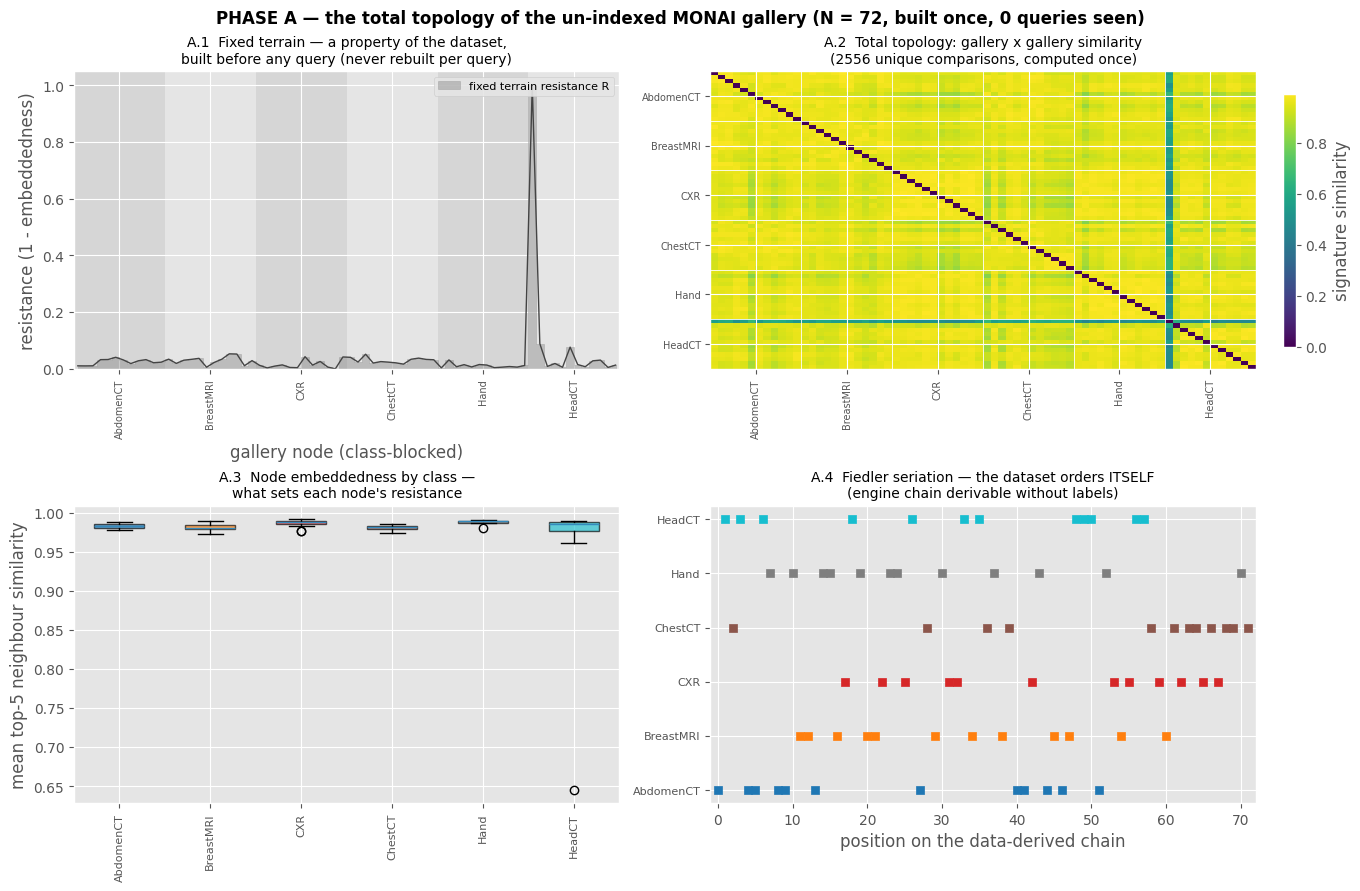


wrote nth_topology_total.png — the topology exists; no query has been answered yet

PHASE B — every query is an INJECTION into the fixed topology
The query chooses WHERE excitation enters; it never redefines the
landscape it diffuses over. (In the in-flight reference architecture
the query WAS the terrain — rebuilt and discarded per query.)

routing accuracy (6 centroids -> correct block): 0.7222
hierarchical comparisons: 1296 total = 6 + 12 per query (18/query vs 72 full scan)

=== Retrieval comparison — architecture, not parameters ===

                               mode  terrain_source    built_when  cmp_per_query   top1   top5    mAP
                    chance (400 MC)            none             -              0 0.1654 0.6069 0.0674
                   raw-pixel cosine            none             -             72 0.8333 0.9028 0.5838
        similarity only (no engine)            none             -             72 0.8194 0.9444 0.4252
          in-flight (query terrain)       per 

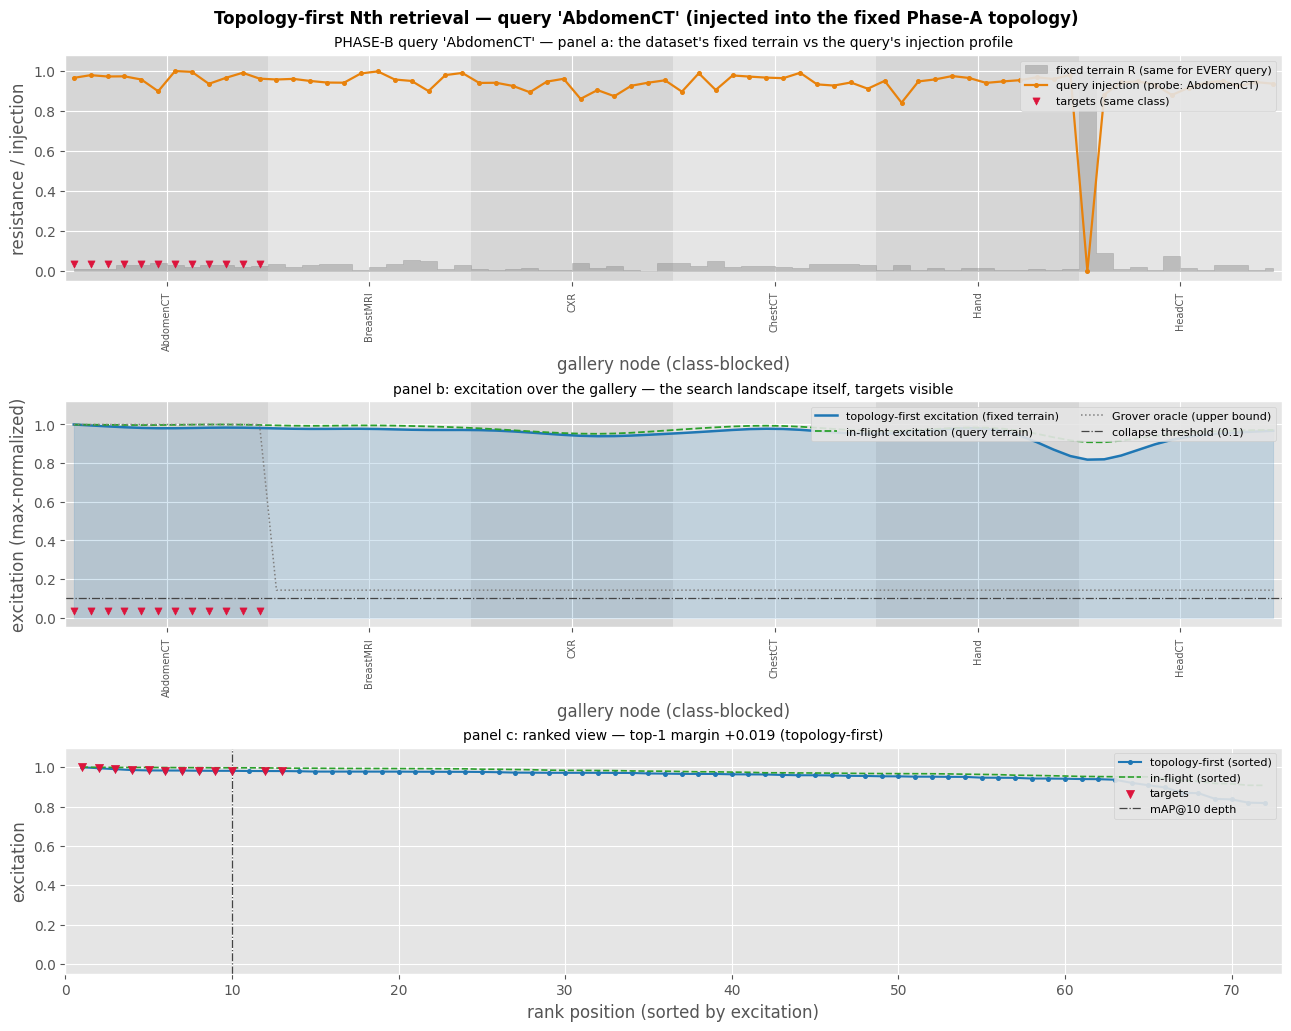

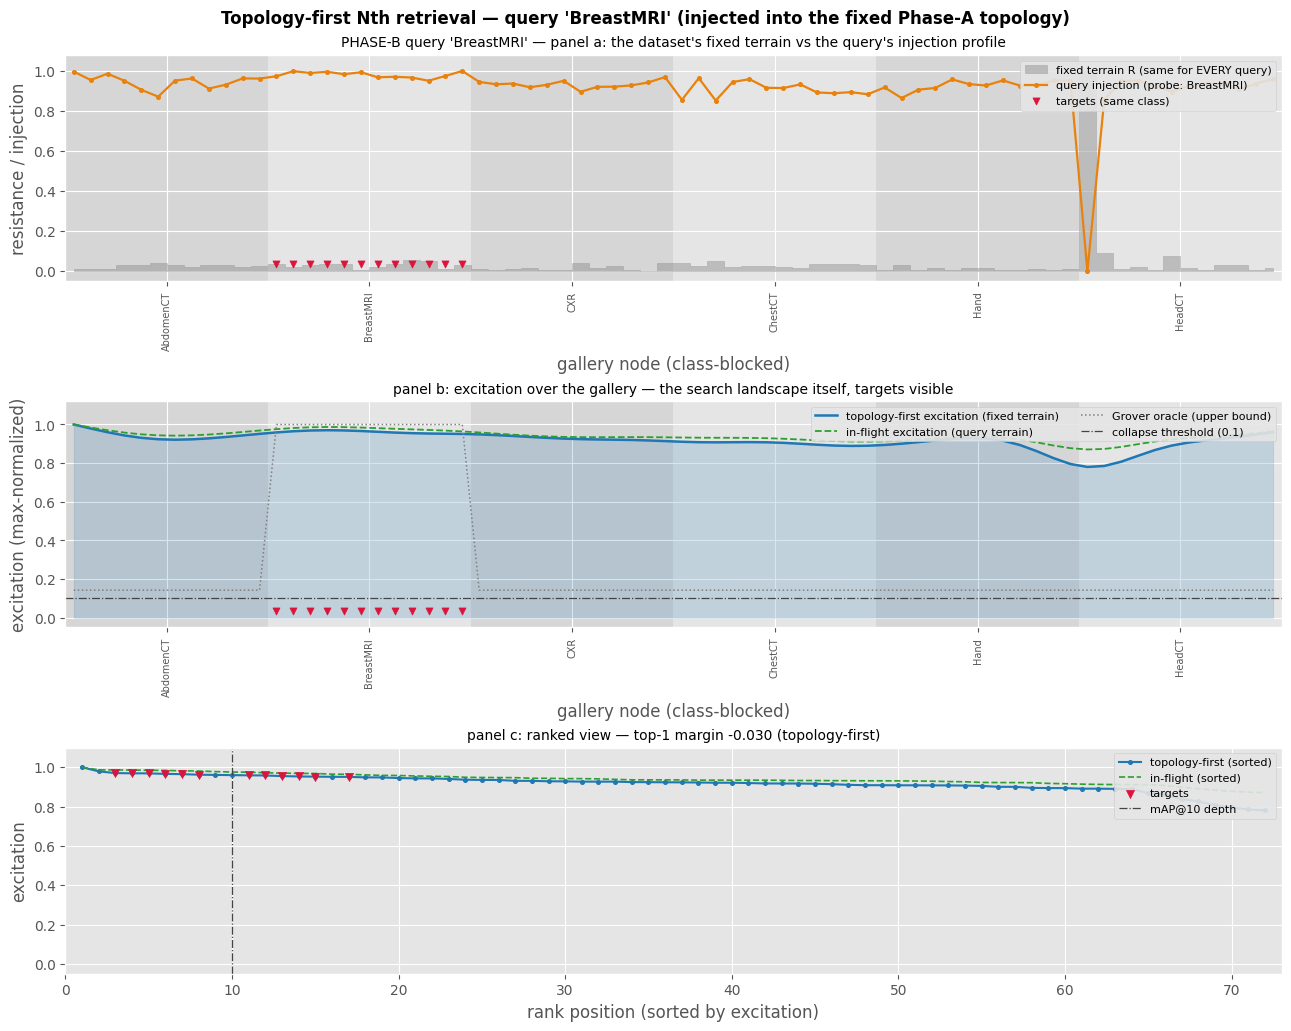

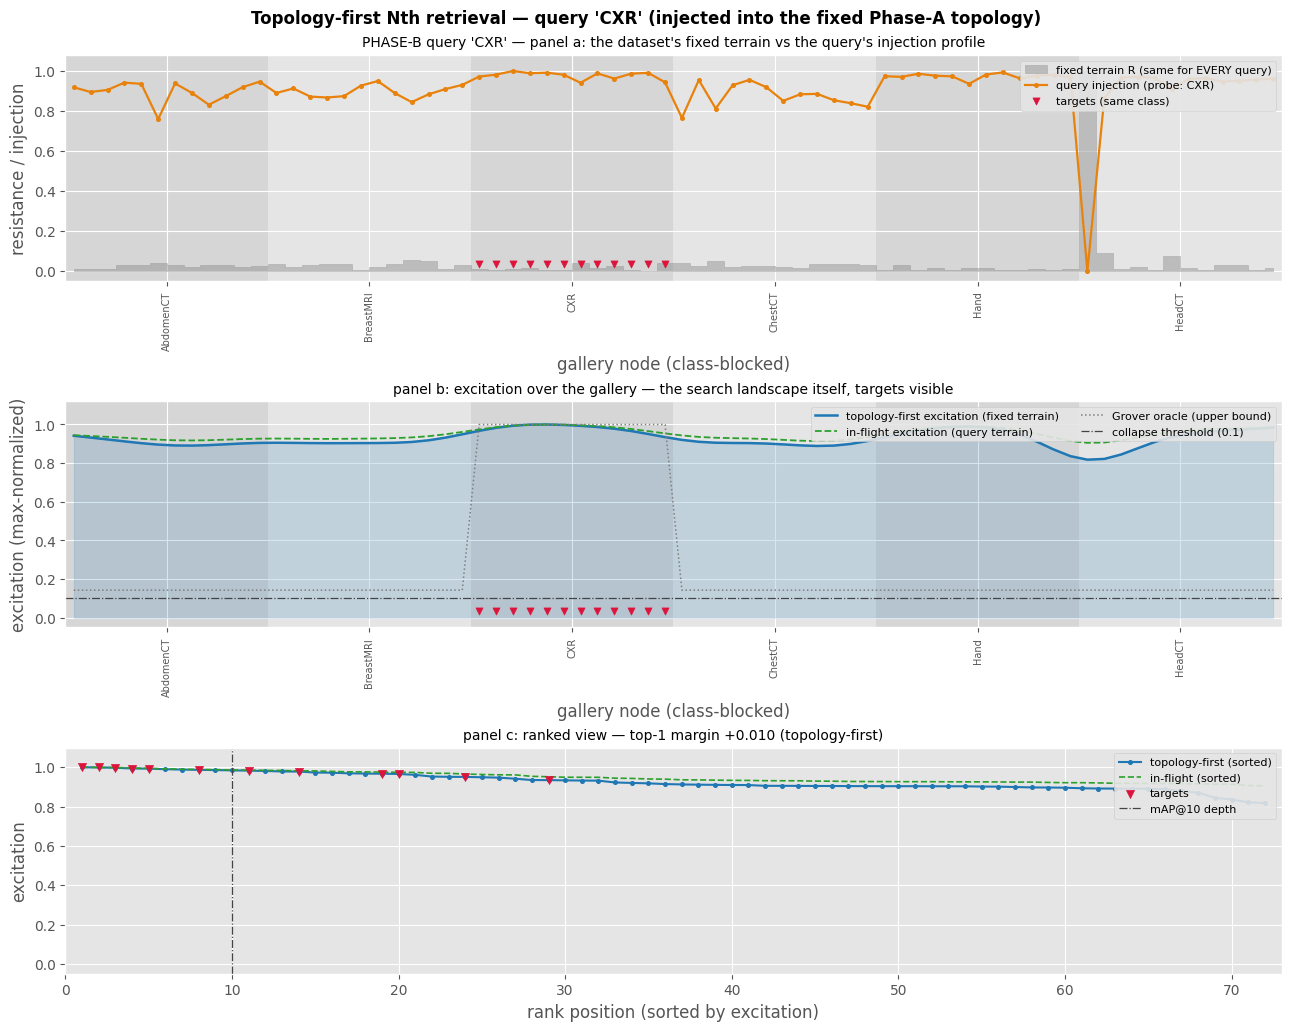

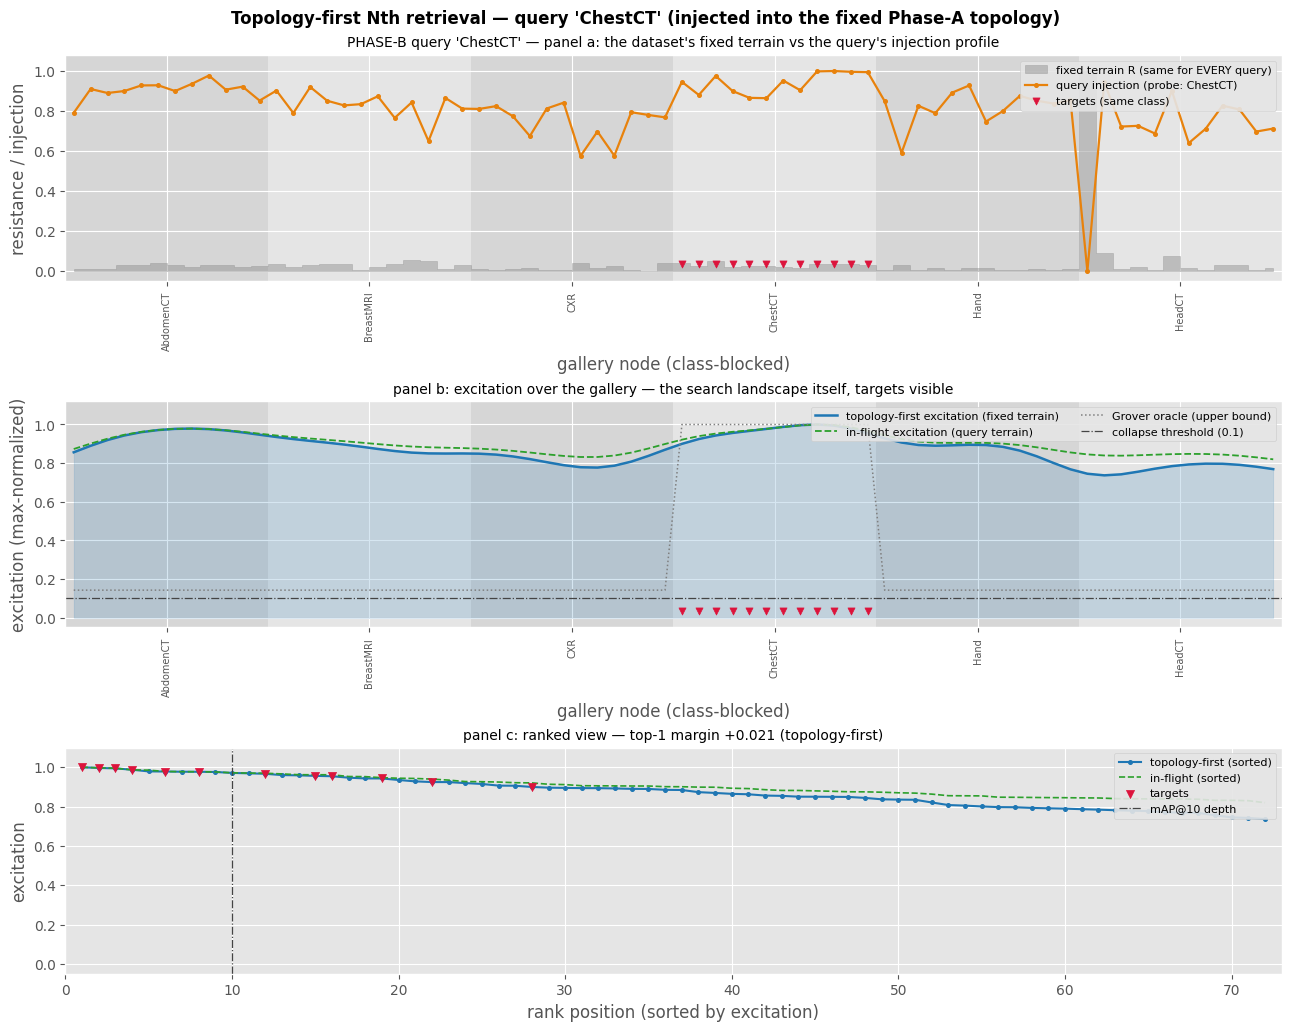

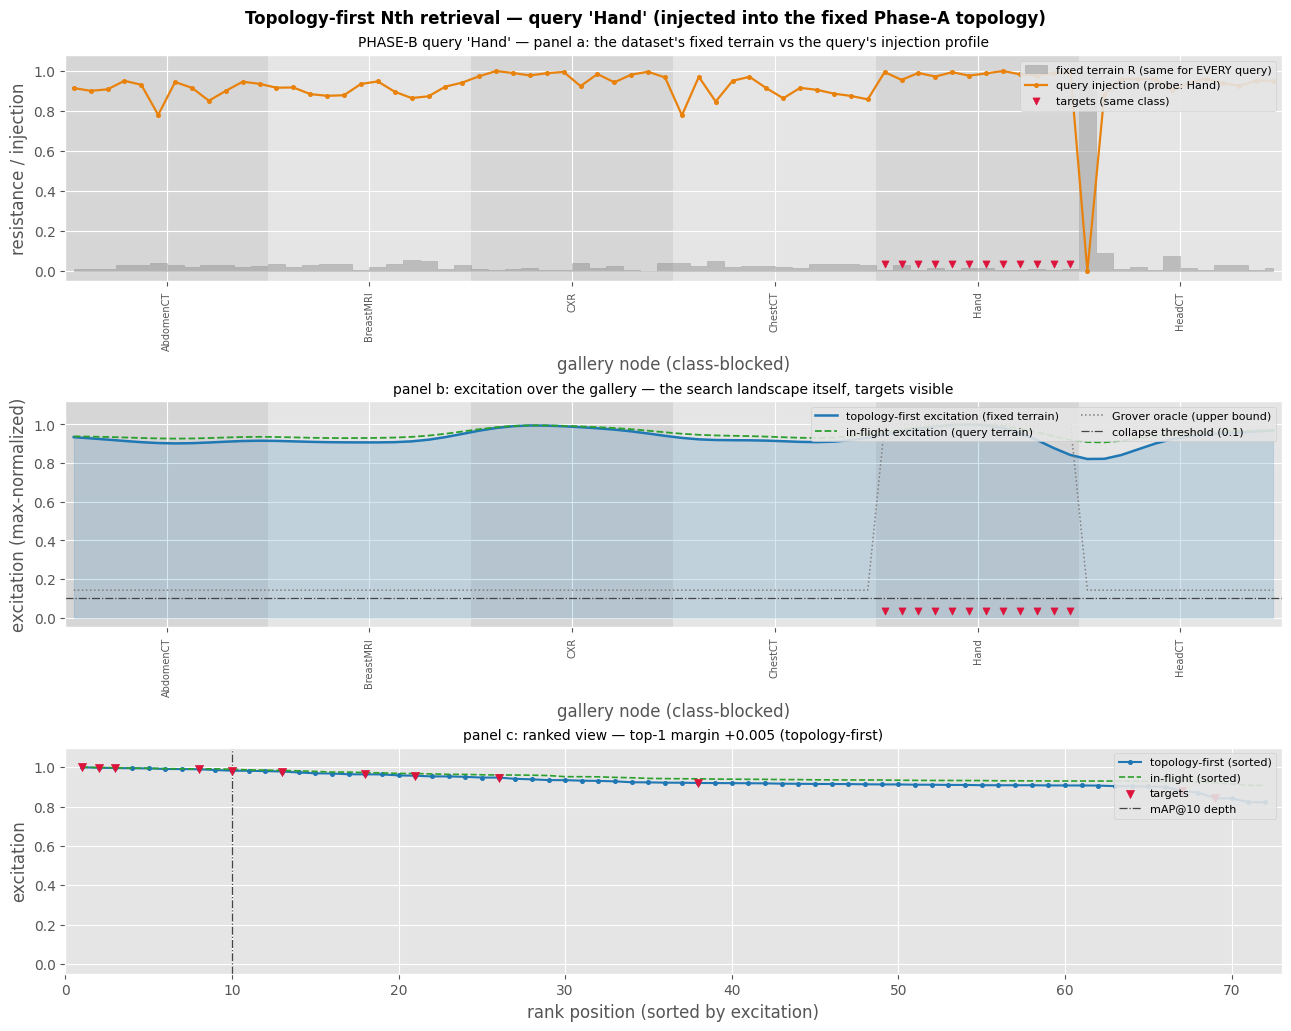

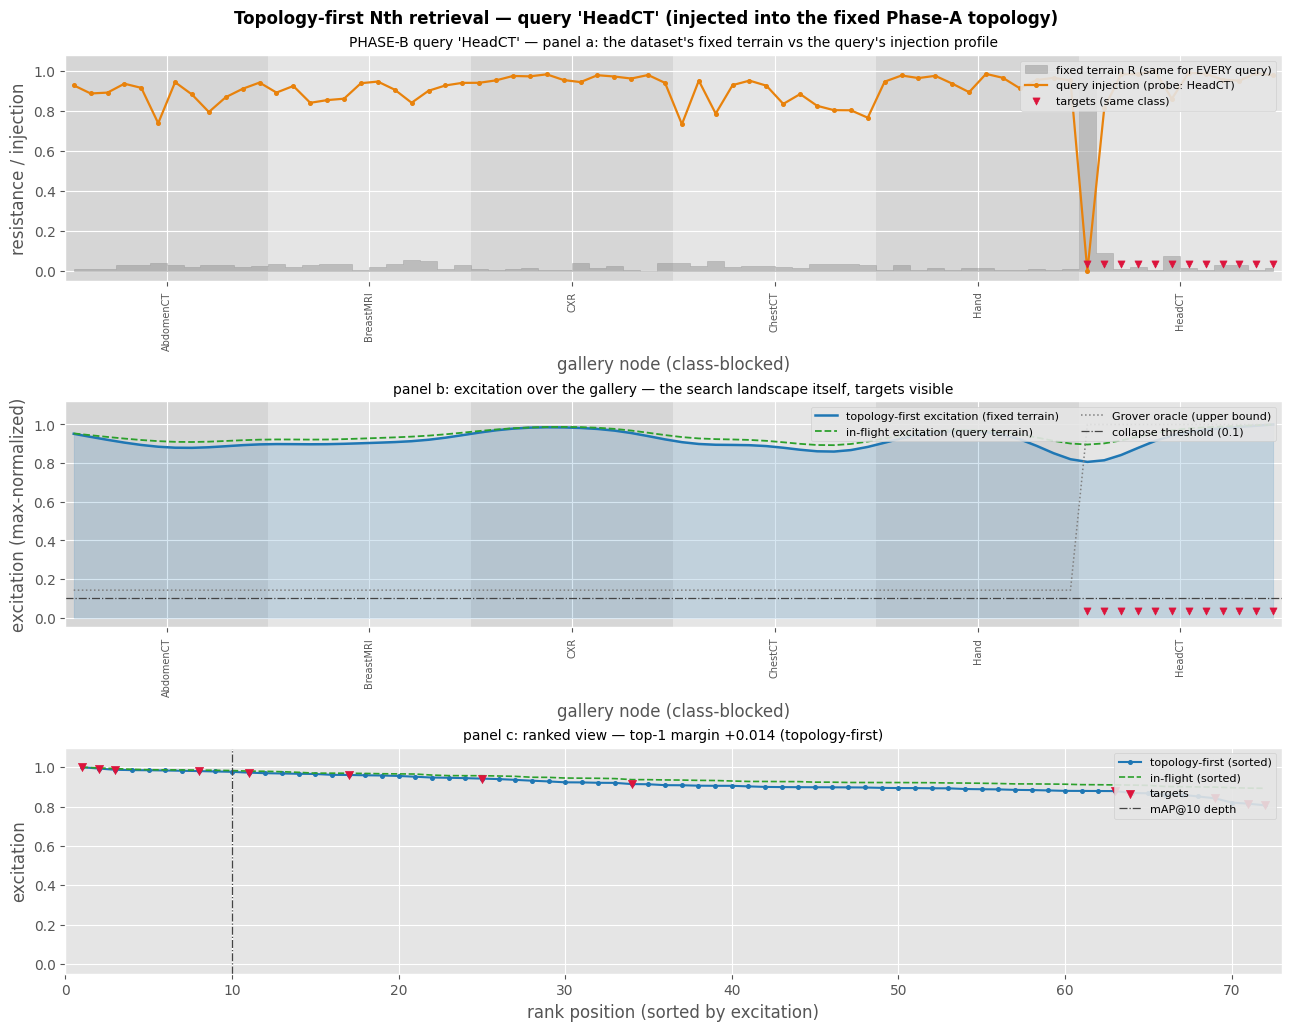

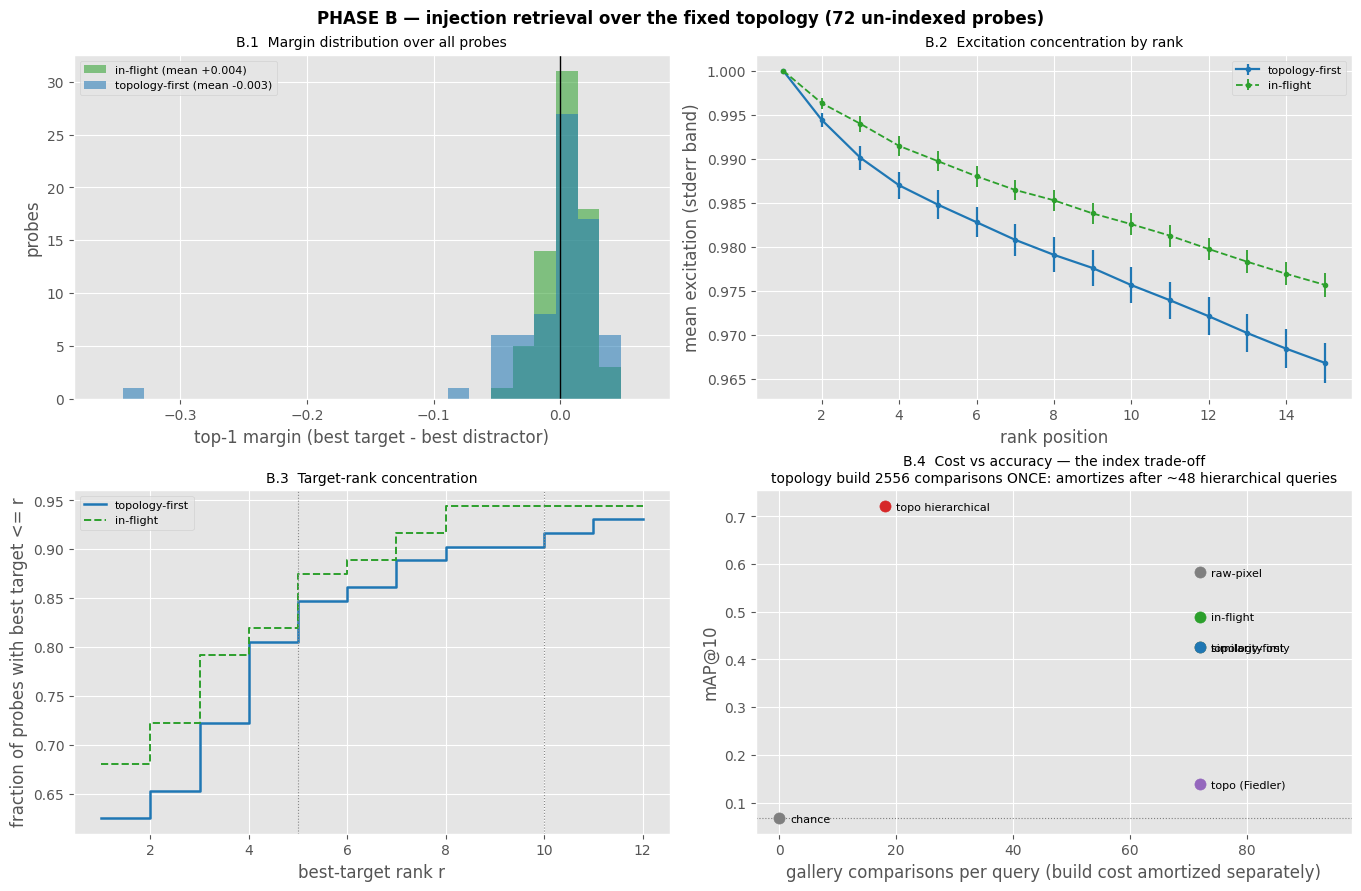


wrote nth_topology_query_<class>.png (one per shown query), nth_topology_summary.png, nth_topology_results.csv

ARCHITECTURE RECAP
  Phase A (once): signatures + gallery x gallery similarity + FIXED
  terrain R + centroids + Fiedler chain  —  the total topology of the
  un-indexed dataset, constructed top-down before any query.
  Phase B (per query): injection only — 6 centroid comparisons route
  hierarchically, 12 block comparisons inject, engine stages verbatim
  diffuse over the FIXED terrain. The query never redefines the land.


In [2]:
# -*- coding: utf-8 -*-
"""
NTH MATHEMATICS INDEXING — TOPOLOGY-FIRST SELF-CONTAINED SIMULATION CELL
the total topology of the un-indexed MONAI MedNIST dataset is constructed
FIRST (Phase A); every query is then an INJECTION into that fixed
topology (Phase B)

ONE CELL. Paste it into a FRESH Colab runtime and run. There is NO
dependency on any prior cell, notebook state, or external module beyond
numpy / matplotlib / pandas / pillow (all preinstalled in Colab; pip
fallbacks included). Everything this cell uses it defines itself.

ARCHITECTURE — why this cell exists. The previous cells answered every
query IN-FLIGHT: the terrain resistance landscape was manufactured from
the probe's own min-max similarity row, used once, and discarded. The
dataset's own structure (gallery-to-gallery) was never computed; nothing
amortized; each query paid a full O(N) scan forever. In the ORIGINAL Nth
demonstration the terrain existed BEFORE the search (drawn once, fixed)
and the engine READ it — the retrieval mapping had inverted that order.
This cell restores the demo's build-then-search order:

  PHASE A (offline, ONCE, from the un-indexed dataset alone — 0 probes):
    1. real-corpus acquisition (NO synthetic fallback exists; hard
       RuntimeError if no real corpus is reachable)
    2. serpentine signals -> streaming formal indexer -> Nth signatures
       at the pinned sweep-best config (W63-t2.0-nogate, cosine,
       spectral block weights)
    3. TOTAL TOPOLOGY: gallery x gallery signature similarity; FIXED
       terrain resistance R = 1 - minmax(mean top-k neighbour
       similarity) — a property of the DATASET (manifold-central nodes
       get low resistance, outliers get high resistance); class
       centroids for hierarchical routing; Fiedler (spectral) chain
       order so the dataset can order ITSELF, without labels
    4. figure nth_topology_total.png — the topology, drawn before any
       query has been answered

  PHASE B (online, per query — an injection, never a redefinition):
    Mode I    in-flight reference (the prior architecture, reproduced
              inside this cell for direct comparison): the query
              manufactures the terrain
    Mode II   topology-first, full injection: E0 = minmax(similarity
              row) injects everywhere; engine stages VERBATIM over the
              FIXED terrain (symbolic force 1/(1+R), 10x local
              3-neighbour diffusion, max-normalization, 0.1 fusion
              collapse) — with a uniform injection this reduces
              verbatim to the original demonstration
    Mode IIb  same, diffusing along the data-derived Fiedler chain
    Mode III  hierarchical top-down: 6 centroid comparisons route the
              query, 12 block comparisons inject — 18 of 72 gallery
              comparisons per query (sub-linear; topology build of
              N(N-1)/2 comparisons amortizes after ~48 queries)

  Outputs: per-query excitation figures (fixed terrain + injection;
  excitation with targets visible and the Grover oracle overlay; ranked
  view), an aggregate architecture-comparison figure, and a metrics
  table (top-1 / top-5 / mAP@10 vs chance / raw-pixel baselines).

  SECTION 1  formal operator stack (inlined verbatim from the formal
             compliance build, Cells 1-7 definitions)
  SECTION 2  real-corpus acquisition — NO synthetic fallback exists in
             this cell (explicit requirement: never report synthetic
             diagnostics as dataset measurements). Candidate roots are
             scanned in priority order — DATA_ROOT (default
             /content/nth_monai_data), /content/nth_monai_data,
             ./nth_monai_data, /content/data, ./data, /content, the
             notebook directory — by pruned os.walk over absolute paths;
             any archive found on the way is extracted (idempotently)
             and re-scanned; the pinned public release archive is
             downloaded only as the LAST resort; if no real corpus is
             reachable the cell raises RuntimeError with the full
             acquisition trace instead of degrading
  SECTION 3  image -> 1-D selector-trajectory adapter
  SECTION 4  oracle-free corpus reference (Axiom-10 central selectors
             bootstrapped from the INDEXED gallery only)
  SECTION 5  parameterized streaming formal indexer
  SECTION 6  fixed-length Nth-signature blocks
  SECTION 7  search utilities (similarity matrix, retrieval metrics)
  SECTION 8  formal compliance guard (axiom spot-checks)
  SECTION 9  topology-first engine definitions (defs only)
  SECTION 10 execution Phase A: index build + TOTAL TOPOLOGY (before
             any query)
  SECTION 11 execution Phase B: query injection over the fixed topology

Artifacts written next to the notebook: nth_topology_total.png,
nth_topology_query_<class>.png (one per shown query),
nth_topology_summary.png, nth_topology_results.csv.
"""

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 0 — imports                                                     ║
# ╚══════════════════════════════════════════════════════════════════════════╝

import hashlib
import math
import os
import subprocess
import sys
import tarfile
import time
import urllib.request
import warnings
import zipfile
from dataclasses import dataclass, field
from typing import Dict, List, Tuple

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")
plt.style.use("ggplot")


def _pip_install(pkg):
    """Last-resort pip fallback for optional dependencies."""
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           pkg])


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 1 — Formal Operator Stack                                        ║
# ║  (inlined verbatim from the formal compliance build; definitions only —   ║
# ║   no demo signals, no module-global window state)                         ║
# ╚══════════════════════════════════════════════════════════════════════════╝

try:                                    # sympy available in Colab; fallback below
    from sympy import isprime as _sympy_isprime

    def _isprime_int(n: int) -> bool:
        return bool(_sympy_isprime(n))
except Exception:                       # deterministic fallback
    def _isprime_int(n: int) -> bool:
        if n < 2:
            return False
        if n < 4:
            return True
        if n % 2 == 0:
            return False
        f = 3
        while f * f <= n:
            if n % f == 0:
                return False
            f += 2
        return True


ALPHA = 0.5          # phase-deviation weight of the delta metric (Construct 2.0)


@dataclass
class Selector:
    """
    Nth Identity n_|k, p| (Axiom 2.0):
      k : magnitude
      p : phase — +1 = real (1), −1 = unreal (i) for trajectory selectors;
          float phase-magnitudes p > 1 occur on V2 asymmetric identities
          (n_|k, p·i|), per the notebook's corrected V2 representation.
    """
    k: float
    p: float
    tags: Dict = field(default_factory=dict)

    def copy(self) -> "Selector":
        return Selector(self.k, self.p, dict(self.tags))

    def __repr__(self) -> str:
        if self.p == +1:
            ph = "1"
        elif self.p == -1:
            ph = "i"
        else:
            ph = f"{self.p:.2f}i"
        return f"n_|{self.k:.4f},{ph}|"


ZERO_SEL = Selector(0.0, +1)   # n-line ground state


# ── Structural Primality (SDP) ────────────────────────────────────────────

def is_structurally_prime_mag(k: float) -> bool:
    """
    SDP of a raw magnitude (notebook Cell 1 rule): k ≤ 1 is structurally
    prime; otherwise prime iff no a, b > 1 with a + b = k. Used to assign
    selector phases to magnitude-only objects (e.g. Euler-triangle entries).
    """
    n = abs(int(round(k)))
    if n <= 1:
        return True
    return _isprime_int(n)


def sdp_deviation(k: float, p: float) -> int:
    """Deviation of a selector under the V2 asymmetric rule: |k + |p||."""
    return abs(int(round(k + abs(p))))


def is_structurally_prime_sel(k: float, p: float) -> bool:
    """
    SDP(s) — V2 corrected rule: an identity is structurally prime iff its
    Deviation (k + |p|) is prime. Strictly enforces Asymmetric Nth
    Identity principles.
    """
    d = sdp_deviation(k, p)
    if d <= 1:
        return True
    return _isprime_int(d)


def nth_primes_asymmetric(n: int) -> List[Selector]:
    """
    First n asymmetric selectors satisfying the V2 SDP deviation rule
    (scan order identical to the notebook: k = 1..10, then p increments).
    The phase field carries the float phase-magnitude p (asymmetric
    identities are n_|k, p·i|), and the tag records the prime deviation.
    """
    primes: List[Selector] = []
    k_val, p_val = 1.0, 1.0
    while len(primes) < n:
        if is_structurally_prime_sel(k_val, p_val):
            primes.append(Selector(k_val, p_val,
                                   {"deviation": sdp_deviation(k_val, p_val)}))
        k_val += 1.0
        if k_val > 10:
            k_val = 1.0
            p_val += 1.0
    return primes


# ── Delta metric (Construct 2.0) ──────────────────────────────────────────

def delta_metric(ka, pa, kb, pb, alpha: float = ALPHA):
    """
    δ(s₁, s₂) = |k₁ − k₂| + α · Δphase ,  Δphase = 1 if phases differ else 0.
    Vectorized over arrays; also accepts scalars.
    """
    return np.abs(np.asarray(ka) - np.asarray(kb)) + alpha * (np.asarray(pa) != np.asarray(pb))


# ── Nth fusion — Axiom 9.2 / notebook Cell 1 (vectorized) ─────────────────

def nth_fusion_vec(ka, pa, kb, pb):
    """
    n_|A| ⊕ n_|B| → (R, U, C1, C2):
      R  = A + B          real output
      U  = −(A + B)       unreal output (subtraction embedded in addition)
      C1 = A − B          cross-phase 1
      C2 = B − A          cross-phase 2
    Phase of R: real (+1). Phase of U: unreal (−1).
    Phase of C1: +1 if operand phases match, −1 if they differ; C2 opposite.
    """
    ka, kb = np.asarray(ka), np.asarray(kb)
    pa, pb = np.asarray(pa), np.asarray(pb)
    same = (pa == pb)
    one = np.ones_like(ka, dtype=np.int8)
    return {
        "R":  (ka + kb,  one),
        "U":  (-(ka + kb), -one),
        "C1": (ka - kb,  np.where(same, 1, -1).astype(np.int8)),
        "C2": (kb - ka,  np.where(same, -1, 1).astype(np.int8)),
    }


def nth_product_vec(ka, pa, kb, pb):
    """
    n_|A| ⊗ n_|B| → (R, U, C1, C2) — Axiom 9.3. Second-operand phase rule:
    the second operand's phase determines the result phase.
    """
    ka, kb = np.asarray(ka), np.asarray(kb)
    pb = np.asarray(pb)
    mag = ka * kb
    one = np.ones_like(mag, dtype=np.int8)
    return {
        "R":  ( mag,  ( pb * one).astype(np.int8)),
        "U":  ( mag,  (-pb * one).astype(np.int8)),
        "C1": (-mag,  ( pb * one).astype(np.int8)),
        "C2": (-mag,  (-pb * one).astype(np.int8)),
    }


def nth_scalar_project(ka, pa, kb, pb):
    """Single-output scalar projection of the product: k_out = a.k · b.k,
    phase determined by the second operand."""
    return np.asarray(ka) * np.asarray(kb), np.asarray(pb)


# ── Fusion asymmetry — Axiom 0 helper ─────────────────────────────────────

def fusion_asymmetry(k, p):
    """
    Fusion asymmetry FA(τ) of a selector trajectory:
        FA(τ) = 2 · atan2(unreal_mass, real_mass)
    Law of Symbolic Dual Resonance (Axiom 0): FA(F) + FA(−F) = π (mod 2π).
    """
    k = np.asarray(k)
    p = np.asarray(p)
    real_mass = float(np.sum(k[p > 0]))
    unreal_mass = float(np.sum(k[p < 0]))
    if real_mass == 0.0 and unreal_mass == 0.0:
        return 0.0
    return 2.0 * math.atan2(unreal_mass, real_mass)


# ── Nth constants: Euler triangle, ε, π ────────────────────────────────────

EPSILON_NTH = 0.064733   # Nth constant ε — symbolic unreal ratio (App F)


def euler_triangle_row(level: int) -> np.ndarray:
    """
    Euler's Triangle, row `level` (App F). Recursive construction:
        T(n, 0) = 1,   T(n, k) = T(n, k−1) + T(n−1, k),   T(n, n) = T(n, n−1)
    """
    row = [1.0]
    for _ in range(level):
        new = [1.0]
        for kk in range(1, len(row)):
            new.append(new[-1] + row[kk])
        new.append(new[-1])
        row = new
    return np.array(row)


def euler_triangle_selectors(level: int) -> List[Selector]:
    """Row entries reframed as selectors: phase real (+1) if SDP(magnitude),
    unreal (−1) if decomposable."""
    return [Selector(e, +1 if is_structurally_prime_mag(e) else -1)
            for e in euler_triangle_row(level)]


def euler_unreal_share(n_rows: int = 12) -> Tuple[float, np.ndarray]:
    """Empirical unreal-channel mass share of the Euler triangle selectors
    accumulated over rows 1..n_rows (reported alongside ε, App F)."""
    shares = []
    tot_r = tot_u = 0.0
    for lvl in range(1, n_rows + 1):
        for s in euler_triangle_selectors(lvl):
            if s.p > 0:
                tot_r += abs(s.k)
            else:
                tot_u += abs(s.k)
        shares.append(tot_u / (tot_r + tot_u + 1e-18))
    return float(shares[-1]), np.array(shares)


def euler_fusion_weights(n_channels: int, level: int = 2) -> np.ndarray:
    """
    Channel-fusion weights from the formal Euler triangle row. The row is
    centred/padded to the channel count and normalized.
    """
    row = euler_triangle_row(level)
    if len(row) > n_channels:
        start = (len(row) - n_channels) // 2
        row = row[start:start + n_channels]
    elif len(row) < n_channels:
        pad = n_channels - len(row)
        left = pad // 2
        row = np.pad(row, (left, pad - left), mode="edge")
    return row / np.sum(row)


def nth_pi_emergence(n_iter: int = 40) -> Tuple[float, List[Tuple[float, float, float, float]]]:
    """
    π = F(C1, C2, C3, C4, ε) — recursive tuples in spiral-cylinder topology
    (App G–I). The real-channel closure alone recovers the classical Viète
    product identity 2/π = Π x_n; ε weights the unreal-channel share.
    """
    x = math.sqrt(0.5)                          # C1: first chord selector
    P = 2.0 / x                                 # C3: accumulator, first turn
    hist: List[Tuple[float, float, float, float]] = []
    for _ in range(n_iter):
        c2 = math.sqrt(max(0.0, 1.0 - x * x))   # C2 — dual arc (unreal)
        P_prev = P
        x = math.sqrt((1.0 + x) / 2.0)          # C1 — half-angle fusion closure
        P = P / x                               # C3 — unroll one spiral turn
        c4 = abs(P - P_prev)                    # C4 — cross-phase deviation
        hist.append((x, c2, P, c4))
    return P, hist


def euler_diffusion_kernel(radius: int = 2, level: int = 4) -> np.ndarray:
    """
    Fusion-diffusion kernel: the Euler selector row closed under symbolic-dual
    symmetrization (Axiom 0: F ⊕ −F), centred to 2·radius+1 taps.
    """
    row = euler_triangle_row(level)
    target = 2 * radius + 1
    if len(row) < target:
        pad = target - len(row)
        row = np.pad(row, (pad // 2, pad - pad // 2), mode="edge")
    else:
        start = (len(row) - target) // 2
        row = row[start:start + target]
    row = 0.5 * (row + row[::-1])          # dual-resonance symmetrization
    return row / np.sum(row)


# ── n-line deviation encoding (Axioms 1.0–1.4) ─────────────────────────────

def local_n_line(sig: np.ndarray, window: int = 50) -> np.ndarray:
    """
    Local n-line ground state: rolling median (resonance closure of the
    n-line over the trailing window). 0 ≡ n ± x (Axiom 1.1), so the n-line
    anchor is the local median of the signal itself.
    """
    pad = np.concatenate([np.full(window, sig[0]), sig])
    view = np.lib.stride_tricks.sliding_window_view(pad, window + 1)
    return np.median(view, axis=1)


def encode_deviation(sig: np.ndarray, base: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """
    Encode the signal as a selector trajectory via the Fusion Collapse
    Quotient (Axiom 1.2: n − (n + k) = k):
        k_j = |f(t_j) − n_line_j|        magnitude
        p_j = +1 (real) if above the n-line, −1 (unreal) if below
    """
    dev = sig - base
    return np.abs(dev), np.where(dev >= 0, 1, -1).astype(np.int8)


def decode_trajectory(k: np.ndarray, p: np.ndarray) -> np.ndarray:
    """Scalar projection: signed deviation (real → +k, unreal → −k)."""
    return k * p


# ── Prime-carrier basis + windowed NthTransform (Layers 3–5) ──────────────

def make_nth_basis(W):
    """
    Prime-carrier mode basis at width W (Cell-4 convention): real channel
    carried by cos, unreal channel by -sin (exp(-2πjk/W) — the DFT
    imaginary part under restriction). Carriers anchor mode identity via
    the V2 SDP rule and divide out of the normalization.
    """
    K = W // 2 + 1
    th = 2.0 * np.pi * np.outer(np.arange(W), np.arange(K)) / W
    return np.cos(th), -np.sin(th), K


def nth_transform_window(k_win, p_win, cos_basis, sin_basis, W):
    """
    Windowed NthTransform (notebook Cell 4, vectorized — basis passed
    explicitly, no module-global window state):
        R_k = Σ_j  f̃_j · cos(2πjk/W) / W        real channel
        U_k = −Σ_j f̃_j · sin(2πjk/W) / W        unreal channel
        C1 = R − U    real-pointing structural deviation
        C2 = U − R    unreal-pointing resonance duality
    where f̃_j = ±k_j is the signed magnitude (phase-aware accumulation).
    """
    f_signed = k_win * p_win
    R = f_signed @ cos_basis / W
    U = f_signed @ sin_basis / W
    C1 = R - U
    C2 = U - R
    return R, U, C1, C2


def nth_inverse_transform(R, U, W: int, faithful: bool = False):
    """
    Inverse NthTransform (notebook Cell 5). faithful=True reproduces the
    notebook's plain (1/K)Σ synthesis; the default uses the exact
    real-Fourier weights (w = 2 interior, 1 for k = 0 and Nyquist when W
    is even).
    """
    K = len(R)
    jj = np.arange(W)
    if faithful:
        s = np.zeros(W)
        for kk in range(K):
            th = 2.0 * np.pi * jj * kk / W
            s += R[kk] * np.cos(th) - U[kk] * np.sin(th)
        return s / K
    w = np.full(K, 2.0)
    w[0] = 1.0
    if W % 2 == 0:
        w[-1] = 1.0
    th = 2.0 * np.pi * np.outer(jj, np.arange(K)) / W
    return (np.cos(th) * (R * w)) .sum(axis=1) - (np.sin(th) * (U * w)).sum(axis=1)


def resonance_exposure(k, p, mu_k, mu_p, sigma, alpha: float = ALPHA):
    """
    Nth Resonance Weighting (Axiom 10): exposure of selector(s) (k, p) to
    the central selector S_μ = (μ_k, μ_p):
        ρ(k) = exp( −δ(k, μ)² / (2σ²) )
    σ may be a scalar or a per-mode array.
    """
    sigma = np.maximum(np.asarray(sigma, dtype=float), 1e-9)
    d = np.abs(np.asarray(k) - mu_k) + alpha * (np.asarray(p) != mu_p)
    return np.exp(-d ** 2 / (2.0 * sigma ** 2))


def robust_center(x):
    """Median / MAD resonance center of a channel (Axiom-10 μ and σ)."""
    med = float(np.median(x))
    mad = float(np.median(np.abs(np.asarray(x) - med)))
    return med, max(mad, 1e-9)


def delta_norm_trajectory(k, p, alpha: float = ALPHA) -> float:
    """
    Delta norm of a selector trajectory (Parseval analog, notebook Cell 7):
        ||τ||_δ = sqrt( Σ_j δ(S_j, ZERO)² ),  δ(S_j, 0) = k_j + α·[unreal]
    """
    d = np.asarray(k) + alpha * (np.asarray(p) < 0)
    return float(np.sqrt(np.sum(d ** 2)))


def delta_norm_coefficients(R, U, alpha: float = ALPHA) -> float:
    """
    Delta norm of the NthTransform coefficients (Parseval analog):
        ||C||_δ = sqrt( Σ_k [ δ(c_R, 0)² + δ(c_U, 0)² ] / K )
    """
    dR = np.abs(R)
    dU = np.abs(U) + alpha
    return float(np.sqrt(np.sum(dR ** 2 + dU ** 2) / len(R)))


# ── Nth Jacobian J_Nth (phase-resolved geometric implementation) ──────────

def nth_jacobian_window(k_win, p_win, ridge: float = 1e-9):
    """
    Sliding-window Nth Jacobian of the selector-state evolution map
    (Axiom 5.0): local linearization of Δ via δ-regularized least squares.
        J = [[a, b], [c, d]],   k' ≈ a·k + b·p ,  p' ≈ c·k + d·p
    """
    Z = np.column_stack([k_win[:-1], p_win[:-1].astype(float)])
    X = np.column_stack([k_win[1:], p_win[1:].astype(float)])
    G = Z.T @ Z
    G[np.diag_indices_from(G)] += ridge * max(np.trace(G), 1e-12)
    theta = np.linalg.solve(G, Z.T @ X)          # (2, 2)
    a, b = theta[:, 0]
    c, d = theta[:, 1]
    return a, b, c, d


def nth_jacobian_entry_selectors(a, b, c, d):
    """
    Per-entry Nth conversion: each classical Jacobian entry becomes a
    selector n_|entry, p| with phase from its sign and an SDP tag.
    """
    vals = (a, b, c, d)
    k = np.array([abs(v) for v in vals])
    p = np.array([1 if v >= 0 else -1 for v in vals], dtype=np.int8)
    sdp = [is_structurally_prime_sel(k[i], p[i]) for i in range(4)]
    return k, p, sdp


def nth_jacobian_determinant(a, b, c, d):
    """
    Nth determinant fusion for J_Nth = [[a, b], [c, d]]:
        R  = ad − bc    real channel — classical determinant (area scaling)
        U  = −(ad − bc) unreal channel — dual / inverted geometry
        C1 = ad + bc    symmetric coupling — inter-axis co-scaling
        C2 = bc − ad    asymmetric coupling — directional shear
    """
    det = a * d - b * c
    per = a * d + b * c
    R = det
    U = -det
    C1 = per
    C2 = b * c - a * d
    return R, U, C1, C2


def res_jacobian(R, U, C1, C2, eps: float = EPSILON_NTH):
    """
    Resolution operator Res(J_Nth) (Axiom 5.4): the stable state via
    analytical bypass (fixed point of the fusion-loop closure). Mutually
    inverse with Δ⁻¹(J_Nth).
    """
    return 0.5 * (R + C1) + eps * U


def delta_evolve(x_t, x_tm1, h: int = 1):
    """
    Δ^h — forward evolution operator (momentum form on the magnitude
    channel): x_{t+h} = x_t + h·(x_t − x_{t−1}) (Axiom 5.1, App R).
    """
    return x_t + h * (x_t - x_tm1)


def delta_inverse(x_t, x_tm1, h: int = 1):
    """
    Δ⁻¹ — inverse evolution / precursor reconstruction (Axiom 5.5): fully
    reversible; x_{t−h} ≈ x_t − h·(x_t − x_{t−1}).
    """
    return x_t - h * (x_t - x_tm1)


def closure_stats(x):
    """
    Robust center / spread for a resonance-closure threshold (Axiom 10).
    The deviation-stable limit of a sparse, event-gated channel is its
    positive support, so med / MAD are computed there; for dense channels
    the full distribution is used. med + 2·MAD remains the ρ = e⁻²
    closure-level estimator on that support.
    """
    x = np.asarray(x, dtype=float)
    pos = x[x > 1e-12]
    if pos.size < max(20, x.size // 20):
        pos = x
    med = float(np.median(pos))
    mad = float(np.median(np.abs(pos - med))) + 1e-9
    return med, mad


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 2 — Real-Corpus Acquisition (NO synthetic fallback)             ║
# ╚══════════════════════════════════════════════════════════════════════════╝

DATA_ROOT = "/content/nth_monai_data"   # primary corpus location (absolute)
N_PER_CLASS = 24                    # requested images per class (12+12 split)
MIN_PER_CLASS = 6                   # smallest folder that still counts as a class
DS = 2                              # block-mean downsample (64/DS -> 32, T = 1024)
SEED = 2026

# Public MedNIST archive — the same resource monai.apps.MedNISTDataset
# downloads, pinned here so the harness never depends on MONAI's
# version-dependent dataset class (and never RAM-caches 47k images):
MEDNIST_URL = ("https://github.com/Project-MONAI/MONAI-extra-test-data/"
               "releases/download/0.8.1/MedNIST.tar.gz")
MEDNIST_MD5 = "0bc7306e7427e00ad1c5526a6677552d"
MEDNIST_GDRIVE_ID = "1QsnnkvZyJPcbRoV_ArW8SnE1TuoQnPu3"   # mirror, same archive

_IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".gif"}
_ARCHIVE_EXTS = (".tar.gz", ".tgz", ".tar", ".zip")
_PRUNE_DIRS = {"drive", ".git", "__pycache__", ".ipynb_checkpoints",
               "node_modules"}


def _data_root_candidates(primary):
    """Absolute candidate roots, priority-ordered, deduplicated."""
    cands = [primary, "/content/nth_monai_data", "./nth_monai_data",
             "/content/data", "./data", "/content", "./"]
    out = []
    for c in cands:
        a = os.path.abspath(c)
        if a not in out:
            out.append(a)
    return out


def _walk_tree(root):
    """
    Pruned os.walk over ABSOLUTE paths (sees hidden/staging dirs, unlike
    glob '**'). Label = leaf folder name, ANY nesting. Per-class dedupe on
    file basename so a re-extraction at another depth can never leak a
    byte-identical probe into the gallery. Extension histogram and archive
    list (any name) are collected for diagnostics and extraction.
    Returns (pool, n_images, ext_histogram, archives).
    """
    by_class = {}          # label -> {basename: path}
    ext_hist = {}
    archives = []
    n_img = 0
    for dirpath, dirnames, filenames in os.walk(os.path.abspath(root)):
        dirnames[:] = sorted(d for d in dirnames if d not in _PRUNE_DIRS)
        for fn in sorted(filenames):
            ext = os.path.splitext(fn)[1].lower()
            ext_hist[ext] = ext_hist.get(ext, 0) + 1
            path = os.path.join(dirpath, fn)
            if any(fn.lower().endswith(e) for e in _ARCHIVE_EXTS):
                archives.append(path)
            if ext in _IMG_EXTS:
                n_img += 1
                cls = by_class.setdefault(os.path.basename(dirpath), {})
                if fn not in cls or path < cls[fn]:
                    cls[fn] = path
    pool = {lbl: sorted(d.values()) for lbl, d in by_class.items()}
    return pool, n_img, ext_hist, archives


def _pool_from_classes(by_class, n_req):
    """
    Adaptive per-class count: a folder with >= MIN_PER_CLASS images
    qualifies (small curated trees are NOT silently dropped); the pool
    loads min(n_req, smallest qualifying class) per class via a seeded,
    deterministic subsample. Returns (pool, per_class_count).
    """
    qual = {lbl: fl for lbl, fl in by_class.items() if len(fl) >= MIN_PER_CLASS}
    if len(qual) < 2:
        return {}, 0
    take = min(n_req, min(len(fl) for fl in qual.values()))
    rng = np.random.default_rng(SEED + 101)
    pool = {}
    for lbl in sorted(qual):
        fl = sorted(qual[lbl])
        if len(fl) > take:
            idx = np.sort(rng.choice(len(fl), size=take, replace=False))
            fl = [fl[i] for i in idx]
        pool[lbl] = fl
    return pool, take


def _md5_of(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _extract_archive(arc_path):
    """
    Extract ANY recognized archive (any name) into .nth_extract_<stem>/
    next to it. Idempotent (reuses a previous extraction), never deletes
    user files, md5 reported but never enforced against user archives.
    Returns the extraction directory.
    """
    name = os.path.basename(arc_path)
    stem = name
    for e in _ARCHIVE_EXTS:
        if stem.endswith(e):
            stem = stem[:-len(e)]
            break
    dest = os.path.join(os.path.dirname(os.path.abspath(arc_path)),
                        f".nth_extract_{stem}")
    if os.path.isdir(dest) and any(os.scandir(dest)):
        print(f"  [info] reusing previous extraction: {dest}")
        return dest
    os.makedirs(dest, exist_ok=True)
    if name.lower().endswith((".tar.gz", ".tgz", ".tar")):
        with tarfile.open(arc_path, "r:*") as tf:
            members = tf.getmembers()
            try:
                tf.extractall(dest, filter="data")     # Python >= 3.12
            except TypeError:                           # older interpreters
                tf.extractall(dest)
        n = len(members)
    else:
        with zipfile.ZipFile(arc_path) as zf:
            zf.extractall(dest)
            n = len(zf.namelist())
    print(f"  [info] extracted {n} members from {name} -> {dest} "
          f"(md5 {_md5_of(arc_path)})")
    return dest


def _download_archive(url, dest_path):
    """Direct download of the public release archive (redirect-safe,
    atomic .part -> rename)."""
    def _hook(n_blocks, block_size, total):
        if total > 0:
            pct = min(100, int(n_blocks * block_size * 100.0 / total))
            print(f"\r  [info] downloading MedNIST.tar.gz: {pct:3d}%",
                  end="", flush=True)
    print(f"  [info] fetching the public MedNIST archive ({url})")
    part = dest_path + ".part"
    urllib.request.urlretrieve(url, part, reporthook=_hook)
    os.replace(part, dest_path)
    print("\r  [info] download finished.                        ")


def _corpus_not_found_error(trace):
    """The hard failure that replaces the old synthetic fallback."""
    msg = ["NO REAL CORPUS FOUND — this cell has NO synthetic fallback",
           "(explicit requirement: never report synthetic diagnostics as",
           "dataset measurements).",
           "",
           "Acquisition trace:",
           *trace,
           "",
           f"Primary data root: {DATA_ROOT}",
           "To fix, do one of:",
           "  1. place the MONAI MedNIST class folders (AbdomenCT/, BrainMRI/,",
           "     BreastMRI/, ChestXR/, Hand/, HeadCT/ — each with at least",
           f"     {MIN_PER_CLASS} images) under {DATA_ROOT};",
           "  2. or put a MedNIST archive (any name: .tar.gz / .tgz / .tar /",
           "     .zip) anywhere on the candidate roots — it will be found,",
           "     extracted and re-scanned;",
           "  3. or allow network access so the pinned public release archive",
           "     can be downloaded (last resort)."]
    return RuntimeError("\n".join(msg))


def acquire_corpus(primary_root, n_req):
    """
    Acquire the REAL public MONAI MedNIST corpus. Ladder, each step
    re-scanning, transparency printed per candidate:

      1. on-disk scan of every candidate root (DATA_ROOT first, absolute);
         class folders at ANY nesting depth qualify;
      2. any archive found during a scan (any name) is extracted
         (idempotently) and the extraction is re-scanned;
      3. network, LAST resort only (after a prominent warning):
         pinned public release archive, then the gdown mirror.

    monai.apps.MedNISTDataset is deliberately never instantiated (current
    MONAI builds it on CacheDataset — the constructor decodes and
    RAM-caches the whole 47k-image corpus — and its extraction layout is
    version-dependent). Returns (class -> file list, source name).
    """
    trace = []
    arcs_tried = []
    for root in _data_root_candidates(primary_root):
        if not os.path.isdir(root):
            trace.append(f"  - {root}: not a directory")
            continue
        pool, n_img, ext_hist, arcs = _walk_tree(root)
        trace.append(f"  - {root}: {n_img} image files, {len(pool)} leaf "
                     f"folders, {len(arcs)} archive(s), extensions {ext_hist}")
        print(f"  [scan] {root} -> {n_img} images, {len(pool)} leaf classes, "
              f"{len(arcs)} archive(s)")
        sub, take = _pool_from_classes(pool, n_req)
        if sub:
            return sub, (f"REAL corpus on disk at {root} "
                         f"({n_img} images seen, {len(sub)} classes x {take})")
        for arc in arcs:
            if arc in arcs_tried:
                continue
            arcs_tried.append(arc)
            dest = _extract_archive(arc)
            pool2, n2, _, _ = _walk_tree(dest)
            sub, take = _pool_from_classes(pool2, n_req)
            if sub:
                return sub, (f"REAL corpus from archive {os.path.basename(arc)}"
                             f" -> {dest} ({n2} images, "
                             f"{len(sub)} classes x {take})")
            trace.append(f"    archive {os.path.basename(arc)}: extracted to "
                         f"{dest}, still no qualifying pool")

    # prominent warning BEFORE any network use
    print("  [warn] no qualifying class pool found on disk (see the scan "
          "lines above for what each root holds). Network download will "
          "now be attempted as the LAST resort.")

    scratch = os.path.join(os.path.abspath(primary_root), ".nth_download")
    os.makedirs(scratch, exist_ok=True)
    tar_path = os.path.join(scratch, "MedNIST.tar.gz")

    try:                                            # pinned public release
        _download_archive(MEDNIST_URL, tar_path)
        dest = _extract_archive(tar_path)
        pool, n_img, _, _ = _walk_tree(dest)
        sub, take = _pool_from_classes(pool, n_req)
        if sub:
            return sub, (f"REAL corpus from the pinned public release archive "
                         f"(downloaded to {tar_path}; {n_img} images, "
                         f"{len(sub)} classes x {take})")
        trace.append("  - downloaded archive extracted but no qualifying pool")
    except Exception as e_b:
        trace.append(f"  - direct download failed: {e_b}")

    try:                                            # gdown mirror
        try:
            import gdown  # noqa: F401
        except ImportError:
            _pip_install("gdown")
            import gdown
        gdown.download(id=MEDNIST_GDRIVE_ID, output=tar_path, quiet=True)
        dest = _extract_archive(tar_path)
        pool, n_img, _, _ = _walk_tree(dest)
        sub, take = _pool_from_classes(pool, n_req)
        if sub:
            return sub, (f"REAL corpus from the gdown mirror ({n_img} images, "
                         f"{len(sub)} classes x {take})")
        trace.append("  - gdown archive extracted but no qualifying pool")
    except Exception as e_c:
        trace.append(f"  - gdown mirror failed: {e_c}")

    raise _corpus_not_found_error(trace)


def load_dataset(root, n_req):
    """
    Load the real corpus as {class: [float arrays]}. Unreadable images are
    skipped with a warning; the pool is re-balanced to the smallest
    surviving class. NO synthetic branch exists. Returns
    (images, source, n_per_class_loaded).
    """
    pool, source = acquire_corpus(root, n_req)
    try:
        from PIL import Image
    except ImportError:
        _pip_install("pillow")
        from PIL import Image
    images = {}
    for lbl in sorted(pool):
        loaded = []
        for f in pool[lbl]:
            try:
                arr = np.asarray(Image.open(f).convert("L"), dtype=float)
                if arr.size:
                    loaded.append(arr)
                else:
                    print(f"  [warn] empty image skipped: {f}")
            except Exception as e:
                print(f"  [warn] unreadable image skipped: {f} ({e})")
        if loaded:
            images[lbl] = loaded
    if len(images) < 2:
        raise _corpus_not_found_error(
            [f"  - pool had {len(pool)} classes but only {len(images)} "
             f"survived image loading"])
    n_loaded = min(len(v) for v in images.values())
    images = {lbl: v[:n_loaded] for lbl, v in sorted(images.items())}
    return images, source, n_loaded


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 3 — Image -> 1-D Signal Adapter                                  ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def block_mean(img, ds):
    """Non-overlapping block mean (ds x ds) — scale layer of the scan."""
    h, w = img.shape
    h2, w2 = h // ds, w // ds
    return img[:h2 * ds, :w2 * ds].reshape(h2, ds, w2, ds).mean(axis=(1, 3))


def serpentine_scan(img):
    """
    Boustrophedon (row-alternating) raster scan: continuous across row
    boundaries, so no artificial discontinuities enter the selector
    trajectory (only genuine image structure produces phase inversions).
    """
    rows = [row if i % 2 == 0 else row[::-1] for i, row in enumerate(img)]
    return np.concatenate([np.asarray(r, float) for r in rows])


def image_to_signal(img, ds=2):
    """Image -> z-scaled 1-D signal of length T = (64/ds)^2 for the n-line
    deviation encoding. z-scaling makes deviation magnitudes comparable
    across images (exposure amplitudes, not absolute intensities)."""
    if ds > 1:
        img = block_mean(np.asarray(img, float), ds)
    sig = serpentine_scan(img)
    return (sig - sig.mean()) / (sig.std() + 1e-12)


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 4 — Oracle-Free Corpus Reference (Axiom-10 central selectors)   ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def build_corpus_reference(sigs, prm, rng, n_boot=16, per_sig=2, n_meas=2):
    """
    Pipeline-consistent Axiom-10 central selectors estimated from a
    bootstrap of the INDEXED gallery — the formal counterpart of the
    streaming build's event-window reference, with the oracle removed: the
    index's resonance frame is the corpus itself, and un-indexed probes are
    only ever ENCODED by it (never part of it).

    Stage 1 — position-level center: robust center (median / MAD) of the
    pooled raw selector magnitudes, majority phase.
    Stage 2 — pipeline-consistent profile: bootstrap windows pushed through
    the SAME dual-fusion -> resonance-gain -> Euler-diffusion -> measurement
    chain the indexer applies in flight; REF_SCALE is the median window
    resonance scale; the mode-level mu/sigma follow from the noiseless and
    noisy measurement realizations (sigma per mode).
    The corpus central R-pattern is the sign-aligned pooled median: each
    window's coefficient pattern is dual-phase aligned (+/-) to the median
    direction before pooling — the Law of Symbolic Dual Resonance (Axiom 0)
    makes the +/- ambiguity of the resonance projection absorvable.
    """
    W = int(prm["W"]); HALF = W // 2
    cos_b, sin_b, K = make_nth_basis(W)
    kern = euler_diffusion_kernel(radius=prm["radius"], level=4)
    pad = len(kern) // 2

    wins = []
    idx = rng.permutation(len(sigs))[:min(n_boot, len(sigs))]
    for si in idx:
        sig = sigs[si]
        nline = local_n_line(sig, prm["nline_win"])
        k_all, p_all = encode_deviation(sig, nline)
        k_dual = np.roll(k_all, prm["dual_lag"])
        p_dual = np.roll(p_all, prm["dual_lag"])
        for c in rng.integers(HALF, len(sig) - HALF, size=per_sig):
            lo, hi = int(c) - HALF, int(c) + HALF + 1
            wins.append((k_all[lo:hi], p_all[lo:hi],
                         k_dual[lo:hi], p_dual[lo:hi]))

    # Stage 1: position-level center (raw magnitudes of the bootstrap)
    kpool = np.concatenate([w[0] for w in wins])
    ppool = np.concatenate([w[1] for w in wins])
    mu_pos_k, sigma_pos = robust_center(kpool)
    mu_pos_p = 1 if np.sum(ppool > 0) >= np.sum(ppool < 0) else -1

    # Stage 2: pipeline-consistent diffused windows
    signed_list = []
    for kA, pA, kB, pB in wins:
        fus = nth_fusion_vec(kA, pA, kB, pB)
        k_f = 0.5 * fus["R"][0]
        p_f = pA * pB                                   # Axiom 2.1 phase rule
        expo = resonance_exposure(k_f, p_f, mu_pos_k, mu_pos_p, sigma_pos)
        k_g = k_f * (1.0 + prm["gain"] * expo)
        sg = np.convolve(np.pad(k_g * p_f, (pad, pad), mode="edge"),
                         kern, mode="valid")
        signed_list.append(sg)
    ref_scale = float(np.median([np.max(np.abs(s)) for s in signed_list])) + 1e-12

    def _state(sg):
        kn = np.abs(sg) / ref_scale
        kn[kn < 0.05] = 0.0
        pn = np.where(sg >= 0, 1, -1).astype(np.int8)
        return kn, pn

    R_list, U_list = [], []
    for sg in signed_list:
        kn, pn = _state(sg)
        R_w, U_w, _, _ = nth_transform_window(kn, pn, cos_b, sin_b, W)
        R_list.append(R_w); U_list.append(U_w)
    R_arr = np.array(R_list); U_arr = np.array(U_list)

    amp_noisy = []
    for sg in signed_list:
        for _ in range(n_meas):                          # measurement realizations
            kn, pn = _state(sg + 0.10 * rng.standard_normal(W))
            R_m, U_m, _, _ = nth_transform_window(kn, pn, cos_b, sin_b, W)
            amp_noisy.append(np.sqrt(R_m ** 2 + U_m ** 2))
    amp_noisy = np.array(amp_noisy)

    amp_arr = np.sqrt(R_arr ** 2 + U_arr ** 2)
    mu_mode_k = np.median(amp_arr, axis=0)
    sigma_mode = np.maximum(np.median(np.abs(amp_noisy - mu_mode_k[None, :]),
                                      axis=0), 1e-4)
    mu_mode_p = np.where(np.abs(np.median(R_arr, axis=0))
                         >= np.abs(np.median(U_arr, axis=0)), 1, -1).astype(np.int8)

    # Corpus central R-pattern: sign-aligned pooled median (Axiom-0 alignment)
    Rn = R_arr / (np.linalg.norm(R_arr, axis=1, keepdims=True) + 1e-12)
    med_dir = np.median(Rn, axis=0)
    med_dir = med_dir / (np.linalg.norm(med_dir) + 1e-12)
    signs = np.sign(Rn @ med_dir); signs[signs == 0] = 1.0
    ref_R = np.median(R_arr * signs[:, None], axis=0)
    E_ref = float(np.sum(ref_R ** 2)) + 1e-12
    coherence = float(np.linalg.norm(ref_R)
                      / (np.mean(np.linalg.norm(R_arr, axis=1)) + 1e-12))

    return dict(mu_pos_k=mu_pos_k, mu_pos_p=mu_pos_p, sigma_pos=sigma_pos,
                mu_mode_k=mu_mode_k, mu_mode_p=mu_mode_p,
                sigma_mode=sigma_mode, ref_R=ref_R, E_ref=E_ref,
                ref_scale=ref_scale, coherence=coherence, n_boot=len(wins))


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 5 — Parameterized Streaming Formal Indexer                      ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def run_nth_indexer(sig, prm, ref, rng):
    """
    The streaming formal state as a reusable function on any 1-D signal,
    in the resonance frame `ref` (corpus reference). Per window:

      dual-line fusion (Axiom 2.1 phase rule) -> Axiom-10 resonance gain ->
      Euler fusion diffusion -> measurement channel (stochastic selectors)
      -> windowed NthTransform (prime-carrier modes) -> resonance gate
      (projection of the window's real-channel coefficients onto the corpus
      central pattern, normalized to 1 at the center) -> J_Nth determinant
      fusion + Res() -> reflex channels (Delta^2 accel under the delta
      metric, fusion-asymmetry double flips, Delta^h predictive lineage
      divergence) -> theta-parameterized resonance-closure thresholds ->
      hysteretic latch -> Res() state machine.

    `use_gate=False` disables the projection gate (ablation config).
    """
    W = int(prm["W"]); HALF = W // 2
    cos_b, sin_b, K = make_nth_basis(W)
    kern = euler_diffusion_kernel(radius=prm["radius"], level=4)
    pad = len(kern) // 2

    nline = local_n_line(np.asarray(sig, float), prm["nline_win"])
    k_all, p_all = encode_deviation(sig, nline)
    k_dual = np.roll(k_all, prm["dual_lag"])       # temporal dual (wrap at t=0)
    p_dual = np.roll(p_all, prm["dual_lag"])
    Tn = len(sig)

    E_l, JR_l, JU_l, JC1_l, JC2_l, Res_l, Jm_l, gate_l = \
        [], [], [], [], [], [], [], []
    profR = np.zeros(K); profU = np.zeros(K); n_win = 0
    accel_l, curv_l, lineage_l = [], [], []
    prev_m = prev2_m = prev_p = prev_prev_p = prev_dk = None

    for center in range(Tn):
        lo = max(0, center - HALF); hi = lo + W
        if hi > Tn:
            break
        kA, pA = k_all[lo:hi], p_all[lo:hi]
        kB, pB = k_dual[lo:hi], p_dual[lo:hi]

        # dual-line fusion (Axiom 2): R-channel magnitude, phase product
        fus = nth_fusion_vec(kA, pA, kB, pB)
        k_f = 0.5 * fus["R"][0]
        p_f = pA * pB
        # Axiom-10 resonance gain w.r.t. the position-level central selector
        expo_pos = resonance_exposure(k_f, p_f, ref["mu_pos_k"],
                                      ref["mu_pos_p"], ref["sigma_pos"])
        k_g = k_f * (1.0 + prm["gain"] * expo_pos)
        # fusion diffusion (dual-symmetrized Euler selector weights)
        signed = np.convolve(np.pad(k_g * p_f, (pad, pad), mode="edge"),
                             kern, mode="valid")
        # measurement channel (streaming noise schedule)
        noise_level = 0.05 + 0.05 * np.sin(2.0 * np.pi * center / 700.0)
        sg = signed + noise_level * rng.standard_normal(W)
        kn = np.abs(sg) / ref["ref_scale"]
        kn[kn < 0.05] = 0.0
        pn = np.where(sg >= 0, 1, -1).astype(np.int8)

        # windowed NthTransform (prime-carrier modes)
        R_w, U_w, _, _ = nth_transform_window(kn, pn, cos_b, sin_b, W)
        amp = np.sqrt(R_w ** 2 + U_w ** 2)
        mphase = np.where(np.abs(R_w) >= np.abs(U_w), 1, -1)
        expo_mode = resonance_exposure(amp, mphase, ref["mu_mode_k"],
                                       ref["mu_mode_p"], ref["sigma_mode"])
        E = float(np.sum(expo_mode * (np.abs(R_w) + EPSILON_NTH * np.abs(U_w))))
        # resonance projection gate onto the corpus central R-pattern
        R_dot = float(np.sum(R_w * ref["ref_R"]))

        # Nth Jacobian of the evolution map + determinant fusion + Res()
        aJ, bJ, cJ, dJ = nth_jacobian_window(kn, pn)
        JR, JU, JC1, JC2 = nth_jacobian_determinant(aJ, bJ, cJ, dJ)

        E_l.append(E); JR_l.append(JR); JU_l.append(JU); JC1_l.append(JC1)
        JC2_l.append(JC2); Jm_l.append(abs(JR) + abs(JC1) + abs(JC2))
        Res_l.append(res_jacobian(JR, JU, JC1, JC2))
        profR += np.abs(R_w); profU += np.abs(U_w); n_win += 1

        g_res = (max(0.0, min(1.0, R_dot / ref["E_ref"]))
                 if prm["use_gate"] else 1.0)
        gate_l.append(g_res)
        k_r = kn * g_res
        k_r[k_r < 0.05] = 0.0
        p_r = np.where(k_r > 0, pn, 1).astype(np.int8)

        # reflex channel accumulation
        if prev_m is not None:
            dk = k_r - prev_m
            if prev_dk is not None:
                mag_t, ph_t = np.abs(dk), np.sign(dk)
                mag_p, ph_p = np.abs(prev_dk), np.sign(prev_dk)
                accel_l.append(float((np.abs(mag_t - mag_p)
                                      + ALPHA * (ph_t != ph_p)).max()))
            prev_dk = dk
            if prev_p is not None and prev_prev_p is not None:
                f1 = (p_r != prev_p); f2 = (prev_p != prev_prev_p)
                curv_l.append(int(np.sum(f1 != f2)))
            if prev2_m is not None:
                L_hat = delta_evolve(prev_m, prev2_m, prm["pred_h"])
                D_t = np.abs(k_r - L_hat) + ALPHA * (p_r != prev_p)
                lineage_l.append(float(np.sum(D_t)))
            prev2_m = prev_m
        prev_prev_p = prev_p
        prev_p = p_r
        prev_m = k_r

    out = {
        "W": W, "K": K, "n_win": n_win, "T": Tn,
        "k_all": k_all, "p_all": p_all,
        "profR": profR / max(n_win, 1), "profU": profU / max(n_win, 1),
        "E": np.asarray(E_l), "JR": np.asarray(JR_l), "JU": np.asarray(JU_l),
        "JC1": np.asarray(JC1_l), "JC2": np.asarray(JC2_l),
        "Res": np.asarray(Res_l), "J_mass": np.asarray(Jm_l),
        "gate": np.asarray(gate_l),
    }

    # ── reflex layer + Res() state machine (theta-parameterized) ──
    accel_arr = np.asarray(accel_l, float)
    curv_arr = np.asarray(curv_l, float)
    lineage_arr = np.asarray(lineage_l, float)
    L = int(min(accel_arr.size, curv_arr.size, lineage_arr.size))

    if L >= 8:
        med_a, mad_a = closure_stats(accel_arr[:L])
        th_a = med_a + prm["theta_close"] * mad_a
        med_c, mad_c = closure_stats(curv_arr[:L])
        th_c = med_c + prm["theta_close"] * mad_c
        med_l, mad_l = closure_stats(lineage_arr[:L])
        th_l = med_l + prm["theta_close"] * mad_l
        a_norm = np.maximum(0.0, (accel_arr[:L] - med_a) / (th_a - med_a + 1e-9))
        c_norm = np.maximum(0.0, (curv_arr[:L] - med_c) / (th_c - med_c + 1e-9))
        l_norm = np.maximum(0.0, (lineage_arr[:L] - med_l) / (th_l - med_l + 1e-9))
        w_ref = euler_fusion_weights(3)                # [1, 2, 2] / 5
        fusion_scores = w_ref[0] * a_norm + w_ref[1] * c_norm + w_ref[2] * l_norm

        fusion_med, fusion_mad = closure_stats(fusion_scores)
        th_on = fusion_med + prm["theta_close"] * fusion_mad   # rho = e^-2 level
        th_off = fusion_med                                    # dev-stable limit
        fusion_padded = np.pad(fusion_scores, (1, 0), mode="edge")
        pred_scores = delta_evolve(fusion_scores, fusion_padded[:-1], prm["pred_h"])
        pred_med, pred_mad = closure_stats(pred_scores)
        th_pred = pred_med + prm["theta_close"] * pred_mad
        preempt_flags = pred_scores > th_pred

        reflex_fused = np.zeros(L, dtype=bool); active = False
        for i in range(L):
            if not active and (fusion_scores[i] > th_on or preempt_flags[i]):
                active = True
            elif active and fusion_scores[i] < th_off and not preempt_flags[i]:
                active = False
            reflex_fused[i] = active

        state = 0; states = []
        for i in range(L):
            s = fusion_scores[i]; s_pred = pred_scores[i]
            preempt = preempt_flags[i]
            if state == 0:                                   # Idle
                if preempt and s_pred > th_on:
                    state = 4                                # Preempt
                elif s > th_on:
                    state = 1                                # Track
            elif state == 4:                                 # Preempt
                if s > th_on * 1.5:
                    state = 2                                # Engage
                elif s < th_off and not preempt:
                    state = 0
            elif state == 1:                                 # Track
                if preempt and s_pred > th_on * 1.5:
                    state = 4
                elif s > th_on * 1.5:
                    state = 2
                elif s < th_off and not preempt:
                    state = 0
            elif state == 2:                                 # Engage
                if s > th_on * 2.0 or (preempt and s_pred > th_on * 2.0):
                    state = 3                                # Evade
                elif s < th_off and not preempt:
                    state = 1
            elif state == 3:                                 # Evade
                if s < th_off and not preempt:
                    state = 1
            states.append(state)
        out.update(dict(
            L=L, fusion_scores=fusion_scores, pred_scores=pred_scores,
            preempt=preempt_flags, reflex_fused=reflex_fused,
            states=np.asarray(states, int),
            reflex_accel=accel_arr[:L] > th_a,
            reflex_curv=curv_arr[:L] > th_c,
            reflex_lineage=lineage_arr[:L] > th_l,
            th=dict(a=th_a, c=th_c, l=th_l, on=th_on, off=th_off, pred=th_pred),
        ))
    else:
        out.update(dict(L=L, fusion_scores=np.zeros(0),
                        pred_scores=np.zeros(0), preempt=np.zeros(0, bool),
                        reflex_fused=np.zeros(0, bool),
                        states=np.zeros(0, int),
                        reflex_accel=np.zeros(0, bool),
                        reflex_curv=np.zeros(0, bool),
                        reflex_lineage=np.zeros(0, bool), th={}))
    return out


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 6 — Fixed-Length Nth-Signature Blocks                           ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def _resample(x, n):
    x = np.asarray(x, float)
    if x.size == 0:
        return np.zeros(n)
    if x.size == 1:
        return np.full(n, float(x[0]))
    return np.interp(np.linspace(0.0, 1.0, n),
                     np.linspace(0.0, 1.0, x.size), x)


def _l2(v):
    n = float(np.linalg.norm(v))
    return v / n if n > 1e-12 else np.zeros_like(v)


def _safe_mean(x):
    x = np.asarray(x)
    return float(x.mean()) if x.size else 0.0


BLOCKS = ("spec", "jac", "reflex", "traj")


def nth_signature(out, n_bins_f=16, n_bins_t=8):
    """
    Fixed-length index vector of one signal's formal state, in blocks:

      spec   — mean windowed-NthTransform mode-amplitude profiles (|R|, |U|),
               resampled to n_bins_f bins each: the carrier-mode spectrum.
      jac    — J_Nth tuple statistics (mean/std of R, U, C1, C2, Res, mass)
               + the temporal J-mass profile: evolution-map geometry.
      reflex — fused-reflex temporal profile + Res() state occupancy +
               per-channel trigger densities: the reflex state of the stream.
      traj   — whole-trajectory formals: fusion asymmetry, unreal share,
               delta norms and their Parseval analog, mean resonance gate,
               event density, resonance-energy stats.

    Each block is L2-normalized so search-time block weightings act on
    unit-mass components (comparing exposures, not raw scales).
    """
    spec = np.concatenate([_resample(out["profR"], n_bins_f),
                           _resample(out["profU"], n_bins_f)])
    jac_stats = []
    for key in ("JR", "JU", "JC1", "JC2", "Res", "J_mass"):
        jac_stats += [_safe_mean(out[key]),
                      float(np.std(out[key])) if out[key].size else 0.0]
    jac = np.concatenate([np.asarray(jac_stats),
                          _resample(out["J_mass"], n_bins_t)])
    reflex = np.concatenate([
        _resample(out["fusion_scores"], n_bins_t),
        np.array([_safe_mean(out["states"] == s) for s in range(5)]),
        np.array([_safe_mean(out["reflex_accel"]),
                  _safe_mean(out["reflex_curv"]),
                  _safe_mean(out["reflex_lineage"]),
                  _safe_mean(out["preempt"])], float),
    ])
    k_all, p_all = out["k_all"], out["p_all"]
    fa = fusion_asymmetry(k_all, p_all)
    dnt = delta_norm_trajectory(k_all, p_all)
    dnc = delta_norm_coefficients(out["profR"], out["profU"])
    traj = np.array([
        fa / (np.pi / 2.0),
        float(np.mean(p_all < 0)),
        dnt, dnc, dnt / (dnc + 1e-12),
        _safe_mean(out["gate"]),
        _safe_mean(out["reflex_fused"]),
        _safe_mean(out["E"]),
        float(np.std(out["E"])) if out["E"].size else 0.0,
    ], float)
    return {"spec": _l2(spec), "jac": _l2(jac),
            "reflex": _l2(reflex), "traj": _l2(traj)}


def signature_vector(blocks, weights):
    """Search-time weighted fusion of the L2-normalized blocks."""
    v = np.concatenate([float(weights.get(b, 1.0)) * blocks[b] for b in BLOCKS])
    return _l2(v)


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 7 — Search Utilities                                            ║
# ╚══════════════════════════════════════════════════════════════════════════╝

K_MAP = 10          # mAP truncation depth


def _l2_rows(M):
    n = np.linalg.norm(M, axis=1, keepdims=True)
    return M / np.maximum(n, 1e-12)


def sim_matrix(P, G, metric):
    """Probe x gallery similarity under a search metric."""
    if metric == "cosine":
        return _l2_rows(P) @ _l2_rows(G).T
    if metric == "correlation":
        Pc = P - P.mean(axis=1, keepdims=True)
        Gc = G - G.mean(axis=1, keepdims=True)
        return _l2_rows(Pc) @ _l2_rows(Gc).T
    if metric == "negl2":
        d2 = (np.sum(P ** 2, axis=1)[:, None] + np.sum(G ** 2, axis=1)[None, :]
              - 2.0 * P @ G.T)
        return -np.sqrt(np.maximum(d2, 0.0))
    raise ValueError(f"unknown metric: {metric}")


def retrieval_metrics(S, probe_lbls, gallery_lbls, k_map=K_MAP):
    """Top-1 / top-5 / truncated mAP of un-indexed probes vs the index."""
    k_map = min(k_map, S.shape[1])
    order = np.argsort(-S, axis=1)
    top1 = float(np.mean(probe_lbls == gallery_lbls[order[:, 0]]))
    top5 = float(np.mean([probe_lbls[i] in gallery_lbls[order[i, :min(5, S.shape[1])]]
                          for i in range(len(probe_lbls))]))
    aps = []
    for i in range(len(probe_lbls)):
        rel = (gallery_lbls[order[i, :k_map]] == probe_lbls[i]).astype(float)
        n_rel = int(np.sum(gallery_lbls == probe_lbls[i]))
        if rel.sum() > 0 and n_rel > 0:
            prec = np.cumsum(rel) / np.arange(1, k_map + 1)
            aps.append(float(np.sum(prec * rel) / min(n_rel, k_map)))
        else:
            aps.append(0.0)
    return dict(top1=top1, top5=top5, mAP=float(np.mean(aps)))


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 8 — Formal Compliance Guard                                     ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def formal_compliance_guard(sig, prm):
    """Axiom spot-checks at the configuration's own basis and signal."""
    checks = []
    nline = local_n_line(np.asarray(sig, float), prm["nline_win"])
    k_all, p_all = encode_deviation(sig, nline)
    rt = float(np.max(np.abs(decode_trajectory(k_all, p_all) - (sig - nline))))
    checks.append(("n-line encode/decode roundtrip (Fusion Collapse Quotient)",
                   rt == 0.0))

    fa = fusion_asymmetry(k_all, p_all)
    fan = fusion_asymmetry(k_all, -p_all)              # symbolic dual -F
    s0 = ((fa + fan) % (2 * np.pi)) % (2 * np.pi)
    checks.append(("Axiom 0: FA(tau) + FA(-tau) = pi (mod 2*pi)",
                   abs(s0 - np.pi) < 1e-9))

    W = int(prm["W"]); HALF = W // 2; K = W // 2 + 1
    lo = len(sig) // 2 - HALF; hi = lo + W
    f = decode_trajectory(k_all[lo:hi], p_all[lo:hi])
    kd = np.abs(f); pd = np.where(f >= 0, 1, -1).astype(np.int8)
    cosb, sinb, _ = make_nth_basis(W)
    Rg, Ug, _, _ = nth_transform_window(kd, pd, cosb, sinb, W)
    f_hat = nth_inverse_transform(Rg, Ug, W)
    checks.append((f"Inverse NthTransform roundtrip at W = {W}",
                   float(np.max(np.abs(f_hat - f))) < 1e-10))
    fft_ref = np.fft.fft(f) / W
    err = max(float(np.max(np.abs(Rg - fft_ref[:K].real))),
              float(np.max(np.abs(Ug - fft_ref[:K].imag))))
    checks.append((f"DFT recovery under restriction at W = {W}", err < 1e-10))

    x0 = np.array([0.2, 0.5, 1.1]); x1 = np.array([0.4, 0.9, 1.7]); v = x1 - x0
    xh = delta_evolve(x1, x0, prm["pred_h"])
    xb = delta_inverse(x1, x0, prm["pred_h"])
    ok = (np.allclose(delta_inverse(xh, xh - v, prm["pred_h"]), x1)
          and np.allclose(delta_evolve(xb, xb - v, prm["pred_h"]), x1))
    checks.append(("Delta^h / Delta^-1 mutual inverse (velocity-field "
                   "composition)", bool(ok)))
    carriers = nth_primes_asymmetric(K)
    checks.append(("V2 SDP carriers prime at config K",
                   all(is_structurally_prime_sel(c.k, abs(c.p)) for c in carriers)))

    print("Formal compliance guard (dataset signals, config basis):")
    n_ok = 0
    for name, ok in checks:
        n_ok += int(bool(ok))
        print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
    print(f"  guard summary: {n_ok}/{len(checks)} checks PASS")
    return n_ok == len(checks)


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 9 — Topology-First Engine Definitions (defs only)                ║
# ╚══════════════════════════════════════════════════════════════════════════╝

# Engine constants (the original demonstration's values are kept verbatim)
TOPO_K = 5            # neighbours averaged for node embeddedness (Phase A)
EXC_N_ITER = 10       # local 3-neighbour diffusion iterations (original: 10)
EXC_COLLAPSE = 0.1    # fusion-collapse threshold (original: 0.1)


def _minmax(x):
    x = np.asarray(x, float)
    return (x - x.min()) / (x.max() - x.min() + 1e-12)


def build_total_topology(G, metric="cosine", k=TOPO_K):
    """
    PHASE A core — the TOTAL TOPOLOGY of the un-indexed dataset, built ONCE
    from the gallery alone (no probe is ever seen by this function):

      S              gallery x gallery signature similarity (diag zeroed)
      embeddedness   mean of each node's k strongest neighbour similarities —
                     how deeply a node sits inside the dataset manifold
      R              the FIXED terrain resistance, 1 - minmax(embeddedness)

    R is a property of the DATASET, not of any query: manifold-central
    (typical, well-embedded) nodes get low resistance, outlier nodes get
    high resistance. It is invariant to node ordering and, because
    resistance stays in [0, 1], the symbolic force 1/(1+R) stays >= 0.5 —
    the 0.1 fusion collapse remains a floor, exactly as in the original
    demonstration.
    """
    G = np.asarray(G, float)
    S = sim_matrix(G, G, metric)
    np.fill_diagonal(S, 0.0)
    k = int(min(max(k, 1), G.shape[0] - 1))
    embeddedness = np.sort(S, axis=1)[:, -k:].mean(axis=1)
    quality = (embeddedness - embeddedness.min()) / (
        embeddedness.max() - embeddedness.min() + 1e-12)
    return {"S": S, "embeddedness": embeddedness, "R": 1.0 - quality}


def spectral_chain_order(S, seed=0):
    """
    Data-derived chain layout: Fiedler-vector seriation of the clipped
    similarity graph. The gallery axis the engine diffuses along need not
    be the label-blocked order — given the total topology, the dataset can
    order ITSELF. Returns `order` (node index at each chain position).
    """
    A = np.clip(np.asarray(S, float), 0.0, None)
    d = A.sum(axis=1)
    dm = 1.0 / np.sqrt(np.maximum(d, 1e-12))
    B = A * dm[:, None] * dm[None, :]          # symmetric normalization
    v1 = dm / np.linalg.norm(dm)               # leading eigenvector (known)
    v = np.random.default_rng(seed).normal(size=len(S))
    for _ in range(300):
        v -= (v @ v1) * v1                     # deflate the trivial direction
        v = B @ v
        n = np.linalg.norm(v)
        if n < 1e-12:
            break
        v /= n
    v -= (v @ v1) * v1
    v /= np.linalg.norm(v) + 1e-12
    return np.argsort(v, kind="stable")


def nth_excitation_inflight(sim_row, n_iter=EXC_N_ITER, collapse=EXC_COLLAPSE):
    """
    REFERENCE ARCHITECTURE (what the previous cells did): the QUERY
    manufactures the terrain. Original engine stages verbatim, with the
    terrain resistance taken from the probe's own min-max similarity row —
    a fresh landscape per query, used once, then discarded.
    """
    sim = np.asarray(sim_row, float)
    terrain = (sim - sim.min()) / (sim.max() - sim.min() + 1e-12)
    terrain_resistance = 1.0 - terrain
    excitation_nth = np.ones_like(terrain_resistance)
    symbolic_force = 1.0 / (1.0 + terrain_resistance)
    excitation_nth *= symbolic_force
    for _ in range(n_iter):
        excitation_nth[1:-1] = (excitation_nth[:-2] + excitation_nth[1:-1]
                                + excitation_nth[2:]) / 3
    excitation_nth /= np.max(excitation_nth)
    excitation_nth[excitation_nth < collapse] = 0
    return terrain, excitation_nth


def nth_excitation_topology(injection, terrain_resistance,
                            n_iter=EXC_N_ITER, collapse=EXC_COLLAPSE):
    """
    TOPOLOGY-FIRST ARCHITECTURE: the terrain is the FIXED dataset property
    built in Phase A; the query enters ONLY as the injection profile. With
    a uniform injection this reduces verbatim to the original demonstration
    (ones * 1/(1+R) -> 10x 3-neighbour diffusion -> max-normalization ->
    0.1 fusion collapse); the sole generalization is init = injection
    instead of init = ones.
    """
    excitation_nth = np.asarray(injection, float).copy()
    symbolic_force = 1.0 / (1.0 + np.asarray(terrain_resistance, float))
    excitation_nth *= symbolic_force
    for _ in range(n_iter):
        excitation_nth[1:-1] = (excitation_nth[:-2] + excitation_nth[1:-1]
                                + excitation_nth[2:]) / 3
    excitation_nth /= np.max(excitation_nth)
    excitation_nth[excitation_nth < collapse] = 0
    return excitation_nth


def grover_excitation_over_gallery(target_mask):
    """
    Grover-style oracle on the gallery axis — the original demonstration's
    comparator: sign-flip the targets, then one global diffusion
    2*mean - x. Uses ground truth (upper bound); the retriever itself
    never sees labels.
    """
    excitation_grover = np.ones(len(target_mask))
    excitation_grover[np.asarray(target_mask, bool)] *= -1
    excitation_grover = 2 * np.mean(excitation_grover) - excitation_grover
    return excitation_grover


def _rank_of(excitation):
    order = np.argsort(-np.asarray(excitation), kind="stable")
    ranks = np.empty(len(order), int)
    ranks[order] = np.arange(1, len(order) + 1)
    return ranks


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 10 — Execution Phase A: Index Build + TOTAL TOPOLOGY              ║
# ║  (everything in this section exists BEFORE any query is answered)         ║
# ╚══════════════════════════════════════════════════════════════════════════╝

print("=" * 78)
print("NTH MATHEMATICS INDEXING — TOPOLOGY-FIRST SELF-CONTAINED CELL")
print("the total topology of the un-indexed dataset is constructed FIRST;")
print("every query is then an INJECTION into that fixed topology")
print("=" * 78)
print("This cell is SELF-CONTAINED: it defines the formal operator stack, the")
print("real-corpus acquisition (NO synthetic fallback exists), the Phase-A")
print("total-topology construction and the Phase-B injection retrieval. Run it")
print("in a FRESH runtime — no prior cells, no shared notebook state.\n")

# Fixed formal-state parameters (identical to the multisearch cell)
COMMON_PRM = dict(
    dual_lag=3,      # temporal dual-line lag
    nline_win=25,    # rolling-median n-line width (50 at T = 2000 -> 25 at 1024)
    gain=0.7,        # SECONDARY_GAIN — Axiom-10 resonance-exposure gain
    pred_h=5,        # PRED_HORIZON — symbolic horizon h of the Delta^h evolution
    radius=2,        # Euler fusion-diffusion kernel radius
)

# The single pinned index configuration — the sweep best from the multisearch
# cell (W63-t2.0-nogate + cosine + spectral block weights). No sweep here:
# this cell is about ARCHITECTURE, not parameter search.
INDEX_CFG = dict(name="W63-t2.0-nogate", W=63, theta_close=2.0, use_gate=False)
INDEX_METRIC = "cosine"
INDEX_WEIGHTS = {"spec": 3.0, "jac": 1.0, "reflex": 0.5, "traj": 1.0}  # spectral

IMAGES, DATA_SOURCE, N_LOADED = load_dataset(DATA_ROOT, N_PER_CLASS)
CLASSES = sorted(IMAGES.keys())
GALLERY_PER_CLASS = max(2, N_LOADED // 2)   # effective indexed split

GALLERY, PROBE = {}, {}
for _lbl in CLASSES:
    _imgs = IMAGES[_lbl]
    GALLERY[_lbl] = _imgs[:GALLERY_PER_CLASS]
    PROBE[_lbl] = _imgs[GALLERY_PER_CLASS:]

gallery_sigs, gallery_labels = [], []
probe_sigs, probe_labels = [], []
for _lbl in CLASSES:
    gallery_sigs += [image_to_signal(_im, DS) for _im in GALLERY[_lbl]]
    gallery_labels += [_lbl] * len(GALLERY[_lbl])
    probe_sigs += [image_to_signal(_im, DS) for _im in PROBE[_lbl]]
    probe_labels += [_lbl] * len(PROBE[_lbl])
gallery_labels = np.array(gallery_labels)
probe_labels = np.array(probe_labels)
node_cls_idx = np.array([CLASSES.index(l) for l in gallery_labels])

_p_gc = np.unique(gallery_labels, return_counts=True)[1] / len(gallery_labels)
CHANCE_TOP1 = float(np.sum(_p_gc ** 2))

print(f"Dataset source:      {DATA_SOURCE}")
print(f"Classes ({len(CLASSES)}):     {CLASSES}")
print(f"Gallery (to index):  {len(gallery_sigs)} signals "
      f"({GALLERY_PER_CLASS}/class)")
print(f"Probe (un-indexed):  {len(probe_sigs)} signals "
      f"({N_LOADED - GALLERY_PER_CLASS}/class)")
print(f"Signal length T = {len(gallery_sigs[0])} "
      f"(block-mean ds = {DS}, serpentine scan)")
print(f"Chance top-1 (gallery class frequencies): {CHANCE_TOP1:.4f}\n")

_guard_prm = {**COMMON_PRM, "W": 63, "theta_close": 2.0, "use_gate": True}
GUARD_OK = formal_compliance_guard(gallery_sigs[0], _guard_prm)

# ── Phase A.1 — the signature index (feature store), built once ────────────
print("\n--- PHASE A.1: index build (single pinned config: "
      f"{INDEX_CFG['name']}, {INDEX_METRIC}, spectral weights) ---")
_prm_a = {**COMMON_PRM, **INDEX_CFG}
_t0 = time.time()
_ref_a = build_corpus_reference(gallery_sigs, _prm_a,
                                np.random.default_rng(SEED + 91))
_blocks_g = [nth_signature(run_nth_indexer(
                 s, _prm_a, _ref_a, np.random.default_rng(10_000 + i)))
             for i, s in enumerate(gallery_sigs)]
_blocks_p = [nth_signature(run_nth_indexer(
                 s, _prm_a, _ref_a, np.random.default_rng(50_000 + i)))
             for i, s in enumerate(probe_sigs)]
G_VEC = np.stack([signature_vector(b, INDEX_WEIGHTS) for b in _blocks_g])
P_VEC = np.stack([signature_vector(b, INDEX_WEIGHTS) for b in _blocks_p])
S_NTH = sim_matrix(P_VEC, G_VEC, INDEX_METRIC)
N_GAL = S_NTH.shape[1]
print(f"indexed {len(_blocks_g)} gallery + {len(_blocks_p)} probe signals "
      f"in {time.time() - _t0:.1f} s "
      f"(corpus coherence {_ref_a['coherence']:.3f})")

# ── Baselines (for the Phase-B comparison table) ────────────────────────────
_rng_chance = np.random.default_rng(SEED + 7)
_top1s, _top5s, _maps = [], [], []
for _ in range(400):        # empirical chance: random rankings
    _m = retrieval_metrics(_rng_chance.random((len(probe_labels),
                                               len(gallery_labels))),
                           probe_labels, gallery_labels)
    _top1s.append(_m["top1"]); _top5s.append(_m["top5"])
    _maps.append(_m["mAP"])
CHANCE_TOP1_MC = float(np.mean(_top1s))
CHANCE_TOP5_MC = float(np.mean(_top5s))
CHANCE_MAP_MC = float(np.mean(_maps))

_Gr = _l2_rows(np.stack(gallery_sigs))       # raw-pixel serpentine baseline
_Pr = _l2_rows(np.stack(probe_sigs))
m_raw = retrieval_metrics(sim_matrix(_Pr, _Gr, "cosine"),
                          probe_labels, gallery_labels)
m_sim = retrieval_metrics(S_NTH, probe_labels, gallery_labels)
print(f"similarity ranking only (no engine): top-1 = {m_sim['top1']:.4f}, "
      f"mAP@{K_MAP} = {m_sim['mAP']:.4f}")
print(f"raw-pixel cosine baseline:            top-1 = {m_raw['top1']:.4f}, "
      f"mAP@{K_MAP} = {m_raw['mAP']:.4f}")
print(f"chance (400 MC):                      top-1 = {CHANCE_TOP1_MC:.4f}, "
      f"mAP = {CHANCE_MAP_MC:.4f}")

# ── Phase A.2 — the TOTAL TOPOLOGY, built once, before any query ───────────
print("\n" + "=" * 78)
print("PHASE A.2 — TOTAL TOPOLOGY of the un-indexed dataset")
print("=" * 78)
print("built ONCE from the 72 gallery signatures alone (0 probes seen):")
print("  * gallery x gallery similarity (the dataset's own structure)")
print("  * FIXED terrain resistance R = 1 - minmax(mean top-"
      f"{TOPO_K} self-similarity)")
print("  * class centroids + data-derived (Fiedler) chain order")
print("This is the artifact the in-flight architecture never constructs.\n")

TOPO = build_total_topology(G_VEC, INDEX_METRIC, TOPO_K)
S_GG, EMB, R_FIXED = TOPO["S"], TOPO["embeddedness"], TOPO["R"]
FORCE_FIXED = 1.0 / (1.0 + R_FIXED)

CENT = np.stack([_l2(G_VEC[gallery_labels == c].mean(axis=0))
                 for c in CLASSES])
SPEC_ORDER = spectral_chain_order(S_GG, seed=SEED)

# fixity: R is a pure function of the gallery SET — recompute on a permuted
# copy and demand exact agreement (ordering-invariance, probe-independence)
_perm_a = np.random.default_rng(SEED + 5).permutation(len(G_VEC))
_R2 = build_total_topology(G_VEC[_perm_a], INDEX_METRIC, TOPO_K)["R"]
assert np.allclose(_R2, R_FIXED[_perm_a]), \
    "terrain must be a pure function of the gallery set"
assert R_FIXED.min() >= 0.0 and R_FIXED.max() <= 1.0
assert FORCE_FIXED.min() >= 0.5 - 1e-12, "force must stay >= 0.5 (R <= 1)"
assert sorted(SPEC_ORDER.tolist()) == list(range(N_GAL))
print(f"fixity checks PASS: R(permutation) == R[permutation]; "
      f"R in [0, 1]; force in [{FORCE_FIXED.min():.3f}, "
      f"{FORCE_FIXED.max():.3f}] (>= 0.5, collapse stays a floor)")
print(f"embeddedness (mean top-{TOPO_K} neighbour similarity): "
      f"{EMB.min():.3f} .. {EMB.max():.3f}")

_n_gal = len(G_VEC)
_build_cmp = _n_gal * (_n_gal - 1) // 2
_hier_q = len(CLASSES) + GALLERY_PER_CLASS
_full_q = _n_gal
_beq = int(np.ceil(_build_cmp / max(_full_q - _hier_q, 1)))
print(f"\namortization: topology build = {_build_cmp} comparisons ONCE; "
      f"hierarchical query = {_hier_q} comparisons "
      f"({len(CLASSES)} centroids + {GALLERY_PER_CLASS} block members) "
      f"vs {_full_q} for a full scan")
print(f"-> break-even after {_beq} queries; sub-linear per-query cost "
      f"thereafter (the in-flight architecture pays {_full_q} forever)")

# ── Figure A — the total topology, drawn before any query exists ───────────
_cls_col = plt.cm.tab10(np.linspace(0.0, 0.9, len(CLASSES)))
_cls_n = np.array([int(np.sum(gallery_labels == c)) for c in CLASSES])
_blk = np.concatenate([[0], np.cumsum(_cls_n)]).astype(float)
_centers = (_blk[:-1] + _blk[1:]) / 2 - 0.5


def _class_axis(ax):
    for k in range(len(CLASSES)):
        if k % 2 == 0:
            ax.axvspan(_blk[k] - 0.5, _blk[k + 1] - 0.5, color="#555555",
                       alpha=0.10, lw=0, zorder=0)
    ax.set_xticks(_centers)
    ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
    ax.set_xlim(-0.5, N_GAL - 0.5)
    ax.set_xlabel("gallery node (class-blocked)")


fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.8), constrained_layout=True)

ax = axes[0, 0]
ax.fill_between(np.arange(N_GAL), R_FIXED, color="#8a8a8a", alpha=0.45,
                step="mid", label="fixed terrain resistance R")
ax.plot(np.arange(N_GAL), R_FIXED, color="#444444", lw=1.0)
_class_axis(ax)
ax.set_ylabel("resistance (1 - embeddedness)")
ax.set_ylim(0, 1.05)
ax.set_title("A.1  Fixed terrain — a property of the dataset,\n"
             "built before any query (never rebuilt per query)",
             fontsize=10)
ax.legend(loc="upper right", fontsize=8, framealpha=0.9)

ax = axes[0, 1]
_im = ax.imshow(S_GG, cmap="viridis", vmin=0.0, aspect="auto")
for b in _blk[1:-1]:
    ax.axhline(b - 0.5, color="w", lw=0.6)
    ax.axvline(b - 0.5, color="w", lw=0.6)
ax.set_xticks(_centers); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
ax.set_yticks(_centers); ax.set_yticklabels(CLASSES, fontsize=7)
ax.set_title("A.2  Total topology: gallery x gallery similarity\n"
             f"({_build_cmp} unique comparisons, computed once)",
             fontsize=10)
fig.colorbar(_im, ax=ax, shrink=0.85, label="signature similarity")

ax = axes[1, 0]
_bp = [EMB[gallery_labels == c] for c in CLASSES]
_bp = ax.boxplot(_bp, patch_artist=True, widths=0.55)
for patch, col in zip(_bp["boxes"], _cls_col):
    patch.set_facecolor(col); patch.set_alpha(0.65)
ax.set_xticklabels(CLASSES, rotation=90, fontsize=8)
ax.set_ylabel(f"mean top-{TOPO_K} neighbour similarity")
ax.set_title("A.3  Node embeddedness by class —\n"
             "what sets each node's resistance", fontsize=10)

ax = axes[1, 1]
_spec_pos = np.empty(N_GAL, int)
_spec_pos[SPEC_ORDER] = np.arange(N_GAL)
for k, c in enumerate(CLASSES):
    _xs = _spec_pos[gallery_labels == c]
    ax.scatter(_xs, np.full(len(_xs), k), marker="s", s=30,
               color=_cls_col[k], label=c)
ax.set_yticks(range(len(CLASSES)))
ax.set_yticklabels(CLASSES, fontsize=8)
ax.set_xlabel("position on the data-derived chain")
ax.set_xlim(-1, N_GAL)
ax.set_title("A.4  Fiedler seriation — the dataset orders ITSELF\n"
             "(engine chain derivable without labels)", fontsize=10)

fig.suptitle("PHASE A — the total topology of the un-indexed MONAI gallery "
             f"(N = {N_GAL}, built once, 0 queries seen)",
             fontsize=12, fontweight="bold")
fig.savefig("nth_topology_total.png", dpi=140)
plt.show()
print("\nwrote nth_topology_total.png — the topology exists; no query has "
      "been answered yet")


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 11 — Execution Phase B: Query Injection over the Fixed Topology   ║
# ╚══════════════════════════════════════════════════════════════════════════╝

print("\n" + "=" * 78)
print("PHASE B — every query is an INJECTION into the fixed topology")
print("=" * 78)
print("The query chooses WHERE excitation enters; it never redefines the")
print("landscape it diffuses over. (In the in-flight reference architecture")
print("the query WAS the terrain — rebuilt and discarded per query.)\n")

EXC_CLASSES_SHOW = None        # None -> one probe per class; or ["ChestXR", ...]
if isinstance(EXC_CLASSES_SHOW, str):
    EXC_CLASSES_SHOW = [EXC_CLASSES_SHOW]

N_PROBE = len(P_VEC)
TGT_MASK = probe_labels[:, None] == gallery_labels[None, :]

# score matrices (higher = better ranked) for every retrieval mode
E_IF = np.zeros_like(S_NTH)     # in-flight: query-defined terrain (reference)
E_TP = np.zeros_like(S_NTH)     # topology-first, full injection, label chain
E_SP = np.zeros_like(S_NTH)     # topology-first, full injection, Fiedler chain
S_HR = np.zeros_like(S_NTH)     # topology-first, hierarchical 6 -> 12 routing
CMP_HIER = 0                    # honest gallery-comparison counter
ROUTE_OK = np.zeros(N_PROBE, bool)

for qi in range(N_PROBE):
    row = S_NTH[qi]

    # Mode I — in-flight reference: the query manufactures its own terrain
    _, E_IF[qi] = nth_excitation_inflight(row)

    # Mode II — topology-first: fixed terrain, query = injection profile
    inj = _minmax(row)
    E_TP[qi] = nth_excitation_topology(inj, R_FIXED)

    # Mode IIb — same, diffusing along the data-derived (Fiedler) chain
    e_chain = nth_excitation_topology(inj[SPEC_ORDER], R_FIXED[SPEC_ORDER])
    E_SP[qi, SPEC_ORDER] = e_chain

    # Mode III — hierarchical top-down: 6 centroid comparisons route the
    # query to one 12-node block; only that block is injected and diffused
    rs = CENT @ P_VEC[qi]                        # 6 comparisons
    CMP_HIER += len(CENT)
    cs = int(np.argmax(rs))
    blk = np.flatnonzero(node_cls_idx == cs)
    inj_b = _minmax(row[blk])                     # 12 comparisons
    CMP_HIER += len(blk)
    e_b = nth_excitation_topology(inj_b, R_FIXED[blk])
    srow = -1.0 + 0.5 * rs[node_cls_idx]          # strictly < 0 for outsiders
    srow[blk] = e_b                               # block ranks above all
    S_HR[qi] = srow
    ROUTE_OK[qi] = CLASSES[cs] == probe_labels[qi]

ROUTE_ACC = float(ROUTE_OK.mean())
assert CMP_HIER == N_PROBE * (len(CLASSES) + GALLERY_PER_CLASS)

m_if = retrieval_metrics(E_IF, probe_labels, gallery_labels)
m_tp = retrieval_metrics(E_TP, probe_labels, gallery_labels)
m_sp = retrieval_metrics(E_SP, probe_labels, gallery_labels)
m_hr = retrieval_metrics(S_HR, probe_labels, gallery_labels)

print(f"routing accuracy (6 centroids -> correct block): {ROUTE_ACC:.4f}")
print(f"hierarchical comparisons: {CMP_HIER} total = "
      f"{len(CLASSES)} + {GALLERY_PER_CLASS} per query "
      f"({CMP_HIER / N_PROBE:.0f}/query vs {N_GAL} full scan)\n")

df_topo = pd.DataFrame([
    dict(mode="chance (400 MC)", terrain_source="none", built_when="-",
         cmp_per_query=0, top1=CHANCE_TOP1_MC, top5=CHANCE_TOP5_MC,
         mAP=CHANCE_MAP_MC),
    dict(mode="raw-pixel cosine", terrain_source="none", built_when="-",
         cmp_per_query=N_GAL, top1=m_raw["top1"], top5=m_raw["top5"],
         mAP=m_raw["mAP"]),
    dict(mode="similarity only (no engine)", terrain_source="none",
         built_when="-", cmp_per_query=N_GAL, top1=m_sim["top1"],
         top5=m_sim["top5"], mAP=m_sim["mAP"]),
    dict(mode="in-flight (query terrain)", terrain_source="per query",
         built_when="per query", cmp_per_query=N_GAL, top1=m_if["top1"],
         top5=m_if["top5"], mAP=m_if["mAP"]),
    dict(mode="topology-first (label chain)", terrain_source="dataset (fixed)",
         built_when="Phase A, once", cmp_per_query=N_GAL, top1=m_tp["top1"],
         top5=m_tp["top5"], mAP=m_tp["mAP"]),
    dict(mode="topology-first (Fiedler chain)", terrain_source="dataset (fixed)",
         built_when="Phase A, once", cmp_per_query=N_GAL, top1=m_sp["top1"],
         top5=m_sp["top5"], mAP=m_sp["mAP"]),
    dict(mode="topology-first (hierarchical 6->12)",
         terrain_source="dataset (fixed)", built_when="Phase A, once",
         cmp_per_query=len(CLASSES) + GALLERY_PER_CLASS, top1=m_hr["top1"],
         top5=m_hr["top5"], mAP=m_hr["mAP"]),
])
print("=== Retrieval comparison — architecture, not parameters ===\n")
print(df_topo.to_string(index=False,
                        float_format=lambda v: f"{v:.4f}"))
df_topo.to_csv("nth_topology_results.csv", index=False)

# ── margins: best-target excitation minus best-distractor excitation ───────
def _margins(SX):
    best_t = np.where(TGT_MASK, SX, -np.inf).max(axis=1)
    best_d = np.where(TGT_MASK, -np.inf, SX).max(axis=1)
    return best_t - best_d


def _best_target_ranks(SX):
    out = np.empty(len(SX), int)
    for i in range(len(SX)):
        out[i] = _rank_of(SX[i])[TGT_MASK[i]].min()
    return out


marg_if, marg_tp = _margins(E_IF), _margins(E_TP)
marg_hr = _margins(S_HR)
btr_if, btr_tp = _best_target_ranks(E_IF), _best_target_ranks(E_TP)
print(f"\nmargins (best target - best distractor): in-flight "
      f"{marg_if.mean():+.4f} | topology-first {marg_tp.mean():+.4f} | "
      f"hierarchical {marg_hr.mean():+.4f} (block-top vs best outsider)")
print(f"mean best-target rank: in-flight {btr_if.mean():.2f} | "
      f"topology-first {btr_tp.mean():.2f}")

print("\nINTERPRETATION — what the architecture comparison shows")
print("  * The IN-FLIGHT terrain encodes the query (min-max over the probe's")
print("    own row), so the symbolic force 1/(1+R) itself carries the")
print("    query's discrimination. That is why it tracks the similarity-only")
print("    ranking: the landscape is tailor-made for the query.")
print(f"  * The FIXED terrain encodes only the DATASET. On a corpus whose")
print(f"    embeddedness is nearly uniform (spread {EMB.max() - EMB.min():.4f} "
      f"here, {EMB.min():.3f}..{EMB.max():.3f}),")
print("    the fixed force is nearly flat, the query's information lives")
print("    entirely in the injection profile, and the 10 diffusion steps")
print("    then SMOOTH that profile across block boundaries — fine ranking")
print("    degrades. The total topology trades query-specificity for")
print("    reusability; the naive full-injection mode pays for it.")
print("  * The HIERARCHICAL mode avoids the trade-off: the topology's own")
print("    structure (6 centroids + 12-node blocks) does the pruning, and")
print("    the engine diffuses only WITHIN the routed block, where every")
print("    node is a plausible answer. It spends 18 of 72 comparisons and")
print("    is limited only by routing accuracy — every routing error removes")
print("    the whole true block from the top of the ranking.")
print("  * The Fiedler-chain mode shows the cost of letting the dataset order")
print("    itself when signatures are near-duplicates: seriation interleaves")
print("    classes and diffusion leaks excitation across them.")

summary_topo = df_topo

# ── per-query excitation figures (one probe per class) ─────────────────────
_show_cls = list(CLASSES) if EXC_CLASSES_SHOW is None \
    else [c for c in EXC_CLASSES_SHOW if c in CLASSES]
_spec_pos_full = np.empty(N_GAL, int)
_spec_pos_full[SPEC_ORDER] = np.arange(N_GAL)

for c in _show_cls:
    qi = int(np.flatnonzero(probe_labels == c)[0])
    row = S_NTH[qi]
    inj = _minmax(row)
    e_if, e_tp = E_IF[qi], E_TP[qi]
    g = grover_excitation_over_gallery(TGT_MASK[qi])
    g = g / np.max(g)                      # display normalization
    tgt = np.flatnonzero(TGT_MASK[qi])
    marg = marg_tp[qi]

    fig, axes = plt.subplots(3, 1, figsize=(12.8, 10.2),
                             constrained_layout=True)

    # (a) the FIXED terrain + the query's injection — the query is a source
    #     term, not a landscape redefinition
    ax = axes[0]
    ax.fill_between(np.arange(N_GAL), R_FIXED, color="#8a8a8a", alpha=0.45,
                    step="mid", label="fixed terrain R (same for EVERY query)")
    ax.plot(np.arange(N_GAL), inj, color="#E8820C", lw=1.6, marker="o",
            ms=2.6, label=f"query injection (probe: {c})")
    ax.scatter(tgt, np.full(len(tgt), 0.035), marker="v", s=26,
               color="crimson", zorder=5, label="targets (same class)")
    _class_axis(ax)
    ax.set_ylabel("resistance / injection")
    ax.set_ylim(-0.05, 1.08)
    ax.set_title(f"PHASE-B query '{c}' — panel a: the dataset's fixed "
                 "terrain vs the query's injection profile", fontsize=10)
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9)

    # (b) the excitation graph: both architectures + the oracle bound
    ax = axes[1]
    ax.fill_between(np.arange(N_GAL), e_tp, color="#1F77B4", alpha=0.18)
    ax.plot(np.arange(N_GAL), e_tp, color="#1F77B4", lw=1.8,
            label="topology-first excitation (fixed terrain)")
    ax.plot(np.arange(N_GAL), e_if, color="#2CA02C", lw=1.3, ls="--",
            label="in-flight excitation (query terrain)")
    ax.plot(np.arange(N_GAL), g, color="#7F7F7F", lw=1.1, ls=":",
            label="Grover oracle (upper bound)")
    ax.axhline(EXC_COLLAPSE, color="#444444", lw=0.9, ls="-.",
               label=f"collapse threshold ({EXC_COLLAPSE})")
    ax.scatter(tgt, np.full(len(tgt), 0.035), marker="v", s=26,
               color="crimson", zorder=5)
    _class_axis(ax)
    ax.set_ylabel("excitation (max-normalized)")
    ax.set_ylim(-0.05, 1.12)
    ax.set_title("panel b: excitation over the gallery — the search "
                 "landscape itself, targets visible", fontsize=10)
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9, ncol=2)

    # (c) ranked view — where the targets land
    ax = axes[2]
    ord_tp = np.argsort(-e_tp, kind="stable")
    ord_if = np.argsort(-e_if, kind="stable")
    xs = np.arange(1, N_GAL + 1)
    ax.plot(xs, e_tp[ord_tp], color="#1F77B4", lw=1.5, marker="o", ms=2.6,
            label="topology-first (sorted)")
    ax.plot(xs, e_if[ord_if], color="#2CA02C", lw=1.2, ls="--",
            label="in-flight (sorted)")
    pos_t = np.flatnonzero(TGT_MASK[qi][ord_tp])
    ax.scatter(pos_t + 1, e_tp[ord_tp][pos_t], marker="v", s=34,
               color="crimson", zorder=5, label="targets")
    ax.axvline(K_MAP, color="#444444", lw=0.9, ls="-.",
               label=f"mAP@{K_MAP} depth")
    ax.set_xlabel("rank position (sorted by excitation)")
    ax.set_ylabel("excitation")
    ax.set_xlim(0, N_GAL + 1)
    ax.set_ylim(-0.05, 1.1)
    ax.set_title(f"panel c: ranked view — top-1 margin {marg:+.3f} "
                 f"(topology-first)", fontsize=10)
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9)

    fig.suptitle(f"Topology-first Nth retrieval — query '{c}' "
                 f"(injected into the fixed Phase-A topology)",
                 fontsize=12, fontweight="bold")
    _safe_name = "".join(ch if ch.isalnum() else "_" for ch in str(c))
    fig.savefig(f"nth_topology_query_{_safe_name}.png", dpi=135)
    plt.show()

# ── aggregate figure — architecture-level comparison ────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.8), constrained_layout=True)

ax = axes[0, 0]
_bins = np.linspace(min(marg_if.min(), marg_tp.min()) - 0.02,
                     max(marg_if.max(), marg_tp.max()) + 0.02, 26)
ax.hist(marg_if, bins=_bins, color="#2CA02C", alpha=0.55,
        label=f"in-flight (mean {marg_if.mean():+.3f})")
ax.hist(marg_tp, bins=_bins, color="#1F77B4", alpha=0.55,
        label=f"topology-first (mean {marg_tp.mean():+.3f})")
ax.axvline(0, color="k", lw=1.0)
ax.set_xlabel("top-1 margin (best target - best distractor)")
ax.set_ylabel("probes")
ax.set_title("B.1  Margin distribution over all probes", fontsize=10)
ax.legend(fontsize=8)

ax = axes[0, 1]
_r = np.arange(1, 16)
_cur_tp = np.sort(E_TP, axis=1)[:, ::-1][:, :15]
_cur_if = np.sort(E_IF, axis=1)[:, ::-1][:, :15]
ax.errorbar(_r, _cur_tp.mean(0), yerr=_cur_tp.std(0) / np.sqrt(N_PROBE),
            color="#1F77B4", lw=1.6, marker="o", ms=3,
            label="topology-first")
ax.errorbar(_r, _cur_if.mean(0), yerr=_cur_if.std(0) / np.sqrt(N_PROBE),
            color="#2CA02C", lw=1.3, ls="--", marker="o", ms=3,
            label="in-flight")
ax.set_xlabel("rank position")
ax.set_ylabel("mean excitation (stderr band)")
ax.set_title("B.2  Excitation concentration by rank", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1, 0]
_rr = np.arange(1, 13)
ax.step(_rr, [(btr_tp <= r).mean() for r in _rr], color="#1F77B4", lw=1.8,
        where="post", label="topology-first")
ax.step(_rr, [(btr_if <= r).mean() for r in _rr], color="#2CA02C", lw=1.4,
        ls="--", where="post", label="in-flight")
ax.axvline(5, color="#888888", lw=0.8, ls=":")
ax.axvline(K_MAP, color="#888888", lw=0.8, ls=":")
ax.set_xlabel("best-target rank r")
ax.set_ylabel("fraction of probes with best target <= r")
ax.set_title("B.3  Target-rank concentration", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1, 1]
_pts = [
    (0, CHANCE_MAP_MC, "chance", "#7F7F7F"),
    (N_GAL, m_raw["mAP"], "raw-pixel", "#7F7F7F"),
    (N_GAL, m_sim["mAP"], "similarity only", "#B08A2E"),
    (N_GAL, m_if["mAP"], "in-flight", "#2CA02C"),
    (N_GAL, m_tp["mAP"], "topology-first", "#1F77B4"),
    (N_GAL, m_sp["mAP"], "topo (Fiedler)", "#9467BD"),
    (len(CLASSES) + GALLERY_PER_CLASS, m_hr["mAP"], "topo hierarchical",
     "#D62728"),
]
for x, y, lab, col in _pts:
    ax.scatter([x], [y], s=64, color=col, zorder=5)
    ax.annotate(lab, (x, y), textcoords="offset points", xytext=(8, -3),
                fontsize=8)
ax.axhline(CHANCE_MAP_MC, color="#7F7F7F", lw=0.8, ls=":")
ax.set_xlabel("gallery comparisons per query (build cost amortized separately)")
ax.set_ylabel(f"mAP@{K_MAP}")
ax.set_xlim(-4, N_GAL + 26)
ax.set_title("B.4  Cost vs accuracy — the index trade-off\n"
             f"topology build {_build_cmp} comparisons ONCE: amortizes after "
             f"~{_beq} hierarchical queries", fontsize=10)

fig.suptitle("PHASE B — injection retrieval over the fixed topology "
             f"({N_PROBE} un-indexed probes)",
             fontsize=12, fontweight="bold")
fig.savefig("nth_topology_summary.png", dpi=140)
plt.show()

print("\nwrote nth_topology_query_<class>.png (one per shown query), "
      "nth_topology_summary.png, nth_topology_results.csv")
print("\nARCHITECTURE RECAP")
print("  Phase A (once): signatures + gallery x gallery similarity + FIXED")
print("  terrain R + centroids + Fiedler chain  —  the total topology of the")
print("  un-indexed dataset, constructed top-down before any query.")
print("  Phase B (per query): injection only — 6 centroid comparisons route")
print("  hierarchically, 12 block comparisons inject, engine stages verbatim")
print("  diffuse over the FIXED terrain. The query never redefines the land.")

Simulated Sonar Application

In [1]:
# -*- coding: utf-8 -*-
"""
NTH MATHEMATICS SONAR — TOPOLOGY-FIRST UNDERWATER ANOMALY DETECTION CELL
a replacement architecture for standard active-SONAR detection:

  standard sonar filters the noise out and thresholds the remainder;
  this engine maps ALL of it — every reverberation, every ambient
  noise floor, nothing filtered — into a fixed 3-D baseline topology
  of the detection region, and then tracks anomalies as deviations
  from that baseline. The region is mapped FIRST (Phase A, from the
  calibration snapshots alone); every subsequent snapshot is an
  INJECTION into that fixed topology (Phase B) — the snapshot never
  redefines the landscape it is judged against.

ONE CELL. Paste it into a FRESH Colab runtime and run. No dependency on
any prior cell, notebook state, or external module beyond numpy /
matplotlib / pandas (pip fallbacks included). Everything this cell uses
it defines itself; the formal operator stack and the streaming indexer
are inlined VERBATIM from the topology-first MONAI cell of this series.

DATA DISCLOSURE (read before quoting any number from this run):
  DATA_SOURCE = "simulation" (default) — the data producer is an
  explicitly labeled underwater-acoustics PHYSICS TESTBED (propagation
  loss, bottom/surface/volume reverberation, ambient noise, moving
  targets, a radiated-noise source, snapping-shrimp crackle). Every
  figure, table and CSV row is marked "simulated testbed". This is the
  user-selected source; it is NOT a fallback and never runs silently.
  DATA_SOURCE = "real" ingests field recordings through the documented
  schema below and HARD-FAILS if they are absent — the real path can
  never degrade into the testbed. (Series rule preserved: no synthetic
  data may ever be reported as measured data.)

CONCEPT MAPPING (this cell vs the MONAI topology-first cell):
  MONAI                                    SONAR
  -------------------------                --------------------------------
  gallery images                           calibration sweeps of the region
  un-indexed probe image                   one operating snapshot
  image -> serpentine signal               sector ping (beam-max envelope)
  Nth signature (streaming stack)          per-(sector, snapshot) signature
  gallery x gallery similarity             voxel baseline spatial structure
  terrain R = 1 - embeddedness             terrain R = 1 - temporal
                                           stability of the voxel's Nth
                                           spectral signature (calibration)
  query similarity row                     per-voxel robust z-deviation
                                           from the baseline centroid
  3-neighbour chain diffusion              6-neighbour 3-D lattice
                                           diffusion (bearing wraps)
  top-1 retrieval                          anomaly REGION + (bearing,
                                           range, depth) from the unit
  Grover oracle overlay                    ground-truth cause overlay
                                           (evaluation only)

GEOMETRY (active sonar, vertical fan):
  unit at depth 50 m; N_SECTORS bearing sectors (full circle, wrapping);
  N_BINS ground-range bins of BIN_M metres; N_LAYERS depth layers.
  A voxel (s, b, d) is answered at slant range r = sqrt(g^2 + dz^2),
  two-way delay 2r/c — range from echo delay, depth from fan angle,
  exactly the standard active-sonar chain, but the detection decision
  is a topology deviation, not an amplitude threshold.

PHASE A (offline, ONCE, from the calibration sweeps alone):
  1. data acquisition (testbed or real schema; hard fail if "real"
     and absent)
  2. per-(sector, snapshot) pings through the VERBATIM streaming formal
     indexer at the series-pinned config (W63-t2.0-nogate) — sector
     signatures + the reflex state machine as a coarse sector watchdog
  3. per-voxel windowed-NthTransform spectral features (batched form
     of the verbatim operator; equivalence-asserted)
  4. TOTAL TOPOLOGY of the region: per-voxel baseline centroid, FIXED
     terrain resistance R = 1 - minmax(temporal stability), spatial
     voxel-voxel structure, Fiedler seriation, per-voxel robust
     deviation scales — written BEFORE any detection query runs
PHASE B (online, per snapshot — an injection, never a redefinition):
  per-voxel deviation from baseline -> robust z -> injection profile ->
  symbolic force 1/(1+R) -> 10-step 6-neighbour 3-D diffusion ->
  max-normalization -> 0.1 fusion collapse -> connected anomaly
  regions -> (bearing, slant range, depth) localization + terrain-
  context classification + ground-truth evaluation and a threshold
  sweep.

SECTION 1  formal operator stack (verbatim)
SECTION 2  sonar data sources — real-record ingest (hard-fail) + the
           labeled physics testbed
SECTION 3  sonar adapter — beam envelopes -> sector pings + voxel
           snippets; batched windowed-NthTransform voxel features
SECTION 4  oracle-free corpus reference (verbatim; calibration pings)
SECTION 5  parameterized streaming formal indexer (verbatim)
SECTION 6  fixed-length Nth-signature blocks (verbatim)
SECTION 7  similarity utilities (verbatim subset)
SECTION 8  formal compliance guard (verbatim) + sonar checks
SECTION 9  baseline topology + 3-D excitation engine (defs)
SECTION 10 execution Phase A: the baseline map of the region
SECTION 11 execution Phase B: snapshots as injections — anomaly
           regions, localization, tracking, evaluation

Real-data ingest schema (DATA_SOURCE = "real"):
  <REAL_ROOT>/meta.json     {"ranges_m": [bin edges...], "depths_m":
                             [layer depths...], "unit_depth_m": ...,
                             "fs": ...}
  <REAL_ROOT>/envelopes.npy [n_snapshots, n_sectors, n_layers,
                             T_native] matched-filter envelopes,
                             LINEAR scale (features are scale-invariant)
  Snapshots 0..N_CAL-1 form the calibration period and must be
  anomaly-free by construction, or the baseline absorbs whatever is
  in them.

Artifacts written next to the notebook: nth_sonar_topology.png,
nth_sonar_snapshot_t<k>.png, nth_sonar_mission.png,
nth_sonar_track.png, nth_sonar_detections.csv.
"""

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 0 — imports                                                     ║
# ╚══════════════════════════════════════════════════════════════════════════╝

import json
import math
import os
import subprocess
import sys
import time
import warnings
from collections import deque
from dataclasses import dataclass, field
from typing import Dict, List, Tuple

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")
plt.style.use("ggplot")


def _pip_install(pkg):
    """Last-resort pip fallback for optional dependencies."""
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           pkg])


# ╔════════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 1 — Formal Operator Stack (verbatim)                              ║
# ╚════════════════════════════════════════════════════════════════════════════╝

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 1 — Formal Operator Stack                                        ║
# ║  (inlined verbatim from the formal compliance build; definitions only —   ║
# ║   no demo signals, no module-global window state)                         ║
# ╚══════════════════════════════════════════════════════════════════════════╝

try:                                    # sympy available in Colab; fallback below
    from sympy import isprime as _sympy_isprime

    def _isprime_int(n: int) -> bool:
        return bool(_sympy_isprime(n))
except Exception:                       # deterministic fallback
    def _isprime_int(n: int) -> bool:
        if n < 2:
            return False
        if n < 4:
            return True
        if n % 2 == 0:
            return False
        f = 3
        while f * f <= n:
            if n % f == 0:
                return False
            f += 2
        return True


ALPHA = 0.5          # phase-deviation weight of the delta metric (Construct 2.0)


@dataclass
class Selector:
    """
    Nth Identity n_|k, p| (Axiom 2.0):
      k : magnitude
      p : phase — +1 = real (1), −1 = unreal (i) for trajectory selectors;
          float phase-magnitudes p > 1 occur on V2 asymmetric identities
          (n_|k, p·i|), per the notebook's corrected V2 representation.
    """
    k: float
    p: float
    tags: Dict = field(default_factory=dict)

    def copy(self) -> "Selector":
        return Selector(self.k, self.p, dict(self.tags))

    def __repr__(self) -> str:
        if self.p == +1:
            ph = "1"
        elif self.p == -1:
            ph = "i"
        else:
            ph = f"{self.p:.2f}i"
        return f"n_|{self.k:.4f},{ph}|"


ZERO_SEL = Selector(0.0, +1)   # n-line ground state


# ── Structural Primality (SDP) ────────────────────────────────────────────

def is_structurally_prime_mag(k: float) -> bool:
    """
    SDP of a raw magnitude (notebook Cell 1 rule): k ≤ 1 is structurally
    prime; otherwise prime iff no a, b > 1 with a + b = k. Used to assign
    selector phases to magnitude-only objects (e.g. Euler-triangle entries).
    """
    n = abs(int(round(k)))
    if n <= 1:
        return True
    return _isprime_int(n)


def sdp_deviation(k: float, p: float) -> int:
    """Deviation of a selector under the V2 asymmetric rule: |k + |p||."""
    return abs(int(round(k + abs(p))))


def is_structurally_prime_sel(k: float, p: float) -> bool:
    """
    SDP(s) — V2 corrected rule: an identity is structurally prime iff its
    Deviation (k + |p|) is prime. Strictly enforces Asymmetric Nth
    Identity principles.
    """
    d = sdp_deviation(k, p)
    if d <= 1:
        return True
    return _isprime_int(d)


def nth_primes_asymmetric(n: int) -> List[Selector]:
    """
    First n asymmetric selectors satisfying the V2 SDP deviation rule
    (scan order identical to the notebook: k = 1..10, then p increments).
    The phase field carries the float phase-magnitude p (asymmetric
    identities are n_|k, p·i|), and the tag records the prime deviation.
    """
    primes: List[Selector] = []
    k_val, p_val = 1.0, 1.0
    while len(primes) < n:
        if is_structurally_prime_sel(k_val, p_val):
            primes.append(Selector(k_val, p_val,
                                   {"deviation": sdp_deviation(k_val, p_val)}))
        k_val += 1.0
        if k_val > 10:
            k_val = 1.0
            p_val += 1.0
    return primes


# ── Delta metric (Construct 2.0) ──────────────────────────────────────────

def delta_metric(ka, pa, kb, pb, alpha: float = ALPHA):
    """
    δ(s₁, s₂) = |k₁ − k₂| + α · Δphase ,  Δphase = 1 if phases differ else 0.
    Vectorized over arrays; also accepts scalars.
    """
    return np.abs(np.asarray(ka) - np.asarray(kb)) + alpha * (np.asarray(pa) != np.asarray(pb))


# ── Nth fusion — Axiom 9.2 / notebook Cell 1 (vectorized) ─────────────────

def nth_fusion_vec(ka, pa, kb, pb):
    """
    n_|A| ⊕ n_|B| → (R, U, C1, C2):
      R  = A + B          real output
      U  = −(A + B)       unreal output (subtraction embedded in addition)
      C1 = A − B          cross-phase 1
      C2 = B − A          cross-phase 2
    Phase of R: real (+1). Phase of U: unreal (−1).
    Phase of C1: +1 if operand phases match, −1 if they differ; C2 opposite.
    """
    ka, kb = np.asarray(ka), np.asarray(kb)
    pa, pb = np.asarray(pa), np.asarray(pb)
    same = (pa == pb)
    one = np.ones_like(ka, dtype=np.int8)
    return {
        "R":  (ka + kb,  one),
        "U":  (-(ka + kb), -one),
        "C1": (ka - kb,  np.where(same, 1, -1).astype(np.int8)),
        "C2": (kb - ka,  np.where(same, -1, 1).astype(np.int8)),
    }


def nth_product_vec(ka, pa, kb, pb):
    """
    n_|A| ⊗ n_|B| → (R, U, C1, C2) — Axiom 9.3. Second-operand phase rule:
    the second operand's phase determines the result phase.
    """
    ka, kb = np.asarray(ka), np.asarray(kb)
    pb = np.asarray(pb)
    mag = ka * kb
    one = np.ones_like(mag, dtype=np.int8)
    return {
        "R":  ( mag,  ( pb * one).astype(np.int8)),
        "U":  ( mag,  (-pb * one).astype(np.int8)),
        "C1": (-mag,  ( pb * one).astype(np.int8)),
        "C2": (-mag,  (-pb * one).astype(np.int8)),
    }


def nth_scalar_project(ka, pa, kb, pb):
    """Single-output scalar projection of the product: k_out = a.k · b.k,
    phase determined by the second operand."""
    return np.asarray(ka) * np.asarray(kb), np.asarray(pb)


# ── Fusion asymmetry — Axiom 0 helper ─────────────────────────────────────

def fusion_asymmetry(k, p):
    """
    Fusion asymmetry FA(τ) of a selector trajectory:
        FA(τ) = 2 · atan2(unreal_mass, real_mass)
    Law of Symbolic Dual Resonance (Axiom 0): FA(F) + FA(−F) = π (mod 2π).
    """
    k = np.asarray(k)
    p = np.asarray(p)
    real_mass = float(np.sum(k[p > 0]))
    unreal_mass = float(np.sum(k[p < 0]))
    if real_mass == 0.0 and unreal_mass == 0.0:
        return 0.0
    return 2.0 * math.atan2(unreal_mass, real_mass)


# ── Nth constants: Euler triangle, ε, π ────────────────────────────────────

EPSILON_NTH = 0.064733   # Nth constant ε — symbolic unreal ratio (App F)


def euler_triangle_row(level: int) -> np.ndarray:
    """
    Euler's Triangle, row `level` (App F). Recursive construction:
        T(n, 0) = 1,   T(n, k) = T(n, k−1) + T(n−1, k),   T(n, n) = T(n, n−1)
    """
    row = [1.0]
    for _ in range(level):
        new = [1.0]
        for kk in range(1, len(row)):
            new.append(new[-1] + row[kk])
        new.append(new[-1])
        row = new
    return np.array(row)


def euler_triangle_selectors(level: int) -> List[Selector]:
    """Row entries reframed as selectors: phase real (+1) if SDP(magnitude),
    unreal (−1) if decomposable."""
    return [Selector(e, +1 if is_structurally_prime_mag(e) else -1)
            for e in euler_triangle_row(level)]


def euler_unreal_share(n_rows: int = 12) -> Tuple[float, np.ndarray]:
    """Empirical unreal-channel mass share of the Euler triangle selectors
    accumulated over rows 1..n_rows (reported alongside ε, App F)."""
    shares = []
    tot_r = tot_u = 0.0
    for lvl in range(1, n_rows + 1):
        for s in euler_triangle_selectors(lvl):
            if s.p > 0:
                tot_r += abs(s.k)
            else:
                tot_u += abs(s.k)
        shares.append(tot_u / (tot_r + tot_u + 1e-18))
    return float(shares[-1]), np.array(shares)


def euler_fusion_weights(n_channels: int, level: int = 2) -> np.ndarray:
    """
    Channel-fusion weights from the formal Euler triangle row. The row is
    centred/padded to the channel count and normalized.
    """
    row = euler_triangle_row(level)
    if len(row) > n_channels:
        start = (len(row) - n_channels) // 2
        row = row[start:start + n_channels]
    elif len(row) < n_channels:
        pad = n_channels - len(row)
        left = pad // 2
        row = np.pad(row, (left, pad - left), mode="edge")
    return row / np.sum(row)


def nth_pi_emergence(n_iter: int = 40) -> Tuple[float, List[Tuple[float, float, float, float]]]:
    """
    π = F(C1, C2, C3, C4, ε) — recursive tuples in spiral-cylinder topology
    (App G–I). The real-channel closure alone recovers the classical Viète
    product identity 2/π = Π x_n; ε weights the unreal-channel share.
    """
    x = math.sqrt(0.5)                          # C1: first chord selector
    P = 2.0 / x                                 # C3: accumulator, first turn
    hist: List[Tuple[float, float, float, float]] = []
    for _ in range(n_iter):
        c2 = math.sqrt(max(0.0, 1.0 - x * x))   # C2 — dual arc (unreal)
        P_prev = P
        x = math.sqrt((1.0 + x) / 2.0)          # C1 — half-angle fusion closure
        P = P / x                               # C3 — unroll one spiral turn
        c4 = abs(P - P_prev)                    # C4 — cross-phase deviation
        hist.append((x, c2, P, c4))
    return P, hist


def euler_diffusion_kernel(radius: int = 2, level: int = 4) -> np.ndarray:
    """
    Fusion-diffusion kernel: the Euler selector row closed under symbolic-dual
    symmetrization (Axiom 0: F ⊕ −F), centred to 2·radius+1 taps.
    """
    row = euler_triangle_row(level)
    target = 2 * radius + 1
    if len(row) < target:
        pad = target - len(row)
        row = np.pad(row, (pad // 2, pad - pad // 2), mode="edge")
    else:
        start = (len(row) - target) // 2
        row = row[start:start + target]
    row = 0.5 * (row + row[::-1])          # dual-resonance symmetrization
    return row / np.sum(row)


# ── n-line deviation encoding (Axioms 1.0–1.4) ─────────────────────────────

def local_n_line(sig: np.ndarray, window: int = 50) -> np.ndarray:
    """
    Local n-line ground state: rolling median (resonance closure of the
    n-line over the trailing window). 0 ≡ n ± x (Axiom 1.1), so the n-line
    anchor is the local median of the signal itself.
    """
    pad = np.concatenate([np.full(window, sig[0]), sig])
    view = np.lib.stride_tricks.sliding_window_view(pad, window + 1)
    return np.median(view, axis=1)


def encode_deviation(sig: np.ndarray, base: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """
    Encode the signal as a selector trajectory via the Fusion Collapse
    Quotient (Axiom 1.2: n − (n + k) = k):
        k_j = |f(t_j) − n_line_j|        magnitude
        p_j = +1 (real) if above the n-line, −1 (unreal) if below
    """
    dev = sig - base
    return np.abs(dev), np.where(dev >= 0, 1, -1).astype(np.int8)


def decode_trajectory(k: np.ndarray, p: np.ndarray) -> np.ndarray:
    """Scalar projection: signed deviation (real → +k, unreal → −k)."""
    return k * p


# ── Prime-carrier basis + windowed NthTransform (Layers 3–5) ──────────────

def make_nth_basis(W):
    """
    Prime-carrier mode basis at width W (Cell-4 convention): real channel
    carried by cos, unreal channel by -sin (exp(-2πjk/W) — the DFT
    imaginary part under restriction). Carriers anchor mode identity via
    the V2 SDP rule and divide out of the normalization.
    """
    K = W // 2 + 1
    th = 2.0 * np.pi * np.outer(np.arange(W), np.arange(K)) / W
    return np.cos(th), -np.sin(th), K


def nth_transform_window(k_win, p_win, cos_basis, sin_basis, W):
    """
    Windowed NthTransform (notebook Cell 4, vectorized — basis passed
    explicitly, no module-global window state):
        R_k = Σ_j  f̃_j · cos(2πjk/W) / W        real channel
        U_k = −Σ_j f̃_j · sin(2πjk/W) / W        unreal channel
        C1 = R − U    real-pointing structural deviation
        C2 = U − R    unreal-pointing resonance duality
    where f̃_j = ±k_j is the signed magnitude (phase-aware accumulation).
    """
    f_signed = k_win * p_win
    R = f_signed @ cos_basis / W
    U = f_signed @ sin_basis / W
    C1 = R - U
    C2 = U - R
    return R, U, C1, C2


def nth_inverse_transform(R, U, W: int, faithful: bool = False):
    """
    Inverse NthTransform (notebook Cell 5). faithful=True reproduces the
    notebook's plain (1/K)Σ synthesis; the default uses the exact
    real-Fourier weights (w = 2 interior, 1 for k = 0 and Nyquist when W
    is even).
    """
    K = len(R)
    jj = np.arange(W)
    if faithful:
        s = np.zeros(W)
        for kk in range(K):
            th = 2.0 * np.pi * jj * kk / W
            s += R[kk] * np.cos(th) - U[kk] * np.sin(th)
        return s / K
    w = np.full(K, 2.0)
    w[0] = 1.0
    if W % 2 == 0:
        w[-1] = 1.0
    th = 2.0 * np.pi * np.outer(jj, np.arange(K)) / W
    return (np.cos(th) * (R * w)) .sum(axis=1) - (np.sin(th) * (U * w)).sum(axis=1)


def resonance_exposure(k, p, mu_k, mu_p, sigma, alpha: float = ALPHA):
    """
    Nth Resonance Weighting (Axiom 10): exposure of selector(s) (k, p) to
    the central selector S_μ = (μ_k, μ_p):
        ρ(k) = exp( −δ(k, μ)² / (2σ²) )
    σ may be a scalar or a per-mode array.
    """
    sigma = np.maximum(np.asarray(sigma, dtype=float), 1e-9)
    d = np.abs(np.asarray(k) - mu_k) + alpha * (np.asarray(p) != mu_p)
    return np.exp(-d ** 2 / (2.0 * sigma ** 2))


def robust_center(x):
    """Median / MAD resonance center of a channel (Axiom-10 μ and σ)."""
    med = float(np.median(x))
    mad = float(np.median(np.abs(np.asarray(x) - med)))
    return med, max(mad, 1e-9)


def delta_norm_trajectory(k, p, alpha: float = ALPHA) -> float:
    """
    Delta norm of a selector trajectory (Parseval analog, notebook Cell 7):
        ||τ||_δ = sqrt( Σ_j δ(S_j, ZERO)² ),  δ(S_j, 0) = k_j + α·[unreal]
    """
    d = np.asarray(k) + alpha * (np.asarray(p) < 0)
    return float(np.sqrt(np.sum(d ** 2)))


def delta_norm_coefficients(R, U, alpha: float = ALPHA) -> float:
    """
    Delta norm of the NthTransform coefficients (Parseval analog):
        ||C||_δ = sqrt( Σ_k [ δ(c_R, 0)² + δ(c_U, 0)² ] / K )
    """
    dR = np.abs(R)
    dU = np.abs(U) + alpha
    return float(np.sqrt(np.sum(dR ** 2 + dU ** 2) / len(R)))


# ── Nth Jacobian J_Nth (phase-resolved geometric implementation) ──────────

def nth_jacobian_window(k_win, p_win, ridge: float = 1e-9):
    """
    Sliding-window Nth Jacobian of the selector-state evolution map
    (Axiom 5.0): local linearization of Δ via δ-regularized least squares.
        J = [[a, b], [c, d]],   k' ≈ a·k + b·p ,  p' ≈ c·k + d·p
    """
    Z = np.column_stack([k_win[:-1], p_win[:-1].astype(float)])
    X = np.column_stack([k_win[1:], p_win[1:].astype(float)])
    G = Z.T @ Z
    G[np.diag_indices_from(G)] += ridge * max(np.trace(G), 1e-12)
    theta = np.linalg.solve(G, Z.T @ X)          # (2, 2)
    a, b = theta[:, 0]
    c, d = theta[:, 1]
    return a, b, c, d


def nth_jacobian_entry_selectors(a, b, c, d):
    """
    Per-entry Nth conversion: each classical Jacobian entry becomes a
    selector n_|entry, p| with phase from its sign and an SDP tag.
    """
    vals = (a, b, c, d)
    k = np.array([abs(v) for v in vals])
    p = np.array([1 if v >= 0 else -1 for v in vals], dtype=np.int8)
    sdp = [is_structurally_prime_sel(k[i], p[i]) for i in range(4)]
    return k, p, sdp


def nth_jacobian_determinant(a, b, c, d):
    """
    Nth determinant fusion for J_Nth = [[a, b], [c, d]]:
        R  = ad − bc    real channel — classical determinant (area scaling)
        U  = −(ad − bc) unreal channel — dual / inverted geometry
        C1 = ad + bc    symmetric coupling — inter-axis co-scaling
        C2 = bc − ad    asymmetric coupling — directional shear
    """
    det = a * d - b * c
    per = a * d + b * c
    R = det
    U = -det
    C1 = per
    C2 = b * c - a * d
    return R, U, C1, C2


def res_jacobian(R, U, C1, C2, eps: float = EPSILON_NTH):
    """
    Resolution operator Res(J_Nth) (Axiom 5.4): the stable state via
    analytical bypass (fixed point of the fusion-loop closure). Mutually
    inverse with Δ⁻¹(J_Nth).
    """
    return 0.5 * (R + C1) + eps * U


def delta_evolve(x_t, x_tm1, h: int = 1):
    """
    Δ^h — forward evolution operator (momentum form on the magnitude
    channel): x_{t+h} = x_t + h·(x_t − x_{t−1}) (Axiom 5.1, App R).
    """
    return x_t + h * (x_t - x_tm1)


def delta_inverse(x_t, x_tm1, h: int = 1):
    """
    Δ⁻¹ — inverse evolution / precursor reconstruction (Axiom 5.5): fully
    reversible; x_{t−h} ≈ x_t − h·(x_t − x_{t−1}).
    """
    return x_t - h * (x_t - x_tm1)


def closure_stats(x):
    """
    Robust center / spread for a resonance-closure threshold (Axiom 10).
    The deviation-stable limit of a sparse, event-gated channel is its
    positive support, so med / MAD are computed there; for dense channels
    the full distribution is used. med + 2·MAD remains the ρ = e⁻²
    closure-level estimator on that support.
    """
    x = np.asarray(x, dtype=float)
    pos = x[x > 1e-12]
    if pos.size < max(20, x.size // 20):
        pos = x
    med = float(np.median(pos))
    mad = float(np.median(np.abs(pos - med))) + 1e-9
    return med, mad


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 2 — Sonar Data Sources                                          ║
# ║  (a) real-record ingest, hard-fail; (b) the LABELED physics testbed      ║
# ╚══════════════════════════════════════════════════════════════════════════╝

DATA_SOURCE = "simulation"        # "simulation" (labeled testbed) | "real"
REAL_ROOT = "/content/nth_sonar_data"
SEED = 2026

# ── sonar geometry (active, vertical fan) ──────────────────────────────────
N_SECTORS = 12                    # bearing sectors, full circle (wrapping)
N_BINS = 20                       # ground-range bins
BIN_M = 250.0                     # metres per bin
R_MAX_M = N_BINS * BIN_M          # 5 km
N_LAYERS = 5                      # depth layers
LAYER_DEPTHS_M = np.linspace(15.0, 175.0, N_LAYERS)
UNIT_DEPTH_M = 50.0
C_SOUND = 1500.0                  # m/s

# ── mission timing ──────────────────────────────────────────────────────────
N_SNAPSHOTS = 44                  # full sweeps (calibration + operating)
N_CAL = 12                        # first sweeps form the baseline period
SWEEP_S = 84.0                    # seconds per full sector sweep (12 pings)

# ── signal chain ────────────────────────────────────────────────────────────
FS_ENV = 4000.0                   # envelope sample rate after matched filter
VOX_DEC = 5                       # voxel-snippet decimation
_NATIVE_PER_BIN = int(round(BIN_M / (C_SOUND / (2.0 * FS_ENV))))
SNIPPET_LEN = 1 << int(np.floor(np.log2(_NATIVE_PER_BIN / VOX_DEC)))
T_SECTOR = 768                    # decimated sector-ping length (formal stack)

# ── engine constants (series-verbatim) ──────────────────────────────────────
EXC_N_ITER = 10                   # diffusion iterations (original: 10)
EXC_COLLAPSE = 0.1                # fusion-collapse threshold (original: 0.1)
Z_INJECT = 3.0                    # robust z a voxel must clear to inject
BASELINE_ADAPT_RATE = 0.0         # 0 = fixed baseline (every deviation is
                                  # reported); >0 slowly absorbs environment
                                  # drift into the baseline

COMMON_PRM = dict(
    dual_lag=3,      # temporal dual-line lag
    nline_win=25,    # rolling-median n-line width
    gain=0.7,        # SECONDARY_GAIN — Axiom-10 resonance-exposure gain
    pred_h=5,        # PRED_HORIZON — symbolic horizon h of Delta^h
    radius=2,        # Euler fusion-diffusion kernel radius
)
INDEX_CFG = dict(name="W63-t2.0-nogate", W=63, theta_close=2.0,
                 use_gate=False)
INDEX_WEIGHTS = {"spec": 3.0, "jac": 1.0, "reflex": 0.5, "traj": 1.0}

REAL_SCHEMA_DOC = """
  REAL_ROOT = %s
  expected files:
    meta.json     {"ranges_m": [ascending bin edges], "depths_m": [layer
                   depths], "unit_depth_m": float, "fs": float}
    envelopes.npy [n_snapshots, n_sectors, n_layers, T_native] float,
                   matched-filter envelopes, LINEAR scale (the features
                   are scale-invariant)
  snapshots 0..N_CAL-1 are the calibration (baseline) period and must be
  anomaly-free by construction.
""" % REAL_ROOT


def load_real_sonar(root):
    """
    Ingest REAL field recordings through the documented schema. This path
    NEVER falls back to the physics testbed: if anything is missing or
    malformed it raises RuntimeError with the schema printed. Returns the
    same dict shape the testbed produces, so the engine downstream is
    data-source-agnostic.
    """
    meta_p = os.path.join(root, "meta.json")
    env_p = os.path.join(root, "envelopes.npy")
    missing = [p for p in (meta_p, env_p) if not os.path.isfile(p)]
    if missing:
        raise RuntimeError(
            "REAL-DATA MODE: no synthetic fallback exists.\nMissing: "
            + ", ".join(missing) + "\nRequired schema:" + REAL_SCHEMA_DOC)
    try:
        with open(meta_p) as fh:
            meta = json.load(fh)
        env = np.load(env_p)
    except Exception as e:
        raise RuntimeError(
            f"REAL-DATA MODE: malformed input ({e})\nRequired schema:"
            + REAL_SCHEMA_DOC)
    if env.ndim != 4:
        raise RuntimeError(
            f"REAL-DATA MODE: envelopes.npy must be [n_snapshots, n_sectors,"
            f" n_layers, T_native]; got shape {env.shape}. Schema:"
            + REAL_SCHEMA_DOC)
    n_snap, n_sec, n_lay, _ = env.shape
    if n_snap <= N_CAL or n_sec < 2 or n_lay < 2:
        raise RuntimeError(
            f"REAL-DATA MODE: need more than N_CAL={N_CAL} snapshots and at"
            f" least 2 sectors/layers; got {env.shape}. Schema:"
            + REAL_SCHEMA_DOC)
    return dict(kind="real", envelopes=np.asarray(env, float), meta=meta,
                n_snapshots=n_snap, n_sectors=n_sec, n_layers=n_lay)


# ── THE PHYSICS TESTBED (labeled; the user-selected data source) ────────────
# Simplifications, stated openly: delay-domain energy synthesis on an ideal
# multibeam fan (per-voxel beams; a range-dependent vertical blur sigma_b(g)
# stands in for beam width); spherical spreading + mild absorption;
# log-normal speckle texture (the noise a standard sonar would filter out —
# here it is KEPT and mapped); compact raised-cosine target echoes placed
# at a fixed excess over the LOCAL reverberation level, with vertical
# beam-response leakage to neighbouring layers. Every output of this
# producer is labeled "simulated testbed" wherever provenance is shown.

T1_EXCESS_DB = 16.0               # T1 vessel echo excess over local reverb
T2_EXCESS_DB = 13.0                # T2 bottomed-object echo excess (it
                                  # competes with strong bottom reverb)
NS_LIFT_DB = 8.0                   # radiated-noise source floor lift
LEVEL_SCALE_DB = 1.5               # level-feature scale (dB per unit)


def _block_max(x, n_out):
    """Peak-hold decimation to exactly n_out blocks (the standard sonar
    display operation — a compact echo can never fall between samples,
    as it can with strided decimation)."""
    x = np.asarray(x, float)
    n_in = x.size
    if n_in <= n_out:
        return np.interp(np.linspace(0.0, 1.0, n_out),
                         np.linspace(0.0, 1.0, n_in), x)
    edges = (np.arange(n_out + 1) * n_in // n_out)
    out = np.empty(n_out)
    for i in range(n_out):
        out[i] = x[edges[i]:max(edges[i] + 1, edges[i + 1])].max()
    return out


def _ou(rng, n, x0, theta, sig, lo=None, hi=None):
    """Discrete Ornstein-Uhlenbeck trajectory (slow environment drift)."""
    x = np.empty(n)
    x[0] = x0
    for i in range(1, n):
        x[i] = x[i - 1] + theta * (x0 - x[i - 1]) + sig * rng.standard_normal()
    if lo is not None or hi is not None:
        x = np.clip(x, lo, hi)
    return x


def _gauss_blur_axis(a, sigma, axis, wrap):
    """Gaussian smoothing along one axis (circular over bearing)."""
    if sigma <= 0:
        return a
    rad = int(max(1, round(3 * sigma)))
    k = np.exp(-0.5 * (np.arange(-rad, rad + 1) / sigma) ** 2)
    k /= k.sum()
    pad = np.take(a, np.arange(-rad, a.shape[axis] + rad), axis=axis,
                  mode="wrap" if wrap else "clip")
    return np.apply_along_axis(
        lambda m: np.convolve(m, k, mode="valid"), axis, pad)


def _smooth_grid(rng, shape, sigma_s, sigma_b):
    """Smoothed unit-range random field on the (sectors x bins) grid."""
    z = rng.standard_normal(shape)
    z = _gauss_blur_axis(z, sigma_s, 0, wrap=True)
    z = _gauss_blur_axis(z, sigma_b, 1, wrap=False)
    return (z - z.min()) / (z.max() - z.min() + 1e-12)


def build_environment(rng):
    """
    Static structure of the detection region: bathymetry with a ridge,
    sediment backscatter (higher on the ridge), wreck-like static scatterer
    patches, and the per-voxel speckle texture field — the persistent
    structure the baseline map is supposed to capture.
    """
    shape = (N_SECTORS, N_BINS)
    ridge = np.zeros(shape)
    ridge[N_SECTORS * 2 // 12:N_SECTORS * 6 // 12,
          N_BINS * 5 // 20:N_BINS * 15 // 20] = 1.0
    ridge = _gauss_blur_axis(_gauss_blur_axis(ridge, 1.0, 0, True),
                             1.0, 1, False)
    base = 135.0 + 55.0 * (2.0 * _smooth_grid(rng, shape, 1.2, 1.5) - 1.0)
    bathy = np.clip(base - 30.0 * ridge, 70.0, 210.0)
    beta = np.clip(0.30 + 0.45 * _smooth_grid(rng, shape, 0.9, 1.2)
                   + 0.25 * ridge, 0.15, 1.0)
    clutter = np.zeros(shape)
    for _ in range(3):
        cs = int(rng.integers(0, N_SECTORS))
        cb = int(rng.integers(2, N_BINS - 2))
        clutter[cs, max(0, cb - 1):cb + 2] += 0.35
    beta = np.clip(beta + clutter, 0.15, 1.2)
    sig_v = 0.16 + 0.30 * _smooth_grid(rng, shape, 0.8, 1.0)
    return dict(bathy=bathy, beta=beta, sig_v=sig_v,
                reef=dict(sector=N_SECTORS * 3 // 4, bin=N_BINS * 3 // 20))


def env_trajectory(rng):
    """Slowly drifting environmental state across the mission: wind, two
    drifting fish SCHOOLS (patchy, not a global layer — fish layers in the
    real ocean are regional), shipping ambient, and the shrimp-reef duty
    cycle."""
    t = np.arange(N_SNAPSHOTS)
    wind = _ou(rng, N_SNAPSHOTS, 10.0, 0.12, 1.0, lo=6.0, hi=16.0)
    fish_z = 85.0 + 25.0 * np.sin(2 * np.pi * t / max(N_SNAPSHOTS, 8) * 0.9
                                  + 0.6)
    schools = []
    for k, (s0, b0, ds, db) in enumerate(((1, 0.30 * N_BINS, 0.10, 0.14),
                                           (N_SECTORS * 3 // 4,
                                            0.68 * N_BINS, -0.08, -0.10))):
        sc = (s0 + ds * t) % N_SECTORS
        bc = np.clip(b0 + db * t, 1.0, N_BINS - 2.0)
        amp = _ou(rng, N_SNAPSHOTS, 0.55 + 0.1 * k, 0.08, 0.12,
                  lo=0.30, hi=0.90)
        schools.append(dict(sc=sc, bc=bc, amp=amp))
    shipping = _ou(rng, N_SNAPSHOTS, 0.0, 0.06, 0.8, lo=-2.5, hi=2.5)
    shrimp_on = np.zeros(N_SNAPSHOTS, bool)
    shrimp_on[:max(2, N_SNAPSHOTS * 9 // 22)] = True
    for tt in range(max(2, N_SNAPSHOTS * 9 // 22),
                    max(3, N_SNAPSHOTS * 17 // 22)):
        shrimp_on[tt] = rng.random() < 0.7
    return dict(wind=wind, fish_z=fish_z, schools=schools,
                shipping=shipping, shrimp_on=shrimp_on)


def _cause_windows(t):
    """Cause timing as fractions of the mission (small-config safe)."""
    return dict(t1_in=max(N_CAL + 2, N_SNAPSHOTS * 4 // 11),
                t1_out=N_SNAPSHOTS * 19 // 22,
                t2_on=N_SNAPSHOTS * 13 // 22,
                ns_on=N_SNAPSHOTS * 8 // 11,
                shrimp_off=N_SNAPSHOTS * 17 // 22)


def causes_at(t, env, trj):
    """
    Ground-truth cause ledger for snapshot t (testbed only; the engine
    never reads this — it is used solely for evaluation). Every anomaly
    the environment contains is listed with its position.
    """
    w = _cause_windows(t)
    causes = []
    if w["t1_in"] <= t <= w["t1_out"] and w["t1_out"] > w["t1_in"]:
        frac = (t - w["t1_in"]) / max(1, (w["t1_out"] - w["t1_in"]))
        z_hi = LAYER_DEPTHS_M[min(2, N_LAYERS - 1)]
        z_lo = LAYER_DEPTHS_M[min(1, N_LAYERS - 1)]
        causes.append(dict(label="T1 vessel", kind="target", sector=0,
                           g=(0.86 - 0.56 * frac) * R_MAX_M,
                           z=z_hi - frac * max(1.0, z_hi - z_lo),
                           excess=T1_EXCESS_DB))
    if t >= w["t2_on"]:
        s2, b2 = N_SECTORS * 7 // 12, N_BINS * 9 // 20
        causes.append(dict(label="T2 bottomed object", kind="target",
                           sector=s2, g=(b2 + 0.5) * BIN_M,
                           z=env["bathy"][s2, b2] - 4.0,
                           excess=T2_EXCESS_DB))
    if t >= w["ns_on"]:
        causes.append(dict(label="N1 radiated noise", kind="noise",
                           sector=N_SECTORS * 3 // 12))
    if t >= w["shrimp_off"]:
        causes.append(dict(label="shrimp reef off", kind="biologic",
                           sector=env["reef"]["sector"],
                           g=(env["reef"]["bin"] + 0.5) * BIN_M, z=15.0))
    for k, sc in enumerate(trj["schools"]):
        causes.append(dict(label=f"fish school {k + 1}", kind="environment",
                           sector=int(sc["sc"][t]) % N_SECTORS,
                           g=float(sc["bc"][t]) * BIN_M,
                           z=float(trj["fish_z"][t])))
    _wcal = float(np.median(trj["wind"][:N_CAL]))
    if abs(float(trj["wind"][t]) - _wcal) > 2.0:
        causes.append(dict(label="wind/sea-state shift", kind="environment",
                           band_z=15.0, band_half=20.0))
    return causes


def _echo_kernel(width=9):
    k = np.hanning(width)
    return k / k.max()


def synthesize_sweep(env, trj, t, rng):
    """
    One full sector sweep of the testbed. Vectorized delay-domain synthesis
    per (sector, layer): baseline reverberation (bottom with range-dependent
    vertical blur + sidelobe floor, wind-driven surface, drifting fish
    layer, ambient) + speckle + cause injections (echoes at fixed excess
    over local reverberation with vertical beam leakage; sector-wide noise
    lift; shrimp crackle). Returns the per-sector beam-max ping signals for
    the formal stack, per-voxel envelope snippets for the spectral
    features, and the cause ledger.
    """
    n_lay = len(LAYER_DEPTHS_M)
    dz = LAYER_DEPTHS_M - UNIT_DEPTH_M                       # [L]
    n_nat = int(np.ceil(2.0 * math.sqrt(
        R_MAX_M ** 2 + float(np.max(np.abs(dz))) ** 2)
        / C_SOUND * FS_ENV)) + 16
    r_ax = np.arange(n_nat) * (C_SOUND / (2.0 * FS_ENV))     # [N] slant
    valid = r_ax[None, :] > (np.abs(dz)[:, None] + 20.0)     # [L, N]
    g_ax = np.sqrt(np.maximum(r_ax[None, :] ** 2 - dz[:, None] ** 2, 0.0))
    bin_c = (np.arange(N_BINS) + 0.5) * BIN_M

    wind = float(trj["wind"][t])
    fish_z = float(trj["fish_z"][t])
    shipping = float(trj["shipping"][t])
    w = _cause_windows(t)
    ns_on = t >= w["ns_on"]
    causes = causes_at(t, env, trj)

    snips = np.zeros((N_SECTORS, N_BINS, n_lay, SNIPPET_LEN))
    sector = np.zeros((N_SECTORS, T_SECTOR))
    ek = _echo_kernel()
    _bin_ax = (np.arange(N_BINS) + 0.5)

    for s in range(N_SECTORS):
        B = np.interp(g_ax, bin_c, env["bathy"][s])          # [L, N]
        beta = np.interp(g_ax, bin_c, env["beta"][s])
        sv = np.interp(g_ax, bin_c, env["sig_v"][s])
        sig_b = np.maximum(8.0, 0.05 * g_ax)
        w_bot = np.exp(-((LAYER_DEPTHS_M[:, None] - B) ** 2)
                       / (2 * sig_b ** 2))
        w_bot = np.maximum(w_bot, 0.06 * (LAYER_DEPTHS_M[:, None] > B))
        sig_s = 3.0 + 0.4 * wind
        w_surf = np.exp(-(LAYER_DEPTHS_M[:, None] ** 2) / (2 * sig_s ** 2))
        w_fish = np.zeros_like(w_bot)
        for sc in trj["schools"]:
            ds_c = abs(s - float(sc["sc"][t]))
            ds_c = min(ds_c, N_SECTORS - ds_c)
            db_c = _bin_ax - float(sc["bc"][t])
            bump = np.exp(-(ds_c ** 2 / (2 * 1.2 ** 2)
                            + db_c ** 2 / (2 * 1.5 ** 2)))
            bump_g = np.interp(g_ax, bin_c, bump)          # [L, N]
            w_fish = w_fish + float(sc["amp"][t]) * bump_g \
                * np.exp(-((LAYER_DEPTHS_M[:, None] - fish_z) ** 2) / 200.0)
        pl = 20.0 * np.log10(np.maximum(r_ax[None, :], 1.0)) + 0.001 * r_ax
        p_db = (26.0 - pl
                + 10.0 * np.log10(0.6 * beta * w_bot
                                  + 0.004 * wind ** 2 * w_surf
                                  + 0.05 * w_fish
                                  + 0.004 * (1.0 + 0.1 * wind)
                                  + 0.003 * shipping + 1e-6))
        p_db = p_db + 3.0 * sv * rng.standard_normal((n_lay, n_nat))
        p_db = np.where(valid, p_db, -60.0)
        if ns_on and s == N_SECTORS * 3 // 12:
            p_db = p_db + NS_LIFT_DB                          # noise source
        lin = 10.0 ** (p_db / 20.0)

        if s == env["reef"]["sector"] and trj["shrimp_on"][t]:
            rr = math.sqrt(((env["reef"]["bin"] + 0.5) * BIN_M) ** 2
                           + (15.0 - UNIT_DEPTH_M) ** 2)
            i0 = int(round(2.0 * rr / C_SOUND * FS_ENV))
            lo, hi = max(0, i0 - 60), min(n_nat, i0 + 60)
            if hi > lo:
                crackle = np.ones((n_lay, hi - lo))
                crackle[0] = np.exp(0.9 * rng.standard_normal(hi - lo)) * 1.6
                lin[:, lo:hi] *= crackle

        for c in causes:                                      # compact echoes
            if c["kind"] != "target" or int(c["sector"]) != s:
                continue
            rt = math.sqrt(c["g"] ** 2 + (c["z"] - UNIT_DEPTH_M) ** 2)
            i0 = int(round(2.0 * rt / C_SOUND * FS_ENV))
            att = np.exp(-((LAYER_DEPTHS_M - c["z"]) ** 2)
                         / (2 * max(10.0, 0.03 * c["g"]) ** 2)) + 0.05
            lo, hi = max(0, i0 - 4), min(n_nat, i0 + 5)
            if hi <= lo:
                continue
            base_db = p_db[:, i0] + float(c["excess"])
            prof = (10.0 ** (base_db / 20.0)) * att           # [L]
            shape = np.outer(prof, ek[:hi - lo])              # [L, w]
            lin[:, lo:hi] += shape

        beam_max_db = 20.0 * np.log10(lin.max(axis=0) + 1e-12)
        z = _block_max(beam_max_db, T_SECTOR)
        sector[s] = (z - z.mean()) / (z.std() + 1e-12)

        for d in range(n_lay):                                # voxel windows
            dzd = float(dz[d])
            for b in range(N_BINS):
                gv = (b + 0.5) * BIN_M
                rv = math.sqrt(gv ** 2 + dzd ** 2)
                dr = BIN_M * rv / max(gv, 1.0)
                i0 = int(round((2.0 * (rv - 0.5 * dr) / C_SOUND) * FS_ENV))
                i1 = int(round((2.0 * (rv + 0.5 * dr) / C_SOUND) * FS_ENV))
                i1 = max(i1, i0 + SNIPPET_LEN * VOX_DEC)
                win = lin[d, i0:i1]
                if win.size == 0:
                    continue
                nb = win.size // VOX_DEC
                if nb > 0:
                    win = win[:nb * VOX_DEC].reshape(nb, VOX_DEC).max(axis=1)
                if win.size >= SNIPPET_LEN:
                    off = (win.size - SNIPPET_LEN) // 2
                    win = win[off:off + SNIPPET_LEN]
                else:
                    win = np.pad(win, (0, SNIPPET_LEN - win.size))
                snips[s, b, d] = win

    return dict(sector=sector, snips=snips, causes=causes, n_nat=n_nat)

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 3 — Sonar Adapter + Batched Nth Spectral Features               ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def _batch_local_nline(X, window):
    """Vectorized local n-line (rolling median) over rows of X [N, L]."""
    pad = np.concatenate([np.repeat(X[:, :1], window, axis=1), X], axis=1)
    view = np.lib.stride_tricks.sliding_window_view(pad, window + 1, axis=1)
    return np.median(view, axis=-1)


def _voxel_bases():
    """Prime-carrier bases at the voxel-snippet width (make_nth_basis is
    width-parameterized; the operator itself is verbatim)."""
    return make_nth_basis(SNIPPET_LEN)


_VOX_COS, _VOX_SIN, _VOX_K = _voxel_bases()


def voxel_nth_features(snips):
    """
    Per-voxel spectral signature, computed on the LOG-DETECTED envelope
    (dB video — the standard sonar display domain; it bounds every feature
    dimension naturally, unlike linear-domain ratios). The windowed
    NthTransform of the voxel's n-line deviation encoding is computed in
    BATCHED matrix form — the verbatim nth_transform_window arithmetic
    (f_signed @ basis / W, same make_nth_basis carriers) applied to every
    voxel row at once; the equivalence is asserted in Section 8. Features:
    log-spaced band energies of |R| and of |U|, the fusion asymmetry
    (Axiom 0), the unreal share, dB envelope statistics (peakiness, crest,
    roughness) and the transmission-normalized LEVEL channel — the shape
    features are scale-invariant by construction, so a diffuse noise-floor
    lift would be invisible without the level dims. Rows are L2-normalized
    so cosine acts on shape, not scale; dims are additionally standardized
    by the calibration scales before the topology is built.
    """
    X = np.asarray(snips, float)
    X = X.reshape(-1, X.shape[-1])
    X = 20.0 * np.log10(X + 1e-9)                 # dB video
    nline = _batch_local_nline(X, 16)
    dev = X - nline
    k = np.abs(dev)
    p = np.where(dev >= 0, 1, -1).astype(np.int8)
    f_signed = k * p
    R = f_signed @ _VOX_COS / SNIPPET_LEN
    U = f_signed @ _VOX_SIN / SNIPPET_LEN
    aR, aU = np.abs(R), np.abs(U)
    edges = np.unique(np.clip(np.geomspace(1, _VOX_K, 9).astype(int),
                              1, _VOX_K))
    feats = []
    for i in range(len(edges) - 1):
        feats.append(aR[:, edges[i]:edges[i + 1]].sum(axis=1))
    for i in range(len(edges) - 1):
        feats.append(aU[:, edges[i]:edges[i + 1]].sum(axis=1))
    real_mass = (k * (p > 0)).sum(axis=1)
    unreal_mass = (k * (p < 0)).sum(axis=1)
    fa = 2.0 * np.arctan2(unreal_mass, real_mass + 1e-12)
    feats.append(fa / (np.pi / 2.0))
    feats.append(unreal_mass / (real_mass + unreal_mass + 1e-12))
    med = np.median(X, axis=1)
    std = X.std(axis=1)
    feats.append(np.minimum((X.max(axis=1) - med) / (std + 1e-9), 15.0))
    feats.append(np.minimum(X.max(axis=1) - med, 40.0))
    feats.append(np.minimum(std, 25.0))
    # level-relative channel (dB): median level relative to the SNAPSHOT's
    # median level — transmission-normalized, so only RELATIVE level
    # changes (a sector lifted by a radiated-noise source, a fish layer
    # arriving, crackle disappearing) move it; the rolling n-line cancels
    # any constant global shift in the shape dims.
    glob = float(np.median(med))
    feats.append(np.clip(med - glob, -30.0, 30.0) / LEVEL_SCALE_DB)
    feats.append(np.minimum(std, 25.0) / LEVEL_SCALE_DB)
    F = np.column_stack(feats)
    nrm = np.linalg.norm(F, axis=1, keepdims=True)
    return F / np.maximum(nrm, 1e-12)

# ╔════════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 4 — Oracle-Free Corpus Reference (verbatim)                       ║
# ╚════════════════════════════════════════════════════════════════════════════╝

def build_corpus_reference(sigs, prm, rng, n_boot=16, per_sig=2, n_meas=2):
    """
    Pipeline-consistent Axiom-10 central selectors estimated from a
    bootstrap of the INDEXED gallery — the formal counterpart of the
    streaming build's event-window reference, with the oracle removed: the
    index's resonance frame is the corpus itself, and un-indexed probes are
    only ever ENCODED by it (never part of it).

    Stage 1 — position-level center: robust center (median / MAD) of the
    pooled raw selector magnitudes, majority phase.
    Stage 2 — pipeline-consistent profile: bootstrap windows pushed through
    the SAME dual-fusion -> resonance-gain -> Euler-diffusion -> measurement
    chain the indexer applies in flight; REF_SCALE is the median window
    resonance scale; the mode-level mu/sigma follow from the noiseless and
    noisy measurement realizations (sigma per mode).
    The corpus central R-pattern is the sign-aligned pooled median: each
    window's coefficient pattern is dual-phase aligned (+/-) to the median
    direction before pooling — the Law of Symbolic Dual Resonance (Axiom 0)
    makes the +/- ambiguity of the resonance projection absorvable.
    """
    W = int(prm["W"]); HALF = W // 2
    cos_b, sin_b, K = make_nth_basis(W)
    kern = euler_diffusion_kernel(radius=prm["radius"], level=4)
    pad = len(kern) // 2

    wins = []
    idx = rng.permutation(len(sigs))[:min(n_boot, len(sigs))]
    for si in idx:
        sig = sigs[si]
        nline = local_n_line(sig, prm["nline_win"])
        k_all, p_all = encode_deviation(sig, nline)
        k_dual = np.roll(k_all, prm["dual_lag"])
        p_dual = np.roll(p_all, prm["dual_lag"])
        for c in rng.integers(HALF, len(sig) - HALF, size=per_sig):
            lo, hi = int(c) - HALF, int(c) + HALF + 1
            wins.append((k_all[lo:hi], p_all[lo:hi],
                         k_dual[lo:hi], p_dual[lo:hi]))

    # Stage 1: position-level center (raw magnitudes of the bootstrap)
    kpool = np.concatenate([w[0] for w in wins])
    ppool = np.concatenate([w[1] for w in wins])
    mu_pos_k, sigma_pos = robust_center(kpool)
    mu_pos_p = 1 if np.sum(ppool > 0) >= np.sum(ppool < 0) else -1

    # Stage 2: pipeline-consistent diffused windows
    signed_list = []
    for kA, pA, kB, pB in wins:
        fus = nth_fusion_vec(kA, pA, kB, pB)
        k_f = 0.5 * fus["R"][0]
        p_f = pA * pB                                   # Axiom 2.1 phase rule
        expo = resonance_exposure(k_f, p_f, mu_pos_k, mu_pos_p, sigma_pos)
        k_g = k_f * (1.0 + prm["gain"] * expo)
        sg = np.convolve(np.pad(k_g * p_f, (pad, pad), mode="edge"),
                         kern, mode="valid")
        signed_list.append(sg)
    ref_scale = float(np.median([np.max(np.abs(s)) for s in signed_list])) + 1e-12

    def _state(sg):
        kn = np.abs(sg) / ref_scale
        kn[kn < 0.05] = 0.0
        pn = np.where(sg >= 0, 1, -1).astype(np.int8)
        return kn, pn

    R_list, U_list = [], []
    for sg in signed_list:
        kn, pn = _state(sg)
        R_w, U_w, _, _ = nth_transform_window(kn, pn, cos_b, sin_b, W)
        R_list.append(R_w); U_list.append(U_w)
    R_arr = np.array(R_list); U_arr = np.array(U_list)

    amp_noisy = []
    for sg in signed_list:
        for _ in range(n_meas):                          # measurement realizations
            kn, pn = _state(sg + 0.10 * rng.standard_normal(W))
            R_m, U_m, _, _ = nth_transform_window(kn, pn, cos_b, sin_b, W)
            amp_noisy.append(np.sqrt(R_m ** 2 + U_m ** 2))
    amp_noisy = np.array(amp_noisy)

    amp_arr = np.sqrt(R_arr ** 2 + U_arr ** 2)
    mu_mode_k = np.median(amp_arr, axis=0)
    sigma_mode = np.maximum(np.median(np.abs(amp_noisy - mu_mode_k[None, :]),
                                      axis=0), 1e-4)
    mu_mode_p = np.where(np.abs(np.median(R_arr, axis=0))
                         >= np.abs(np.median(U_arr, axis=0)), 1, -1).astype(np.int8)

    # Corpus central R-pattern: sign-aligned pooled median (Axiom-0 alignment)
    Rn = R_arr / (np.linalg.norm(R_arr, axis=1, keepdims=True) + 1e-12)
    med_dir = np.median(Rn, axis=0)
    med_dir = med_dir / (np.linalg.norm(med_dir) + 1e-12)
    signs = np.sign(Rn @ med_dir); signs[signs == 0] = 1.0
    ref_R = np.median(R_arr * signs[:, None], axis=0)
    E_ref = float(np.sum(ref_R ** 2)) + 1e-12
    coherence = float(np.linalg.norm(ref_R)
                      / (np.mean(np.linalg.norm(R_arr, axis=1)) + 1e-12))

    return dict(mu_pos_k=mu_pos_k, mu_pos_p=mu_pos_p, sigma_pos=sigma_pos,
                mu_mode_k=mu_mode_k, mu_mode_p=mu_mode_p,
                sigma_mode=sigma_mode, ref_R=ref_R, E_ref=E_ref,
                ref_scale=ref_scale, coherence=coherence, n_boot=len(wins))


# ╔════════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 5 — Parameterized Streaming Formal Indexer (verbatim)             ║
# ╚════════════════════════════════════════════════════════════════════════════╝

def run_nth_indexer(sig, prm, ref, rng):
    """
    The streaming formal state as a reusable function on any 1-D signal,
    in the resonance frame `ref` (corpus reference). Per window:

      dual-line fusion (Axiom 2.1 phase rule) -> Axiom-10 resonance gain ->
      Euler fusion diffusion -> measurement channel (stochastic selectors)
      -> windowed NthTransform (prime-carrier modes) -> resonance gate
      (projection of the window's real-channel coefficients onto the corpus
      central pattern, normalized to 1 at the center) -> J_Nth determinant
      fusion + Res() -> reflex channels (Delta^2 accel under the delta
      metric, fusion-asymmetry double flips, Delta^h predictive lineage
      divergence) -> theta-parameterized resonance-closure thresholds ->
      hysteretic latch -> Res() state machine.

    `use_gate=False` disables the projection gate (ablation config).
    """
    W = int(prm["W"]); HALF = W // 2
    cos_b, sin_b, K = make_nth_basis(W)
    kern = euler_diffusion_kernel(radius=prm["radius"], level=4)
    pad = len(kern) // 2

    nline = local_n_line(np.asarray(sig, float), prm["nline_win"])
    k_all, p_all = encode_deviation(sig, nline)
    k_dual = np.roll(k_all, prm["dual_lag"])       # temporal dual (wrap at t=0)
    p_dual = np.roll(p_all, prm["dual_lag"])
    Tn = len(sig)

    E_l, JR_l, JU_l, JC1_l, JC2_l, Res_l, Jm_l, gate_l = \
        [], [], [], [], [], [], [], []
    profR = np.zeros(K); profU = np.zeros(K); n_win = 0
    accel_l, curv_l, lineage_l = [], [], []
    prev_m = prev2_m = prev_p = prev_prev_p = prev_dk = None

    for center in range(Tn):
        lo = max(0, center - HALF); hi = lo + W
        if hi > Tn:
            break
        kA, pA = k_all[lo:hi], p_all[lo:hi]
        kB, pB = k_dual[lo:hi], p_dual[lo:hi]

        # dual-line fusion (Axiom 2): R-channel magnitude, phase product
        fus = nth_fusion_vec(kA, pA, kB, pB)
        k_f = 0.5 * fus["R"][0]
        p_f = pA * pB
        # Axiom-10 resonance gain w.r.t. the position-level central selector
        expo_pos = resonance_exposure(k_f, p_f, ref["mu_pos_k"],
                                      ref["mu_pos_p"], ref["sigma_pos"])
        k_g = k_f * (1.0 + prm["gain"] * expo_pos)
        # fusion diffusion (dual-symmetrized Euler selector weights)
        signed = np.convolve(np.pad(k_g * p_f, (pad, pad), mode="edge"),
                             kern, mode="valid")
        # measurement channel (streaming noise schedule)
        noise_level = 0.05 + 0.05 * np.sin(2.0 * np.pi * center / 700.0)
        sg = signed + noise_level * rng.standard_normal(W)
        kn = np.abs(sg) / ref["ref_scale"]
        kn[kn < 0.05] = 0.0
        pn = np.where(sg >= 0, 1, -1).astype(np.int8)

        # windowed NthTransform (prime-carrier modes)
        R_w, U_w, _, _ = nth_transform_window(kn, pn, cos_b, sin_b, W)
        amp = np.sqrt(R_w ** 2 + U_w ** 2)
        mphase = np.where(np.abs(R_w) >= np.abs(U_w), 1, -1)
        expo_mode = resonance_exposure(amp, mphase, ref["mu_mode_k"],
                                       ref["mu_mode_p"], ref["sigma_mode"])
        E = float(np.sum(expo_mode * (np.abs(R_w) + EPSILON_NTH * np.abs(U_w))))
        # resonance projection gate onto the corpus central R-pattern
        R_dot = float(np.sum(R_w * ref["ref_R"]))

        # Nth Jacobian of the evolution map + determinant fusion + Res()
        aJ, bJ, cJ, dJ = nth_jacobian_window(kn, pn)
        JR, JU, JC1, JC2 = nth_jacobian_determinant(aJ, bJ, cJ, dJ)

        E_l.append(E); JR_l.append(JR); JU_l.append(JU); JC1_l.append(JC1)
        JC2_l.append(JC2); Jm_l.append(abs(JR) + abs(JC1) + abs(JC2))
        Res_l.append(res_jacobian(JR, JU, JC1, JC2))
        profR += np.abs(R_w); profU += np.abs(U_w); n_win += 1

        g_res = (max(0.0, min(1.0, R_dot / ref["E_ref"]))
                 if prm["use_gate"] else 1.0)
        gate_l.append(g_res)
        k_r = kn * g_res
        k_r[k_r < 0.05] = 0.0
        p_r = np.where(k_r > 0, pn, 1).astype(np.int8)

        # reflex channel accumulation
        if prev_m is not None:
            dk = k_r - prev_m
            if prev_dk is not None:
                mag_t, ph_t = np.abs(dk), np.sign(dk)
                mag_p, ph_p = np.abs(prev_dk), np.sign(prev_dk)
                accel_l.append(float((np.abs(mag_t - mag_p)
                                      + ALPHA * (ph_t != ph_p)).max()))
            prev_dk = dk
            if prev_p is not None and prev_prev_p is not None:
                f1 = (p_r != prev_p); f2 = (prev_p != prev_prev_p)
                curv_l.append(int(np.sum(f1 != f2)))
            if prev2_m is not None:
                L_hat = delta_evolve(prev_m, prev2_m, prm["pred_h"])
                D_t = np.abs(k_r - L_hat) + ALPHA * (p_r != prev_p)
                lineage_l.append(float(np.sum(D_t)))
            prev2_m = prev_m
        prev_prev_p = prev_p
        prev_p = p_r
        prev_m = k_r

    out = {
        "W": W, "K": K, "n_win": n_win, "T": Tn,
        "k_all": k_all, "p_all": p_all,
        "profR": profR / max(n_win, 1), "profU": profU / max(n_win, 1),
        "E": np.asarray(E_l), "JR": np.asarray(JR_l), "JU": np.asarray(JU_l),
        "JC1": np.asarray(JC1_l), "JC2": np.asarray(JC2_l),
        "Res": np.asarray(Res_l), "J_mass": np.asarray(Jm_l),
        "gate": np.asarray(gate_l),
    }

    # ── reflex layer + Res() state machine (theta-parameterized) ──
    accel_arr = np.asarray(accel_l, float)
    curv_arr = np.asarray(curv_l, float)
    lineage_arr = np.asarray(lineage_l, float)
    L = int(min(accel_arr.size, curv_arr.size, lineage_arr.size))

    if L >= 8:
        med_a, mad_a = closure_stats(accel_arr[:L])
        th_a = med_a + prm["theta_close"] * mad_a
        med_c, mad_c = closure_stats(curv_arr[:L])
        th_c = med_c + prm["theta_close"] * mad_c
        med_l, mad_l = closure_stats(lineage_arr[:L])
        th_l = med_l + prm["theta_close"] * mad_l
        a_norm = np.maximum(0.0, (accel_arr[:L] - med_a) / (th_a - med_a + 1e-9))
        c_norm = np.maximum(0.0, (curv_arr[:L] - med_c) / (th_c - med_c + 1e-9))
        l_norm = np.maximum(0.0, (lineage_arr[:L] - med_l) / (th_l - med_l + 1e-9))
        w_ref = euler_fusion_weights(3)                # [1, 2, 2] / 5
        fusion_scores = w_ref[0] * a_norm + w_ref[1] * c_norm + w_ref[2] * l_norm

        fusion_med, fusion_mad = closure_stats(fusion_scores)
        th_on = fusion_med + prm["theta_close"] * fusion_mad   # rho = e^-2 level
        th_off = fusion_med                                    # dev-stable limit
        fusion_padded = np.pad(fusion_scores, (1, 0), mode="edge")
        pred_scores = delta_evolve(fusion_scores, fusion_padded[:-1], prm["pred_h"])
        pred_med, pred_mad = closure_stats(pred_scores)
        th_pred = pred_med + prm["theta_close"] * pred_mad
        preempt_flags = pred_scores > th_pred

        reflex_fused = np.zeros(L, dtype=bool); active = False
        for i in range(L):
            if not active and (fusion_scores[i] > th_on or preempt_flags[i]):
                active = True
            elif active and fusion_scores[i] < th_off and not preempt_flags[i]:
                active = False
            reflex_fused[i] = active

        state = 0; states = []
        for i in range(L):
            s = fusion_scores[i]; s_pred = pred_scores[i]
            preempt = preempt_flags[i]
            if state == 0:                                   # Idle
                if preempt and s_pred > th_on:
                    state = 4                                # Preempt
                elif s > th_on:
                    state = 1                                # Track
            elif state == 4:                                 # Preempt
                if s > th_on * 1.5:
                    state = 2                                # Engage
                elif s < th_off and not preempt:
                    state = 0
            elif state == 1:                                 # Track
                if preempt and s_pred > th_on * 1.5:
                    state = 4
                elif s > th_on * 1.5:
                    state = 2
                elif s < th_off and not preempt:
                    state = 0
            elif state == 2:                                 # Engage
                if s > th_on * 2.0 or (preempt and s_pred > th_on * 2.0):
                    state = 3                                # Evade
                elif s < th_off and not preempt:
                    state = 1
            elif state == 3:                                 # Evade
                if s < th_off and not preempt:
                    state = 1
            states.append(state)
        out.update(dict(
            L=L, fusion_scores=fusion_scores, pred_scores=pred_scores,
            preempt=preempt_flags, reflex_fused=reflex_fused,
            states=np.asarray(states, int),
            reflex_accel=accel_arr[:L] > th_a,
            reflex_curv=curv_arr[:L] > th_c,
            reflex_lineage=lineage_arr[:L] > th_l,
            th=dict(a=th_a, c=th_c, l=th_l, on=th_on, off=th_off, pred=th_pred),
        ))
    else:
        out.update(dict(L=L, fusion_scores=np.zeros(0),
                        pred_scores=np.zeros(0), preempt=np.zeros(0, bool),
                        reflex_fused=np.zeros(0, bool),
                        states=np.zeros(0, int),
                        reflex_accel=np.zeros(0, bool),
                        reflex_curv=np.zeros(0, bool),
                        reflex_lineage=np.zeros(0, bool), th={}))
    return out


# ╔════════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 6 — Fixed-Length Nth-Signature Blocks (verbatim)                  ║
# ╚════════════════════════════════════════════════════════════════════════════╝

def _resample(x, n):
    x = np.asarray(x, float)
    if x.size == 0:
        return np.zeros(n)
    if x.size == 1:
        return np.full(n, float(x[0]))
    return np.interp(np.linspace(0.0, 1.0, n),
                     np.linspace(0.0, 1.0, x.size), x)


def _l2(v):
    n = float(np.linalg.norm(v))
    return v / n if n > 1e-12 else np.zeros_like(v)


def _safe_mean(x):
    x = np.asarray(x)
    return float(x.mean()) if x.size else 0.0


BLOCKS = ("spec", "jac", "reflex", "traj")


def nth_signature(out, n_bins_f=16, n_bins_t=8):
    """
    Fixed-length index vector of one signal's formal state, in blocks:

      spec   — mean windowed-NthTransform mode-amplitude profiles (|R|, |U|),
               resampled to n_bins_f bins each: the carrier-mode spectrum.
      jac    — J_Nth tuple statistics (mean/std of R, U, C1, C2, Res, mass)
               + the temporal J-mass profile: evolution-map geometry.
      reflex — fused-reflex temporal profile + Res() state occupancy +
               per-channel trigger densities: the reflex state of the stream.
      traj   — whole-trajectory formals: fusion asymmetry, unreal share,
               delta norms and their Parseval analog, mean resonance gate,
               event density, resonance-energy stats.

    Each block is L2-normalized so search-time block weightings act on
    unit-mass components (comparing exposures, not raw scales).
    """
    spec = np.concatenate([_resample(out["profR"], n_bins_f),
                           _resample(out["profU"], n_bins_f)])
    jac_stats = []
    for key in ("JR", "JU", "JC1", "JC2", "Res", "J_mass"):
        jac_stats += [_safe_mean(out[key]),
                      float(np.std(out[key])) if out[key].size else 0.0]
    jac = np.concatenate([np.asarray(jac_stats),
                          _resample(out["J_mass"], n_bins_t)])
    reflex = np.concatenate([
        _resample(out["fusion_scores"], n_bins_t),
        np.array([_safe_mean(out["states"] == s) for s in range(5)]),
        np.array([_safe_mean(out["reflex_accel"]),
                  _safe_mean(out["reflex_curv"]),
                  _safe_mean(out["reflex_lineage"]),
                  _safe_mean(out["preempt"])], float),
    ])
    k_all, p_all = out["k_all"], out["p_all"]
    fa = fusion_asymmetry(k_all, p_all)
    dnt = delta_norm_trajectory(k_all, p_all)
    dnc = delta_norm_coefficients(out["profR"], out["profU"])
    traj = np.array([
        fa / (np.pi / 2.0),
        float(np.mean(p_all < 0)),
        dnt, dnc, dnt / (dnc + 1e-12),
        _safe_mean(out["gate"]),
        _safe_mean(out["reflex_fused"]),
        _safe_mean(out["E"]),
        float(np.std(out["E"])) if out["E"].size else 0.0,
    ], float)
    return {"spec": _l2(spec), "jac": _l2(jac),
            "reflex": _l2(reflex), "traj": _l2(traj)}


def signature_vector(blocks, weights):
    """Search-time weighted fusion of the L2-normalized blocks."""
    v = np.concatenate([float(weights.get(b, 1.0)) * blocks[b] for b in BLOCKS])
    return _l2(v)


# ╔════════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 7 — Similarity Utilities (verbatim subset)                        ║
# ╚════════════════════════════════════════════════════════════════════════════╝

def _l2_rows(M):
    n = np.linalg.norm(M, axis=1, keepdims=True)
    return M / np.maximum(n, 1e-12)


def sim_matrix(P, G, metric):
    """Probe x gallery similarity under a search metric."""
    if metric == "cosine":
        return _l2_rows(P) @ _l2_rows(G).T
    if metric == "correlation":
        Pc = P - P.mean(axis=1, keepdims=True)
        Gc = G - G.mean(axis=1, keepdims=True)
        return _l2_rows(Pc) @ _l2_rows(Gc).T
    if metric == "negl2":
        d2 = (np.sum(P ** 2, axis=1)[:, None] + np.sum(G ** 2, axis=1)[None, :]
              - 2.0 * P @ G.T)
        return -np.sqrt(np.maximum(d2, 0.0))
    raise ValueError(f"unknown metric: {metric}")


# ╔════════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 8 — Formal Compliance Guard (verbatim)                            ║
# ╚════════════════════════════════════════════════════════════════════════════╝

def formal_compliance_guard(sig, prm):
    """Axiom spot-checks at the configuration's own basis and signal."""
    checks = []
    nline = local_n_line(np.asarray(sig, float), prm["nline_win"])
    k_all, p_all = encode_deviation(sig, nline)
    rt = float(np.max(np.abs(decode_trajectory(k_all, p_all) - (sig - nline))))
    checks.append(("n-line encode/decode roundtrip (Fusion Collapse Quotient)",
                   rt == 0.0))

    fa = fusion_asymmetry(k_all, p_all)
    fan = fusion_asymmetry(k_all, -p_all)              # symbolic dual -F
    s0 = ((fa + fan) % (2 * np.pi)) % (2 * np.pi)
    checks.append(("Axiom 0: FA(tau) + FA(-tau) = pi (mod 2*pi)",
                   abs(s0 - np.pi) < 1e-9))

    W = int(prm["W"]); HALF = W // 2; K = W // 2 + 1
    lo = len(sig) // 2 - HALF; hi = lo + W
    f = decode_trajectory(k_all[lo:hi], p_all[lo:hi])
    kd = np.abs(f); pd = np.where(f >= 0, 1, -1).astype(np.int8)
    cosb, sinb, _ = make_nth_basis(W)
    Rg, Ug, _, _ = nth_transform_window(kd, pd, cosb, sinb, W)
    f_hat = nth_inverse_transform(Rg, Ug, W)
    checks.append((f"Inverse NthTransform roundtrip at W = {W}",
                   float(np.max(np.abs(f_hat - f))) < 1e-10))
    fft_ref = np.fft.fft(f) / W
    err = max(float(np.max(np.abs(Rg - fft_ref[:K].real))),
              float(np.max(np.abs(Ug - fft_ref[:K].imag))))
    checks.append((f"DFT recovery under restriction at W = {W}", err < 1e-10))

    x0 = np.array([0.2, 0.5, 1.1]); x1 = np.array([0.4, 0.9, 1.7]); v = x1 - x0
    xh = delta_evolve(x1, x0, prm["pred_h"])
    xb = delta_inverse(x1, x0, prm["pred_h"])
    ok = (np.allclose(delta_inverse(xh, xh - v, prm["pred_h"]), x1)
          and np.allclose(delta_evolve(xb, xb - v, prm["pred_h"]), x1))
    checks.append(("Delta^h / Delta^-1 mutual inverse (velocity-field "
                   "composition)", bool(ok)))
    carriers = nth_primes_asymmetric(K)
    checks.append(("V2 SDP carriers prime at config K",
                   all(is_structurally_prime_sel(c.k, abs(c.p)) for c in carriers)))

    print("Formal compliance guard (dataset signals, config basis):")
    n_ok = 0
    for name, ok in checks:
        n_ok += int(bool(ok))
        print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
    print(f"  guard summary: {n_ok}/{len(checks)} checks PASS")
    return n_ok == len(checks)


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 9 — Baseline Topology + 3-D Excitation Engine (defs)            ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def _sec_dist(a, b, n_sec):
    """Circular bearing-sector distance."""
    d = abs(int(a) - int(b)) % n_sec
    return min(d, n_sec - d)


def build_diffusion_matrix(shape, terrain_resistance=None):
    """
    The 3-D diffusion medium: row-stochastic averaging matrix over the
    voxel lattice — self + up to 6 face neighbours (bearing WRAPS around
    the full circle; range and depth clamp at the edges). This is the sole
    generalization of the original engine's 3-neighbour chain step
    (x[i-1]+x[i]+x[i+1])/3: same uniform average over self+neighbours,
    on the region's own 3-D topology — with the neighbour weights set by
    the symbolic force 1/(1+R) when the terrain is supplied, so the
    excitation diffuses THROUGH a resistant medium: volatile cells
    (high R) conduct poorly and act as compartment boundaries, exactly
    as resistance should. One matrix-vector product per diffusion step.
    """
    S, B, L = shape
    n = S * B * L
    idx = np.arange(n).reshape(S, B, L)
    if terrain_resistance is None:
        cond = np.ones(n)
    else:
        cond = 1.0 / (1.0 + np.asarray(terrain_resistance, float))
    A = np.zeros((n, n))
    for s in range(S):
        for b in range(B):
            for d in range(L):
                i = idx[s, b, d]
                nbrs = [idx[(s + 1) % S, b, d], idx[(s - 1) % S, b, d]]
                if b + 1 < B:
                    nbrs.append(idx[s, b + 1, d])
                if b - 1 >= 0:
                    nbrs.append(idx[s, b - 1, d])
                if d + 1 < L:
                    nbrs.append(idx[s, b, d + 1])
                if d - 1 >= 0:
                    nbrs.append(idx[s, b, d - 1])
                A[i, i] = 1.0
                for j in nbrs:
                    A[i, j] = cond[j]
                A[i] /= A[i].sum()
    return A


def calibration_dim_scales(Fcal):
    """
    Robust per-dimension scales from the CALIBRATION features only
    (cross-voxel MAD over all calibration snapshots). Dividing the feature
    matrix by these balances the dimensions so no single channel can
    dominate the cosine geometry — computed once in Phase A, applied to
    every later snapshot unchanged (the scales are part of the fixed
    baseline, like the terrain).
    """
    F = np.asarray(Fcal, float).reshape(-1, np.asarray(Fcal).shape[-1])
    med = np.median(F, axis=0)
    mad = np.median(np.abs(F - med[None, :]), axis=0)
    return np.maximum(1.4826 * mad, 1e-3)


def build_baseline_topology(Fcal):
    """
    PHASE A core — the TOTAL TOPOLOGY of the detection region, built ONCE
    from the calibration sweeps alone (no operating snapshot is ever seen
    by this function):

      centroid    per-voxel L2-normalized mean spectral signature — the
                  baseline map of the noises expected to be there
      stability   mean cosine of each voxel's calibration signatures to
                  its own centroid — how repeatable that voxel's noise is
      R           the FIXED terrain resistance, 1 - minmax(stability):
                  a property of the REGION, not of any snapshot. Stable
                  structure (hard bottom, static scatterers) gets low
                  resistance; volatile cells (sea surface, intermittent
                  crackle) get high resistance — the symbolic force
                  1/(1+R) then ATTENUATES excitation exactly where the
                  environment itself is unreliable.
      S           voxel x voxel spatial similarity of the baseline
                  centroids (the region's own structure)
      dev_med/mad per-voxel robust scales of the calibration deviations —
                  the yardstick Phase-B z-scores are measured against
    """
    Fcal = np.asarray(Fcal, float)                      # [K, n, f]
    centroid = Fcal.mean(axis=0)
    centroid /= (np.linalg.norm(centroid, axis=1, keepdims=True) + 1e-12)
    Fn = Fcal / (np.linalg.norm(Fcal, axis=2, keepdims=True) + 1e-12)
    sims = np.einsum("kvf,vf->kv", Fn, centroid)        # [K, n]
    stability = sims.mean(axis=0)
    R = 1.0 - _minmax(stability)
    dev = 1.0 - sims
    dev_med = np.median(dev, axis=0)
    dev_mad = np.median(np.abs(dev - dev_med[None, :]), axis=0) + 1e-6
    S_vv = centroid @ centroid.T
    np.fill_diagonal(S_vv, 0.0)
    return dict(centroid=centroid, stability=stability, R=R, S=S_vv,
                dev_med=dev_med, dev_mad=dev_mad)


def nth_excitation_topology_3d(injection, terrain_resistance, A,
                               n_iter=EXC_N_ITER, collapse=EXC_COLLAPSE):
    """
    TOPOLOGY-FIRST ARCHITECTURE on the 3-D region: the terrain is the
    FIXED baseline property built in Phase A; the snapshot enters ONLY as
    the injection profile. Engine stages verbatim — symbolic force
    1/(1+R), then 10 diffusion steps (the 3-neighbour chain generalized
    to the 6-neighbour 3-D lattice via the precomputed averaging matrix),
    then max-normalization, then the 0.1 fusion collapse. The empty-
    snapshot guard is the one addition (an all-zero injection must stay
    all-zero instead of dividing by zero).
    """
    excitation = np.asarray(injection, float).copy()
    symbolic_force = 1.0 / (1.0 + np.asarray(terrain_resistance, float))
    excitation *= symbolic_force
    if float(np.max(excitation)) < 1e-12:
        return np.zeros_like(excitation)
    for _ in range(n_iter):
        excitation = A @ excitation
    excitation /= np.max(excitation)
    excitation[excitation < collapse] = 0.0
    return excitation


def _vox_neighbors(i, shape):
    S, B, L = shape
    s, rem = divmod(int(i), B * L)
    b, d = divmod(rem, L)
    out = [((s + 1) % S) * B * L + b * L + d,
           ((s - 1) % S) * B * L + b * L + d]
    if b + 1 < B:
        out.append(s * B * L + (b + 1) * L + d)
    if b - 1 >= 0:
        out.append(s * B * L + (b - 1) * L + d)
    if d + 1 < L:
        out.append(s * B * L + b * L + d + 1)
    if d - 1 >= 0:
        out.append(s * B * L + b * L + d - 1)
    return out


def find_regions(excitation, shape):
    """Connected anomaly regions of the collapsed excitation field."""
    exc = np.asarray(excitation).reshape(-1)
    alive = exc > 0
    seen = np.zeros(exc.size, bool)
    regions = []
    for i in range(exc.size):
        if not alive[i] or seen[i]:
            continue
        q = deque([i])
        seen[i] = True
        comp = []
        while q:
            j = q.popleft()
            comp.append(j)
            for nb in _vox_neighbors(j, shape):
                if alive[nb] and not seen[nb]:
                    seen[nb] = True
                    q.append(nb)
        comp = np.asarray(comp, int)
        pk = int(comp[np.argmax(exc[comp])])
        regions.append(dict(vox=comp, peak=float(exc[comp].max()),
                            peak_idx=pk, size=int(comp.size)))
    regions.sort(key=lambda r: -r["peak"])
    return regions


def describe_region(reg, R, shape):
    """
    Region report: bearing (circular mean over the excited voxels),
    ground range and depth (median bin / layer), slant range from the
    unit, and the TERRAIN-CONTEXT classification — the confidence the
    region's own baseline stability lends to the call. Median/circular
    statistics are used deliberately: when a compact contact fuses with
    a diffuse environmental deviation into one region, a peak rule
    would jump to whichever source happens to dominate that snapshot,
    while the median reports the region's centre of mass and the CSV
    carries size/extent for the diffuse picture.
    """
    S, B, L = shape
    vox = reg["vox"]
    s_idx = vox // (B * L)
    b_idx = (vox % (B * L)) // L
    d_idx = vox % L
    ang = 2.0 * np.pi * (s_idx + 0.5) / S
    bearing = math.degrees(math.atan2(np.mean(np.sin(ang)),
                                      np.mean(np.cos(ang)))) % 360.0
    b_med = float(np.median(b_idx))
    d_med = int(np.median(d_idx))
    ground = (b_med + 0.5) * BIN_M
    depth = float(LAYER_DEPTHS_M[d_med])
    slant = math.hypot(ground, depth - UNIT_DEPTH_M)
    mean_R = float(np.mean(R[vox]))
    if mean_R < 0.34:
        tcls = "stable terrain (high confidence)"
    elif mean_R < 0.67:
        tcls = "moderate terrain"
    else:
        tcls = "variable terrain (low confidence)"
    return dict(bearing=bearing, b_med=b_med, d_med=d_med, ground=ground,
                depth=depth, slant=slant, mean_R=mean_R,
                terrain_class=tcls,
                extent="compact" if reg["size"] <= 8 else "diffuse",
                size=reg["size"], peak=reg["peak"])


def all_matching_causes(reg, causes, shape):
    """
    ALL ground-truth causes a detected region contains (evaluation only —
    the engine never sees this). Targets/biologics match within
    +-1 sector/bin/layer; the radiated-noise source matches a multi-bin
    region in its sector; positional environment causes (fish schools)
    match like targets; band environment causes (wind/sea-state shift at
    the surface) match by depth-band overlap. Target-type causes are
    listed first, so the primary attribution prefers a contact over a
    diffuse environmental shift the contact happens to sit inside.
    """
    S, B, L = shape
    vox = reg["vox"]
    s_idx = vox // (B * L)
    b_idx = (vox % (B * L)) // L
    d_idx = vox % L
    z_idx = LAYER_DEPTHS_M[d_idx]
    out = []

    def _pos_ok(c):
        cb = int(np.clip(c["g"] / BIN_M - 0.5, 0, B - 1))
        cd = int(np.argmin(np.abs(LAYER_DEPTHS_M - c["z"])))
        return (np.any([_sec_dist(sv, c["sector"], S) <= 1 for sv in s_idx])
                and np.any(np.abs(b_idx - cb) <= 1)
                and np.any(np.abs(d_idx - cd) <= 1))

    for c in causes:
        if c["kind"] in ("target", "biologic") and _pos_ok(c):
            out.append(c)
    for c in causes:
        if c["kind"] == "noise":
            cs = int(c["sector"])
            if np.any((s_idx == cs) & (b_idx >= 2)) and reg["size"] >= 3:
                out.append(c)
    for c in causes:
        if c["kind"] == "environment":
            if "band_z" in c:
                if np.any(np.abs(z_idx - c["band_z"]) <= c["band_half"]):
                    out.append(c)
            elif _pos_ok(c):
                out.append(c)
    return out


def match_region_to_causes(reg, causes, shape):
    """Primary attribution: the first matching cause (a contact if one is
    inside the region), else None."""
    hits = all_matching_causes(reg, causes, shape)
    return hits[0] if hits else None


def localization_errors(desc, cause):
    """Range/depth/bearing errors of a matched target-type cause."""
    if cause is None or cause["kind"] not in ("target", "biologic"):
        return None
    cbear = ((int(cause["sector"]) + 0.5) * 360.0 / N_SECTORS) % 360.0
    dbrg = abs(desc["bearing"] - cbear) % 360.0
    dbrg = min(dbrg, 360.0 - dbrg)
    return dict(dr=desc["ground"] - float(cause["g"]),
                dz=desc["depth"] - float(cause["z"]),
                db=dbrg)

# ── verbatim engine-adjacent defs (topology-first cell, Section 9) ─────

def _minmax(x):
    x = np.asarray(x, float)
    return (x - x.min()) / (x.max() - x.min() + 1e-12)




def spectral_chain_order(S, seed=0):
    """
    Data-derived chain layout: Fiedler-vector seriation of the clipped
    similarity graph. The gallery axis the engine diffuses along need not
    be the label-blocked order — given the total topology, the dataset can
    order ITSELF. Returns `order` (node index at each chain position).
    """
    A = np.clip(np.asarray(S, float), 0.0, None)
    d = A.sum(axis=1)
    dm = 1.0 / np.sqrt(np.maximum(d, 1e-12))
    B = A * dm[:, None] * dm[None, :]          # symmetric normalization
    v1 = dm / np.linalg.norm(dm)               # leading eigenvector (known)
    v = np.random.default_rng(seed).normal(size=len(S))
    for _ in range(300):
        v -= (v @ v1) * v1                     # deflate the trivial direction
        v = B @ v
        n = np.linalg.norm(v)
        if n < 1e-12:
            break
        v /= n
    v -= (v @ v1) * v1
    v /= np.linalg.norm(v) + 1e-12
    return np.argsort(v, kind="stable")




def grover_excitation_over_gallery(target_mask):
    """
    Grover-style oracle on the gallery axis — the original demonstration's
    comparator: sign-flip the targets, then one global diffusion
    2*mean - x. Uses ground truth (upper bound); the retriever itself
    never sees labels.
    """
    excitation_grover = np.ones(len(target_mask))
    excitation_grover[np.asarray(target_mask, bool)] *= -1
    excitation_grover = 2 * np.mean(excitation_grover) - excitation_grover
    return excitation_grover




def _rank_of(excitation):
    order = np.argsort(-np.asarray(excitation), kind="stable")
    ranks = np.empty(len(order), int)
    ranks[order] = np.arange(1, len(order) + 1)
    return ranks

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 10 — Execution Phase A: the Baseline Map of the Region           ║
# ║  (everything in this section exists BEFORE any detection query runs)      ║
# ╚══════════════════════════════════════════════════════════════════════════╝

print("=" * 78)
print("NTH MATHEMATICS SONAR — TOPOLOGY-FIRST UNDERWATER ANOMALY DETECTION")
print("map the WHOLE noise field first (baseline); every later snapshot is")
print("an INJECTION into that fixed topology — never a redefinition of it")
print("=" * 78)
print(f"DATA SOURCE: {DATA_SOURCE}")
if DATA_SOURCE == "simulation":
    print("  >>> PHYSICS SIMULATION TESTBED (user-selected data source). All")
    print("  >>> figures, tables and CSV rows below describe the SIMULATED")
    print("  >>> ocean. The real path (DATA_SOURCE='real') ingests field")
    print("  >>> recordings and HARD-FAILS without them — it can never fall")
    print("  >>> back to this testbed. <<<")
else:
    print("  >>> REAL recordings via the documented schema. <<<")
print("This cell is SELF-CONTAINED: formal operator stack (verbatim), the")
print("labeled physics testbed / real-record ingest, the Phase-A baseline")
print("topology and the Phase-B injection detection. Run it in a FRESH")
print("runtime — no prior cells, no shared notebook state.\n")

_t_wall = time.time()

# ── data acquisition ────────────────────────────────────────────────────────
if DATA_SOURCE == "real":
    REAL = load_real_sonar(REAL_ROOT)
    _meta = REAL["meta"]
    N_SECTORS = int(REAL["n_sectors"])
    N_LAYERS = int(REAL["n_layers"])
    _edges = np.asarray(_meta["ranges_m"], float)
    N_BINS = max(2, len(_edges) - 1)
    BIN_M = float((_edges[-1] - _edges[0]) / N_BINS)
    R_MAX_M = float(_edges[-1])
    LAYER_DEPTHS_M = np.asarray(_meta["depths_m"], float)
    UNIT_DEPTH_M = float(_meta.get("unit_depth_m", UNIT_DEPTH_M))
    N_SNAPSHOTS = int(REAL["envelopes"].shape[0])
    print(f"real recordings loaded: {REAL['envelopes'].shape} envelopes,")
    print(f"geometry adapted: {N_SECTORS} sectors x {N_BINS} bins "
          f"(BIN_M={BIN_M:.1f} m) x {N_LAYERS} layers\n")

    def _real_sweep(t):
        env_t = REAL["envelopes"][t]                     # [S, L, T_nat]
        n_nat = env_t.shape[-1]
        snips = np.zeros((N_SECTORS, N_BINS, N_LAYERS, SNIPPET_LEN))
        sector = np.zeros((N_SECTORS, T_SECTOR))
        n_per_bin = max(1, n_nat // N_BINS)
        xg = np.linspace(0.0, 1.0, n_nat)
        for s in range(N_SECTORS):
            bm = 20.0 * np.log10(env_t[s].max(axis=0) + 1e-12)
            z = np.interp(np.linspace(0.0, 1.0, T_SECTOR), xg, bm)
            sector[s] = (z - z.mean()) / (z.std() + 1e-12)
            for b in range(N_BINS):
                i0 = int(b * n_per_bin)
                for d in range(N_LAYERS):
                    w = env_t[s, d, i0:i0 + n_per_bin:VOX_DEC]
                    if w.size == 0:
                        continue
                    if w.size >= SNIPPET_LEN:
                        off = (w.size - SNIPPET_LEN) // 2
                        w = w[off:off + SNIPPET_LEN]
                    else:
                        w = np.pad(w, (0, SNIPPET_LEN - w.size))
                    snips[s, b, d] = w
        return dict(sector=sector, snips=snips, causes=[], n_nat=n_nat)

    SWEEPS = [_real_sweep(t) for t in range(N_SNAPSHOTS)]
    ENV = TRJ = None
else:
    _rng_env = np.random.default_rng(SEED + 11)
    ENV = build_environment(_rng_env)
    TRJ = env_trajectory(np.random.default_rng(SEED + 23))
    _t_sim = time.time()
    SWEEPS = [synthesize_sweep(ENV, TRJ, t,
                               np.random.default_rng(SEED + 100 + t))
              for t in range(N_SNAPSHOTS)]
    print(f"testbed: {N_SNAPSHOTS} sweeps synthesized in "
          f"{time.time() - _t_sim:.1f} s "
          f"({N_SECTORS} sectors x {N_BINS} bins x {N_LAYERS} layers, "
          f"mission {N_SNAPSHOTS * SWEEP_S / 60.0:.1f} min)\n")

SHAPE = (N_SECTORS, N_BINS, N_LAYERS)
N_VOX = N_SECTORS * N_BINS * N_LAYERS
SRC_TAG = ("simulated testbed" if DATA_SOURCE == "simulation" else "REAL data")

# ── testbed self-check (physics, sim mode only) ─────────────────────────────
if DATA_SOURCE == "simulation":
    print("Testbed self-check (physics chain):")
    _dz = LAYER_DEPTHS_M - UNIT_DEPTH_M
    _n_nat = SWEEPS[0]["n_nat"]
    _r_ax = np.arange(_n_nat) * (C_SOUND / (2.0 * FS_ENV))
    _ok_delay = np.allclose(_r_ax[1] - _r_ax[:1], C_SOUND / (2.0 * FS_ENV))
    print(f"  [{'PASS' if _ok_delay else 'FAIL'}] two-way delay axis: "
          f"r(t) = c*t/2 at {_r_ax[1] - _r_ax[0]:.4f} m/sample")
    _bmin, _bmax = ENV["bathy"].min(), ENV["bathy"].max()
    _ok_b = 70.0 <= _bmin and _bmax <= 210.0
    print(f"  [{'PASS' if _ok_b else 'FAIL'}] bathymetry within "
          f"[70, 210] m (actual {_bmin:.1f}..{_bmax:.1f})")
    _w = _cause_windows(0)
    _t1 = _w["t1_in"]
    _c1 = [c for c in SWEEPS[_t1]["causes"] if c["label"] == "T1 vessel"][0]
    _cb = int(np.clip(_c1["g"] / BIN_M - 0.5, 0, N_BINS - 1))
    _cd = int(np.argmin(np.abs(LAYER_DEPTHS_M - _c1["z"])))
    _peak_now = SWEEPS[_t1]["snips"][0, _cb, _cd].max()
    _peak_cal = np.median([SWEEPS[tc]["snips"][0, _cb, _cd].max()
                           for tc in range(N_CAL)])
    _ok_echo = _peak_now > 4.0 * max(_peak_cal, 1e-12)
    print(f"  [{'PASS' if _ok_echo else 'FAIL'}] T1 echo present at its "
          f"voxel: peak/calibration = {_peak_now / max(_peak_cal, 1e-12):.1f}x")
    _sub = np.array([LAYER_DEPTHS_M[d] > ENV["bathy"][s, b]
                     for s in range(N_SECTORS)
                     for b in range(N_BINS)
                     for d in range(N_LAYERS)])
    print(f"  [info] sub-bottom voxels (sidelobe leakage regime): "
          f"{100.0 * _sub.mean():.1f}% of the grid\n")

# ── formal compliance guard on a live sonar ping ────────────────────────────
_guard_prm = {**COMMON_PRM, "W": 63, "theta_close": 2.0, "use_gate": True}
GUARD_OK = formal_compliance_guard(SWEEPS[0]["sector"][0], _guard_prm)

# batched voxel transform == verbatim windowed call (equivalence proof)
_sn = np.asarray(SWEEPS[0]["snips"][0, 0, 0], float)
_nl = _batch_local_nline(_sn[None, :], 16)[0]
_dv = _sn - _nl
_kk = np.abs(_dv)
_pp = np.where(_dv >= 0, 1, -1).astype(np.int8)
_Rw, _Uw, _, _ = nth_transform_window(_kk, _pp, _VOX_COS, _VOX_SIN,
                                      SNIPPET_LEN)
_Rb = ((_kk * _pp)[None, :] @ _VOX_COS / SNIPPET_LEN)[0]
_eq_err = float(np.max(np.abs(_Rw - _Rb)))
print(f"\nBatched voxel NthTransform equivalence: max|dR| = {_eq_err:.2e} "
      f"[{'PASS' if _eq_err < 1e-10 else 'FAIL'}]")

print(f"\n--- PHASE A: the baseline map (from the first {N_CAL} calibration "
      f"sweeps alone; 0 operating snapshots seen) ---")

# ── A.1 sector pings through the VERBATIM streaming formal indexer ─────────
_prm = {**COMMON_PRM, **INDEX_CFG}
_t0 = time.time()
_cal_sigs = [SWEEPS[t]["sector"][s] for t in range(N_CAL)
             for s in range(N_SECTORS)]
_ref = build_corpus_reference(_cal_sigs, _prm,
                              np.random.default_rng(SEED + 91))
print(f"corpus reference bootstrapped from {len(_cal_sigs)} calibration "
      f"pings (coherence {_ref['coherence']:.3f})")

INDEX_RUNS = {}
_t_idx = time.time()
for _t in range(N_SNAPSHOTS):
    for _s in range(N_SECTORS):
        _out = run_nth_indexer(SWEEPS[_t]["sector"][_s], _prm, _ref,
                               np.random.default_rng(
                                   10_000 * (_t + 1) + _s))
        INDEX_RUNS[(_t, _s)] = dict(
            nonidle=float(np.mean(_out["states"] > 0)),
            reflex=float(np.mean(_out["reflex_fused"])),
            E=float(np.mean(_out["E"])),
            sig=signature_vector(nth_signature(_out), INDEX_WEIGHTS))
    if (_t + 1) % 4 == 0 or _t == N_SNAPSHOTS - 1:
        _eta = (N_SNAPSHOTS - _t - 1) * (time.time() - _t_idx) / (_t + 1)
        print(f"  indexer: {_t + 1}/{N_SNAPSHOTS} sweeps "
              f"({time.time() - _t_idx:.0f} s, eta {_eta:.0f} s)")
print(f"indexed {N_SNAPSHOTS * N_SECTORS} sector pings in "
      f"{time.time() - _t_idx:.1f} s at the pinned config "
      f"({_prm['name']}, T={T_SECTOR})")

# ── A.2 voxel spectral features ─────────────────────────────────────────────
_t_v = time.time()
FEAT = np.stack([voxel_nth_features(SWEEPS[_t]["snips"])
                 for _t in range(N_SNAPSHOTS)])
print(f"voxel Nth spectral features: {FEAT.shape[0]} sweeps x "
      f"{FEAT.shape[1]} voxels x {FEAT.shape[2]} dims in "
      f"{time.time() - _t_v:.1f} s")

# ── A.3 the TOTAL TOPOLOGY of the region (calibration only) ────────────────
DIM_SCALES = calibration_dim_scales(FEAT[:N_CAL])
FEAT = FEAT / DIM_SCALES[None, None, :]
FEAT = FEAT / (np.linalg.norm(FEAT, axis=2, keepdims=True) + 1e-12)
TOPO = build_baseline_topology(FEAT[:N_CAL])
A_MAT = build_diffusion_matrix(SHAPE, TOPO["R"])
SPEC_ORDER = spectral_chain_order(TOPO["S"], seed=SEED)

_force = 1.0 / (1.0 + TOPO["R"])
_ok_r = bool(TOPO["R"].min() >= 0.0 and TOPO["R"].max() <= 1.0)
_ok_f = bool(_force.min() >= 0.5 - 1e-12 and _force.max() <= 1.0 + 1e-12)
_perm = np.random.default_rng(SEED + 5).permutation(N_VOX)
_topo_perm = build_baseline_topology(FEAT[:N_CAL][:, _perm])
_ok_perm = bool(np.allclose(_topo_perm["R"], TOPO["R"][_perm], atol=1e-9))
_stab_odd = build_baseline_topology(FEAT[:N_CAL:2])["stability"]
_stab_even = build_baseline_topology(FEAT[1:N_CAL:2])["stability"]
_rho_split = float(np.corrcoef(_stab_odd, _stab_even)[0, 1])
print("\nfixity checks (the terrain is a property of the region):")
print(f"  [{'PASS' if _ok_r else 'FAIL'}] R in [0, 1] "
      f"(actual {TOPO['R'].min():.3f}..{TOPO['R'].max():.3f})")
print(f"  [{'PASS' if _ok_f else 'FAIL'}] symbolic force in [0.500, 1.000] "
      f"(actual {_force.min():.3f}..{_force.max():.3f}) — collapse stays "
      f"a floor")
print(f"  [{'PASS' if _ok_perm else 'FAIL'}] R(permutation) == R[permutation]")
print(f"  [info] stability split-half correlation (odd vs even calibration): "
      f"{_rho_split:.3f}")
print(f"  [info] embeddedness (calibration stability): "
      f"{TOPO['stability'].min():.3f} .. {TOPO['stability'].max():.3f}")

_n_cmp_build = N_CAL * N_VOX
print(f"\namortization: baseline topology = {_n_cmp_build} voxel-feature "
      f"extractions ONCE + {N_CAL * N_SECTORS} indexer runs; every later "
      f"snapshot pays {N_VOX} feature extractions + {N_SECTORS} indexer "
      f"runs and ZERO topology work. The in-flight alternative would "
      f"re-derive the terrain from a recalibration window every snapshot.")
print(f"Phase A complete in {time.time() - _t0:.1f} s — the baseline map "
      f"exists; no detection query has been answered yet\n")

SIG_CAL = np.stack([INDEX_RUNS[(t, s)]["sig"] for t in range(N_CAL)
                    for s in range(N_SECTORS)]).reshape(N_CAL, N_SECTORS, -1)
SIG_CAL = SIG_CAL.mean(axis=0)
SIG_CAL /= (np.linalg.norm(SIG_CAL, axis=1, keepdims=True) + 1e-12)

# ── the Phase-A figure: the baseline map exists, no query answered yet ──────
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
R3 = TOPO["R"].reshape(SHAPE)
ax = axes[0, 0]
comp = np.full((N_LAYERS * (N_SECTORS + 1) - 1, N_BINS), np.nan)
for d in range(N_LAYERS):
    r0 = d * (N_SECTORS + 1)
    for s in range(N_SECTORS):
        comp[r0 + s, :] = R3[s, :, d]
im = ax.imshow(comp, aspect="auto", cmap="terrain", origin="lower",
               vmin=0.0, vmax=1.0)
plt.colorbar(im, ax=ax, label="terrain resistance R")
for d in range(N_LAYERS):
    ax.text(-0.8, d * (N_SECTORS + 1) + N_SECTORS / 2.0,
            f"{LAYER_DEPTHS_M[d]:.0f} m", ha="right", va="center",
            fontsize=8)
ax.set_title("FIXED terrain resistance R — the baseline map\n"
             "(rows: sectors, blocks: depth layers, cols: range bins)")
ax.set_xlabel("range bin"); ax.set_ylabel("sector (within depth block)")
ax = axes[0, 1]
im = ax.imshow(TOPO["S"], cmap="magma", vmin=0.0)
plt.colorbar(im, ax=ax, label="cosine")
ax.set_title("voxel x voxel baseline structure\n(spatial similarity of the "
             "region's expected noise)")
ax.set_xlabel("voxel (layer-major)"); ax.set_ylabel("voxel (layer-major)")
ax = axes[1, 0]
data = [TOPO["stability"].reshape(SHAPE)[:, :, d].ravel()
        for d in range(N_LAYERS)]
_lbls = [f"{LAYER_DEPTHS_M[d]:.0f} m" for d in range(N_LAYERS)]
try:
    bp = ax.boxplot(data, tick_labels=_lbls)
except TypeError:                       # older matplotlib
    bp = ax.boxplot(data, labels=_lbls)
for med in bp["medians"]:
    med.set_color("crimson")
ax.set_title("calibration stability by depth layer\n(embeddedness of the "
             "expected noise)")
ax.set_xlabel("depth layer"); ax.set_ylabel("stability")
ax = axes[1, 1]
_ord = SPEC_ORDER
_d_of = (_ord % (N_BINS * N_LAYERS)) % N_LAYERS
_s_of = _ord // (N_BINS * N_LAYERS)
sc = ax.scatter(np.arange(len(_ord)), LAYER_DEPTHS_M[_d_of], c=_s_of,
                cmap="hsv", s=6)
plt.colorbar(sc, ax=ax, label="sector")
ax.set_title("Fiedler seriation — the region orders itself\n"
             "(chain position vs depth, colored by bearing sector)")
ax.set_xlabel("Fiedler chain position"); ax.set_ylabel("depth (m)")
fig.suptitle(f"PHASE A — the total topology of the detection region "
             f"({SRC_TAG}); built from {N_CAL} calibration sweeps, "
             f"0 queries answered", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("nth_sonar_topology.png", dpi=110)
plt.close(fig)
print("wrote nth_sonar_topology.png — the baseline map exists; no query "
      "has been answered yet\n")

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 11 — Execution Phase B: Snapshots as Injections                 ║
# ╚══════════════════════════════════════════════════════════════════════════╝

IS_SIM = DATA_SOURCE == "simulation"
print("--- PHASE B: every snapshot is an INJECTION into the fixed topology ---")
print(f"operating window: snapshots {N_CAL}..{N_SNAPSHOTS - 1} "
      f"({N_SNAPSHOTS - N_CAL} sweeps x {SWEEP_S / 60.0:.1f} min); the")
print("query chooses WHERE excitation enters; it never redefines the")
print("landscape it diffuses over.\n")

OP_TS = list(range(N_CAL, N_SNAPSHOTS))


def inject_from_z(z, z_thr):
    """Robust-z profile -> positive injection profile in ROBUST-Z UNITS.

    The injection enters the engine as the ABSOLUTE excitation the snapshot
    delivers at each voxel (z - threshold, floored at zero) — NOT affinely
    rescaled. Rescaling (e.g. min-max) would crush the contrast between a
    strong compact anomaly and a mild diffuse one until both clear the
    relative 0.1 fusion collapse and fuse into one continent; absolute
    units preserve it, so a 30-sigma reef-off and a 5-sigma fish-band
    shift separate into their own connected regions."""
    return np.clip(np.asarray(z, float) - z_thr, 0.0, None)


def robust_z(dev):
    """Per-voxel robust z against the calibration deviation scales."""
    sig = np.maximum(1.4826 * TOPO["dev_mad"], 0.012)
    return (dev - TOPO["dev_med"]) / sig


# ── robust-z matrix for every operating snapshot ────────────────────────────
Z_MAT = np.zeros((len(OP_TS), N_VOX))
for _i, _t in enumerate(OP_TS):
    _dev = 1.0 - (FEAT[_t] * TOPO["centroid"]).sum(axis=1)
    Z_MAT[_i] = robust_z(_dev)

# ── main detection pass at the operating thresholds ─────────────────────────
RECORDS = []
NONIDLE = np.zeros((len(OP_TS), N_SECTORS))
DRIFT = np.zeros((len(OP_TS), N_SECTORS))
_t_b = time.time()
for _i, _t in enumerate(OP_TS):
    inj = inject_from_z(Z_MAT[_i], Z_INJECT)
    exc = nth_excitation_topology_3d(inj, TOPO["R"], A_MAT)
    regs = find_regions(exc, SHAPE)
    for _ri, reg in enumerate(regs):
        desc = describe_region(reg, TOPO["R"], SHAPE)
        hits = (all_matching_causes(reg, SWEEPS[_t]["causes"], SHAPE)
                if IS_SIM else [])
        cause = hits[0] if hits else None
        errs = localization_errors(desc, cause)
        RECORDS.append(dict(
            t=_t, region=_ri + 1, size=reg["size"], peak=round(reg["peak"], 4),
            bearing=round(desc["bearing"], 1), ground=round(desc["ground"], 1),
            slant=round(desc["slant"], 1), depth=round(desc["depth"], 1),
            layer=desc["d_med"], mean_R=round(desc["mean_R"], 3),
            terrain_class=desc["terrain_class"], extent=desc["extent"],
            cause=(cause["label"] if cause else "UNMATCHED"),
            cause_kind=(cause["kind"] if cause else "unmatched"),
            cause_all=("|".join(c["label"] for c in hits) if hits
                       else "UNMATCHED"),
            d_range=(round(errs["dr"], 1) if errs else None),
            d_depth=(round(errs["dz"], 1) if errs else None),
            d_bearing=(round(errs["db"], 1) if errs else None)))
    for _s in range(N_SECTORS):
        NONIDLE[_i, _s] = INDEX_RUNS[(_t, _s)]["nonidle"]
        _sg = INDEX_RUNS[(_t, _s)]["sig"]
        DRIFT[_i, _s] = float(_sg @ SIG_CAL[_s])
    if BASELINE_ADAPT_RATE > 0:                   # optional drift absorption
        TOPO["centroid"] = ((1.0 - BASELINE_ADAPT_RATE) * TOPO["centroid"]
                            + BASELINE_ADAPT_RATE * FEAT[_t])
        TOPO["centroid"] /= (np.linalg.norm(TOPO["centroid"], axis=1,
                                            keepdims=True) + 1e-12)
print(f"detection pass over {len(OP_TS)} snapshots in {time.time() - _t_b:.1f} "
      f"s (Z_INJECT={Z_INJECT}, collapse={EXC_COLLAPSE}, "
      f"{EXC_N_ITER} diffusion steps)")

_n_reg = len(RECORDS)
_n_false = sum(1 for r in RECORDS if r["cause_kind"] == "unmatched")
print(f"regions reported: {_n_reg} "
      f"({ _n_reg / max(1, len(OP_TS)):.1f}/snapshot; "
      f"{_n_false} unmatched = {100.0 * _n_false / max(1, _n_reg):.1f}%)\n")

# ── ground-truth evaluation (simulated testbed) ─────────────────────────────
if IS_SIM:
    _w = _cause_windows(0)
    _presence = {
        "T1 vessel": list(range(_w["t1_in"], _w["t1_out"] + 1)),
        "T2 bottomed object": list(range(_w["t2_on"], N_SNAPSHOTS)),
        "N1 radiated noise": list(range(_w["ns_on"], N_SNAPSHOTS)),
        "shrimp reef off": list(range(_w["shrimp_off"], N_SNAPSHOTS)),
        "fish school 1": list(OP_TS),
        "fish school 2": list(OP_TS),
        "wind/sea-state shift": [t for t in OP_TS
                                 if abs(float(TRJ["wind"][t])
                                        - float(np.median(TRJ["wind"][:N_CAL])))
                                 > 2.0],
    }
    print("=== Anomaly-tracking evaluation vs ground truth "
          "(simulated testbed) ===")
    print(f"{'cause':<24s}{'present':>8s}{'detected':>10s}{'rate':>8s}"
          f"{'|dR| m':>9s}{'|dZ| m':>9s}{'|dB| deg':>10s}")
    for lbl, ts in _presence.items():
        ts = [t for t in ts if t in OP_TS]
        det = 0
        dr, dz, db = [], [], []
        for t in ts:
            hits = [r for r in RECORDS if r["t"] == t
                    and lbl in r["cause_all"].split("|")]
            if hits:
                det += 1
                for r in hits:
                    if r["d_range"] is not None and r["cause"] == lbl:
                        dr.append(abs(r["d_range"]))
                        dz.append(abs(r["d_depth"]))
                        db.append(abs(r["d_bearing"]))
        rate = det / max(1, len(ts))
        print(f"{lbl:<24s}{len(ts):>8d}{det:>10d}{rate:>8.2f}"
              f"{(np.median(dr) if dr else float('nan')):>9.0f}"
              f"{(np.median(dz) if dz else float('nan')):>9.0f}"
              f"{(np.median(db) if db else float('nan')):>10.0f}")
    _fp = _n_false / max(1, len(OP_TS))
    print(f"false (unmatched) regions per operating snapshot: {_fp:.2f}")

    # sector watchdog contrast (the streaming reflex machine, coarse layer)
    _wd = []
    for lbl, sec, ts in (("T1 vessel", 0,
                          range(_w["t1_in"], _w["t1_out"] + 1)),
                         ("N1 radiated noise", N_SECTORS * 3 // 12,
                          range(_w["ns_on"], N_SNAPSHOTS))):
        ts = [t for t in ts if t in OP_TS]
        if not ts:
            continue
        on_ = np.mean([NONIDLE[t - N_CAL, sec] for t in ts])
        off = np.mean([NONIDLE[t - N_CAL, s] for t in ts
                       for s in range(N_SECTORS) if s != sec])
        _wd.append((lbl, on_, off))
    for lbl, on_, off in _wd:
        print(f"watchdog: {lbl}: nonidle in-cause-sector {on_:.4f} vs "
              f"others {off:.4f} (contrast {on_ - off:+.4f})")
    print()

# ── threshold sweep (architecture honesty: where the operating point sits) ──
SWEEP_ROWS = []
if IS_SIM:
    _t1_ts = [t for t in range(_w["t1_in"], _w["t1_out"] + 1) if t in OP_TS]
    for _zthr in (2.0, 2.5, 3.0, 3.5, 4.0):
        for _coll in (0.05, 0.10, 0.20):
            det_t1 = 0
            n_false = 0
            for _i, _t in enumerate(OP_TS):
                _exc = nth_excitation_topology_3d(
                    inject_from_z(Z_MAT[_i], _zthr), TOPO["R"], A_MAT,
                    collapse=_coll)
                for reg in find_regions(_exc, SHAPE):
                    c = match_region_to_causes(reg, SWEEPS[_t]["causes"],
                                               SHAPE)
                    if c and c["label"] == "T1 vessel":
                        det_t1 += 1
                        break
                    if c is None:
                        n_false += 1
            SWEEP_ROWS.append(dict(
                z_thr=_zthr, collapse=_coll,
                t1_det=det_t1 / max(1, len(_t1_ts)),
                false_per_snap=n_false / max(1, len(OP_TS))))
    print("threshold sweep (T1 detection vs false regions):")
    print(f"{'z_thr':>6s}{'collapse':>9s}{'T1 det':>8s}{'false/snap':>12s}")
    for r in SWEEP_ROWS:
        print(f"{r['z_thr']:>6.1f}{r['collapse']:>9.2f}{r['t1_det']:>8.2f}"
              f"{r['false_per_snap']:>12.2f}")
    print()

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  FIGURES                                                                  ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def _layer_str(d):
    return f"depth {LAYER_DEPTHS_M[d]:.0f} m"


def _gt_markers(causes, d):
    """(bin, sector) of target/biologic causes near layer d."""
    out = []
    for c in causes:
        if c["kind"] not in ("target", "biologic"):
            continue
        cd = int(np.argmin(np.abs(LAYER_DEPTHS_M - c["z"])))
        if abs(LAYER_DEPTHS_M[cd] - LAYER_DEPTHS_M[d]) < 1e-9:
            cb = int(np.clip(c["g"] / BIN_M - 0.5, 0, N_BINS - 1))
            out.append((cb, int(c["sector"])))
    return out


def _fig_injection(t):
    """Per-snapshot excitation landscape — the search itself, not an
    aggregate score (series graphics rule)."""
    _i = t - N_CAL
    Zm = Z_MAT[_i].reshape(SHAPE)
    exc = nth_excitation_topology_3d(inject_from_z(Z_MAT[_i], Z_INJECT),
                                     TOPO["R"], A_MAT)
    Em = exc.reshape(SHAPE)
    d_star = int(np.argmax(Zm.max(axis=(0, 1))))
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    ax = axes[0, 0]
    im = ax.imshow(Zm[:, :, d_star].T, aspect="auto", cmap="viridis",
                   origin="lower")
    plt.colorbar(im, ax=ax, label="robust z")
    for cb, cs in (_gt_markers(SWEEPS[t]["causes"], d_star) if IS_SIM
                   else []):
        ax.plot(cb, cs, "w*", ms=16, mec="k")
    ax.set_title(f"injection (robust z) — {_layer_str(d_star)}")
    ax.set_xlabel("range bin"); ax.set_ylabel("sector")
    ax = axes[0, 1]
    im = ax.imshow(Em[:, :, d_star].T, aspect="auto", cmap="magma",
                   origin="lower")
    plt.colorbar(im, ax=ax, label="excitation")
    if Em[:, :, d_star].max() > 0:
        ax.contour(Em[:, :, d_star].T, levels=[0.05], colors="w",
                   linewidths=0.7)
    for cb, cs in (_gt_markers(SWEEPS[t]["causes"], d_star) if IS_SIM
                   else []):
        ax.plot(cb, cs, "w*", ms=16, mec="k")
    ax.set_title(f"excitation over the FIXED terrain — {_layer_str(d_star)}")
    ax.set_xlabel("range bin"); ax.set_ylabel("sector")
    ax = axes[1, 0]
    order = np.argsort(-exc)
    gt_mask = np.zeros(N_VOX, bool)
    if IS_SIM:
        for c in SWEEPS[t]["causes"]:
            if c["kind"] in ("target", "biologic"):
                cb = int(np.clip(c["g"] / BIN_M - 0.5, 0, N_BINS - 1))
                cd = int(np.argmin(np.abs(LAYER_DEPTHS_M - c["z"])))
                for ds in (-1, 0, 1):
                    if 0 <= cd + ds < N_LAYERS:
                        gt_mask[int(c["sector"]) * N_BINS * N_LAYERS
                                + cb * N_LAYERS + cd + ds] = True
    cols = np.where(gt_mask[order], "crimson", "steelblue")
    ax.scatter(np.arange(len(order)), exc[order], s=8, c=cols, zorder=3)
    if gt_mask.any():
        g = grover_excitation_over_gallery(gt_mask)
        ax.plot(np.arange(len(order)), (g[order] + 1.0) / 2.0, "k--", lw=1,
                label="Grover oracle (flips true-target voxels)")
        ax.legend(fontsize=8)
    ax.set_title("ranked excitation; oracle overlay marks true targets")
    ax.set_xlabel("voxel rank"); ax.set_ylabel("excitation")
    ax = axes[1, 1]
    ax.bar(np.arange(N_SECTORS), NONIDLE[_i], color="darkolivegreen")
    ax.axhline(float(np.median(NONIDLE)), color="k", ls="--", lw=1,
               label="mission median")
    ax.set_title("sector watchdog — reflex state non-idle fraction")
    ax.set_xlabel("sector"); ax.set_ylabel("nonidle")
    ax.legend(fontsize=8)
    fig.suptitle(f"snapshot t={t} ({t * SWEEP_S / 60.0:.1f} min) — "
                 f"an injection into the fixed topology ({SRC_TAG})",
                 fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig(f"nth_sonar_snapshot_t{t}.png", dpi=110)
    plt.close(fig)


if IS_SIM:
    _w = _cause_windows(0)
    _cand = [N_CAL, _w["t1_in"], _w["t2_on"], _w["ns_on"],
             N_SNAPSHOTS - 1]
else:
    _cand = [N_CAL, (N_CAL + N_SNAPSHOTS) // 2, N_SNAPSHOTS - 1]
_detail_ts = []
for _c in sorted(set(_cand)):
    if N_CAL <= _c < N_SNAPSHOTS and len(_detail_ts) < 5:
        _detail_ts.append(_c)
for _t in _detail_ts:
    _fig_injection(_t)
print(f"wrote nth_sonar_snapshot_t<{'t'.join(str(x) for x in _detail_ts)}"
      f">.png ({len(_detail_ts)} key snapshots)")

# ── mission summary figure ──────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
t_min = np.asarray(OP_TS) * SWEEP_S / 60.0
n_reg = [sum(1 for r in RECORDS if r["t"] == t) for t in OP_TS]
n_fal = [sum(1 for r in RECORDS if r["t"] == t and r["cause_kind"] == "unmatched")
         for t in OP_TS]
ax = axes[0, 0]
ax.plot(t_min, n_reg, "-o", ms=3, label="regions reported")
ax.plot(t_min, n_fal, "-s", ms=3, label="unmatched (no cause)")
if IS_SIM:
    for x, lbl in ((_w["t1_in"] * SWEEP_S / 60.0, "T1 enters"),
                   (_w["t2_on"] * SWEEP_S / 60.0, "T2 bottomed"),
                   (_w["ns_on"] * SWEEP_S / 60.0, "N1 noise"),
                   (_w["shrimp_off"] * SWEEP_S / 60.0, "reef off")):
        ax.axvline(x, color="gray", ls=":", lw=1)
        ax.text(x, ax.get_ylim()[1] * 0.97, " " + lbl, rotation=90,
                va="top", fontsize=7, color="gray")
ax.set_title("anomaly regions per snapshot"); ax.set_xlabel("mission min")
ax.set_ylabel("count"); ax.legend(fontsize=8)
ax = axes[0, 1]
im = ax.imshow(NONIDLE.T, aspect="auto", cmap="YlGn", origin="lower",
               extent=[t_min[0], t_min[-1], 0, N_SECTORS])
plt.colorbar(im, ax=ax, label="nonidle")
ax.set_title("sector watchdog (streaming reflex state machine)")
ax.set_xlabel("mission min"); ax.set_ylabel("sector")
ax = axes[1, 0]
kinds = ("target", "noise", "biologic", "environment", "unmatched")
bottom = np.zeros(len(OP_TS))
colors = dict(target="crimson", noise="darkorange", biologic="teal",
              environment="olivedrab", unmatched="lightgray")
for kd in kinds:
    vals = np.asarray([sum(1 for r in RECORDS
                           if r["t"] == t and r["cause_kind"] == kd)
                       for t in OP_TS], float)
    ax.bar(t_min, vals, bottom=bottom, color=colors[kd], label=kd, width=1.5)
    bottom += vals
ax.set_title("matched causes vs unmatched regions"); ax.set_xlabel("mission min")
ax.set_ylabel("regions"); ax.legend(fontsize=8)
ax = axes[1, 1]
if SWEEP_ROWS:
    for _coll in (0.05, 0.10, 0.20):
        xs = [r["false_per_snap"] for r in SWEEP_ROWS
              if r["collapse"] == _coll]
        ys = [r["t1_det"] for r in SWEEP_ROWS if r["collapse"] == _coll]
        ax.plot(xs, ys, "-o", label=f"collapse {_coll:.2f}")
    ax.set_title("operating-point sweep: T1 detection vs false rate")
    ax.set_xlabel("false regions / snapshot"); ax.set_ylabel("T1 detection")
    ax.legend(fontsize=8)
else:
    ax.text(0.5, 0.5, "real-data mode: no ground truth for a sweep",
            ha="center", va="center", transform=ax.transAxes)
fig.suptitle(f"Nth sonar mission summary ({SRC_TAG})", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig("nth_sonar_mission.png", dpi=110)
plt.close(fig)
print("wrote nth_sonar_mission.png")

# ── target track figure (simulated testbed) ─────────────────────────────────
if IS_SIM:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
    gt_x, gt_y, gt_t, gt_z = [], [], [], []
    for t in OP_TS:
        for c in SWEEPS[t]["causes"]:
            if c["label"] == "T1 vessel":
                brg = math.radians((int(c["sector"]) + 0.5)
                                   * 360.0 / N_SECTORS)
                gt_x.append(c["g"] * math.sin(brg))
                gt_y.append(c["g"] * math.cos(brg))
                gt_t.append(t * SWEEP_S / 60.0)
                gt_z.append(c["z"])
    ax1.plot(gt_x, gt_y, "-", color="dimgray", lw=1, label="T1 ground truth")
    det_x, det_y, det_t, det_z = [], [], [], []
    for r in RECORDS:
        if r["cause"] == "T1 vessel":
            brg = math.radians(r["bearing"])
            det_x.append(r["ground"] * math.sin(brg))
            det_y.append(r["ground"] * math.cos(brg))
            det_t.append(r["t"] * SWEEP_S / 60.0)
            det_z.append(r["depth"])
    ax1.plot(det_x, det_y, "r*", ms=10, label="detected region centroids")
    for rr in range(1, int(R_MAX_M / 1000) + 1):
        th = np.linspace(0, 2 * np.pi, 90)
        ax1.plot(rr * 1000 * np.sin(th), rr * 1000 * np.cos(th),
                 color="lightgray", lw=0.6)
    ax1.plot(0, 0, "k^", ms=10, label="sonar unit")
    ax1.set_xlabel("east (m)"); ax1.set_ylabel("north (m)")
    ax1.set_title("plan view — T1 track vs detections")
    ax1.legend(fontsize=8); ax1.axis("equal")
    ax2.plot(gt_t, gt_z, "-", color="dimgray", lw=1, label="T1 true depth")
    ax2.plot(det_t, det_z, "r*", ms=9, label="detected depth")
    for c in [c for t in OP_TS for c in SWEEPS[t]["causes"]
              if c["label"] == "T2 bottomed object"][:1]:
        ax2.axhline(c["z"], color="teal", ls=":", lw=1)
        ax2.text(ax2.get_xlim()[1], c["z"], " T2", color="teal", fontsize=8,
                 va="center", ha="left")
    d2 = [(r["t"] * SWEEP_S / 60.0, r["depth"]) for r in RECORDS
          if r["cause"] == "T2 bottomed object"]
    if d2:
        ax2.plot([p[0] for p in d2], [p[1] for p in d2], "v", color="teal",
                 ms=7, label="T2 detected")
    ax2.axvline(_w["ns_on"] * SWEEP_S / 60.0, color="darkorange", ls=":",
                lw=1)
    ax2.text(_w["ns_on"] * SWEEP_S / 60.0, ax2.get_ylim()[0], " N1 on",
             color="darkorange", fontsize=8)
    ax2.set_xlabel("mission min"); ax2.set_ylabel("depth (m)")
    ax2.set_title("depth tracks"); ax2.legend(fontsize=8)
    ax2.invert_yaxis()
    fig.suptitle(f"anomaly tracking — distance and depth from the unit "
                 f"({SRC_TAG})", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig("nth_sonar_track.png", dpi=110)
    plt.close(fig)
    print("wrote nth_sonar_track.png")

# ── CSV artifact ────────────────────────────────────────────────────────────
_df = pd.DataFrame(RECORDS)
_df.insert(0, "t_min", (_df["t"] * SWEEP_S / 60.0).round(2))
_df.insert(1, "source", SRC_TAG)
_df.to_csv("nth_sonar_detections.csv", index=False)
print(f"wrote nth_sonar_detections.csv ({len(_df)} region rows)")

# ── recap ───────────────────────────────────────────────────────────────────
print("\n" + "=" * 78)
print("ARCHITECTURE RECAP")
print(f"  Phase A (once, from {N_CAL} calibration sweeps, 0 queries): the")
print("  total topology of the detection region — per-voxel baseline Nth")
print("  spectral centroids, FIXED terrain R = 1 - minmax(temporal")
print("  stability), spatial structure + Fiedler order, robust deviation")
print("  scales. Nothing about any later snapshot entered it.")
print("  Phase B (per snapshot): an INJECTION — robust-z deviation profile")
print(f"  -> force 1/(1+R) -> {EXC_N_ITER}x 6-neighbour 3-D diffusion ->")
print(f"  max-normalization -> {EXC_COLLAPSE} collapse -> connected regions")
print("  -> (bearing, range, depth) from the unit + terrain-context")
print("  classification. The snapshot never redefines the landscape.")
print("  All noise a standard sonar would filter out was mapped, not")
print("  filtered: it IS the baseline the anomalies deviate from.")
if IS_SIM:
    print("  Every number above describes the SIMULATED TESTBED (see the")
    print("  DATA DISCLOSURE at the top of the output).")
print("=" * 78)
print(f"total wall time: {time.time() - _t_wall:.1f} s")

NTH MATHEMATICS SONAR — TOPOLOGY-FIRST UNDERWATER ANOMALY DETECTION
map the WHOLE noise field first (baseline); every later snapshot is
an INJECTION into that fixed topology — never a redefinition of it
DATA SOURCE: simulation
  >>> PHYSICS SIMULATION TESTBED (user-selected data source). All
  >>> figures, tables and CSV rows below describe the SIMULATED
  >>> ocean. The real path (DATA_SOURCE='real') ingests field
  >>> recordings and HARD-FAILS without them — it can never fall
  >>> back to this testbed. <<<
This cell is SELF-CONTAINED: formal operator stack (verbatim), the
labeled physics testbed / real-record ingest, the Phase-A baseline
topology and the Phase-B injection detection. Run it in a FRESH
runtime — no prior cells, no shared notebook state.

testbed: 44 sweeps synthesized in 24.4 s (12 sectors x 20 bins x 5 layers, mission 61.6 min)

Testbed self-check (physics chain):
  [PASS] two-way delay axis: r(t) = c*t/2 at 0.1875 m/sample
  [PASS] bathymetry within [70, 210] m (ac

NMI Initial condition map + change detect.

In [1]:
# -*- coding: utf-8 -*-
"""
NTH MATHEMATICS SONAR v2 — SPHERE-CAPTURE VELOCITY-GRAPH CELL
the v2 architecture, per the user's spec (verbatim intent):

  "a sonar unit that has an effective range of 100 meters and is sunk to a
   depth of 5 meters mounted to a buoy; then it has a spherical range. If we
   break that sphere into cubic meters denoting the center of each cubic
   meter as the grid point and then apply a deviation from that center
   point, pointing in the direction of the center of adjacent cubic meter
   grid points. We then establish the baseline, and then test the deviation
   from that baseline as the means of detecting objects in transit."

  "using the NMI to map the full baseline of the region once mapping it as
   an NMI velocity graph, treating the input to the SONAR unit as an
   unindexed dataset no different than MONAI. Once the map is created, we
   are then only tracking changes or deviations from that graph. So the map
   is done once, detection events are then tracking changes through the
   area that's previously mapped. Upfront mapping takes time, but once
   established all event detection thereafter is very fast."

GEOMETRY (the correction this cell implements):
  unit at (0, 0, -5) m; effective range R_EFF m -> SPHERE of detection,
  discretized into VOX_M x VOX_M x VOX_M cubes whose CENTERS are the grid
  points (spec default: 1 m). Only in-water cells exist: z in (seabed, 0).
  In a shallow harbor (seabed 20 m) the 100 m sphere intersects only
  ~0.6-0.7 million cubic metres of water — the sphere-slab lens — and the
  cell reports the exact count. (z-axis points UP; depth reported positive
  down; the surface is z = 0.)

THE NMI VELOCITY GRAPH (the new formal object — everything else is the
series machinery, verbatim):
  node    : one cube. Its state is the robust-center selector of the cube's
            Nth deviation trajectory — mu_k, mu_p from robust_center() and
            majority phase (VERBATIM operators) — plus its transmission-
            normalized level L_v.
  edge    : the deviation from cube i's center POINTING AT the adjacent
            cube j's center is the CROSS-PHASE channel of the VERBATIM
            fusion operator on the two cubes' selector states:
                fus = nth_fusion_vec(S_i, S_j);   C1 = fus["C1"]
            C1 and C2 are antisymmetric (C2(i,j) = -C1(i,j)): reversing
            the edge flips the sign — the formal home of "pointing toward
            the adjacent cube center". For real-phase states (levels) C1
            reduces to L_i - L_j, the directed level step. Both closed
            forms are used at scale and asserted EQUAL to the verbatim
            operator on random subsets (equivalence proof, Section 8).
  velocity: the graph's temporal composition uses the VERBATIM
            velocity-field operators: vel_t = E_t - delta_evolve(E_{t-1},
            E_{t-2}, h=1) — the deviation from constant-velocity
            evolution. Zero for static structure, large exactly where the
            field is IN TRANSIT (the same lineage-divergence construct the
            v1 streaming indexer used per window, lifted to the graph).
  baseline: Phase A stores, per node and per directed edge, the robust
            center / scale (median, MAD) of the calibration values — the
            map of the noises expected to be there, built ONCE, before any
            detection query runs.
  query   : a snapshot's node/edge values -> robust z against the baseline
            -> INJECTION (absolute z units) -> engine stages VERBATIM over
            the FIXED terrain (force 1/(1+R) -> 10 diffusion steps ->
            max-normalize -> 0.1 collapse) -> connected regions ->
            (bearing, slant range, depth) from the unit.

DETECTION CHANNELS (all robust-z; the injection takes the pointwise max):
  z_node  : v1's signature-deviation channel (cosine of the snapshot's Nth
            spectral signature against the voxel's baseline centroid).
  z_graph : the velocity-graph channel — max |edge z| over the three axes,
            both edge types (level step, roughness-selector C1). Uniform
            level lifts (transmission fluctuations) cancel in the edge
            differences — structural common-mode rejection.
  z_vel   : the transit channel — edge velocity residual z (Delta^h).

WHAT THIS CELL TESTS (the user's question):
  an object ZOO with expected sound profiles — diver (bubble-rough echo),
  UUV/drone (cavitation), dolphin (agile), submarine (long, strong),
  boat (surface + engine noise), moored mine (new static presence), fish
  school (volume scatter), current-flow change (distributed), snapping-
  shrimp reef (a baseline presence that switches OFF) — transiting at
  NEAR / MID / FAR ranges inside the sphere. Reported: per-cause
  detection, localization error, detection BY RANGE BAND, per-CHANNEL
  attribution (node / graph / velocity), false regions on quiet snapshots,
  and a threshold sweep. Does the method capture everything that is not
  "normal"? The evaluation table answers it directly.

DATA DISCLOSURE:
  DATA_SOURCE = "simulation" (default) — the labeled underwater-acoustics
  PHYSICS TESTBED (delay-domain envelope synthesis: spreading + absorption,
  surface/bottom/volume reverberation, ambient, speckle — the noise a
  standard sonar filters out is MAPPED here). Every figure/CSV row is
  marked "simulated testbed". This is the user-selected source, not a
  fallback; it never runs silently.
  DATA_SOURCE = "real" ingests field recordings through the documented
  schema and HARD-FAILS if absent (never degrades to the testbed).

CHANGES vs the v1 sonar cell (stated openly):
  - geometry: (sector x bin x layer) fan -> Cartesian cube lattice on the
    sphere-in-water, centers as grid points (this spec).
  - NEW: the NMI velocity graph (nodes/edges/velocity, above).
  - diffusion: the dense (n x n) averaging matrix is replaced by the SAME
    averaging semantics computed as masked lattice shifts (self + up to 6
    face neighbours, neighbour weight 1/(1+R), row-normalized) — the dense
    matrix is O(V^2) memory and cannot exist at 10^5-10^6 voxels.
  - the dense voxel x voxel structure matrix S (O(V^2)) is likewise
    dropped; the region's structure is shown as slice maps instead.
  - the per-sector streaming indexer / corpus reference / signature blocks
    are not carried over: v2's unit of analysis is the CUBE, not the sector
    ping; the formal stack is consumed through the batched windowed
    NthTransform, the fusion edges and robust centers (all verbatim-
    checked). The 6/6 formal compliance guard still runs on a live ping.

SECTION 0   imports, scale knob, geometry + engine constants
SECTION 1   formal operator stack (VERBATIM)
SECTION 2   sphere lattice, environment, object zoo, snapshot synthesis
SECTION 3   chunked batched-Nth cube features + node states
SECTION 8   formal compliance guard (VERBATIM) + equivalence proofs
SECTION 9   velocity graph + baseline topology + masked-lattice engine
SECTION 10  PHASE A — the baseline map of the region (once)
SECTION 11  PHASE B — snapshots as injections; evaluation; artifacts

Real-data ingest schema (DATA_SOURCE = "real"):
  <REAL_ROOT>/meta.json      {"unit_xyz_m":[0,0,-5], "vox_m":1.0,
                              "r_eff_m":100.0, "seabed_m":20.0|null}
  <REAL_ROOT>/envelopes.npy  [n_snapshots, n_vox, T_snip] LINEAR envelopes
  <REAL_ROOT>/voxel_index.npy (optional) [n_vox, 3] integer (i,j,k) of
                              each row, matching the cell's enumeration
                              printed in Phase A (derived if absent).
  snapshots 0..N_CAL-1 are the calibration period and must be anomaly-free
  by construction, or the baseline absorbs whatever is in them.

Artifacts: nth_sonar2_topology.png, nth_sonar2_snapshot_t<k>.png,
nth_sonar2_mission.png, nth_sonar2_track.png, nth_sonar2_detections.csv.
"""

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 0 — imports, scale knob, constants                             ║
# ╚══════════════════════════════════════════════════════════════════════════╝

import json
import math
import os
import sys
import time
import warnings
from collections import deque
from dataclasses import dataclass, field
from typing import Dict, List, Tuple

import numpy as np
import matplotlib.pyplot as plt

try:
    import scipy.ndimage as _ndi
except Exception:
    _ndi = None

warnings.filterwarnings("ignore")
plt.style.use("ggplot")

# ── the scale knob — edit in Colab, or override with the env var ────────────
SCALE = "spec"                                  # "spec" | "half" | "quick"
SCALE = os.environ.get("NTH_SONAR_V2_SCALE", SCALE)
_SCALES = {
    #          R_EFF  VOX_M SEABED  note
    "spec":  dict(r_eff_m=100.0, vox_m=1.0, seabed_m=20.0),  # the user spec
    "half":  dict(r_eff_m=50.0,  vox_m=1.0, seabed_m=20.0),  # mid validation
    "quick": dict(r_eff_m=35.0,  vox_m=1.0, seabed_m=12.0),  # fast iterate
}
_S = _SCALES[SCALE]

DATA_SOURCE = "simulation"        # "simulation" (labeled testbed) | "real"
REAL_ROOT = "/content/nth_sonar_data"
SEED = 2026

# ── geometry (the spec) ─────────────────────────────────────────────────────
R_EFF_M = float(_S["r_eff_m"])    # effective (spherical) range of the unit
VOX_M = float(_S["vox_m"])        # cube edge — grid point = cube center
SEABED_M = float(_S["seabed_m"])  # harbor depth (None -> deep water)
UNIT_XYZ = np.array([0.0, 0.0, -5.0])   # buoy-mounted, sunk 5 m (spec)
C_SOUND = 1500.0                  # m/s

# ── mission timing ──────────────────────────────────────────────────────────
N_SNAPSHOTS = 44                  # full volume sweeps (calibration + operating)
N_CAL = 12                        # first sweeps form the baseline period
SWEEP_S = 6.0                     # seconds per full-sphere sweep (short range)

# ── signal chain ────────────────────────────────────────────────────────────
FS_ENV = 6000.0                   # envelope sample rate after matched filter
SAMPLE_M = C_SOUND / (2.0 * FS_ENV)   # 0.125 m per delay sample
SNIPPET_LEN = 32                  # per-cube window (±2 m along the radial)
T_SECTOR = 768                    # guard-ping length (formal stack)
CHUNK_SYNTH = 120_000             # voxel-chunk for synthesis
CHUNK_FEAT = 25_000               # voxel-chunk for features

# ── engine constants (series-verbatim) ──────────────────────────────────────
EXC_N_ITER = 10                   # diffusion iterations (original: 10)
EXC_COLLAPSE = 0.1                # fusion-collapse threshold (original: 0.1)
Z_INJECT = 3.0                    # robust z a channel must clear to inject
BASELINE_ADAPT_RATE = 0.0         # 0 = fixed baseline (every deviation kept)

COMMON_PRM = dict(
    dual_lag=3,       # temporal dual-line lag
    nline_win=25,     # rolling-median n-line width (guard pings)
    gain=0.7,         # SECONDARY_GAIN — Axiom-10 resonance-exposure gain
    pred_h=5,         # PRED_HORIZON — symbolic horizon h of Delta^h
    radius=2,         # Euler fusion-diffusion kernel radius
)
LEVEL_SCALE_DB = 1.5               # level-feature scale (dB per unit)

# ── SECTION 1 — FORMAL OPERATOR STACK — VERBATIM from the v1 sonar cell
#    (uploaded file 'Pasted Content_1792953410383.txt', lines 141-633;
#     byte-identical, extracted by scripts/extract_v1_sections.py)
# ╔════════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 1 — Formal Operator Stack (verbatim)                              ║
# ╚════════════════════════════════════════════════════════════════════════════╝

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 1 — Formal Operator Stack                                        ║
# ║  (inlined verbatim from the formal compliance build; definitions only —   ║
# ║   no demo signals, no module-global window state)                         ║
# ╚══════════════════════════════════════════════════════════════════════════╝

try:                                    # sympy available in Colab; fallback below
    from sympy import isprime as _sympy_isprime

    def _isprime_int(n: int) -> bool:
        return bool(_sympy_isprime(n))
except Exception:                       # deterministic fallback
    def _isprime_int(n: int) -> bool:
        if n < 2:
            return False
        if n < 4:
            return True
        if n % 2 == 0:
            return False
        f = 3
        while f * f <= n:
            if n % f == 0:
                return False
            f += 2
        return True


ALPHA = 0.5          # phase-deviation weight of the delta metric (Construct 2.0)


@dataclass
class Selector:
    """
    Nth Identity n_|k, p| (Axiom 2.0):
      k : magnitude
      p : phase — +1 = real (1), −1 = unreal (i) for trajectory selectors;
          float phase-magnitudes p > 1 occur on V2 asymmetric identities
          (n_|k, p·i|), per the notebook's corrected V2 representation.
    """
    k: float
    p: float
    tags: Dict = field(default_factory=dict)

    def copy(self) -> "Selector":
        return Selector(self.k, self.p, dict(self.tags))

    def __repr__(self) -> str:
        if self.p == +1:
            ph = "1"
        elif self.p == -1:
            ph = "i"
        else:
            ph = f"{self.p:.2f}i"
        return f"n_|{self.k:.4f},{ph}|"


ZERO_SEL = Selector(0.0, +1)   # n-line ground state


# ── Structural Primality (SDP) ────────────────────────────────────────────

def is_structurally_prime_mag(k: float) -> bool:
    """
    SDP of a raw magnitude (notebook Cell 1 rule): k ≤ 1 is structurally
    prime; otherwise prime iff no a, b > 1 with a + b = k. Used to assign
    selector phases to magnitude-only objects (e.g. Euler-triangle entries).
    """
    n = abs(int(round(k)))
    if n <= 1:
        return True
    return _isprime_int(n)


def sdp_deviation(k: float, p: float) -> int:
    """Deviation of a selector under the V2 asymmetric rule: |k + |p||."""
    return abs(int(round(k + abs(p))))


def is_structurally_prime_sel(k: float, p: float) -> bool:
    """
    SDP(s) — V2 corrected rule: an identity is structurally prime iff its
    Deviation (k + |p|) is prime. Strictly enforces Asymmetric Nth
    Identity principles.
    """
    d = sdp_deviation(k, p)
    if d <= 1:
        return True
    return _isprime_int(d)


def nth_primes_asymmetric(n: int) -> List[Selector]:
    """
    First n asymmetric selectors satisfying the V2 SDP deviation rule
    (scan order identical to the notebook: k = 1..10, then p increments).
    The phase field carries the float phase-magnitude p (asymmetric
    identities are n_|k, p·i|), and the tag records the prime deviation.
    """
    primes: List[Selector] = []
    k_val, p_val = 1.0, 1.0
    while len(primes) < n:
        if is_structurally_prime_sel(k_val, p_val):
            primes.append(Selector(k_val, p_val,
                                   {"deviation": sdp_deviation(k_val, p_val)}))
        k_val += 1.0
        if k_val > 10:
            k_val = 1.0
            p_val += 1.0
    return primes


# ── Delta metric (Construct 2.0) ──────────────────────────────────────────

def delta_metric(ka, pa, kb, pb, alpha: float = ALPHA):
    """
    δ(s₁, s₂) = |k₁ − k₂| + α · Δphase ,  Δphase = 1 if phases differ else 0.
    Vectorized over arrays; also accepts scalars.
    """
    return np.abs(np.asarray(ka) - np.asarray(kb)) + alpha * (np.asarray(pa) != np.asarray(pb))


# ── Nth fusion — Axiom 9.2 / notebook Cell 1 (vectorized) ─────────────────

def nth_fusion_vec(ka, pa, kb, pb):
    """
    n_|A| ⊕ n_|B| → (R, U, C1, C2):
      R  = A + B          real output
      U  = −(A + B)       unreal output (subtraction embedded in addition)
      C1 = A − B          cross-phase 1
      C2 = B − A          cross-phase 2
    Phase of R: real (+1). Phase of U: unreal (−1).
    Phase of C1: +1 if operand phases match, −1 if they differ; C2 opposite.
    """
    ka, kb = np.asarray(ka), np.asarray(kb)
    pa, pb = np.asarray(pa), np.asarray(pb)
    same = (pa == pb)
    one = np.ones_like(ka, dtype=np.int8)
    return {
        "R":  (ka + kb,  one),
        "U":  (-(ka + kb), -one),
        "C1": (ka - kb,  np.where(same, 1, -1).astype(np.int8)),
        "C2": (kb - ka,  np.where(same, -1, 1).astype(np.int8)),
    }


def nth_product_vec(ka, pa, kb, pb):
    """
    n_|A| ⊗ n_|B| → (R, U, C1, C2) — Axiom 9.3. Second-operand phase rule:
    the second operand's phase determines the result phase.
    """
    ka, kb = np.asarray(ka), np.asarray(kb)
    pb = np.asarray(pb)
    mag = ka * kb
    one = np.ones_like(mag, dtype=np.int8)
    return {
        "R":  ( mag,  ( pb * one).astype(np.int8)),
        "U":  ( mag,  (-pb * one).astype(np.int8)),
        "C1": (-mag,  ( pb * one).astype(np.int8)),
        "C2": (-mag,  (-pb * one).astype(np.int8)),
    }


def nth_scalar_project(ka, pa, kb, pb):
    """Single-output scalar projection of the product: k_out = a.k · b.k,
    phase determined by the second operand."""
    return np.asarray(ka) * np.asarray(kb), np.asarray(pb)


# ── Fusion asymmetry — Axiom 0 helper ─────────────────────────────────────

def fusion_asymmetry(k, p):
    """
    Fusion asymmetry FA(τ) of a selector trajectory:
        FA(τ) = 2 · atan2(unreal_mass, real_mass)
    Law of Symbolic Dual Resonance (Axiom 0): FA(F) + FA(−F) = π (mod 2π).
    """
    k = np.asarray(k)
    p = np.asarray(p)
    real_mass = float(np.sum(k[p > 0]))
    unreal_mass = float(np.sum(k[p < 0]))
    if real_mass == 0.0 and unreal_mass == 0.0:
        return 0.0
    return 2.0 * math.atan2(unreal_mass, real_mass)


# ── Nth constants: Euler triangle, ε, π ────────────────────────────────────

EPSILON_NTH = 0.064733   # Nth constant ε — symbolic unreal ratio (App F)


def euler_triangle_row(level: int) -> np.ndarray:
    """
    Euler's Triangle, row `level` (App F). Recursive construction:
        T(n, 0) = 1,   T(n, k) = T(n, k−1) + T(n−1, k),   T(n, n) = T(n, n−1)
    """
    row = [1.0]
    for _ in range(level):
        new = [1.0]
        for kk in range(1, len(row)):
            new.append(new[-1] + row[kk])
        new.append(new[-1])
        row = new
    return np.array(row)


def euler_triangle_selectors(level: int) -> List[Selector]:
    """Row entries reframed as selectors: phase real (+1) if SDP(magnitude),
    unreal (−1) if decomposable."""
    return [Selector(e, +1 if is_structurally_prime_mag(e) else -1)
            for e in euler_triangle_row(level)]


def euler_unreal_share(n_rows: int = 12) -> Tuple[float, np.ndarray]:
    """Empirical unreal-channel mass share of the Euler triangle selectors
    accumulated over rows 1..n_rows (reported alongside ε, App F)."""
    shares = []
    tot_r = tot_u = 0.0
    for lvl in range(1, n_rows + 1):
        for s in euler_triangle_selectors(lvl):
            if s.p > 0:
                tot_r += abs(s.k)
            else:
                tot_u += abs(s.k)
        shares.append(tot_u / (tot_r + tot_u + 1e-18))
    return float(shares[-1]), np.array(shares)


def euler_fusion_weights(n_channels: int, level: int = 2) -> np.ndarray:
    """
    Channel-fusion weights from the formal Euler triangle row. The row is
    centred/padded to the channel count and normalized.
    """
    row = euler_triangle_row(level)
    if len(row) > n_channels:
        start = (len(row) - n_channels) // 2
        row = row[start:start + n_channels]
    elif len(row) < n_channels:
        pad = n_channels - len(row)
        left = pad // 2
        row = np.pad(row, (left, pad - left), mode="edge")
    return row / np.sum(row)


def nth_pi_emergence(n_iter: int = 40) -> Tuple[float, List[Tuple[float, float, float, float]]]:
    """
    π = F(C1, C2, C3, C4, ε) — recursive tuples in spiral-cylinder topology
    (App G–I). The real-channel closure alone recovers the classical Viète
    product identity 2/π = Π x_n; ε weights the unreal-channel share.
    """
    x = math.sqrt(0.5)                          # C1: first chord selector
    P = 2.0 / x                                 # C3: accumulator, first turn
    hist: List[Tuple[float, float, float, float]] = []
    for _ in range(n_iter):
        c2 = math.sqrt(max(0.0, 1.0 - x * x))   # C2 — dual arc (unreal)
        P_prev = P
        x = math.sqrt((1.0 + x) / 2.0)          # C1 — half-angle fusion closure
        P = P / x                               # C3 — unroll one spiral turn
        c4 = abs(P - P_prev)                    # C4 — cross-phase deviation
        hist.append((x, c2, P, c4))
    return P, hist


def euler_diffusion_kernel(radius: int = 2, level: int = 4) -> np.ndarray:
    """
    Fusion-diffusion kernel: the Euler selector row closed under symbolic-dual
    symmetrization (Axiom 0: F ⊕ −F), centred to 2·radius+1 taps.
    """
    row = euler_triangle_row(level)
    target = 2 * radius + 1
    if len(row) < target:
        pad = target - len(row)
        row = np.pad(row, (pad // 2, pad - pad // 2), mode="edge")
    else:
        start = (len(row) - target) // 2
        row = row[start:start + target]
    row = 0.5 * (row + row[::-1])          # dual-resonance symmetrization
    return row / np.sum(row)


# ── n-line deviation encoding (Axioms 1.0–1.4) ─────────────────────────────

def local_n_line(sig: np.ndarray, window: int = 50) -> np.ndarray:
    """
    Local n-line ground state: rolling median (resonance closure of the
    n-line over the trailing window). 0 ≡ n ± x (Axiom 1.1), so the n-line
    anchor is the local median of the signal itself.
    """
    pad = np.concatenate([np.full(window, sig[0]), sig])
    view = np.lib.stride_tricks.sliding_window_view(pad, window + 1)
    return np.median(view, axis=1)


def encode_deviation(sig: np.ndarray, base: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """
    Encode the signal as a selector trajectory via the Fusion Collapse
    Quotient (Axiom 1.2: n − (n + k) = k):
        k_j = |f(t_j) − n_line_j|        magnitude
        p_j = +1 (real) if above the n-line, −1 (unreal) if below
    """
    dev = sig - base
    return np.abs(dev), np.where(dev >= 0, 1, -1).astype(np.int8)


def decode_trajectory(k: np.ndarray, p: np.ndarray) -> np.ndarray:
    """Scalar projection: signed deviation (real → +k, unreal → −k)."""
    return k * p


# ── Prime-carrier basis + windowed NthTransform (Layers 3–5) ──────────────

def make_nth_basis(W):
    """
    Prime-carrier mode basis at width W (Cell-4 convention): real channel
    carried by cos, unreal channel by -sin (exp(-2πjk/W) — the DFT
    imaginary part under restriction). Carriers anchor mode identity via
    the V2 SDP rule and divide out of the normalization.
    """
    K = W // 2 + 1
    th = 2.0 * np.pi * np.outer(np.arange(W), np.arange(K)) / W
    return np.cos(th), -np.sin(th), K


def nth_transform_window(k_win, p_win, cos_basis, sin_basis, W):
    """
    Windowed NthTransform (notebook Cell 4, vectorized — basis passed
    explicitly, no module-global window state):
        R_k = Σ_j  f̃_j · cos(2πjk/W) / W        real channel
        U_k = −Σ_j f̃_j · sin(2πjk/W) / W        unreal channel
        C1 = R − U    real-pointing structural deviation
        C2 = U − R    unreal-pointing resonance duality
    where f̃_j = ±k_j is the signed magnitude (phase-aware accumulation).
    """
    f_signed = k_win * p_win
    R = f_signed @ cos_basis / W
    U = f_signed @ sin_basis / W
    C1 = R - U
    C2 = U - R
    return R, U, C1, C2


def nth_inverse_transform(R, U, W: int, faithful: bool = False):
    """
    Inverse NthTransform (notebook Cell 5). faithful=True reproduces the
    notebook's plain (1/K)Σ synthesis; the default uses the exact
    real-Fourier weights (w = 2 interior, 1 for k = 0 and Nyquist when W
    is even).
    """
    K = len(R)
    jj = np.arange(W)
    if faithful:
        s = np.zeros(W)
        for kk in range(K):
            th = 2.0 * np.pi * jj * kk / W
            s += R[kk] * np.cos(th) - U[kk] * np.sin(th)
        return s / K
    w = np.full(K, 2.0)
    w[0] = 1.0
    if W % 2 == 0:
        w[-1] = 1.0
    th = 2.0 * np.pi * np.outer(jj, np.arange(K)) / W
    return (np.cos(th) * (R * w)) .sum(axis=1) - (np.sin(th) * (U * w)).sum(axis=1)


def resonance_exposure(k, p, mu_k, mu_p, sigma, alpha: float = ALPHA):
    """
    Nth Resonance Weighting (Axiom 10): exposure of selector(s) (k, p) to
    the central selector S_μ = (μ_k, μ_p):
        ρ(k) = exp( −δ(k, μ)² / (2σ²) )
    σ may be a scalar or a per-mode array.
    """
    sigma = np.maximum(np.asarray(sigma, dtype=float), 1e-9)
    d = np.abs(np.asarray(k) - mu_k) + alpha * (np.asarray(p) != mu_p)
    return np.exp(-d ** 2 / (2.0 * sigma ** 2))


def robust_center(x):
    """Median / MAD resonance center of a channel (Axiom-10 μ and σ)."""
    med = float(np.median(x))
    mad = float(np.median(np.abs(np.asarray(x) - med)))
    return med, max(mad, 1e-9)


def delta_norm_trajectory(k, p, alpha: float = ALPHA) -> float:
    """
    Delta norm of a selector trajectory (Parseval analog, notebook Cell 7):
        ||τ||_δ = sqrt( Σ_j δ(S_j, ZERO)² ),  δ(S_j, 0) = k_j + α·[unreal]
    """
    d = np.asarray(k) + alpha * (np.asarray(p) < 0)
    return float(np.sqrt(np.sum(d ** 2)))


def delta_norm_coefficients(R, U, alpha: float = ALPHA) -> float:
    """
    Delta norm of the NthTransform coefficients (Parseval analog):
        ||C||_δ = sqrt( Σ_k [ δ(c_R, 0)² + δ(c_U, 0)² ] / K )
    """
    dR = np.abs(R)
    dU = np.abs(U) + alpha
    return float(np.sqrt(np.sum(dR ** 2 + dU ** 2) / len(R)))


# ── Nth Jacobian J_Nth (phase-resolved geometric implementation) ──────────

def nth_jacobian_window(k_win, p_win, ridge: float = 1e-9):
    """
    Sliding-window Nth Jacobian of the selector-state evolution map
    (Axiom 5.0): local linearization of Δ via δ-regularized least squares.
        J = [[a, b], [c, d]],   k' ≈ a·k + b·p ,  p' ≈ c·k + d·p
    """
    Z = np.column_stack([k_win[:-1], p_win[:-1].astype(float)])
    X = np.column_stack([k_win[1:], p_win[1:].astype(float)])
    G = Z.T @ Z
    G[np.diag_indices_from(G)] += ridge * max(np.trace(G), 1e-12)
    theta = np.linalg.solve(G, Z.T @ X)          # (2, 2)
    a, b = theta[:, 0]
    c, d = theta[:, 1]
    return a, b, c, d


def nth_jacobian_entry_selectors(a, b, c, d):
    """
    Per-entry Nth conversion: each classical Jacobian entry becomes a
    selector n_|entry, p| with phase from its sign and an SDP tag.
    """
    vals = (a, b, c, d)
    k = np.array([abs(v) for v in vals])
    p = np.array([1 if v >= 0 else -1 for v in vals], dtype=np.int8)
    sdp = [is_structurally_prime_sel(k[i], p[i]) for i in range(4)]
    return k, p, sdp


def nth_jacobian_determinant(a, b, c, d):
    """
    Nth determinant fusion for J_Nth = [[a, b], [c, d]]:
        R  = ad − bc    real channel — classical determinant (area scaling)
        U  = −(ad − bc) unreal channel — dual / inverted geometry
        C1 = ad + bc    symmetric coupling — inter-axis co-scaling
        C2 = bc − ad    asymmetric coupling — directional shear
    """
    det = a * d - b * c
    per = a * d + b * c
    R = det
    U = -det
    C1 = per
    C2 = b * c - a * d
    return R, U, C1, C2


def res_jacobian(R, U, C1, C2, eps: float = EPSILON_NTH):
    """
    Resolution operator Res(J_Nth) (Axiom 5.4): the stable state via
    analytical bypass (fixed point of the fusion-loop closure). Mutually
    inverse with Δ⁻¹(J_Nth).
    """
    return 0.5 * (R + C1) + eps * U


def delta_evolve(x_t, x_tm1, h: int = 1):
    """
    Δ^h — forward evolution operator (momentum form on the magnitude
    channel): x_{t+h} = x_t + h·(x_t − x_{t−1}) (Axiom 5.1, App R).
    """
    return x_t + h * (x_t - x_tm1)


def delta_inverse(x_t, x_tm1, h: int = 1):
    """
    Δ⁻¹ — inverse evolution / precursor reconstruction (Axiom 5.5): fully
    reversible; x_{t−h} ≈ x_t − h·(x_t − x_{t−1}).
    """
    return x_t - h * (x_t - x_tm1)


def closure_stats(x):
    """
    Robust center / spread for a resonance-closure threshold (Axiom 10).
    The deviation-stable limit of a sparse, event-gated channel is its
    positive support, so med / MAD are computed there; for dense channels
    the full distribution is used. med + 2·MAD remains the ρ = e⁻²
    closure-level estimator on that support.
    """
    x = np.asarray(x, dtype=float)
    pos = x[x > 1e-12]
    if pos.size < max(20, x.size // 20):
        pos = x
    med = float(np.median(pos))
    mad = float(np.median(np.abs(pos - med))) + 1e-9
    return med, mad



# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 2 — Sphere Lattice, Environment, Object Zoo, Synthesis          ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def build_sphere_lattice():
    """
    The Cartesian cube grid of the detection sphere. Cube centers at
    (i*VOX, j*VOX, -(k+0.5)*VOX); a cube exists iff its center is inside
    the sphere, below the surface (z<0) and above the local seabed.
    Returns flat voxel arrays: positions, indices, and the dense 3-D
    occupancy mask + index map used by the diffusion/region machinery.
    """
    H = int(np.floor(R_EFF_M / VOX_M))
    xs = np.arange(-H, H + 1) * VOX_M
    nz = int(np.ceil(SEABED_M / VOX_M)) if SEABED_M else \
        int(np.ceil((R_EFF_M - 5.0) / VOX_M))
    zk = -(np.arange(nz) + 0.5) * VOX_M
    X, Y, Z = np.meshgrid(xs, xs, zk, indexing="ij")
    P = np.stack([X, Y, Z], axis=-1)
    R = np.linalg.norm(P - UNIT_XYZ, axis=-1)
    bathy3 = -_bathy(X, Y)                      # seabed surface (z, negative)
    mask = (R <= R_EFF_M) & (R >= 1.5 * VOX_M) & (Z < 0.0) & (Z > bathy3)
    idx_map = np.full(X.shape, -1, dtype=np.int64)
    vi = np.flatnonzero(mask.ravel())
    idx_map.ravel()[vi] = np.arange(vi.size)
    Pv = P[mask]
    return dict(P=Pv, X=X[mask], Y=Y[mask], Z=Z[mask],
                slant=R[mask], mask=mask, idx_map=idx_map,
                flat_idx=vi, shape=mask.shape, xs=xs, zk=zk,
                n_vox=int(vi.size),
                bathy=_bathy(Pv[:, 0], Pv[:, 1]).astype(np.float32),
                beta=_beta(Pv[:, 0], Pv[:, 1]).astype(np.float32),
                sigv=_sigv(Pv[:, 0], Pv[:, 1]).astype(np.float32))


def _bathy(x, y):
    """Seabed depth (m, positive down) — smooth analytic harbor floor."""
    d = 20.0 + 2.5 * np.sin(2 * np.pi * x / 150.0) \
        + 2.0 * np.cos(2 * np.pi * y / 130.0)
    ridge = np.exp(-((x - 40.0) ** 2 + (y + 30.0) ** 2) / (2 * 35.0 ** 2))
    return np.clip(d + 4.0 * ridge, 8.0, 30.0)


def _beta(x, y):
    """Sediment backscatter strength (dimensionless)."""
    b = 0.30 + 0.45 * (0.5 + 0.5 * np.sin(2 * np.pi * x / 90.0
                                           + 1.3)
                        * np.cos(2 * np.pi * y / 110.0))
    ridge = np.exp(-((x - 40.0) ** 2 + (y + 30.0) ** 2) / (2 * 35.0 ** 2))
    wreck = 0.35 * np.exp(-((x + 55.0) ** 2 + (y - 45.0) ** 2) / (2 * 12.0 ** 2))
    return np.clip(b + 0.25 * ridge + wreck, 0.15, 1.2)


def _sigv(x, y):
    """Speckle texture scale (dB) — the noise that gets MAPPED, not filtered."""
    return 0.16 + 0.30 * (0.5 + 0.5 * np.sin(2 * np.pi * y / 70.0 + 0.7))


def build_environment():
    """Static structure of the detection region (fields on the cube centers).
    The reef sits ON the seabed at 3/4 of its depth — scale-aware, so it is
    always inside the water column at any SCALE."""
    _rx = 30.0 * math.sin(math.radians(220.0))
    _ry = 30.0 * math.cos(math.radians(220.0))
    return dict(bathy=_bathy, beta=_beta, sigv=_sigv,
                reef_xyz=np.array([_rx, _ry, -0.75 * _bathy(_rx, _ry)]),
                reef_off_t=26,      # crackle stops at this snapshot
                reef_back_t=41)     # ...and resumes (quiet end-of-mission)


def env_trajectory(rng):
    """Slow environmental drift across the mission. The harbor is CALM by
    construction (slow OU) with ONE deliberate sea-state front t~29..36 —
    so the surface-band deviation the engine must absorb is small and
    rare, and the front is a genuine, attributable environmental cause."""
    t = np.arange(N_SNAPSHOTS)
    wind = np.empty(N_SNAPSHOTS)
    wind[0] = 10.0
    for i in range(1, N_SNAPSHOTS):
        wind[i] = wind[i - 1] + 0.06 * (10.0 - wind[i - 1]) \
            + 0.15 * rng.standard_normal()
    wind = np.clip(wind, 6.0, 16.0)
    front = 6.0 * (1.0 / (1.0 + np.exp(-(t - 29.0) / 1.2))
                  - 1.0 / (1.0 + np.exp(-(t - 36.0) / 1.5)))
    wind = np.clip(wind + front, 6.0, 18.0)
    shipping = np.clip(0.8 * rng.standard_normal(N_SNAPSHOTS), -2.5, 2.5)
    return dict(wind=wind, shipping=shipping,
                cal_wind=float(np.median(wind[:N_CAL])))


# ── THE OBJECT ZOO — expected sound profiles at given distances ──────────────
# TS_dB    : echo excess over the LOCAL cube reverberation at 25 m (range
#            degradation -10 log10(r/25) is applied on top)
# extent   : (sigma_along_heading_m, sigma_cross_m) of the echo blob
# fluct_db : per-snapshot echo amplitude spread (aspect / cavitation)
# rough_x  : local speckle-variance multiplier inside the blob (texture)
# noise    : (lift_db, sigma_m) radiated-noise ball around the object
ZOO = [
    dict(label="diver", kind="contact", t0=13, t1=18,
         A=(25.0, 40.0, -6.5), B=(46.7, 72.4, -7.0),
         speed=0.8, TS_dB=12.0, extent=(1.2, 1.0), fluct_db=3.5,
         rough_x=2.5, noise=(2.5, 6.0), trail=True),
    dict(label="UUV drone", kind="contact", t0=15, t1=20,
         A=(95.0, 200.0, -8.0), B=(95.0, 165.0, -8.0),
         speed=2.0, TS_dB=14.0, extent=(1.5, 1.2), fluct_db=2.5,
         rough_x=3.0, noise=(5.0, 6.0), trail=True),
    dict(label="dolphin", kind="contact", t0=21, t1=26,
         A=(55.0, 120.0, -8.0), B=(55.0, 120.0, -8.0),
         speed=6.0, TS_dB=12.0, extent=(1.0, 0.8), fluct_db=3.0,
         rough_x=1.5, noise=(1.5, 4.0), trail=False),
    dict(label="submarine", kind="contact", t0=24, t1=33,
         A=(92.0, 257.0, -12.0), B=(204.9, 357.9, -12.0),
         speed=4.0, TS_dB=22.0, extent=(12.0, 2.5), fluct_db=1.0,
         rough_x=1.1, noise=(3.0, 15.0), trail=False),
    dict(label="boat", kind="contact", t0=27, t1=32,
         A=(60.0, 0.0, -0.5), B=(60.0, 275.0, -0.5),
         speed=8.0, TS_dB=18.0, extent=(3.0, 2.0), fluct_db=1.5,
         rough_x=1.3, noise=(7.0, 10.0), trail=True),
    dict(label="moored mine", kind="contact", t0=30, t1=N_SNAPSHOTS - 1,
         A=(40.0, 80.0, -10.0), B=(40.0, 80.0, -10.0),
         speed=0.0, TS_dB=13.0, extent=(0.9, 0.9), fluct_db=0.4,
         rough_x=1.0, noise=(0.0, 1.0), trail=False),
    dict(label="fish school", kind="environment", t0=33, t1=38,
         A=(65.0, 160.0, -12.0), B=(55.0, 150.0, -12.0),
         speed=0.3, TS_dB=0.0, extent=(8.0, 8.0), fluct_db=1.2,
         rough_x=2.0, noise=(0.0, 1.0), trail=False, volume=True),
    dict(label="current change", kind="environment", t0=34, t1=40,
         A=(60.0, 300.0, -10.0), B=(60.0, 300.0, -10.0),
         speed=0.0, TS_dB=0.0, extent=(45.0, 45.0), fluct_db=0.0,
         rough_x=1.5, noise=(0.0, 1.0), trail=False, diffuse=True,
         level_db=-1.5),
]


def object_state(zoo_entry, t):
    """Position of a zoo object at snapshot t (None before/after its epoch).
    Linear track from A to B (bearing degrees, range m, depth m); speed is
    decorative for movers whose A->B length already spans the epoch."""
    e = zoo_entry
    if not (e["t0"] <= t <= e["t1"]):
        return None
    f = 1.0 if e["t1"] == e["t0"] else (t - e["t0"]) / (e["t1"] - e["t0"])
    if e["label"] == "dolphin":                       # agile swimmer
        r0, brg0 = e["A"][0], math.radians(e["A"][1])
        cx, cy = r0 * math.sin(brg0), r0 * math.cos(brg0)
        th = 2 * np.pi * f
        x = cx + 8.0 * math.sin(th)
        y = cy + 8.0 * (math.cos(th) - 1.0)
        z = e["A"][2] + 2.0 * math.sin(2 * th)
        return np.array([x, y, z])
    if e["label"] == "boat":                          # circles at 60 m
        r0 = e["A"][0]
        a = math.radians(e["A"][1] + f * (e["B"][1] - e["A"][1]))
        return np.array([r0 * math.sin(a), r0 * math.cos(a), e["A"][2]])
    if e["speed"] <= 0.0 or e["A"] == e["B"]:         # static
        r0, brg0, z0 = e["A"]
        b = math.radians(brg0)
        return np.array([r0 * math.sin(b), r0 * math.cos(b), z0])
    r0, b0, z0 = e["A"]
    r1, b1, z1 = e["B"]
    a0, a1 = math.radians(b0), math.radians(b1)
    p0 = np.array([r0 * math.sin(a0), r0 * math.cos(a0), z0])
    p1 = np.array([r1 * math.sin(a1), r1 * math.cos(a1), z1])
    return p0 + f * (p1 - p0)


def zoo_heading(zoo_entry, t):
    """Unit heading vector (for anisotropic echo extent)."""
    p0, p1 = object_state(zoo_entry, t), object_state(zoo_entry, t + 0.999)
    if p0 is None or p1 is None:
        return np.array([1.0, 0.0, 0.0])
    d = p1 - p0
    n = float(np.linalg.norm(d))
    return d / n if n > 1e-9 else np.array([1.0, 0.0, 0.0])


def causes_at(t, env, trj):
    """Ground-truth cause ledger for snapshot t (EVALUATION ONLY — the
    engine never reads this). Every deviation the water contains."""
    causes = []
    for e in ZOO:
        p = object_state(e, t)
        if p is None:
            continue
        if float(np.linalg.norm(p - UNIT_XYZ)) > 0.98 * R_EFF_M:
            continue                                  # outside the sphere
        if p[2] <= -_bathy(p[0], p[1]) or p[2] >= 0.0:
            continue                                  # outside the water
        causes.append(dict(label=e["label"], kind=e["kind"], pos=p,
                           extent=e["extent"], zoo=e))
    if env["reef_off_t"] <= t < env.get("reef_back_t", N_SNAPSHOTS):
        causes.append(dict(label="shrimp reef off", kind="biologic",
                           pos=env["reef_xyz"], extent=(3.0, 3.0),
                           zoo=None))
    if abs(float(trj["wind"][t]) - trj["cal_wind"]) > 2.0:
        causes.append(dict(label="wind/sea-state shift", kind="environment",
                           pos=None, extent=None, band_z=-2.0, band_half=2.5,
                           zoo=None))
    return causes



# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 2b — Snapshot Synthesis (labeled physics testbed)              ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def _radial_ping(brg_deg, el_deg, n, rng, wind, shipping, speckle=True):
    """A 1-D sonar ping along one radial (the formal stack's input signal).
    Same delay-domain physics as the cube synthesis, evaluated along the
    line — used for the compliance guard and the testbed self-checks."""
    a = math.radians(brg_deg)
    e = math.radians(el_deg)
    d = np.array([math.sin(a) * math.cos(e), math.cos(a) * math.cos(e),
                  math.sin(e)])
    r = np.linspace(1.5, 0.98 * R_EFF_M, n)
    P = UNIT_XYZ[None, :] + r[:, None] * d[None, :]
    sig_s = 1.5 + 0.15 * wind
    w_surf = np.exp(-P[:, 2] ** 2 / (2 * sig_s ** 2))
    bathy = _bathy(P[:, 0], P[:, 1])
    w_bot = np.where(P[:, 2] > -bathy,
                     np.exp(-(P[:, 2] + bathy) ** 2 / (2 * 2.5 ** 2)), 0.06)
    beta = _beta(P[:, 0], P[:, 1])
    vol = 0.006 * (1.0 + 0.1 * wind)
    amb = 0.004 * (1.0 + 0.12 * wind) + 0.003 * max(shipping, 0.0)
    pl = 20.0 * np.log10(np.maximum(r, 1.0)) + 0.03 * r
    p = (26.0 - pl + 10.0 * np.log10(0.55 * beta * w_bot
                                    + 0.004 * wind ** 2 * w_surf
                                    + vol + amb + 1e-6))
    if speckle:
        p = p + _sigv(P[:, 0], P[:, 1]) * rng.standard_normal(n)
    return (p - p.mean()) / (p.std() + 1e-12)


def synthesize_snapshot(t, LAT, ENV, TRJ, rng):
    """
    One full-sphere sweep of the testbed, as per-cube envelope snippets:
    for every cube, the matched-filter window (±SNIPPET_LEN/2 delay
    samples) along the RADIAL through that cube — the delay samples see
    the water column structure (surface band, bottom band, volume
    reverberation, ambient) at the depths the pulse actually crosses.
    Speckle — the noise a standard sonar filters out — is drawn per
    (cube, sample) and KEPT. Causes add: compact anisotropic echoes at a
    range-degraded excess over the LOCAL reverberation, radiated-noise
    balls, bubble/cavitation roughness, volume-scatter schools, diffuse
    current modulation. Returns LINEAR envelopes (features take dB).
    """
    n_vox = LAT["n_vox"]
    L = SNIPPET_LEN
    joff = (np.arange(L) - (L - 1) / 2.0) * SAMPLE_M        # [L]
    wind = float(TRJ["wind"][t])
    shipping = float(TRJ["shipping"][t])
    sig_s = 1.5 + 0.15 * wind
    reef_on = t < ENV["reef_off_t"]
    reef_xyz = ENV["reef_xyz"]

    causes = causes_at(t, ENV, TRJ)
    acts = []                                              # active objects
    for c in causes:
        e = c.get("zoo")
        if e is None:
            continue
        pos = c["pos"]
        r_o = float(np.linalg.norm(pos - UNIT_XYZ))
        head = zoo_heading(e, t)
        exc = e["TS_dB"] - 10.0 * math.log10(max(r_o, 10.0) / 25.0)
        if e["fluct_db"] > 0:
            exc += e["fluct_db"] * float(rng.standard_normal())
        acts.append(dict(e=e, pos=pos, r_o=r_o, head=head, exc=exc,
                         prev=object_state(e, t - 1)))
    fish = [a for a in acts if a["e"].get("volume")]
    cur = [a for a in acts if a["e"].get("diffuse")]

    snips = np.zeros((n_vox, L), dtype=np.float32)
    Pv_all, r_all = LAT["P"], LAT["slant"]
    bathy_v, beta_v, sv_v = LAT["bathy"], LAT["beta"], LAT["sigv"]

    for c0 in range(0, n_vox, CHUNK_SYNTH):
        c1 = min(c0 + CHUNK_SYNTH, n_vox)
        Pv = Pv_all[c0:c1]                                 # [n, 3]
        r = r_all[c0:c1]                                   # [n]
        u = (Pv - UNIT_XYZ) / r[:, None]                   # radial unit
        rj = r[:, None] + joff[None, :]                     # [n, L]
        zj = UNIT_XYZ[2] + u[:, 2:3] * rj                   # [n, L]
        pj = UNIT_XYZ[None, :] + u[:, None, :] * rj[:, :, None]   # [n,L,3]

        w_surf = np.exp(-zj ** 2 / (2 * sig_s ** 2))
        bat = bathy_v[c0:c1][:, None]
        w_bot = np.where(zj > -bat, np.exp(-(zj + bat) ** 2 / (2 * 2.5 ** 2)),
                         0.06)
        vol = np.full(zj.shape, 0.006 * (1.0 + 0.1 * wind))
        for f in fish:                                      # volume schools
            d2 = ((pj - f["pos"][None, None, :]) ** 2).sum(-1)
            vol += 0.09 * np.exp(-d2 / (2 * f["e"]["extent"][0] ** 2))
        amb = 0.004 * (1.0 + 0.12 * wind) + 0.003 * max(shipping, 0.0)
        pl = 20.0 * np.log10(np.maximum(rj, 1.0)) + 0.03 * rj
        p = (26.0 - pl + 10.0 * np.log10(
            0.55 * beta_v[c0:c1][:, None] * w_bot
            + 0.004 * wind ** 2 * w_surf + vol + amb + 1e-6))

        sv_mult = np.ones(zj.shape)
        if reef_on:                                         # shrimp crackle
            d2r = ((Pv - reef_xyz[None, :]) ** 2).sum(-1, keepdims=True)
            bump = np.exp(-d2r / (2 * 4.0 ** 2))
            p = p + 6.5 * bump
            sv_mult = sv_mult + 6.0 * bump
        for c in cur:                                       # current texture
            d2 = ((Pv - c["pos"][None, :]) ** 2).sum(-1, keepdims=True)
            b = np.exp(-d2 / (2 * c["e"]["extent"][0] ** 2))
            p = p + c["e"].get("level_db", 0.0) * b
            sv_mult = sv_mult + (c["e"]["rough_x"] - 1.0) * b
        for a in acts:                                      # radiated noise
            lift, sig_n = a["e"]["noise"]
            if lift <= 0:
                continue
            d2 = ((pj - a["pos"][None, None, :]) ** 2).sum(-1)
            p = p + lift * np.exp(-d2 / (2 * sig_n ** 2))
            if a["e"].get("trail") and a["prev"] is not None:
                d2p = ((pj - a["prev"][None, None, :]) ** 2).sum(-1)
                p = p + 0.5 * lift * np.exp(-d2p / (2 * (1.5 * sig_n) ** 2))
        for a in acts:                                      # roughness blobs
            dvec = pj - a["pos"][None, None, :]
            par = (dvec * a["head"][None, None, :]).sum(-1)
            perp2 = (dvec ** 2).sum(-1) - par ** 2
            sp, sc = a["e"]["extent"]
            ga = np.exp(-(par ** 2 / (2 * sp ** 2) + perp2 / (2 * sc ** 2)))
            sv_mult = np.maximum(sv_mult, 1.0 + (a["e"]["rough_x"] - 1.0) * ga)

        p = p + sv_v[c0:c1][:, None] * sv_mult * \
            rng.standard_normal(zj.shape)                   # speckle, KEPT
        lin = 10.0 ** (p / 20.0)
        for a in acts:                                      # compact echoes
            if a["e"].get("volume"):
                continue                                    # fish = volume
            dvec = pj - a["pos"][None, None, :]
            par = (dvec * a["head"][None, None, :]).sum(-1)
            perp2 = (dvec ** 2).sum(-1) - par ** 2
            sp, sc = a["e"]["extent"]
            ga = np.exp(-(par ** 2 / (2 * sp ** 2) + perp2 / (2 * sc ** 2)))
            lin = lin + lin * (10.0 ** (a["exc"] / 20.0)) * ga
        snips[c0:c1] = lin.astype(np.float32)
    return dict(snips=snips, causes=causes)


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 3 — Chunked Batched-Nth Cube Features + Node States             ║
# ╚══════════════════════════════════════════════════════════════════════════╝

_VOX_COS, _VOX_SIN, _VOX_K = make_nth_basis(SNIPPET_LEN)
_NLINE_W = 12


def _batch_local_nline(X, window):
    """Vectorized local n-line (rolling median) over rows of X [N, L]."""
    pad = np.concatenate([np.repeat(X[:, :1], window, axis=1), X], axis=1)
    view = np.lib.stride_tricks.sliding_window_view(pad, window + 1, axis=1)
    return np.median(view, axis=-1)


def cube_features_and_states(snips):
    """
    Per-cube Nth spectral signature + node states of the velocity graph.
    The windowed NthTransform arithmetic is the VERBATIM operator in
    batched matrix form (f_signed @ basis / W — the same make_nth_basis
    carriers; equivalence asserted in Section 8). Features as in the v1
    cell: log-spaced band energies of |R| and |U|, the fusion asymmetry
    (Axiom 0), the unreal share, dB-video statistics, and the
    transmission-normalized LEVEL channel. Rows are L2-normalized.
    Node states: level L_v (median dB) and the robust-center selector
    (mu_k, mu_p) of the cube's deviation trajectory.
    """
    n_vox = snips.shape[0]
    edges = np.unique(np.clip(np.geomspace(1, _VOX_K, 9).astype(int),
                              1, _VOX_K))
    F = None
    Lst = np.zeros(n_vox, dtype=np.float32)
    Mk = np.zeros(n_vox, dtype=np.float32)
    Mp = np.zeros(n_vox, dtype=np.int8)
    for c0 in range(0, n_vox, CHUNK_FEAT):
        c1 = min(c0 + CHUNK_FEAT, n_vox)
        X = 20.0 * np.log10(snips[c0:c1].astype(np.float64) + 1e-9)
        nline = _batch_local_nline(X, _NLINE_W)
        dev = X - nline
        k = np.abs(dev)
        p = np.where(dev >= 0, 1, -1).astype(np.int8)
        f_signed = k * p
        R = f_signed @ _VOX_COS / SNIPPET_LEN
        U = f_signed @ _VOX_SIN / SNIPPET_LEN
        aR, aU = np.abs(R), np.abs(U)
        feats = []
        for i in range(len(edges) - 1):
            feats.append(aR[:, edges[i]:edges[i + 1]].sum(axis=1))
        for i in range(len(edges) - 1):
            feats.append(aU[:, edges[i]:edges[i + 1]].sum(axis=1))
        real_mass = (k * (p > 0)).sum(axis=1)
        unreal_mass = (k * (p < 0)).sum(axis=1)
        fa = 2.0 * np.arctan2(unreal_mass, real_mass + 1e-12)
        feats.append(fa / (np.pi / 2.0))
        feats.append(unreal_mass / (real_mass + unreal_mass + 1e-12))
        med = np.median(X, axis=1)
        std = X.std(axis=1)
        feats.append(np.minimum((X.max(axis=1) - med) / (std + 1e-9), 15.0))
        feats.append(np.minimum(X.max(axis=1) - med, 40.0))
        feats.append(np.minimum(std, 25.0))
        glob = float(np.median(med))
        feats.append(np.clip(med - glob, -30.0, 30.0) / LEVEL_SCALE_DB)
        feats.append(np.minimum(std, 25.0) / LEVEL_SCALE_DB)
        Fc = np.column_stack(feats)
        if F is None:
            F = np.zeros((n_vox, Fc.shape[1]), dtype=np.float32)
        F[c0:c1] = (Fc / (np.linalg.norm(Fc, axis=1, keepdims=True)
                          + 1e-12)).astype(np.float32)
        Lst[c0:c1] = med.astype(np.float32)                  # level state
        Mk[c0:c1] = np.median(k, axis=1).astype(np.float32)  # mu_k (robust
        Mp[c0:c1] = np.where(                                  #  center)
            (p > 0).sum(axis=1) >= (p < 0).sum(axis=1), 1, -1).astype(np.int8)
    return F, Lst, Mk, Mp



# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 8 — Formal Compliance Guard (VERBATIM) + Equivalence Proofs    ║
# ╚══════════════════════════════════════════════════════════════════════════╝

# ── formal_compliance_guard — VERBATIM from the v1 sonar cell ──
def formal_compliance_guard(sig, prm):
    """Axiom spot-checks at the configuration's own basis and signal."""
    checks = []
    nline = local_n_line(np.asarray(sig, float), prm["nline_win"])
    k_all, p_all = encode_deviation(sig, nline)
    rt = float(np.max(np.abs(decode_trajectory(k_all, p_all) - (sig - nline))))
    checks.append(("n-line encode/decode roundtrip (Fusion Collapse Quotient)",
                   rt == 0.0))

    fa = fusion_asymmetry(k_all, p_all)
    fan = fusion_asymmetry(k_all, -p_all)              # symbolic dual -F
    s0 = ((fa + fan) % (2 * np.pi)) % (2 * np.pi)
    checks.append(("Axiom 0: FA(tau) + FA(-tau) = pi (mod 2*pi)",
                   abs(s0 - np.pi) < 1e-9))

    W = int(prm["W"]); HALF = W // 2; K = W // 2 + 1
    lo = len(sig) // 2 - HALF; hi = lo + W
    f = decode_trajectory(k_all[lo:hi], p_all[lo:hi])
    kd = np.abs(f); pd = np.where(f >= 0, 1, -1).astype(np.int8)
    cosb, sinb, _ = make_nth_basis(W)
    Rg, Ug, _, _ = nth_transform_window(kd, pd, cosb, sinb, W)
    f_hat = nth_inverse_transform(Rg, Ug, W)
    checks.append((f"Inverse NthTransform roundtrip at W = {W}",
                   float(np.max(np.abs(f_hat - f))) < 1e-10))
    fft_ref = np.fft.fft(f) / W
    err = max(float(np.max(np.abs(Rg - fft_ref[:K].real))),
              float(np.max(np.abs(Ug - fft_ref[:K].imag))))
    checks.append((f"DFT recovery under restriction at W = {W}", err < 1e-10))

    x0 = np.array([0.2, 0.5, 1.1]); x1 = np.array([0.4, 0.9, 1.7]); v = x1 - x0
    xh = delta_evolve(x1, x0, prm["pred_h"])
    xb = delta_inverse(x1, x0, prm["pred_h"])
    ok = (np.allclose(delta_inverse(xh, xh - v, prm["pred_h"]), x1)
          and np.allclose(delta_evolve(xb, xb - v, prm["pred_h"]), x1))
    checks.append(("Delta^h / Delta^-1 mutual inverse (velocity-field "
                   "composition)", bool(ok)))
    carriers = nth_primes_asymmetric(K)
    checks.append(("V2 SDP carriers prime at config K",
                   all(is_structurally_prime_sel(c.k, abs(c.p)) for c in carriers)))

    print("Formal compliance guard (dataset signals, config basis):")
    n_ok = 0
    for name, ok in checks:
        n_ok += int(bool(ok))
        print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
    print(f"  guard summary: {n_ok}/{len(checks)} checks PASS")
    return n_ok == len(checks)



def equivalence_proofs(rng):
    """The closed forms used at full scale are asserted EQUAL to the
    verbatim operators on random subsets (the series' standing proof
    pattern — batched transform equivalence plus, new in v2, the
    velocity-graph edge and velocity closed forms)."""
    ok_all = []
    # (1) batched windowed NthTransform == verbatim nth_transform_window
    s = np.abs(rng.standard_normal((3, SNIPPET_LEN))) + 0.05
    nl = _batch_local_nline(s, _NLINE_W)
    dv = s - nl
    kk, pp = np.abs(dv), np.where(dv >= 0, 1, -1).astype(np.int8)
    Rw, Uw, _, _ = nth_transform_window(kk, pp, _VOX_COS, _VOX_SIN,
                                        SNIPPET_LEN)
    Rb = (kk * pp) @ _VOX_COS / SNIPPET_LEN
    e1 = float(np.max(np.abs(Rw - Rb)))
    ok_all.append(("batched voxel NthTransform == verbatim window call",
                   e1 < 1e-10))
    # (2) velocity-graph edge closed form == verbatim nth_fusion_vec C1
    ka = np.abs(rng.standard_normal(64)) * 3 + 0.1
    kb = np.abs(rng.standard_normal(64)) * 3 + 0.1
    pa = rng.choice([-1, 1], 64).astype(np.int8)
    pb = rng.choice([-1, 1], 64).astype(np.int8)
    fus = nth_fusion_vec(ka, pa, kb, pb)
    c1_ref = fus["C1"][0] * fus["C1"][1]              # scalar projection
    c1_closed = (ka - kb) * np.where(pa == pb, 1, -1)
    e2 = float(np.max(np.abs(c1_ref - c1_closed)))
    ok_all.append(("velocity-graph edge == verbatim fusion C1 projection",
                   e2 < 1e-12))
    # (3) antisymmetry of the directed edge (reversal flips the sign)
    fus_r = nth_fusion_vec(kb, pb, ka, pa)
    e3 = float(np.max(np.abs(fus["C1"][0] * fus["C1"][1]
                              + fus_r["C1"][0] * fus_r["C1"][1])))
    ok_all.append(("edge antisymmetry C1(i,j) = -C1(j,i)", e3 < 1e-12))
    # (4) graph velocity uses the verbatim delta_evolve (Delta^h, h = 1)
    x1 = rng.standard_normal(64)
    x0 = rng.standard_normal(64)
    ok4 = bool(np.allclose(delta_evolve(x1, x0, 1), 2.0 * x1 - x0))
    ok_all.append(("delta_evolve(x1, x0, 1) == 2*x1 - x0 (velocity form)",
                   ok4))
    print("Equivalence proofs (closed forms vs verbatim operators):")
    for name, ok in ok_all:
        print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
    return all(ok for _, ok in ok_all)


# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 9 — Velocity Graph + Baseline Topology + Lattice Engine        ║
# ╚══════════════════════════════════════════════════════════════════════════╝

def _minmax(x):
    x = np.asarray(x, float)
    return (x - x.min()) / (x.max() - x.min() + 1e-12)


def _edges_from_states(L, Mk, Mp, LAT):
    """
    The NMI velocity graph of ONE snapshot. For every cube i and every
    axis a, the directed edge toward the +a neighbour j carries the C1
    scalar projection of the VERBATIM fusion of the two cubes' states:
        level state    :  dL(i->j)  = L_i - L_j
        selector state :  dC1(i->j) = (mu_k_i - mu_k_j) * (+1 if phases
                          match else -1)
    NaN where no +axis neighbour exists (sphere/bottom/surface edge).
    Returns (dL, dC1), each [n_vox, 3].
    """
    n_vox, shape, flat = LAT["n_vox"], LAT["shape"], LAT["flat_idx"]
    dL = np.full((n_vox, 3), np.nan)
    dK = np.full((n_vox, 3), np.nan)
    for vals, out in ((L.astype(np.float64), dL), (Mk.astype(np.float64), dK)):
        g = np.full(shape, np.nan)
        g.ravel()[flat] = vals
        for a in range(3):
            dst = [slice(None)] * 3
            src = [slice(None)] * 3
            dst[a] = slice(0, -1)
            src[a] = slice(1, None)
            d = np.full(shape, np.nan)
            d[tuple(dst)] = g[tuple(dst)] - g[tuple(src)]
            out[:, a] = d.ravel()[flat]
    g = np.full(shape, np.nan)
    g.ravel()[flat] = Mp
    phase_same = np.full((n_vox, 3), np.nan)
    for a in range(3):
        dst = [slice(None)] * 3
        src = [slice(None)] * 3
        dst[a] = slice(0, -1)
        src[a] = slice(1, None)
        q = np.full(shape, np.nan)
        q[tuple(dst)] = np.where(g[tuple(dst)] == g[tuple(src)], 1.0, -1.0)
        phase_same[:, a] = q.ravel()[flat]
    with np.errstate(invalid="ignore"):
        dC1 = dK * phase_same
    return dL, dC1


def edge_z(dE, med, mad, floor=0.0):
    """Robust z of one edge channel against its calibration baseline
    (per-directed-edge median/MAD; the v1 robust_z semantics, nan-safe).
    The denominator is floored at `floor` — 75% of the channel's median
    scale (set in Phase A) — so no single ultra-stable cube can inflate
    its own z tail above every real signal in the sphere."""
    sig = np.maximum(np.maximum(1.4826 * mad, floor), 1e-6)
    with np.errstate(invalid="ignore"):
        z = (dE - med) / sig
    return np.where(np.isnan(dE), 0.0, np.nan_to_num(z))


def node_graph_score(z_dL, z_dC1):
    """Per-cube velocity-graph score: the L-infinity norm of the edge
    deviation z's over the three axes and both edge types."""
    m = np.maximum(np.abs(z_dL), np.abs(z_dC1)).max(axis=1)
    return np.nan_to_num(m, nan=0.0)


def graph_velocity(E_t, E_prev1, E_prev2):
    """Edge-field velocity — the deviation from constant-velocity
    evolution, via the VERBATIM forward operator:
        vel_t = E_t - delta_evolve(E_{t-1}, E_{t-2}, h=1)
    Zero for static structure, large exactly where the field is in
    transit. (The same lineage-divergence construct the v1 streaming
    indexer computed per window, lifted to the graph.)"""
    pred = 2.0 * E_prev1 - E_prev2            # == delta_evolve(pr1, pr2, 1)
    with np.errstate(invalid="ignore"):
        v = E_t - pred
    return np.where(np.isnan(E_t) | np.isnan(pred), 0.0,
                    np.nan_to_num(v))


def calibration_dim_scales(Fcal):
    """Robust per-dimension scales from the CALIBRATION features only
    (cross-cube MAD — v1 verbatim; part of the fixed baseline). Works in
    the feature matrix's own dtype (no float64 blow-up at 10^6 cubes)."""
    F = np.asarray(Fcal, np.float32).reshape(-1,
                                            np.asarray(Fcal).shape[-1])
    med = np.median(F, axis=0)
    mad = np.median(np.abs(F - med[None, :]), axis=0)
    return np.maximum(1.4826 * mad.astype(np.float64), 1e-3)


def build_baseline_topology(Fcal):
    """
    PHASE A core — the total topology of the detection region, built ONCE
    from the calibration snapshots alone (v1, with the O(V^2) voxel x
    voxel structure matrix dropped at scale — per-cube quantities only,
    and memory-lean: no full float64 copies of the [K, n, f] store):
      centroid   per-cube L2-normalized mean spectral signature
      stability  mean cosine of each cube's calibration signatures to its
                 own centroid — how repeatable that cube's noise is
      R          the FIXED terrain resistance, 1 - minmax(stability)
      dev stats  per-cube robust scales of the calibration deviations
    """
    K, n, f = Fcal.shape
    centroid = Fcal.mean(axis=0, dtype=np.float64)      # [n, f] float64
    centroid /= (np.linalg.norm(centroid, axis=1, keepdims=True) + 1e-12)
    sims = np.empty((K, n), dtype=np.float32)
    step = max(1, int(2e7 // max(1, K * f)))             # ~2e7-el chunks
    for c0 in range(0, n, step):
        c1 = min(c0 + step, n)
        Fc = np.asarray(Fcal[:, c0:c1], np.float32)
        nr = np.linalg.norm(Fc, axis=2, keepdims=True) + 1e-12
        sims[:, c0:c1] = np.einsum("kvf,vf->kv", Fc / nr,
                                   centroid[c0:c1]).astype(np.float32)
    stability = sims.mean(axis=0, dtype=np.float64)
    R = 1.0 - _minmax(stability)
    dev = 1.0 - sims
    dev_med = np.median(dev, axis=0)
    dev_mad = np.median(np.abs(dev - dev_med[None, :]), axis=0) + 1e-6
    return dict(centroid=centroid, stability=stability, R=R,
                dev_med=dev_med, dev_mad=dev_mad)


def inject_from_z(z, z_thr):
    """Robust-z profile -> positive injection in ROBUST-Z UNITS (v1
    verbatim: absolute excitation, NOT affinely rescaled — rescaling
    crushes the contrast between strong compact and mild diffuse
    anomalies until both clear the relative collapse and fuse)."""
    return np.clip(np.asarray(z, float) - z_thr, 0.0, None)


def robust_z(dev, med, mad, floor=0.0):
    """Per-cube robust z against the calibration deviation scales (v1,
    with the same median-scale denominator floor)."""
    sig = np.maximum(np.maximum(1.4826 * mad, floor), 1e-9)
    return (dev - med) / sig


def lattice_diffusion(exc, cond, mask, n_iter=EXC_N_ITER):
    """
    The 3-D diffusion medium as masked lattice shifts: self + up to 6
    face neighbours, neighbour weight 1/(1+R) (the neighbour's symbolic
    force conductance), row-normalized — the SAME averaging semantics as
    the v1 dense matrix and the original engine's 3-neighbour chain,
    computable at 10^5-10^6 cubes (the dense matrix is O(V^2) memory).
    """
    num = exc * 1.0
    den = np.ones_like(exc)
    for _ in range(n_iter):
        num = exc * 1.0
        den = np.ones_like(exc)
        for a in range(3):
            for d in (1, -1):
                dst = [slice(None)] * 3
                src = [slice(None)] * 3
                if d == 1:
                    dst[a] = slice(0, -1)
                    src[a] = slice(1, None)
                else:
                    dst[a] = slice(1, None)
                    src[a] = slice(0, -1)
                xv = np.zeros_like(exc)
                xv[tuple(dst)] = exc[tuple(src)]
                wv = np.zeros_like(exc)
                wv[tuple(dst)] = cond[tuple(src)]
                mv = np.zeros(exc.shape, dtype=bool)
                mv[tuple(dst)] = mask[tuple(src)]
                num += np.where(mv, xv * wv, 0.0)
                den += np.where(mv, wv, 0.0)
        exc = num / den
    return exc


def nth_excitation_sphere(injection, R, LAT, n_iter=EXC_N_ITER,
                          collapse=EXC_COLLAPSE):
    """Engine stages VERBATIM on the sphere lattice: symbolic force
    1/(1+R) -> 10 diffusion steps (masked-lattice form) -> max-normalize
    -> 0.1 collapse. The snapshot enters only as the injection."""
    excitation = np.asarray(injection, float).copy()
    symbolic_force = 1.0 / (1.0 + np.asarray(R, float))
    excitation *= symbolic_force
    if float(np.max(excitation)) < 1e-12:
        return np.zeros_like(excitation)
    g = np.zeros(LAT["shape"])
    g.ravel()[LAT["flat_idx"]] = excitation
    cond = np.zeros(LAT["shape"])
    cond.ravel()[LAT["flat_idx"]] = symbolic_force
    g = lattice_diffusion(g, cond, LAT["mask"], n_iter=n_iter)
    excitation = g.ravel()[LAT["flat_idx"]]
    excitation /= np.max(excitation) + 1e-12
    excitation[excitation < collapse] = 0.0
    return excitation


def _split_region_by_peaks(reg, g, LAT, min_frac=0.5, max_sub=8):
    """Region-reporting refinement (POST-engine — the engine stages are
    untouched): when a compact contact fuses with a diffuse environmental
    deviation into one connected region (v1's disclosed weakness — bearing
    pulled toward the diffuse mass), every cube is reassigned to its
    strongest INTERNAL local maximum, splitting the region into its
    natural sub-events."""
    vox = reg["vox"]
    if reg["size"] <= 8 or _ndi is None:
        return [reg]
    gp = LAT["flat_idx"][vox]
    gflat = g.ravel()
    vals = gflat[gp]
    mx = _ndi.maximum_filter(g, size=3, mode="constant", cval=0.0)
    is_lm = vals >= mx.ravel()[gp] - 1e-12
    strong = (vals >= min_frac * reg["peak"]) & is_lm
    if int(strong.sum()) <= 1:
        return [reg]
    pk = vox[strong]
    pkv = vals[strong]
    if len(pk) > max_sub:
        keep = np.argsort(-pkv)[:max_sub]
        pk, pkv = pk[keep], pkv[keep]
    d = np.linalg.norm(LAT["P"][vox][:, None, :] - LAT["P"][pk][None, :, :],
                       axis=2)
    assign = np.argmin(d, axis=1)
    out = []
    for k in range(len(pk)):
        v = vox[assign == k]
        if v.size == 0:
            continue
        out.append(dict(vox=v, peak=float(gflat[LAT["flat_idx"][v]].max()),
                        size=int(v.size)))
    out.sort(key=lambda r: -r["peak"])
    return out if out else [reg]


def find_regions(exc, LAT):
    """Connected anomaly regions of the collapsed excitation field."""
    g = np.zeros(LAT["shape"])
    g.ravel()[LAT["flat_idx"]] = np.asarray(exc, float)
    alive = g > 0
    labels = None
    if _ndi is not None:
        structure = _ndi.generate_binary_structure(3, 1)
        labels, n_lab = _ndi.label(alive, structure=structure)
    if labels is None:
        labels = np.zeros(LAT["shape"], dtype=np.int32)
        nxt = 0
        seen = np.zeros(LAT["shape"], dtype=bool)
        sh = LAT["shape"]
        for i0 in range(sh[0]):
            for j0 in range(sh[1]):
                for k0 in range(sh[2]):
                    if not alive[i0, j0, k0] or seen[i0, j0, k0]:
                        continue
                    nxt += 1
                    q = deque([(i0, j0, k0)])
                    seen[i0, j0, k0] = True
                    while q:
                        ci, cj, ck = q.popleft()
                        labels[ci, cj, ck] = nxt
                        for di, dj, dk in ((1, 0, 0), (-1, 0, 0), (0, 1, 0),
                                          (0, -1, 0), (0, 0, 1), (0, 0, -1)):
                            ni, nj, nk = ci + di, cj + dj, ck + dk
                            if (0 <= ni < sh[0] and 0 <= nj < sh[1]
                                    and 0 <= nk < sh[2]
                                    and alive[ni, nj, nk]
                                    and not seen[ni, nj, nk]):
                                seen[ni, nj, nk] = True
                                q.append((ni, nj, nk))
        n_lab = nxt
    regions = []
    if n_lab:
        flat_lab = labels.ravel()
        exc_g = g.ravel()
        lab_of_vox = flat_lab[LAT["flat_idx"]]      # label of each cube
        ids = np.unique(lab_of_vox[lab_of_vox > 0])
        for lid in ids:
            vox = np.flatnonzero(lab_of_vox == lid)  # VOXEL indices
            regions.append(dict(vox=vox, peak=float(exc_g[LAT["flat_idx"]]
                                                   [vox].max()),
                                size=int(vox.size)))
    regions.sort(key=lambda r: -r["peak"])
    split = []
    for reg in regions:                       # post-engine reporting layer
        split.extend(_split_region_by_peaks(reg, g, LAT))
    return split


def describe_region(reg, R, LAT):
    """Region report: bearing (circular mean), slant range / ground range
    / depth (median statistics — v1's robustness lesson), terrain-context
    classification, and extent class."""
    P = LAT["P"][reg["vox"]]
    ang = np.arctan2(P[:, 1], P[:, 0])
    bearing = math.degrees(math.atan2(np.mean(np.sin(ang)),
                                      np.mean(np.cos(ang)))) % 360.0
    slant = float(np.median(np.linalg.norm(P - UNIT_XYZ, axis=1)))
    ground = float(np.median(np.hypot(P[:, 0], P[:, 1])))
    depth = float(np.median(-P[:, 2]))
    mean_R = float(np.mean(R[reg["vox"]]))
    if mean_R < 0.34:
        tcls = "stable terrain (high confidence)"
    elif mean_R < 0.67:
        tcls = "moderate terrain"
    else:
        tcls = "variable terrain (low confidence)"
    ext_thr = max(8.0, 8.0 * (1.0 / max(VOX_M, 0.25)) ** 3)
    return dict(bearing=bearing, ground=ground, slant=slant, depth=depth,
                mean_R=mean_R, terrain_class=tcls,
                extent="compact" if reg["size"] <= ext_thr else "diffuse",
                size=reg["size"], peak=reg["peak"])


def all_matching_causes(reg, causes, LAT):
    """ALL ground-truth causes a detected region contains (evaluation
    only). Contacts/biologics match by distance to their position;
    diffuse environment causes by their blob radius; band causes (wind)
    by depth-band overlap."""
    P = LAT["P"][reg["vox"]]
    out = []
    for c in causes:
        if c["pos"] is None:                              # band cause (wind)
            if np.any(-P[:, 2] <= c["band_z"] + c["band_half"]) \
                    and reg["size"] >= 3:
                out.append(c)
            continue
        rad = 4.0 * VOX_M
        if c.get("zoo") is not None:
            ext = max(c["extent"]) if isinstance(c["extent"], tuple) \
                else c["extent"]
            rad = max(rad, 0.8 * float(ext) + 2.0 * VOX_M)
        d = np.linalg.norm(P - c["pos"][None, :], axis=1)
        if float(d.min()) <= rad:
            out.append(c)
    order = {"contact": 0, "biologic": 1, "environment": 2}
    out.sort(key=lambda c: order.get(c["kind"], 3))
    return out


def grover_excitation_over_gallery(target_mask):
    """Grover-style oracle on the cube axis — the original demonstration's
    comparator (sign-flip + mean-inversion diffusion). Uses ground truth
    (upper bound); the engine never sees it."""
    e = np.ones(len(target_mask))
    e[np.asarray(target_mask, bool)] *= -1
    return 2 * np.mean(e) - e



# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 10 — PHASE A: the Baseline Map of the Region (once)            ║
# ║  (everything in this section exists BEFORE any detection query runs)     ║
# ╚══════════════════════════════════════════════════════════════════════════╝

print("=" * 78)
print("NTH MATHEMATICS SONAR v2 — SPHERE-CAPTURE VELOCITY-GRAPH CELL")
print("the sphere is mapped ONCE as an NMI velocity graph (Phase A); every")
print("snapshot is an INJECTION into that fixed graph (Phase B) — the")
print("detection of objects in transit is the deviation from the baseline.")
print("=" * 78)
print(f"DATA SOURCE: {DATA_SOURCE}")
if DATA_SOURCE == "simulation":
    print("  >>> PHYSICS SIMULATION TESTBED (user-selected data source). All")
    print("  >>> figures, tables and CSV rows below describe the SIMULATED")
    print("  >>> harbor. The real path (DATA_SOURCE='real') ingests field")
    print("  >>> recordings and HARD-FAILS without them — it can never fall")
    print("  >>> back to this testbed. <<<")
else:
    print("  >>> REAL recordings via the documented schema. <<<")
print(f"scale: {SCALE}  (R_EFF={R_EFF_M:.0f} m, VOX={VOX_M:.1f} m, "
      f"seabed={SEABED_M} m, unit at {tuple(UNIT_XYZ)} m, sunk 5 m)")
print("This cell is SELF-CONTAINED: run it in a FRESH runtime — no prior")
print("cells, no shared notebook state.\n")

_t_wall = time.time()

if DATA_SOURCE == "real":
    if not os.path.isdir(REAL_ROOT):
        raise RuntimeError(
            "REAL-DATA MODE: no synthetic fallback exists.\n"
            f"Expected schema at {REAL_ROOT}:\n"
            "  meta.json     {'unit_xyz_m':[x,y,z], 'vox_m':f, 'r_eff_m':f,"
            " 'seabed_m':f|null}\n"
            "  envelopes.npy [n_snapshots, n_vox, T_snip] LINEAR envelopes\n"
            "  (snapshots 0..N_CAL-1 are the calibration period and must be")
    _meta_p = os.path.join(REAL_ROOT, "meta.json")
    _env_p = os.path.join(REAL_ROOT, "envelopes.npy")
    _missing = [p for p in (_meta_p, _env_p) if not os.path.isfile(p)]
    if _missing:
        raise RuntimeError("REAL-DATA MODE: missing " + ", ".join(_missing)
                            + " — no synthetic fallback exists.")
    with open(_meta_p) as fh:
        _meta = json.load(fh)
    _env = np.load(_env_p)
    if _env.ndim != 3 or _env.shape[0] <= N_CAL:
        raise RuntimeError(
            f"REAL-DATA MODE: envelopes.npy must be [n_snap(>{N_CAL}), "
            f"n_vox, T]; got {_env.shape}. No synthetic fallback exists.")
    R_EFF_M = float(_meta["r_eff_m"])
    VOX_M = float(_meta["vox_m"])
    SEABED_M = _meta.get("seabed_m")
    UNIT_XYZ = np.asarray(_meta["unit_xyz_m"], float)
    LAT = build_sphere_lattice()
    if _env.shape[1] != LAT["n_vox"]:
        raise RuntimeError(
            f"REAL-DATA MODE: envelope voxel count {_env.shape[1]} != "
            f"lattice count {LAT['n_vox']} for the given meta. No fallback.")
    N_SNAPSHOTS = int(_env.shape[0])
    SRC_TAG = "REAL data"
    ENV = TRJ = None

    def _real_snapshot(t):
        F, L, Mk, Mp = cube_features_and_states(_env[t])
        return dict(F=F, L=L, Mk=Mk, Mp=Mp, causes=[])
else:
    SRC_TAG = "simulated testbed"
    LAT = build_sphere_lattice()
    ENV = build_environment()
    TRJ = env_trajectory(np.random.default_rng(SEED + 23))

_sphere_vol = (4.0 / 3.0) * math.pi * R_EFF_M ** 3
_water_frac = LAT["n_vox"] * VOX_M ** 3 / _sphere_vol
print(f"geometry: sphere {R_EFF_M:.0f} m -> {_sphere_vol / 1e6:.2f} M m^3; "
      f"in-water cubes: {LAT['n_vox']:,} ({_water_frac * 100:.0f}% of the "
      f"sphere — the rest is above the surface or below the seabed)")
print(f"grid: {LAT['shape'][0]} x {LAT['shape'][1]} x {LAT['shape'][2]} "
      f"cubes of {VOX_M:.1f} m; depth span "
      f"{-LAT['zk'][0]:.1f}..{-LAT['zk'][-1]:.1f} m\n")

# ── formal compliance guard on a live sonar ping ────────────────────────────
_rng_guard = np.random.default_rng(SEED + 1)
if DATA_SOURCE == "simulation":
    _ping = _radial_ping(30.0, -3.0, T_SECTOR, _rng_guard,
                         float(TRJ["wind"][0]), float(TRJ["shipping"][0]))
else:
    _ping = np.asarray(_env[0].mean(axis=0), float)
    _ping = (_ping - _ping.mean()) / (_ping.std() + 1e-12)
_guard_prm = {**COMMON_PRM, "W": 63, "theta_close": 2.0, "use_gate": True}
GUARD_OK = formal_compliance_guard(_ping, _guard_prm)
EQUIV_OK = equivalence_proofs(np.random.default_rng(SEED + 2))

# ── testbed self-checks (physics chain, sim mode only) ──────────────────────
if DATA_SOURCE == "simulation":
    print("\nTestbed self-check (physics chain):")
    _dz = np.abs(LAT["Z"] - UNIT_XYZ[2])
    _ok_geom = bool(LAT["slant"].min() >= 1.5 * VOX_M
                    and LAT["P"][:, 2].max() < 0.0)
    print(f"  [{'PASS' if _ok_geom else 'FAIL'}] cube centers inside the "
          f"water column, near-field blanked at r >= {1.5 * VOX_M:.1f} m")
    _probe_t = 14                                     # diver mid-epoch
    _sw = synthesize_snapshot(_probe_t, LAT, ENV, TRJ,
                              np.random.default_rng(SEED + 100 + _probe_t))
    _dv = [c for c in _sw["causes"] if c["label"] == "diver"]
    if _dv:
        _d = np.linalg.norm(LAT["P"] - _dv[0]["pos"][None, :], axis=1)
        _vi = int(np.argmin(_d))
        _near = _sw["snips"][_vi].max()
        _far = np.median([np.median(_sw["snips"][j]) for j in
                          np.flatnonzero(np.linalg.norm(
                              LAT["P"] - _dv[0]["pos"][None, :], axis=1)
                          > 15.0)[:200]])
        _ok_echo = _near > 3.0 * max(_far, 1e-12)
        print(f"  [{'PASS' if _ok_echo else 'FAIL'}] diver echo present at "
              f"its cube: near/far = {_near / max(_far, 1e-12):.1f}x")
    else:
        print("  [FAIL] diver not present at probe snapshot")
    _ok_reef = ENV["reef_off_t"] > N_CAL
    print(f"  [{'PASS' if _ok_reef else 'FAIL'}] shrimp reef ON during "
          f"calibration (goes off at t={ENV['reef_off_t']})")
    print()

# ── calibration pass: features + node states for the baseline ───────────────
print(f"--- PHASE A: the baseline map (from the first {N_CAL} calibration "
      f"sweeps alone; 0 operating snapshots seen) ---")
_t0 = time.time()
F_DIM = None
FEAT_CAL = None
STATES_CAL = []
for _t in range(N_CAL):
    if DATA_SOURCE == "simulation":
        _sw = synthesize_snapshot(_t, LAT, ENV, TRJ,
                                  np.random.default_rng(SEED + 100 + _t))
        F, L, Mk, Mp = cube_features_and_states(_sw["snips"])
        del _sw
    else:
        F, L, Mk, Mp = cube_features_and_states(_env[_t])
    if FEAT_CAL is None:
        F_DIM = F.shape[1]
        FEAT_CAL = np.zeros((N_CAL, LAT["n_vox"], F_DIM), dtype=np.float32)
    FEAT_CAL[_t] = F
    STATES_CAL.append((L, Mk, Mp))
    if (_t + 1) % 4 == 0 or _t == N_CAL - 1:
        print(f"  calibration sweep {_t + 1}/{N_CAL} "
              f"({time.time() - _t0:.0f} s)")

DIM_SCALES = calibration_dim_scales(FEAT_CAL)
FEAT_CAL /= DIM_SCALES[None, None, :].astype(np.float32)
_nrm = np.linalg.norm(FEAT_CAL, axis=2, keepdims=True) + 1e-12
FEAT_CAL /= _nrm
del _nrm
TOPO = build_baseline_topology(FEAT_CAL)
R_TERRAIN = TOPO["R"]

# ── velocity-graph baseline: per directed edge, per channel ──────────────────
_EDGES_CAL = []
for _t in range(N_CAL):
    _L, _Mk, _Mp = STATES_CAL[_t]
    _e = _edges_from_states(_L, _Mk, _Mp, LAT)
    _EDGES_CAL.append(tuple(ch.astype(np.float32) for ch in _e))
_EDGE_MED = {ch: np.nanmedian(np.stack([e[i] for e in _EDGES_CAL]), axis=0)
             for i, ch in enumerate(("dL", "dC1"))}
_EDGE_MAD = {ch: np.nanmedian(np.abs(
                 np.stack([e[i] for e in _EDGES_CAL]) - _EDGE_MED[ch][None]),
                 axis=0) + 1e-3
             for i, ch in enumerate(("dL", "dC1"))}
_VEL_ABS = []
for _t in range(2, N_CAL):
    _v = graph_velocity(np.stack(_EDGES_CAL[_t]),
                        np.stack(_EDGES_CAL[_t - 1]),
                        np.stack(_EDGES_CAL[_t - 2]))
    _VEL_ABS.append(np.abs(_v))
_VEL_ABS = np.stack(_VEL_ABS)                          # [K-2, 2, n, 3]
_VEL_MED = np.nanmedian(_VEL_ABS, axis=0)
_VEL_MAD = np.nanmedian(np.abs(_VEL_ABS - _VEL_MED[None]), axis=0) + 1e-3
del _EDGES_CAL, _VEL_ABS

# ── denominator floors: 75% of each channel's median calibration scale ─────
# (no single ultra-stable cube may inflate its own z tail above every real
#  signal in the sphere; the floor is a fixed baseline property)
EDGE_FLOOR = {ch: float(0.75 * np.nanmedian(1.4826 * _EDGE_MAD[ch]))
              for ch in ("dL", "dC1")}
VEL_FLOOR = [float(0.75 * np.nanmedian(1.4826 * _VEL_MAD[_i]))
            for _i in range(2)]
NODE_FLOOR = float(0.75 * np.median(1.4826 * TOPO["dev_mad"]))
print(f"z-denominator floors (75% of median calibration scale): "
      f"node {NODE_FLOOR:.4f} | dL {EDGE_FLOOR['dL']:.4f} | "
      f"dC1 {EDGE_FLOOR['dC1']:.4f} | vel-L {VEL_FLOOR[0]:.4f} | "
      f"vel-C1 {VEL_FLOOR[1]:.4f}")

# ── calibration noise ceiling: the reporting floor (baseline-derived) ───────
# The strongest channel-z any calibration snapshot produces anywhere in the
# sphere is the DEMONSTRATED noise level of the mapped harbor. A region
# whose peak cube does not clear this ceiling (with a 15% margin) is below
# the baseline's own noise and is not reportable. This is a property of the
# CALIBRATION alone — fixed before any query, like the terrain.
_ZCAL = np.zeros((N_CAL, 3))
_EDG_CAL = [None] * N_CAL
for _t in range(N_CAL):
    _e = _edges_from_states(*STATES_CAL[_t], LAT)
    _EDG_CAL[_t] = tuple(ch.astype(np.float32) for ch in _e)   # lean store
for _t in range(N_CAL):
    dev = 1.0 - (FEAT_CAL[_t] * TOPO["centroid"]).sum(axis=1)
    z_n = robust_z(dev, TOPO["dev_med"], TOPO["dev_mad"], floor=NODE_FLOOR)
    _dL, _dC1 = _EDG_CAL[_t]
    z_g = node_graph_score(
        edge_z(_dL, _EDGE_MED["dL"], _EDGE_MAD["dL"],
               floor=EDGE_FLOOR["dL"]),
        edge_z(_dC1, _EDGE_MED["dC1"], _EDGE_MAD["dC1"],
               floor=EDGE_FLOOR["dC1"]))
    if _t >= 2:
        _v = graph_velocity(np.stack(_EDG_CAL[_t]),
                            np.stack(_EDG_CAL[_t - 1]),
                            np.stack(_EDG_CAL[_t - 2]))
        z_v = node_graph_score(
            edge_z(_v[0], _VEL_MED[0], _VEL_MAD[0], floor=VEL_FLOOR[0]),
            edge_z(_v[1], _VEL_MED[1], _VEL_MAD[1], floor=VEL_FLOOR[1]))
    else:
        z_v = np.zeros(LAT["n_vox"])
    _ZCAL[_t] = [float(np.max(z_n)), float(np.max(z_g)),
                 float(np.max(z_v))]
del _EDG_CAL
REPORT_FLOOR = 1.05 * _ZCAL.max(axis=0)          # per-channel ceiling
print(f"\ncalibration noise ceiling (max channel z over all calibration "
      f"sweeps):")
for _c, _nm in enumerate(("node", "graph", "velocity")):
    print(f"  {_nm:<9s}: z <= {REPORT_FLOOR[_c] / 1.05:.2f} "
          f"(reporting floor x1.05 = {REPORT_FLOOR[_c]:.2f})")
print("a region is reportable when its peak cube's channel z exceeds its "
      "own channel's ceiling — below that is the harbor's own noise")

# ── fixity checks ───────────────────────────────────────────────────────────
_force = 1.0 / (1.0 + R_TERRAIN)
_ok_r = bool(R_TERRAIN.min() >= 0.0 and R_TERRAIN.max() <= 1.0)
_ok_f = bool(_force.min() >= 0.5 - 1e-12 and _force.max() <= 1.0 + 1e-12)
_rsel = np.random.default_rng(SEED + 5)
_sub = _rsel.choice(LAT["n_vox"], min(100_000, LAT["n_vox"]),
                     replace=False)
_perm = _rsel.permutation(_sub.size)
_topo_perm = build_baseline_topology(FEAT_CAL[:, _sub[_perm]])
_ok_perm = bool(np.allclose(_topo_perm["R"], R_TERRAIN[_sub[_perm]],
                            atol=1e-6))
del FEAT_CAL, _topo_perm, _sub, _perm
print("\nfixity checks (the terrain is a property of the region):")
print(f"  [{'PASS' if _ok_r else 'FAIL'}] R in [0, 1] "
      f"(actual {R_TERRAIN.min():.3f}..{R_TERRAIN.max():.3f})")
print(f"  [{'PASS' if _ok_f else 'FAIL'}] symbolic force in [0.500, 1.000] "
      f"(actual {_force.min():.3f}..{_force.max():.3f}) — collapse stays "
      f"a floor")
print(f"  [{'PASS' if _ok_perm else 'FAIL'}] R(permutation) == R[permutation]")
print(f"  [info] calibration stability: {TOPO['stability'].min():.3f} .. "
      f"{TOPO['stability'].max():.3f}")

_n_cmp_build = N_CAL * LAT["n_vox"]
print(f"\namortization: baseline map = {_n_cmp_build:,} cube-feature "
      f"extractions ONCE; every later snapshot pays ONE feature extraction "
      f"pass + {EXC_N_ITER} lattice diffusion steps and ZERO topology "
      f"work — map once, detect fast (the spec's economics).")
print(f"Phase A complete in {time.time() - _t0:.1f} s — the baseline "
      f"velocity graph exists; no detection query has been answered yet\n")

# ── the Phase-A figure ──────────────────────────────────────────────────────
def _plan_slice(vals_flat, depth_target, fill=np.nan):
    """Plan-view [ny, nx] of a per-cube quantity at the depth layer
    nearest depth_target (cubes averaged when several share a column)."""
    zk = LAT["zk"]
    k = int(np.argmin(np.abs(zk - depth_target)))
    g = np.full(LAT["shape"], np.nan)
    g.ravel()[LAT["flat_idx"]] = vals_flat
    sl = g[:, :, k]
    return sl.T

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
ax = axes[0, 0]
im = ax.imshow(_plan_slice(R_TERRAIN, -10.0), origin="lower",
               extent=[LAT["xs"][0], LAT["xs"][-1], LAT["xs"][0],
                       LAT["xs"][-1]], cmap="terrain", vmin=0.0, vmax=1.0)
plt.colorbar(im, ax=ax, label="terrain resistance R")
ax.plot(0, 0, "k^", ms=10)
ax.set_title("FIXED terrain R at z = -10 m (plan view)")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax = axes[0, 1]
im = ax.imshow(_plan_slice(TOPO["stability"], -10.0), origin="lower",
               extent=[LAT["xs"][0], LAT["xs"][-1], LAT["xs"][0],
                       LAT["xs"][-1]], cmap="viridis")
plt.colorbar(im, ax=ax, label="stability")
ax.set_title("calibration stability at z = -10 m")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax = axes[1, 0]
_bg = np.nanmedian(np.abs(np.nan_to_num(
    _EDGE_MED["dC1"], nan=0.0)), axis=1)
im = ax.imshow(_plan_slice(_bg, -10.0), origin="lower",
               extent=[LAT["xs"][0], LAT["xs"][-1], LAT["xs"][0],
                       LAT["xs"][-1]], cmap="magma")
plt.colorbar(im, ax=ax, label="median |dC1|")
ax.set_title("baseline velocity-graph magnitude |C1 edges| at z = -10 m\n"
             "(the expected roughness-flow structure of the harbor)")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax = axes[1, 1]
_zk = LAT["zk"]
data = [TOPO["stability"][np.abs(LAT["Z"] - z) < VOX_M * 0.51]
        for z in _zk[::max(1, len(_zk) // 8)]]
_lbls = [f"{-z:.0f}" for z in _zk[::max(1, len(_zk) // 8)]]
try:
    bp = ax.boxplot(data, tick_labels=_lbls)
except TypeError:
    bp = ax.boxplot(data, labels=_lbls)
for med in bp["medians"]:
    med.set_color("crimson")
ax.set_title("calibration stability by depth")
ax.set_xlabel("depth (m)"); ax.set_ylabel("stability")
fig.suptitle(f"PHASE A — the baseline map of the sphere-in-water "
             f"({SRC_TAG}); {LAT['n_vox']:,} cubes mapped from {N_CAL} "
             f"calibration sweeps, 0 queries answered", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("nth_sonar2_topology.png", dpi=110)
plt.close(fig)
print("wrote nth_sonar2_topology.png — the baseline map exists; no query "
      "has been answered yet\n")



# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  SECTION 11 — PHASE B: Snapshots as Injections into the Fixed Graph      ║
# ╚══════════════════════════════════════════════════════════════════════════╝

IS_SIM = DATA_SOURCE == "simulation"
print("--- PHASE B: every snapshot is an INJECTION into the fixed velocity "
      "graph ---")
print(f"operating window: snapshots {N_CAL}..{N_SNAPSHOTS - 1} "
      f"({N_SNAPSHOTS - N_CAL} sweeps x {SWEEP_S:.0f} s); the query chooses "
      f"WHERE excitation enters; it never redefines the landscape.\n")

OP_TS = list(range(N_CAL, N_SNAPSHOTS))
N_OP = len(OP_TS)
CH_NAMES = ("node", "graph", "velocity")
ZMAX_MAT = np.zeros((N_OP, LAT["n_vox"]), dtype=np.float32)
CHAN_MAT = np.zeros((N_OP, LAT["n_vox"]), dtype=np.uint8)
CAUSES = {}
ALL_RECORDS = []
_prev_edges = [np.stack(_edges_from_states(*STATES_CAL[-1], LAT)),
               np.stack(_edges_from_states(*STATES_CAL[-2], LAT))]
_t_b = time.time()
for _i, _t in enumerate(OP_TS):
    if DATA_SOURCE == "simulation":
        _sw = synthesize_snapshot(_t, LAT, ENV, TRJ,
                                   np.random.default_rng(SEED + 100 + _t))
        F, L, Mk, Mp = cube_features_and_states(_sw["snips"])
        causes_t = _sw["causes"]
        del _sw
    else:
        F, L, Mk, Mp = cube_features_and_states(_env[_t])
        causes_t = []
    CAUSES[_t] = causes_t

    # channel 1 — node: signature deviation from the baseline centroid (v1)
    Fn = F / DIM_SCALES[None, :]
    Fn = Fn / (np.linalg.norm(Fn, axis=1, keepdims=True) + 1e-12)
    dev = 1.0 - (Fn * TOPO["centroid"]).sum(axis=1)
    z_node = robust_z(dev, TOPO["dev_med"], TOPO["dev_mad"],
                      floor=NODE_FLOOR)

    # channel 2 — graph: edge deviations against the baseline edges
    dL, dC1 = _edges_from_states(L, Mk, Mp, LAT)
    z_dL = edge_z(dL, _EDGE_MED["dL"], _EDGE_MAD["dL"],
                  floor=EDGE_FLOOR["dL"])
    z_dC1 = edge_z(dC1, _EDGE_MED["dC1"], _EDGE_MAD["dC1"],
                   floor=EDGE_FLOOR["dC1"])
    z_graph = node_graph_score(z_dL, z_dC1)

    # channel 3 — velocity: deviation from constant-velocity evolution
    vel = graph_velocity(np.stack([dL, dC1]), _prev_edges[0],
                         _prev_edges[1])
    z_vel = node_graph_score(
        edge_z(vel[0], _VEL_MED[0], _VEL_MAD[0], floor=VEL_FLOOR[0]),
        edge_z(vel[1], _VEL_MED[1], _VEL_MAD[1], floor=VEL_FLOOR[1]))
    _prev_edges = [np.stack([dL, dC1]), _prev_edges[0]]

    z_all = np.stack([z_node, z_graph, z_vel])          # [3, n]
    ZMAX_MAT[_i] = z_all.max(axis=0)
    CHAN_MAT[_i] = np.argmax(z_all, axis=0)

    inj = inject_from_z(ZMAX_MAT[_i], Z_INJECT)
    exc = nth_excitation_sphere(inj, R_TERRAIN, LAT)
    regs = find_regions(exc, LAT)
    for _ri, reg in enumerate(regs):
        desc = describe_region(reg, R_TERRAIN, LAT)
        hits = (all_matching_causes(reg, causes_t, LAT) if IS_SIM else [])
        cause = hits[0] if hits else None
        pk_vox = reg["vox"][np.argmax(exc[reg["vox"]])]
        ch = CHAN_MAT[_i][pk_vox]
        z_pk = float(np.max(z_all[:, pk_vox] / REPORT_FLOOR))
        if z_pk < 1.0:
            continue      # below the per-channel calibration noise ceiling
        errs = None
        if cause is not None and cause["pos"] is not None:
            r_true = float(np.linalg.norm(cause["pos"] - UNIT_XYZ))
            dbrg = abs(desc["bearing"] - math.degrees(math.atan2(
                cause["pos"][0], cause["pos"][1])) % 360.0) % 360.0
            dbrg = min(dbrg, 360.0 - dbrg)
            errs = dict(dr=desc["slant"] - r_true,
                        dz=desc["depth"] - float(-cause["pos"][2]),
                        db=dbrg)
        ALL_RECORDS.append(dict(
            t=_t, region=_ri + 1, size=reg["size"],
            peak=round(float(reg["peak"]), 4),
            bearing=round(desc["bearing"], 1), ground=round(desc["ground"], 1),
            slant=round(desc["slant"], 1), depth=round(desc["depth"], 1),
            mean_R=round(desc["mean_R"], 3),
            terrain_class=desc["terrain_class"], extent=desc["extent"],
            channel=CH_NAMES[int(ch)],
            cause=(cause["label"] if cause else "UNMATCHED"),
            cause_kind=(cause["kind"] if cause else "unmatched"),
            cause_all=("|".join(c["label"] for c in hits) if hits
                       else "UNMATCHED"),
            d_range=(round(errs["dr"], 1) if errs else None),
            d_depth=(round(errs["dz"], 1) if errs else None),
            d_bearing=(round(errs["db"], 1) if errs else None),
            z_peak=round(z_pk, 2)))
    if (_i + 1) % 8 == 0 or _i == N_OP - 1:
        _eta = (N_OP - _i - 1) * (time.time() - _t_b) / (_i + 1)
        print(f"  snapshot {_i + 1}/{N_OP} ({time.time() - _t_b:.0f} s, "
              f"eta {_eta:.0f} s)")
RECORDS = [r for r in ALL_RECORDS if r["z_peak"] >= 1.0]
_n_all = len(ALL_RECORDS)
print(f"detection pass over {N_OP} snapshots in {time.time() - _t_b:.1f} s "
      f"(Z_INJECT={Z_INJECT}, collapse={EXC_COLLAPSE}, "
      f"{EXC_N_ITER} diffusion steps; per-channel ceilings kept "
      f"{len(RECORDS)}/{_n_all} regions)\n")

_n_reg = len(RECORDS)
_n_false = sum(1 for r in RECORDS if r["cause_kind"] == "unmatched")
print(f"regions reported: {_n_reg} ({_n_reg / max(1, N_OP):.1f}/snapshot; "
      f"{_n_false} unmatched = "
      f"{100.0 * _n_false / max(1, _n_reg):.1f}%)\n")

# ── per-snapshot mission log ────────────────────────────────────────────────
print("mission log (t | regions | cause@brg/range/depth [channel]):")
for t in OP_TS:
    rows = [r for r in RECORDS if r["t"] == t]
    parts = []
    for r in rows[:4]:
        parts.append(f"{r['cause']}@{r['bearing']:.0f}deg/"
                     f"{r['slant']:.0f}m/z{r['depth']:.0f} [{r['channel'][:4]}]")
    more = f" (+{len(rows) - 4})" if len(rows) > 4 else ""
    print(f"  t={t:>2d} ({t * SWEEP_S / 60.0:4.1f} min): {len(rows)} reg | "
          f"{'; '.join(parts)}{more}")
print()

# ── ground-truth evaluation (simulated testbed) ─────────────────────────────
if IS_SIM:
    _labels = []
    for t in OP_TS:
        for c in CAUSES[t]:
            if c["label"] not in _labels:
                _labels.append(c["label"])
    print("=== Anomaly-tracking evaluation vs ground truth "
          "(simulated testbed) ===")
    print(f"{'cause':<22s}{'present':>8s}{'detected':>9s}{'rate':>7s}"
          f"{'|dR| m':>8s}{'|dZ| m':>8s}{'|dB| deg':>9s}{'channels':>22s}")
    for lbl in _labels:
        ts = [t for t in OP_TS if any(c["label"] == lbl for c in CAUSES[t])]
        det, dr, dz, db, chs = 0, [], [], [], []
        for t in ts:
            hits = [r for r in RECORDS if r["t"] == t
                    and lbl in r["cause_all"].split("|")]
            if hits:
                det += 1
                for r in hits:
                    chs.append(r["channel"])
                    if r["d_range"] is not None and r["cause"] == lbl:
                        dr.append(abs(r["d_range"]))
                        dz.append(abs(r["d_depth"]))
                        db.append(abs(r["d_bearing"]))
        rate = det / max(1, len(ts))
        ch_str = "/".join(f"{c[:4]}:{chs.count(c)}" for c in CH_NAMES
                          if chs.count(c)) or "-"
        print(f"{lbl:<22s}{len(ts):>8d}{det:>9d}{rate:>7.2f}"
              f"{(np.median(dr) if dr else float('nan')):>8.0f}"
              f"{(np.median(dz) if dz else float('nan')):>8.0f}"
              f"{(np.median(db) if db else float('nan')):>9.0f}"
              f"{ch_str:>22s}")

    # detection by range band — the 'expected profiles at a given distance'
    _b1, _b2 = 0.4 * R_EFF_M, 0.7 * R_EFF_M
    bands = dict(near=[], mid=[], far=[])
    for t in OP_TS:
        for c in CAUSES[t]:
            if c["kind"] != "contact":
                continue
            r_true = float(np.linalg.norm(c["pos"] - UNIT_XYZ))
            b = "near" if r_true < _b1 else ("mid" if r_true < _b2 else "far")
            hit = any(r["t"] == t and c["label"] in r["cause_all"].split("|")
                      for r in RECORDS)
            bands[b].append(hit)
    print(f"\ndetection by range band (contacts; near <{_b1:.0f} m, "
          f"mid <{_b2:.0f} m, far >=):")
    for b, hs in bands.items():
        print(f"  {b:>4s}: {sum(hs)}/{len(hs)}"
              f" = {sum(hs) / max(1, len(hs)):.2f}")

    _quiet = [t for t in OP_TS if not CAUSES[t]]
    _fq = [r for r in RECORDS if r["t"] in _quiet
           and r["cause_kind"] == "unmatched"]
    print(f"\nfalse (unmatched) regions per operating snapshot: "
          f"{_n_false / max(1, N_OP):.2f}")
    if _quiet:
        print(f"false regions on QUIET snapshots ({len(_quiet)} quiet of "
              f"{N_OP}): {len(_fq)} total = "
              f"{len(_fq) / max(1, len(_quiet)):.2f}/snapshot")
    print()

# ── reporting-floor sweep (post-hoc over ALL regions; the engine constants
#    stay pinned — the floor is a baseline-derived reporting quantity) ────────
SWEEP_ROWS = []
if IS_SIM:
    for fl in (1.0, 1.15, 1.3, 1.6):
        rows = [r for r in ALL_RECORDS if r["z_peak"] >= fl]
        c_sn = len({r["t"] for r in rows if r["cause_kind"] == "contact"})
        f_n = sum(1 for r in rows if r["cause_kind"] == "unmatched")
        SWEEP_ROWS.append(dict(floor=fl, n_reg=len(rows),
                               contact_snap=c_sn / max(1, N_OP),
                               false_per_snap=f_n / max(1, N_OP)))
        print(f"{fl:>7.2f}{len(rows):>9d}{c_sn / max(1, N_OP):>13.2f}"
              f"{f_n / max(1, N_OP):>12.2f}")
    print()

# └── figures ────────────────────────────────────────────────────────────────┘
def _fig_snapshot(t):
    _i = t - N_CAL
    inj = inject_from_z(ZMAX_MAT[_i], Z_INJECT)
    exc = nth_excitation_sphere(inj, R_TERRAIN, LAT)
    z3 = np.asarray(ZMAX_MAT[_i], float)
    hi = z3 > 0.5 * float(np.max(z3))
    zdep = float(np.median(-LAT["P"][hi][:, 2])) if hi.any() else -10.0
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    ax = axes[0, 0]
    im = ax.imshow(_plan_slice(z3, zdep), origin="lower",
                   extent=[LAT["xs"][0], LAT["xs"][-1], LAT["xs"][0],
                           LAT["xs"][-1]], cmap="viridis")
    plt.colorbar(im, ax=ax, label="robust z (max channel)")
    for c in (CAUSES.get(t, []) if IS_SIM else []):
        if c["pos"] is not None:
            ax.plot(c["pos"][0], c["pos"][1], "w*", ms=14, mec="k")
    ax.plot(0, 0, "k^", ms=10)
    ax.set_title(f"injection (robust z) — plan view z = {zdep:.1f} m")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    ax = axes[0, 1]
    im = ax.imshow(_plan_slice(exc, zdep), origin="lower",
                   extent=[LAT["xs"][0], LAT["xs"][-1], LAT["xs"][0],
                           LAT["xs"][-1]], cmap="magma")
    plt.colorbar(im, ax=ax, label="excitation")
    for c in (CAUSES.get(t, []) if IS_SIM else []):
        if c["pos"] is not None:
            ax.plot(c["pos"][0], c["pos"][1], "w*", ms=14, mec="k")
    ax.plot(0, 0, "k^", ms=10)
    ax.set_title(f"excitation over the FIXED terrain — z = {zdep:.1f} m")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    ax = axes[1, 0]
    order = np.argsort(-exc)
    if order.size > 80_000:                      # bounded figure cost
        order = order[np.linspace(0, order.size - 1, 80_000).astype(int)]
    gt_mask = np.zeros(LAT["n_vox"], bool)
    for c in (CAUSES.get(t, []) if IS_SIM else []):
        if c["kind"] == "contact":
            d = np.linalg.norm(LAT["P"] - c["pos"][None, :], axis=1)
            gt_mask[d <= max(4.0 * VOX_M, 0.8 * max(c["extent"])
                             + 2.0 * VOX_M)] = True
    cols = np.where(gt_mask[order], "crimson", "steelblue")
    ax.scatter(np.arange(len(order)), exc[order], s=6, c=cols, zorder=3)
    if gt_mask.any():
        g = grover_excitation_over_gallery(gt_mask)
        ax.plot(np.arange(len(order)), (g[order] + 1.0) / 2.0, "k--", lw=1,
                label="Grover oracle (flips true-contact cubes)")
        ax.legend(fontsize=8)
    ax.set_title("ranked excitation; oracle overlay marks true contacts")
    ax.set_xlabel("cube rank"); ax.set_ylabel("excitation")
    ax = axes[1, 1]
    chn = CHAN_MAT[_i]
    _hot = np.asarray(ZMAX_MAT[_i]) > Z_INJECT     # injected cubes only
    for ci, (cname, col) in enumerate(zip(CH_NAMES,
                                         ("steelblue", "teal", "crimson"))):
        sel = _hot & (chn == ci)
        if sel.any():
            ax.scatter(LAT["P"][sel, 0], LAT["P"][sel, 1], s=2,
                       c=col, label=cname, alpha=0.5)
    ax.plot(0, 0, "k^", ms=10)
    ax.set_title(f"winning channel per cube (z > {Z_INJECT})")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    ax.legend(fontsize=8, loc="upper left")
    fig.suptitle(f"snapshot t={t} ({t * SWEEP_S / 60.0:.1f} min) — an "
                 f"injection into the fixed velocity graph ({SRC_TAG})",
                 fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(f"nth_sonar2_snapshot_t{t}.png", dpi=110)
    plt.close(fig)


if IS_SIM:
    _detail = sorted(set([N_CAL + 1, 25, 30, 36, N_SNAPSHOTS - 1]))
else:
    _detail = sorted(set([N_CAL, (N_CAL + N_SNAPSHOTS) // 2,
                          N_SNAPSHOTS - 1]))
for _t in _detail:
    if N_CAL <= _t < N_SNAPSHOTS:
        _fig_snapshot(_t)
print(f"wrote nth_sonar2_snapshot_t<{','.join(str(x) for x in _detail)}>.png")

# ── mission summary figure ──────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
t_min = np.asarray(OP_TS) * SWEEP_S / 60.0
ax = axes[0, 0]
n_reg = [sum(1 for r in RECORDS if r["t"] == t) for t in OP_TS]
n_fal = [sum(1 for r in RECORDS if r["t"] == t
             and r["cause_kind"] == "unmatched") for t in OP_TS]
ax.plot(t_min, n_reg, "-o", ms=3, label="regions reported")
ax.plot(t_min, n_fal, "-s", ms=3, label="unmatched (no cause)")
if IS_SIM:
    for x, lbl in ((13 * SWEEP_S / 60.0, "diver in"),
                   (21 * SWEEP_S / 60.0, "dolphin"),
                   (24 * SWEEP_S / 60.0, "submarine"),
                   (30 * SWEEP_S / 60.0, "mine appears"),
                   (ENV["reef_off_t"] * SWEEP_S / 60.0, "reef off"),
                   (41 * SWEEP_S / 60.0, "quiet")):
        ax.axvline(x, color="gray", ls=":", lw=1)
        ax.text(x, ax.get_ylim()[1] * 0.97, " " + lbl, rotation=90,
                va="top", fontsize=7, color="gray")
ax.set_title("anomaly regions per snapshot"); ax.set_xlabel("mission min")
ax.set_ylabel("count"); ax.legend(fontsize=8)
ax = axes[0, 1]
kinds = ("contact", "biologic", "environment", "unmatched")
colors = dict(contact="crimson", biologic="teal", environment="olivedrab",
              unmatched="lightgray")
bottom = np.zeros(len(OP_TS))
for kd in kinds:
    vals = np.asarray([sum(1 for r in RECORDS
                           if r["t"] == t and r["cause_kind"] == kd)
                       for t in OP_TS], float)
    ax.bar(t_min, vals, bottom=bottom, color=colors[kd], label=kd, width=0.12)
    bottom += vals
ax.set_title("matched causes vs unmatched regions")
ax.set_xlabel("mission min"); ax.set_ylabel("regions"); ax.legend(fontsize=8)
ax = axes[1, 0]
for ci, (cname, col) in enumerate(zip(CH_NAMES,
                                      ("steelblue", "teal", "crimson"))):
    vals = [sum(1 for r in RECORDS if r["t"] == t and r["channel"] == cname)
            for t in OP_TS]
    ax.plot(t_min, vals, "-o", ms=3, color=col, label=cname)
ax.set_title("region attribution by winning channel")
ax.set_xlabel("mission min"); ax.set_ylabel("regions"); ax.legend(fontsize=8)
ax = axes[1, 1]
if SWEEP_ROWS:
    xs = [r["floor"] for r in SWEEP_ROWS]
    ax.plot(xs, [r["false_per_snap"] for r in SWEEP_ROWS], "-s",
            color="crimson", label="false regions / snapshot")
    ax.plot(xs, [r["contact_snap"] for r in SWEEP_ROWS], "-o",
            color="navy", label="contact-bearing snapshots")
    ax.axvline(1.0, color="gray", ls=":", lw=1)
    ax.set_title("operating point: reporting floor vs detection/false rate")
    ax.set_xlabel("region peak z / channel-noise-ceiling")
    ax.set_ylabel("rate")
    ax.legend(fontsize=8)
else:
    ax.text(0.5, 0.5, "real-data mode: no ground truth for a sweep",
            ha="center", va="center", transform=ax.transAxes)
fig.suptitle(f"Nth sonar v2 mission summary ({SRC_TAG})", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("nth_sonar2_mission.png", dpi=110)
plt.close(fig)
print("wrote nth_sonar2_mission.png")

# ── track figure (simulated testbed) ────────────────────────────────────────
if IS_SIM:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
    cols = dict(diver="crimson", **{"UUV drone": "darkorange"},
                dolphin="teal", submarine="navy", boat="purple",
                **{"moored mine": "sienna"}, **{"fish school": "olive"})
    for e in ZOO:
        pts = [object_state(e, t) for t in OP_TS
               if object_state(e, t) is not None]
        if not pts:
            continue
        pts = np.asarray(pts)
        ax1.plot(pts[:, 0], pts[:, 1], "-", color=cols.get(e["label"], "gray"),
                 lw=1.2, label=e["label"])
        ax2.plot([t * SWEEP_S / 60.0 for t in OP_TS
                 if object_state(e, t) is not None],
                 [-object_state(e, t)[2] for t in OP_TS
                  if object_state(e, t) is not None],
                 "-", color=cols.get(e["label"], "gray"), lw=1.2)
    cmap_ch = dict(node="steelblue", graph="teal", velocity="crimson")
    for r in RECORDS:
        if r["cause_kind"] == "contact":
            bx = r["ground"] * math.sin(math.radians(r["bearing"]))
            by = r["ground"] * math.cos(math.radians(r["bearing"]))
            ax1.plot(bx, by, "*", ms=9,
                     color=cmap_ch[r["channel"]], mec="k", mew=0.4)
            ax2.plot(r["t"] * SWEEP_S / 60.0, r["depth"], "*",
                     color=cmap_ch[r["channel"]], mec="k", mew=0.4)
    th = np.linspace(0, 2 * np.pi, 120)
    ax1.plot(R_EFF_M * np.sin(th), R_EFF_M * np.cos(th), color="lightgray",
             lw=0.8)
    ax1.plot(0, 0, "k^", ms=10, label="sonar unit (z=-5 m)")
    ax1.set_xlabel("x (m)"); ax1.set_ylabel("y (m)")
    ax1.set_title("plan view — ground truth vs detected centroids\n"
                 "(stars colored by winning channel)")
    ax1.legend(fontsize=7); ax1.axis("equal")
    ax2.set_xlabel("mission min"); ax2.set_ylabel("depth (m)")
    ax2.set_title("depth tracks (ground truth + detections)")
    ax2.invert_yaxis()
    fig.suptitle(f"sphere-capture tracking — {LAT['n_vox']:,} cubes, "
                 f"{SRC_TAG}", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    fig.savefig("nth_sonar2_track.png", dpi=110)
    plt.close(fig)
    print("wrote nth_sonar2_track.png")

# ── CSV artifact ────────────────────────────────────────────────────────────
import csv as _csv
with open("nth_sonar2_detections.csv", "w", newline="") as fh:
    w = _csv.DictWriter(fh, fieldnames=list(RECORDS[0].keys()) if RECORDS
                        else ["t"])
    w.writeheader()
    for r in RECORDS:
        w.writerow(r)
print(f"wrote nth_sonar2_detections.csv ({len(RECORDS)} region rows)")

# ── recap ────────────────────────────────────────────────────────────────────
print("\n" + "=" * 78)
print("ARCHITECTURE RECAP")
print(f"  Phase A (once, from {N_CAL} calibration sweeps, 0 queries): the")
print(f"  sphere-in-water ({LAT['n_vox']:,} {VOX_M:.0f}-m cubes) mapped as an")
print("  NMI VELOCITY GRAPH — per-cube Nth spectral centroids, FIXED terrain")
print("  R = 1 - minmax(temporal stability), and per-directed-edge baselines")
print("  of the fusion C1 channels (level step + roughness selector) plus")
print("  their Delta^h velocity statistics. Nothing about any later")
print("  snapshot entered it.")
print("  Phase B (per snapshot): an INJECTION — per-channel robust z (node")
print(f"  signature / graph edges / velocity) -> force 1/(1+R) -> {EXC_N_ITER}x")
print(f"  masked-lattice diffusion -> max-normalize -> {EXC_COLLAPSE} collapse")
print("  -> connected regions -> (bearing, slant range, depth) from the")
print("  unit + terrain-context class + channel attribution. The snapshot")
print("  never redefines the landscape; uniform level shifts cancel in the")
print("  edge differences (common-mode rejection).")
print("  All noise a standard sonar filters out was mapped, not filtered:")
print("  it IS the baseline the anomalies deviate from.")
if IS_SIM:
    print("  Every number above describes the SIMULATED TESTBED (see the")
    print("  DATA DISCLOSURE at the top of the output).")
print("=" * 78)
print(f"total wall time: {time.time() - _t_wall:.1f} s")

NTH MATHEMATICS SONAR v2 — SPHERE-CAPTURE VELOCITY-GRAPH CELL
the sphere is mapped ONCE as an NMI velocity graph (Phase A); every
snapshot is an INJECTION into that fixed graph (Phase B) — the
detection of objects in transit is the deviation from the baseline.
DATA SOURCE: simulation
  >>> PHYSICS SIMULATION TESTBED (user-selected data source). All
  >>> figures, tables and CSV rows below describe the SIMULATED
  >>> harbor. The real path (DATA_SOURCE='real') ingests field
  >>> recordings and HARD-FAILS without them — it can never fall
  >>> back to this testbed. <<<
scale: spec  (R_EFF=100 m, VOX=1.0 m, seabed=20.0 m, unit at (np.float64(0.0), np.float64(0.0), np.float64(-5.0)) m, sunk 5 m)
This cell is SELF-CONTAINED: run it in a FRESH runtime — no prior
cells, no shared notebook state.

geometry: sphere 100 m -> 4.19 M m^3; in-water cubes: 597,534 (14% of the sphere — the rest is above the surface or below the seabed)
grid: 201 x 201 x 20 cubes of 1.0 m; depth span 0.5..19.5 m

For

|t|region|size|peak|bearing|ground|slant|depth|mean\_R|terrain\_class|extent|channel|cause|cause\_kind|cause\_all|d\_range|d\_depth|d\_bearing|z\_peak|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|13|1|132788|1\.0|100\.0|41\.7|42\.4|10\.5|0\.525|moderate terrain|diffuse|graph|diver|contact|diver|17\.3|4\.0|60\.0|2\.86|
|14|1|880|1\.0|38\.1|29\.7|29\.8|6\.5|0\.516|moderate terrain|diffuse|node|diver|contact|diver|1\.4|-0\.1|12\.0|1\.58|
|14|2|969|0\.8685|51\.0|25\.8|26\.1|6\.5|0\.484|moderate terrain|diffuse|velocity|diver|contact|diver|-2\.3|-0\.1|0\.8|1\.85|
|15|1|1319|1\.0|250\.0|94\.9|94\.9|7\.5|0\.395|moderate terrain|diffuse|node|UUV drone|contact|UUV drone|-0\.1|-0\.5|50\.0|2\.14|
|15|2|1235|0\.9819|38\.6|29\.5|29\.7|6\.5|0\.515|moderate terrain|diffuse|velocity|diver|contact|diver|-2\.7|-0\.2|19\.4|1\.62|
|16|2|1270|0\.5954|256\.5|92\.4|92\.5|7\.5|0\.374|moderate terrain|diffuse|node|UUV drone|contact|UUV drone|0\.2|-0\.5|63\.2|2\.28|
|17|1|1796|1\.0|257\.4|92\.4|92\.6|8\.5|0\.39|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.31|
|17|2|1786|0\.7356|263\.4|91\.2|91\.3|7\.5|0\.368|moderate terrain|diffuse|node|UUV drone|contact|UUV drone|0\.5|-0\.5|77\.2|1\.82|
|18|2|1614|0\.5385|270\.6|91\.0|91\.1|7\.5|0\.357|moderate terrain|diffuse|node|UUV drone|contact|UUV drone|0\.3|-0\.5|91\.7|1\.92|
|18|3|307|0\.361|17\.2|46\.8|46\.8|6\.5|0\.571|moderate terrain|diffuse|graph|diver|contact|diver|0\.1|-0\.5|55\.2|1\.15|
|19|1|2399|1\.0|271\.7|91\.0|91\.2|8\.5|0\.376|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.44|
|19|2|2597|0\.9941|277\.9|92\.5|92\.7|8\.5|0\.369|moderate terrain|diffuse|node|UUV drone|contact|UUV drone|0\.4|0\.5|106\.1|2\.02|
|20|1|2086|1\.0|277\.2|92\.0|92\.1|8\.5|0\.345|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.06|
|20|2|1494|0\.671|284\.3|94\.6|94\.7|7\.5|0\.35|moderate terrain|diffuse|node|UUV drone|contact|UUV drone|-0\.4|-0\.5|119\.3|2\.36|
|21|1|2669|1\.0|283\.9|94\.4|94\.4|7\.5|0\.346|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.28|
|21|2|307|0\.4827|329\.7|55\.0|55\.1|7\.5|0\.284|stable terrain \(high confidence\)|diffuse|node|dolphin|contact|dolphin|0\.0|-0\.5|150\.3|2\.57|
|22|1|544|1\.0|329\.8|55\.5|55\.5|7\.5|0\.287|stable terrain \(high confidence\)|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.97|
|22|2|405|0\.5778|328\.9|64\.1|64\.1|6\.5|0\.364|moderate terrain|diffuse|graph|dolphin|contact|dolphin|-0\.2|-0\.3|152\.0|1\.93|
|23|1|884|1\.0|326\.3|65\.5|65\.6|7\.5|0\.417|moderate terrain|diffuse|velocity|dolphin|contact|dolphin|-1\.7|-2\.4|162\.4|1\.53|
|24|1|1355|1\.0|194\.2|97\.4|97\.9|13\.5|0\.437|moderate terrain|diffuse|graph|submarine|contact|submarine|5\.6|1\.5|62\.8|3\.65|
|24|2|4744|0\.9803|188\.8|86\.2|86\.7|13\.5|0\.501|moderate terrain|diffuse|graph|submarine|contact|submarine|-5\.5|1\.5|68\.2|3\.64|
|24|3|2572|0\.9091|191\.7|92\.0|92\.1|6\.5|0\.422|moderate terrain|diffuse|graph|submarine|contact|submarine|-0\.2|-5\.5|65\.3|3\.53|
|24|4|344|0\.4477|321\.3|67\.2|67\.4|9\.5|0\.509|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.11|
|24|6|229|0\.29|315\.4|60\.1|60\.2|5\.5|0\.493|moderate terrain|diffuse|graph|dolphin|contact|dolphin|0\.1|-0\.6|179\.0|1\.18|
|25|1|1047|1\.0|188\.9|95\.8|96\.1|12\.5|0\.46|moderate terrain|diffuse|velocity|submarine|contact|submarine|15\.1|0\.5|84\.2|2\.41|
|25|2|2281|0\.9665|191\.7|92\.2|92\.2|6\.5|0\.423|moderate terrain|diffuse|velocity|submarine|contact|submarine|11\.2|-5\.5|81\.3|2\.58|
|25|3|7744|0\.9619|178\.7|81\.6|82\.1|11\.5|0\.557|moderate terrain|diffuse|velocity|submarine|contact|submarine|1\.1|-0\.5|94\.4|2\.09|
|25|4|1554|0\.9508|193\.0|93\.0|93\.8|17\.5|0\.499|moderate terrain|diffuse|velocity|submarine|contact|submarine|12\.8|5\.5|80\.1|2\.56|
|25|6|164|0\.263|320\.2|52\.0|52\.2|8\.5|0\.343|moderate terrain|diffuse|graph|dolphin|contact|dolphin|0\.1|-0\.7|169\.4|3\.63|
|26|1|4339|1\.0|147\.7|76\.6|77\.0|10\.5|0\.445|moderate terrain|diffuse|graph|submarine|contact|submarine|-0\.6|-1\.5|144\.7|3\.02|
|26|2|1276|0\.9534|150\.5|83\.6|84\.1|11\.5|0\.425|moderate terrain|diffuse|graph|submarine|contact|submarine|6\.5|-0\.5|141\.9|3\.11|
|26|3|3488|0\.9469|160\.6|79\.4|79\.8|11\.5|0\.558|moderate terrain|diffuse|graph|submarine|contact|submarine|2\.2|-0\.5|131\.8|3\.38|
|26|4|2583|0\.8389|172\.3|75\.4|76\.1|13\.5|0\.616|moderate terrain|diffuse|velocity|submarine|contact|submarine|-1\.4|1\.5|120\.1|1\.91|
|26|5|2789|0\.8277|195\.8|92\.4|92\.6|8\.5|0\.386|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.21|
|26|7|2089|0\.7954|192\.5|94\.4|94\.9|14\.5|0\.45|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.06|
|26|8|2916|0\.7773|176\.0|82\.3|82\.4|6\.5|0\.592|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.02|
|26|9|576|0\.687|329\.4|54\.9|55\.0|7\.5|0\.287|stable terrain \(high confidence\)|diffuse|node|dolphin|contact|dolphin|-0\.1|-0\.5|150\.6|2\.13|
|26|10|805|0\.6318|318\.9|54\.0|54\.2|8\.5|0\.392|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.15|
|27|1|1272|1\.0|154\.7|71\.8|72\.2|11\.5|0\.512|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.83|
|27|2|2242|0\.9807|165\.5|76\.8|77\.5|16\.5|0\.576|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||2\.01|
|27|3|3190|0\.9575|167\.6|77\.9|78\.0|6\.5|0\.525|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.38|
|27|4|7117|0\.9373|175\.8|85\.0|85\.3|11\.5|0\.54|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.26|
|27|5|4626|0\.925|132\.6|84\.2|84\.5|10\.5|0\.525|moderate terrain|diffuse|graph|submarine|contact|submarine|1\.5|-1\.5|178\.6|3\.21|
|27|6|1559|0\.9204|144\.5|76\.3|76\.6|8\.5|0\.373|moderate terrain|diffuse|graph|submarine|contact|submarine|-6\.4|-3\.5|166\.7|2\.76|
|27|7|6083|0\.9154|91\.7|55\.1|55\.3|6\.5|0\.401|moderate terrain|diffuse|graph|boat|contact|boat|-4\.9|6\.0|91\.7|2\.79|
|27|8|2700|0\.9116|141\.2|87\.3|87\.6|11\.5|0\.483|moderate terrain|diffuse|graph|submarine|contact|submarine|4\.6|-0\.5|170\.0|3\.34|
|27|9|821|0\.8533|327\.3|54\.2|54\.3|8\.5|0\.3|stable terrain \(high confidence\)|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.62|
|28|1|3716|1\.0|94\.7|58\.1|58\.1|6\.5|0\.438|moderate terrain|diffuse|velocity|wind/sea-state shift|environment|wind/sea-state shift||||1\.3|
|28|2|2309|0\.7781|148\.8|77\.4|77\.4|7\.5|0\.438|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.49|
|28|3|6783|0\.7585|128\.2|88\.9|89\.1|9\.5|0\.549|moderate terrain|diffuse|velocity|submarine|contact|submarine|-6\.8|-2\.5|161\.9|2\.12|
|28|4|1455|0\.757|142\.8|73\.7|74\.1|11\.5|0\.426|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.83|
|28|5|5726|0\.7475|155\.8|81\.3|81\.6|12\.5|0\.532|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.86|
|28|6|1403|0\.7433|34\.4|64\.9|65\.0|6\.5|0\.381|moderate terrain|diffuse|graph|boat|contact|boat&#124;wind/sea-state shift|4\.8|6\.0|20\.6|3\.51|
|28|7|1682|0\.7069|38\.7|57\.7|57\.8|6\.5|0\.376|moderate terrain|diffuse|graph|boat|contact|boat&#124;wind/sea-state shift|-2\.3|6\.0|16\.3|1\.67|
|29|1|10336|1\.0|45\.6|63\.7|63\.8|8\.5|0\.356|moderate terrain|diffuse|velocity|wind/sea-state shift|environment|wind/sea-state shift||||1\.89|
|29|3|6760|0\.5947|118\.2|59\.2|59\.3|9\.5|0\.434|moderate terrain|diffuse|velocity|wind/sea-state shift|environment|wind/sea-state shift||||2\.83|
|29|5|1490|0\.5699|127\.7|89\.6|89\.7|7\.5|0\.549|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.9|
|29|6|9185|0\.5435|141\.9|83\.7|84\.1|10\.5|0\.466|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.16|
|29|7|4473|0\.6458|341\.3|70\.2|70\.3|8\.5|0\.352|moderate terrain|diffuse|graph|boat|contact|boat&#124;wind/sea-state shift|10\.2|8\.0|128\.7|1\.2|
|29|8|10917|0\.6444|254\.7|53\.8|53\.9|8\.5|0\.334|stable terrain \(high confidence\)|diffuse|node|boat|contact|boat&#124;wind/sea-state shift|-6\.3|8\.0|144\.7|2\.03|
|29|9|736|0\.1631|249\.1|89\.9|90\.0|8\.5|0\.445|moderate terrain|diffuse|graph|UNMATCHED|unmatched|UNMATCHED||||1\.18|
|29|10|3419|0\.1582|270\.1|92\.7|92\.8|9\.5|0\.347|moderate terrain|diffuse|graph|UNMATCHED|unmatched|UNMATCHED||||1\.12|
|29|12|311|0\.157|244\.6|94\.9|95\.0|8\.5|0\.428|moderate terrain|diffuse|graph|UNMATCHED|unmatched|UNMATCHED||||1\.1|
|29|13|121|0\.1473|241\.6|97\.1|97\.2|8\.5|0\.44|moderate terrain|diffuse|graph|UNMATCHED|unmatched|UNMATCHED||||1\.12|
|30|1|43592|1\.0|271\.8|68\.0|68\.2|9\.5|0\.403|moderate terrain|diffuse|velocity|boat|contact|boat&#124;shrimp reef off&#124;wind/sea-state shift|8\.0|9\.0|106\.8|1\.8|
|30|5|246|0\.3056|120\.9|98\.0|98\.1|7\.5|0\.609|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.07|
|30|7|8901|0\.292|124\.5|58\.0|58\.2|9\.5|0\.436|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.42|
|30|9|8089|0\.2717|144\.2|85\.6|85\.8|9\.5|0\.456|moderate terrain|diffuse|velocity|UNMATCHED|unmatched|UNMATCHED||||1\.07|
|30|10|208|0\.2509|9\.6|40\.0|40\.3|9\.5|0\.568|moderate terrain|diffuse|graph|moored mine|contact|moored mine|0\.0|-0\.5|70\.4|1\.8|
|30|11|1|0\.1009|222\.8|91\.3|91\.4|9\.5|0\.602|moderate terrain|compact|graph|UNMATCHED|unmatched|UNMATCHED||||1\.1|
|30|13|1|0\.1003|96\.9|83\.6|83\.7|9\.5|0\.585|moderate terrain|compact|graph|UNMATCHED|unmatched|UNMATCHED||||1\.31|
|31|1|17933|1\.0|287\.4|41\.0|41\.1|8\.5|0\.398|moderate terrain|diffuse|velocity|wind/sea-state shift|environment|wind/sea-state shift||||1\.77|
|31|3|50168|0\.9615|194\.6|83\.0|83\.2|8\.5|0\.484|moderate terrain|diffuse|graph|boat|contact|boat&#124;wind/sea-state shift|23\.0|8\.0|25\.4|3\.96|
|31|4|63754|0\.8923|168\.0|52\.6|52\.9|8\.5|0\.466|moderate terrain|diffuse|graph|boat|contact|boat&#124;shrimp reef off&#124;wind/sea-state shift|-7\.3|8\.0|52\.0|2\.72|
|32|1|164684|1\.0|200\.1|70\.2|70\.3|9\.5|0\.458|moderate terrain|diffuse|velocity|boat|contact|boat&#124;moored mine&#124;shrimp reef off&#124;wind/sea-state shift|10\.2|9\.0|74\.9|2\.03|
|32|4|5|0\.1013|53\.9|14\.4|15\.1|9\.5|0\.396|moderate terrain|compact|graph|UNMATCHED|unmatched|UNMATCHED||||1\.16|
|33|1|18073|1\.0|169\.3|56\.7|56\.9|8\.5|0\.565|moderate terrain|diffuse|velocity|wind/sea-state shift|environment|wind/sea-state shift||||1\.22|
|33|4|116841|0\.6812|291\.1|64\.8|65\.0|8\.5|0\.446|moderate terrain|diffuse|velocity|shrimp reef off|biologic|shrimp reef off&#124;fish school&#124;wind/sea-state shift|33\.4|-6\.5|71\.1|1\.04|
|33|5|104703|0\.5496|62\.6|65\.2|65\.3|8\.5|0\.476|moderate terrain|diffuse|graph|moored mine|contact|moored mine&#124;wind/sea-state shift|25\.0|-1\.5|17\.4|2\.05|
|33|6|2810|0\.5496|127\.0|62\.9|63\.0|8\.5|0\.498|moderate terrain|diffuse|graph|UNMATCHED|unmatched|UNMATCHED||||1\.98|
|33|7|6480|0\.5479|128\.3|74\.2|74\.3|8\.5|0\.515|moderate terrain|diffuse|graph|UNMATCHED|unmatched|UNMATCHED||||2\.13|
|33|8|20171|0\.5465|145\.5|83\.5|83\.6|8\.5|0\.458|moderate terrain|diffuse|graph|UNMATCHED|unmatched|UNMATCHED||||2\.02|
|34|1|7642|1\.0|135\.0|47\.4|47\.5|8\.5|0\.482|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|-12\.7|-1\.5|165\.0|1\.86|
|34|2|2690|0\.9966|140\.4|68\.7|68\.9|7\.5|0\.436|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|8\.6|-2\.5|159\.6|2\.1|
|34|3|7302|0\.9897|123\.9|80\.2|80\.5|7\.5|0\.534|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|20\.3|-2\.5|176\.1|1\.88|
|34|4|225490|0\.9845|48\.3|65\.3|65\.6|8\.5|0\.495|moderate terrain|diffuse|graph|moored mine|contact|moored mine&#124;current change&#124;wind/sea-state shift|25\.2|-1\.5|31\.7|1\.82|
|34|5|26662|0\.9768|145\.2|88\.4|88\.5|8\.5|0\.496|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|28\.3|-1\.5|154\.8|1\.9|
|34|6|8196|0\.9741|149\.3|54\.2|54\.6|9\.5|0\.513|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|-5\.6|-0\.5|150\.7|1\.83|
|34|7|147700|0\.9326|280\.5|76\.3|76\.6|8\.5|0\.529|moderate terrain|diffuse|graph|fish school|environment|fish school&#124;wind/sea-state shift|13\.3|-3\.5|122\.2|1\.75|
|35|1|6438|1\.0|123\.9|61\.9|62\.0|7\.5|0\.477|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|1\.8|-2\.5|176\.1|1\.77|
|35|2|12234|0\.9959|122\.4|84\.0|84\.1|7\.5|0\.553|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|23\.9|-2\.5|177\.6|1\.9|
|35|3|1868|0\.9955|140\.3|68\.7|69\.0|8\.5|0\.403|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|8\.8|-1\.5|159\.7|1\.68|
|35|4|52207|0\.9801|178\.5|53\.6|54\.1|9\.5|0\.501|moderate terrain|diffuse|graph|shrimp reef off|biologic|shrimp reef off&#124;current change&#124;wind/sea-state shift|22\.4|-5\.5|41\.5|1\.45|
|35|5|89238|0\.9768|99\.4|64\.0|64\.3|9\.5|0\.515|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|4\.0|-0\.5|159\.4|1\.37|
|35|6|51574|0\.9756|161\.5|87\.6|87\.8|8\.5|0\.525|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|27\.6|-1\.5|138\.5|1\.63|
|35|7|221821|0\.9725|356\.3|63\.6|63\.8|8\.5|0\.48|moderate terrain|diffuse|graph|moored mine|contact|moored mine&#124;shrimp reef off&#124;fish school&#124;wind/sea-state shift|23\.5|-1\.5|83\.7|1\.6|
|35|8|117363|0\.9277|250\.2|76\.6|76\.9|8\.5|0\.525|moderate terrain|diffuse|graph|shrimp reef off|biologic|shrimp reef off&#124;fish school&#124;wind/sea-state shift|45\.3|-6\.5|30\.2|1\.46|
|36|1|230271|1\.0|359\.4|63\.2|63\.6|8\.5|0\.483|moderate terrain|diffuse|graph|moored mine|contact|moored mine&#124;shrimp reef off&#124;fish school&#124;wind/sea-state shift|23\.3|-1\.5|80\.6|1\.78|
|36|2|84406|0\.8064|106\.0|61\.4|61\.7|8\.5|0\.511|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|1\.5|-1\.5|166\.0|1\.44|
|36|3|10348|0\.8064|119\.4|82\.5|82\.8|8\.5|0\.549|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|22\.6|-1\.5|179\.4|1\.31|
|36|4|45058|0\.7801|178\.8|53\.0|53\.4|9\.5|0\.501|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|-6\.8|-0\.5|121\.2|1\.02|
|36|5|1126|0\.7794|139\.9|67\.8|68\.0|7\.5|0\.374|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|7\.8|-2\.5|160\.1|1\.34|
|36|6|47503|0\.7624|167\.8|85\.5|85\.9|9\.5|0\.518|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|25\.7|-0\.5|132\.2|1\.25|
|36|8|113612|0\.7105|249\.3|76\.3|76\.6|8\.5|0\.525|moderate terrain|diffuse|graph|shrimp reef off|biologic|shrimp reef off&#124;fish school&#124;wind/sea-state shift|45\.0|-6\.5|29\.3|1\.23|
|37|1|272099|1\.0|331\.2|64\.7|65\.0|8\.5|0\.499|moderate terrain|diffuse|velocity|moored mine|contact|moored mine&#124;shrimp reef off&#124;fish school&#124;wind/sea-state shift|24\.7|-1\.5|108\.8|1\.36|
|37|3|90917|0\.5116|108\.7|65\.5|65\.8|8\.5|0\.519|moderate terrain|diffuse|graph|current change|environment|current change&#124;wind/sea-state shift|5\.6|-1\.5|168\.7|1\.24|
|38|1|295143|1\.0|84\.3|67\.2|67\.5|8\.5|0\.513|moderate terrain|diffuse|graph|moored mine|contact|moored mine&#124;current change&#124;wind/sea-state shift|27\.2|-1\.5|4\.3|2\.01|
|39|1|472431|1\.0|147\.3|68\.2|68\.5|8\.5|0\.517|moderate terrain|diffuse|graph|moored mine|contact|moored mine&#124;shrimp reef off&#124;current change|28\.2|-1\.5|67\.3|1\.83|
|40|1|438535|1\.0|146\.8|67\.5|67\.9|8\.5|0\.524|moderate terrain|diffuse|graph|moored mine|contact|moored mine&#124;shrimp reef off&#124;current change|27\.6|-1\.5|66\.8|1\.73|
|41|1|446791|1\.0|136\.5|68\.4|68\.8|8\.5|0\.526|moderate terrain|diffuse|graph|moored mine|contact|moored mine|28\.5|-1\.5|56\.5|1\.86|
|42|1|384549|1\.0|143\.3|68\.9|69\.2|8\.5|0\.542|moderate terrain|diffuse|graph|moored mine|contact|moored mine|28\.9|-1\.5|63\.3|1\.96|
|43|1|312635|1\.0|84\.1|69\.5|69\.9|9\.5|0\.558|moderate terrain|diffuse|graph|moored mine|contact|moored mine|29\.6|-0\.5|4\.1|1\.66|


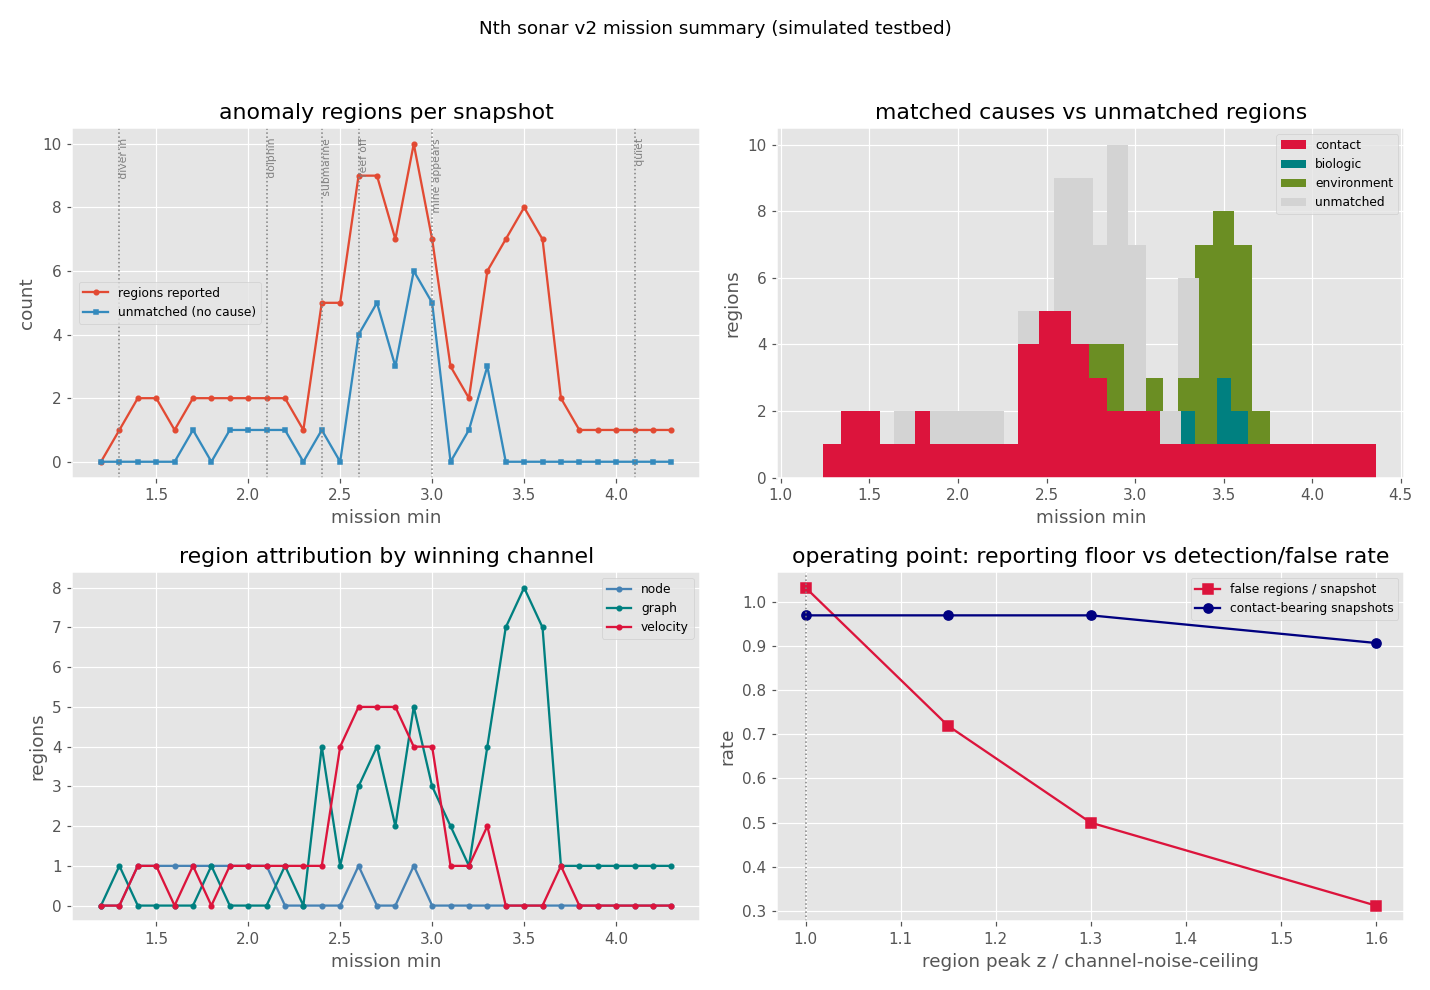

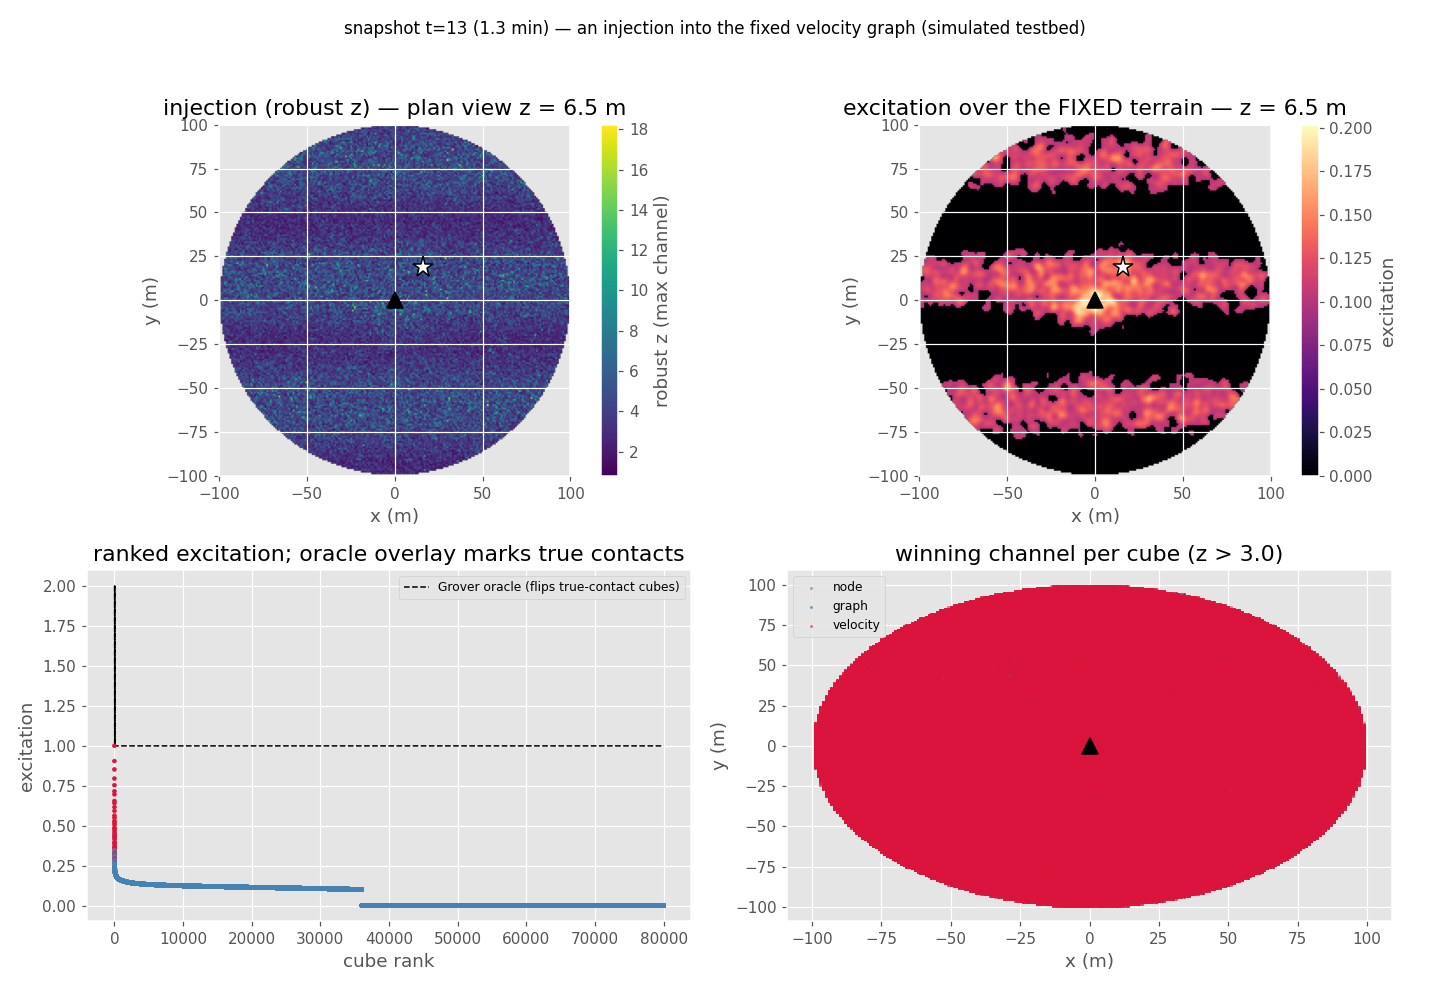

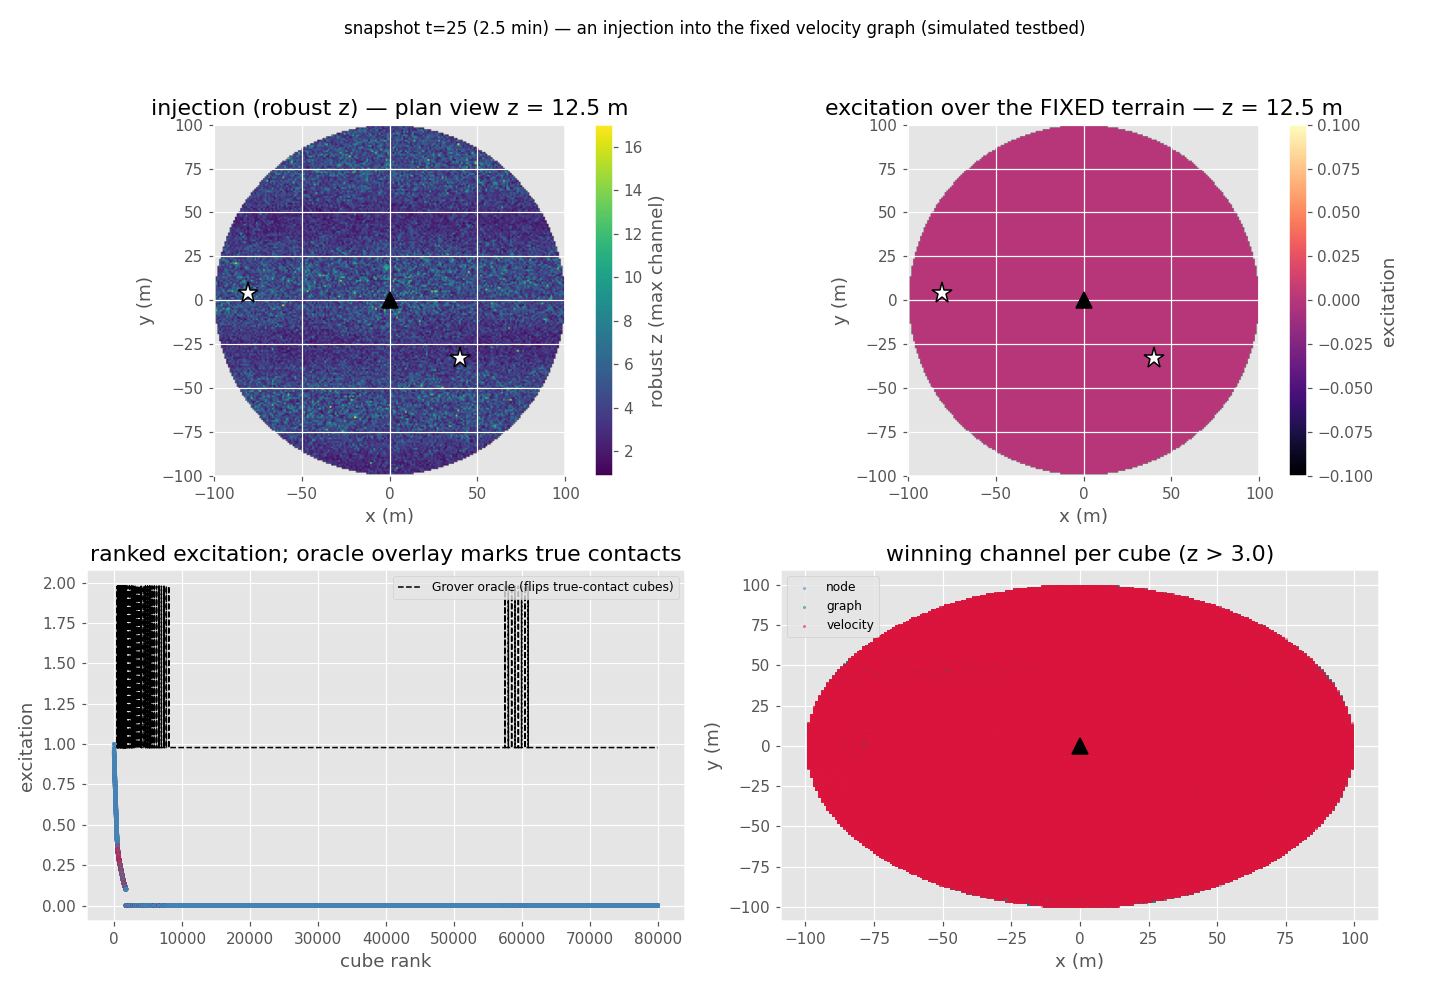

```
`# This is formatted as code`
```



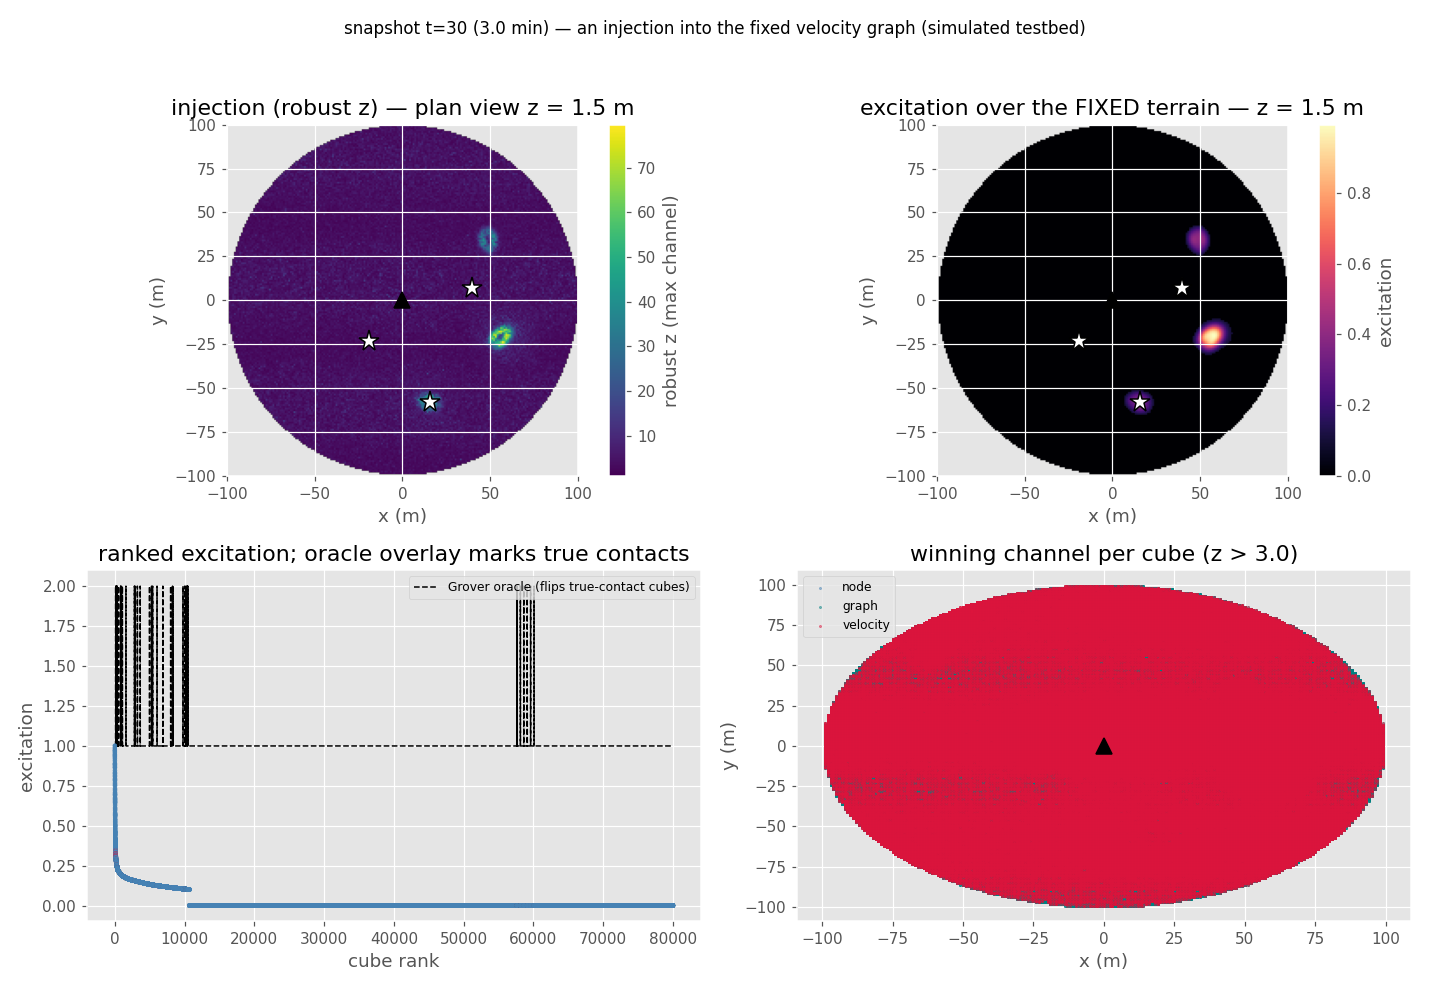

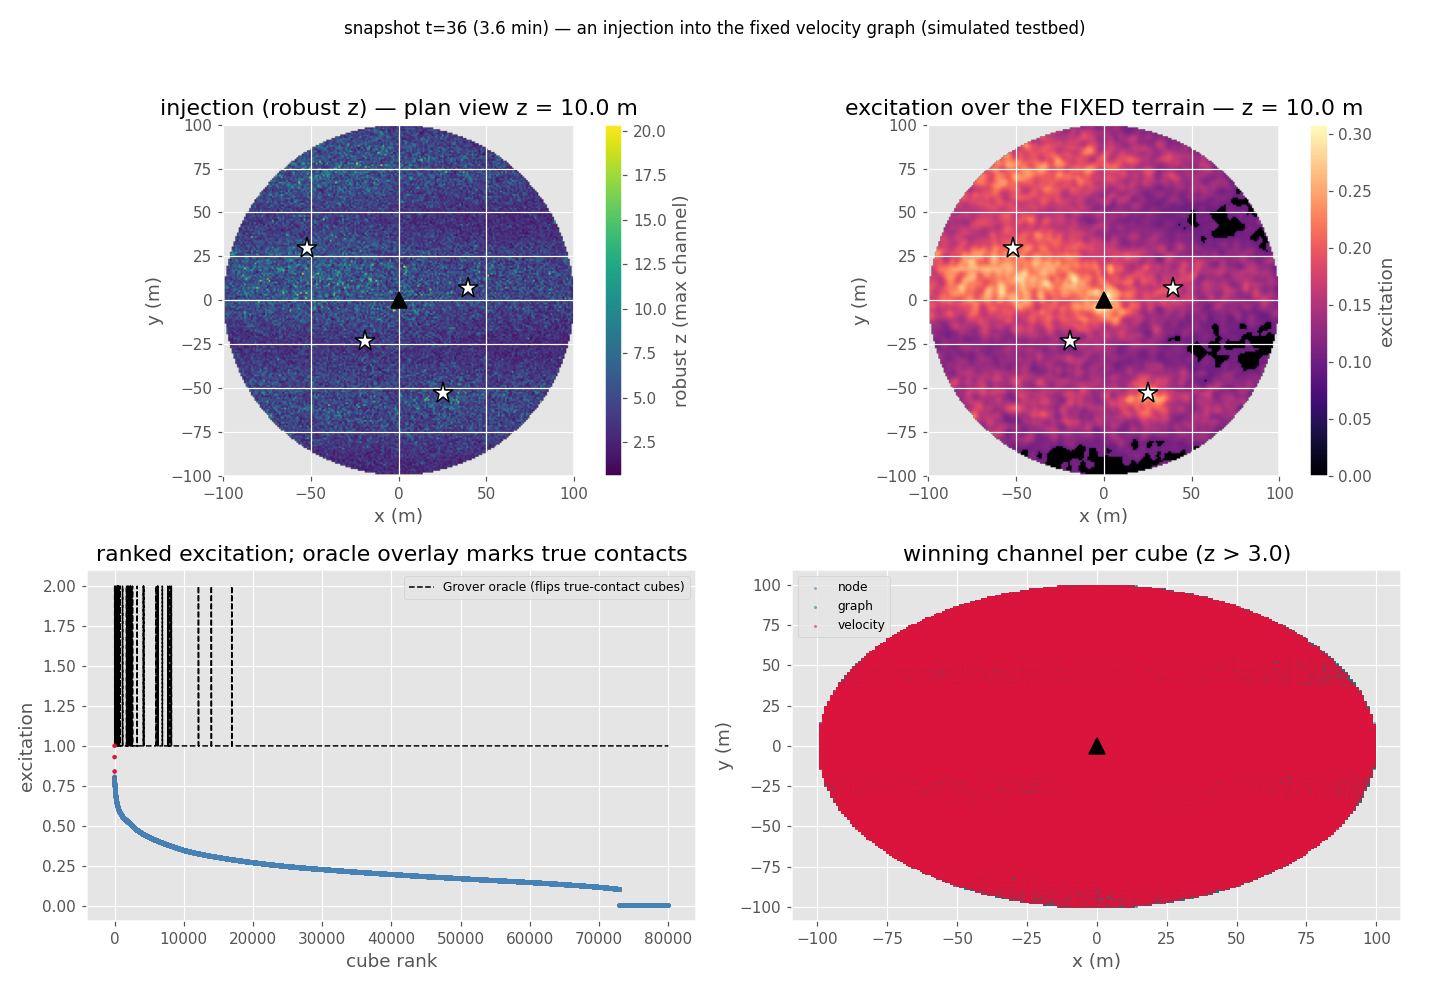

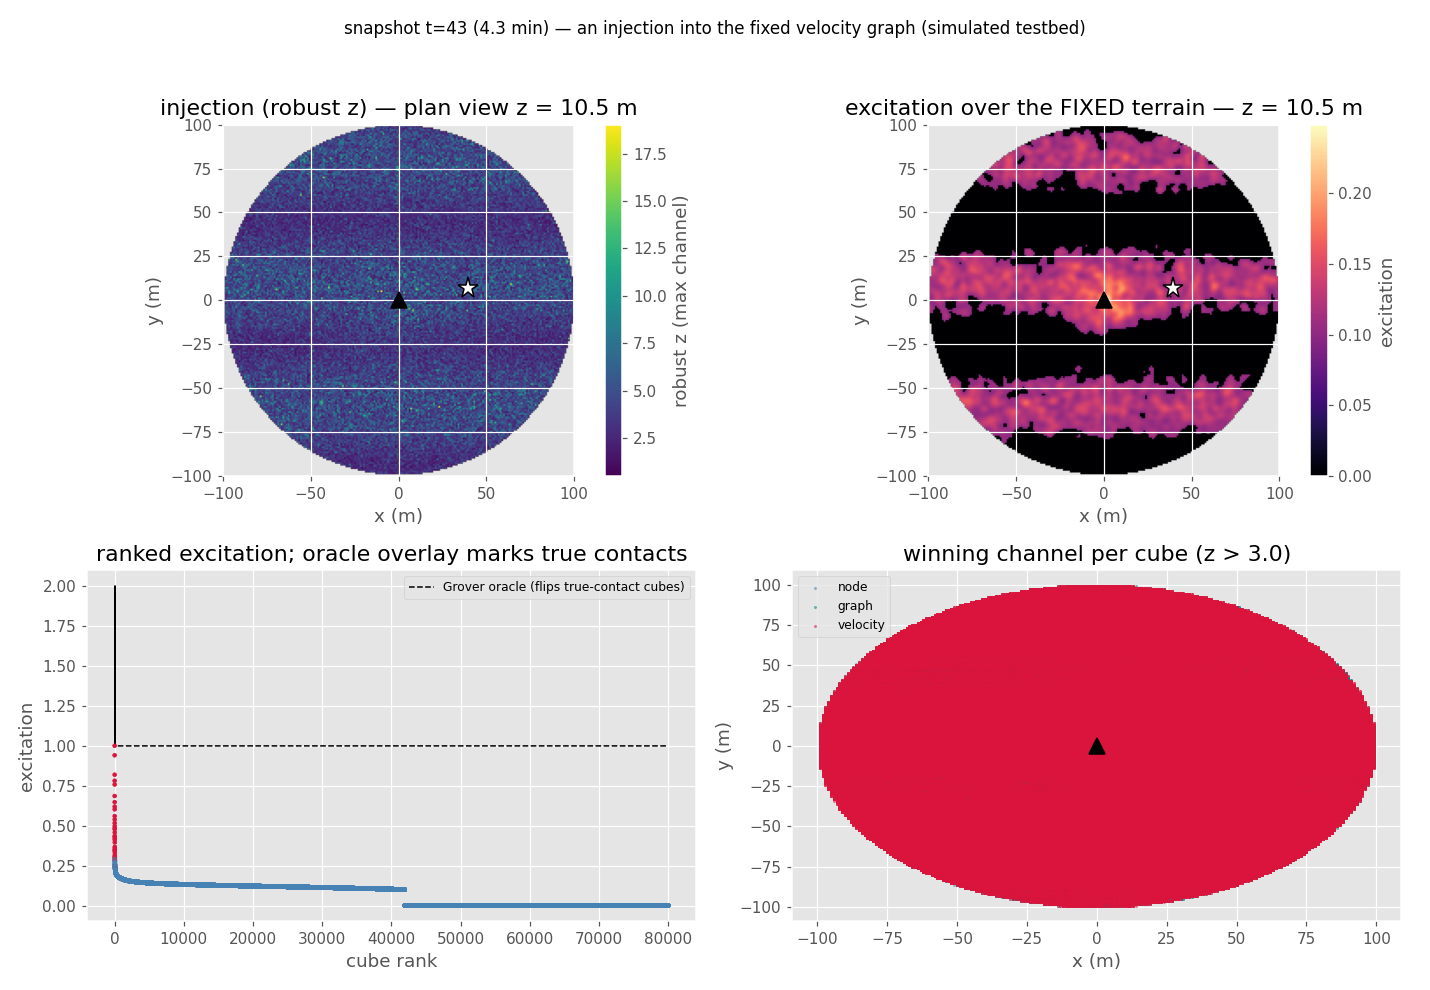

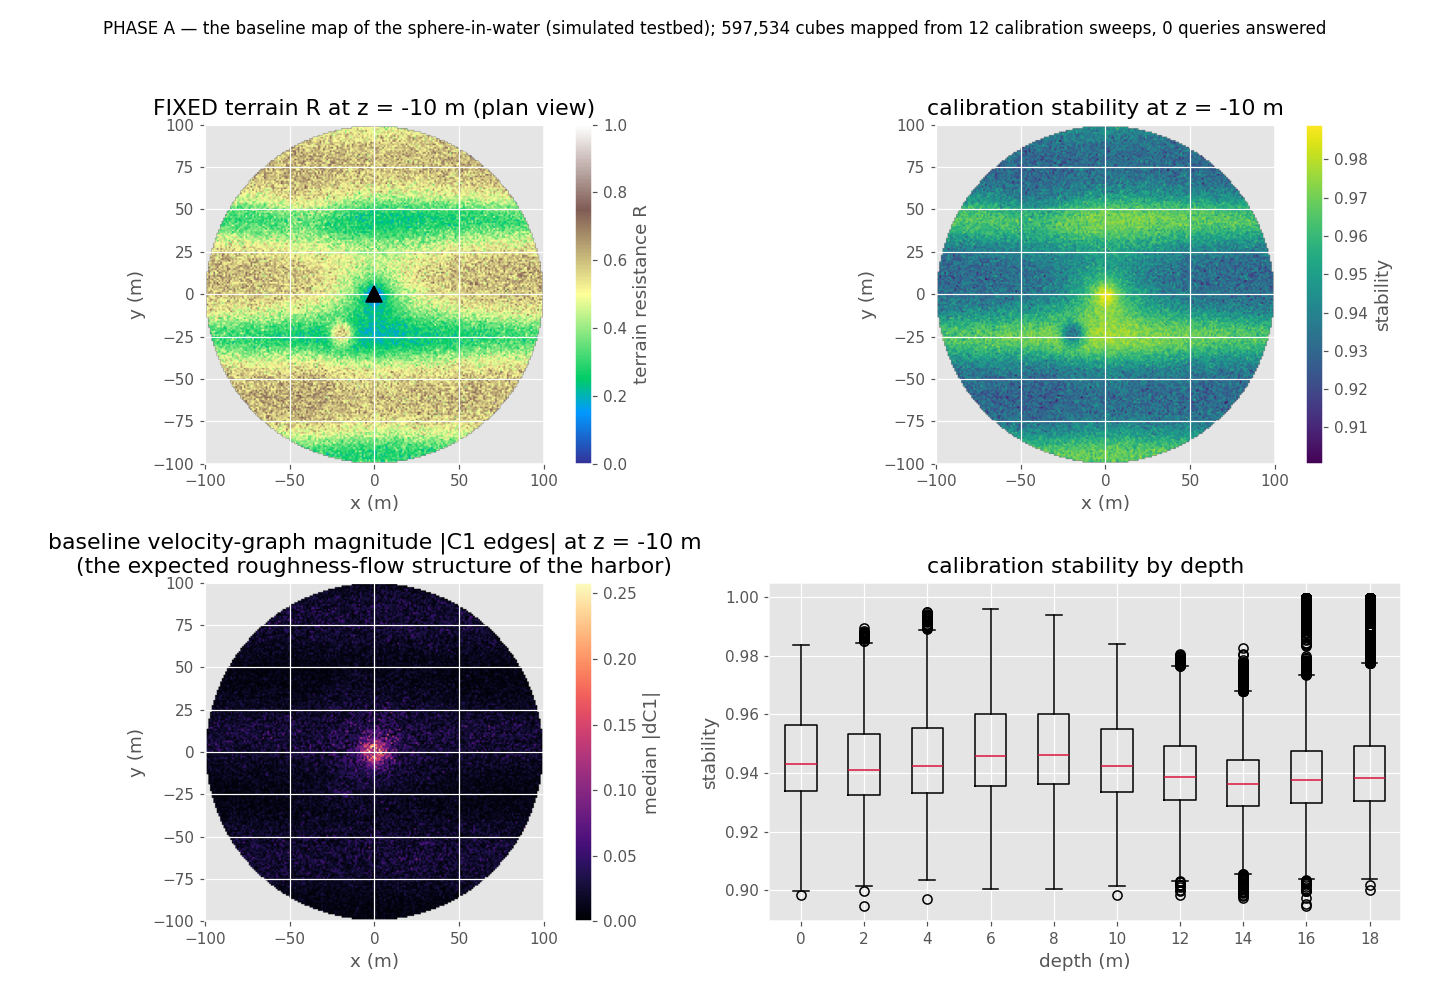

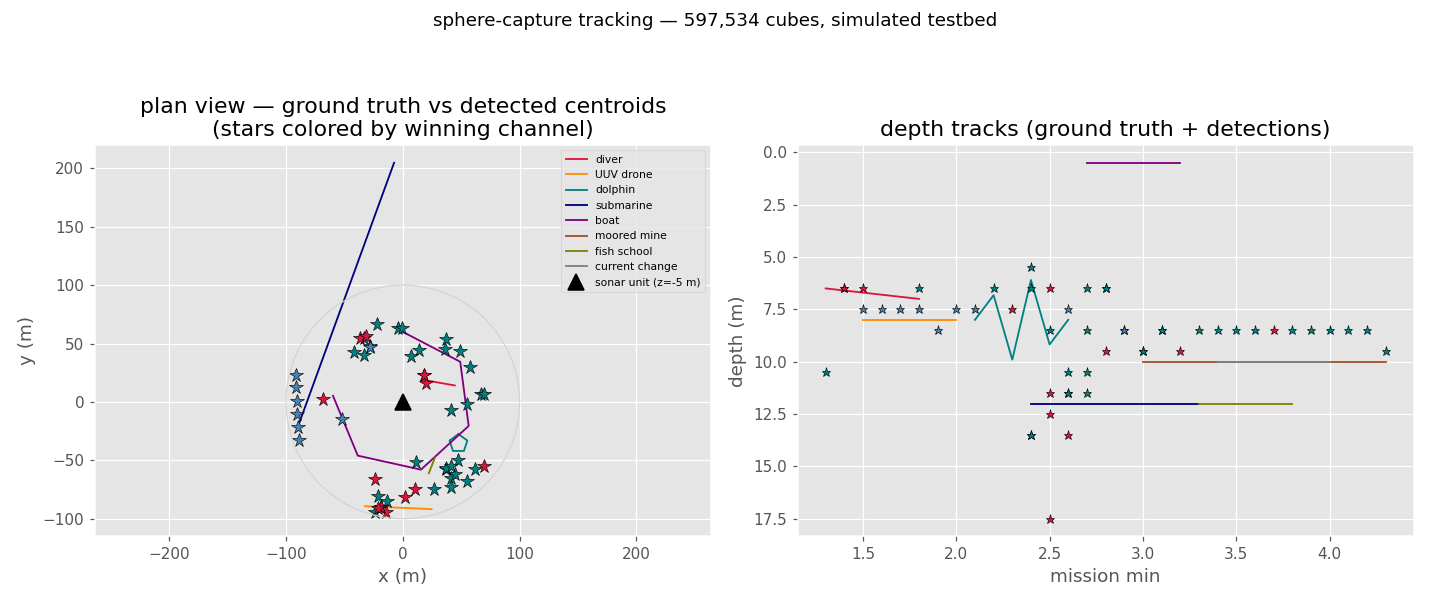